# First we will work on Alerts Table, Ozone through Gold layer

### Initialisations 

In [1]:
import os 

In [2]:
from pyspark.sql import SparkSession
from pyspark import SparkConf

In [ ]:
# # os.environ['SPARK_HOME'] = '' + os.path.join(os.getcwd(), 'spark-3.4.2-bin-hadoop3') + ''
os.environ["SPARK_HOME"] = os.environ.get("SPARK_HOME", "/usr/local/lib/python3.10/dist-packages/pyspark")
os.environ["SPARK_HOME"] = os.environ.get("SPARK_HOME", "/usr/local/lib/python3.10/dist-packages/pyspark")

# Specify the matching version JARs
jar_files = [
    "' + os.path.join(os.getcwd(), 'hudi-spark3.4-bundle_2.12-0.14.1.jar') + '",
# #     "' + os.path.join(os.getcwd(), 'spark-3.4.2-bin-hadoop3') + '/jars/hadoop-aws-3.3.4.jar",
# #     "' + os.path.join(os.getcwd(), 'spark-3.4.2-bin-hadoop3') + '/jars/aws-java-sdk-bundle-1.12.262.jar"
]

spark = (
    SparkSession.builder
    .appName("OzoneS3A-FIXED-v3.3.4")
    
    .master("local[*]")
    .config("spark.jars", ",".join(jar_files))
    .config("spark.driver.extraClassPath", ":".join(jar_files))
    .config("spark.executor.extraClassPath", ":".join(jar_files))
    .config("spark.hadoop.fs.s3a.endpoint", "http://localhost:9878")
    .config("spark.hadoop.fs.s3a.access.key", "admin")
    .config("spark.hadoop.fs.s3a.secret.key", "admin")
    .config("spark.hadoop.fs.s3a.path.style.access", "true")
    .config("spark.hadoop.fs.s3a.connection.ssl.enabled", "false")
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem")
    .config("spark.hadoop.fs.s3a.impl.disable.cache", "true")
    # Hudi configurations (removed problematic extensions)
    .config("spark.serializer", "org.apache.spark.serializer.KryoSerializer")
    .config("spark.kryo.registrator", "org.apache.spark.HoodieSparkKryoRegistrar")
    .config("spark.sql.extensions", "org.apache.spark.sql.hudi.HoodieSparkSessionExtension")
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.hudi.catalog.HoodieCatalog")

    # Performance and optimization
    .config("spark.driver.memory", "4g")
    .config("spark.executor.memory", "4g")
    .config("spark.driver.maxResultSize", "2g")
    .config("spark.sql.shuffle.partitions", "200")
    .config("spark.default.parallelism", "200")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true")
    # Time and legacy settings
    .config("spark.sql.legacy.timeParserPolicy", "LEGACY")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")
print(f"Spark Version: {spark.version}")


26/02/11 00:35:04 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/02/11 00:35:05 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/02/11 00:35:05 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.
26/02/11 00:35:05 WARN Utils: Service 'SparkUI' could not bind on port 4042. Attempting port 4043.
26/02/11 00:35:05 WARN Utils: Service 'SparkUI' could not bind on port 4043. Attempting port 4044.


Spark Version: 3.4.2


In [4]:
# Original: WAREHOUSE_ROOT = os.environ.get("WAREHOUSE_ROOT", os.path.join(os.getcwd(), "Tazama_Hudi_warehouse"))
WAREHOUSE_ROOT = os.environ.get("WAREHOUSE_ROOT", "/app/Tazama_Hudi_warehouse")

bronze_alerts_path       = f"{WAREHOUSE_ROOT}/bronze/alerts"
bronze_cases_path        = f"{WAREHOUSE_ROOT}/bronze/cases"
bronze_typologies_path   = f"{WAREHOUSE_ROOT}/bronze/typologies"
bronze_transactions_path = f"{WAREHOUSE_ROOT}/bronze/transactions"
bronze_pacs008_path      = f"{WAREHOUSE_ROOT}/bronze/pacs008"
bronze_rule_path         = f"{WAREHOUSE_ROOT}/bronze/rule"

### Starting Bronze for alerts

In [116]:
bronze_alerts = spark.read.json("s3a://frms1/alerts/")


26/01/20 03:26:28 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties


In [17]:
bronze_alerts = (
    spark.read.option("header", True)
    .option("escape", "\"")
    .option("multiLine", True)   
    .csv("test_data/alerts_202512221041.csv")
)


In [18]:
bronze_alerts.show(1000)

+----------+--------+--------------+-----------+------------------+------+---------------+--------------------+--------------------+--------------------+--------------------+--------------+----------+--------+-------+
| tenant_id|priority|priority_score| alert_type|prediction_outcome|source|           txtp|             message|          alert_data|         transaction|         network_map|confidence_per|created_at|alert_id|case_id|
+----------+--------+--------------+-----------+------------------+------+---------------+--------------------+--------------------+--------------------+--------------------+--------------+----------+--------+-------+
|tenant_001|CRITICAL|          0.79|      FRAUD|     TRUE_POSITIVE|  NATS|pacs.002.001.12|Suspicious activi...|{"status": "ALRT"...|{"TxTp": "pacs.00...|{"cfg": "1.0.0", ...|             0|   22:18.6|       1|      1|
|tenant_001|CRITICAL|          0.78|        AML|     TRUE_POSITIVE|  NATS|pacs.002.001.12|Suspicious activi...|{"status": "ALRT"

In [9]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *
import hashlib

In [117]:
bronze_alerts_cast = (
    bronze_alerts.select(
        F.col("alert_id").cast("long").alias("alert_id"),
        F.col("tenant_id").cast("string").alias("tenant_id"),
        F.col("priority").cast("string").alias("priority"),
        F.col("priority_score").cast("double").alias("priority_score"),
        F.col("alert_type").cast("string").alias("alert_type"),
        F.col("prediction_outcome").cast("string").alias("prediction_outcome"),
        F.col("source").cast("string").alias("source"),
        F.col("txtp").cast("string").alias("txtp"),
        F.col("message").cast("string").alias("message"),
        F.col("alert_data").cast("string").alias("alert_data"),
        F.col("transaction").cast("string").alias("transaction"),
        F.col("network_map").cast("string").alias("network_map"),
        F.col("confidence_per").cast("int").alias("confidence_per"),
        F.col("case_id").cast("long").alias("case_id"),
        F.col("created_at").cast("string").alias("created_at")
    )
)

In [ ]:
df_bronze = (
    bronze_alerts_cast
    .withColumn("created_at_ts", F.current_timestamp())   # ingestion time (precombine)
    .withColumn("source_file_patah", F.input_file_name())
)

In [119]:
hash_cols = [c for c in df_bronze.columns if c != "created_at_ts"]
df_bronze = df_bronze.withColumn(
    "record_hash",
    F.sha2(F.concat_ws("||", *[F.coalesce(F.col(c).cast("string"), F.lit("")) for c in hash_cols]), 256)
)

In [120]:
hudi_alerts_options = {
    "hoodie.table.name": "bronze_alerts",
    "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
    "hoodie.datasource.write.operation": "upsert",
    "hoodie.datasource.write.recordkey.field": "alert_id",
    "hoodie.datasource.write.precombine.field": "created_at_ts",
    "hoodie.datasource.write.schema.evolution.enable": "true",
    "hoodie.datasource.read.schema.evolution.enable": "true",
    "hoodie.datasource.write.reconcile.schema": "true",
    "hoodie.schema.on.read.enable": "true",
    # Disable metadata to avoid initialization issues
    "hoodie.metadata.enable": "false",
}

In [121]:
(
    df_bronze.write.format("hudi")
    .options(**hudi_alerts_options)
    .mode("append")
    .save(bronze_alerts_path)
)

26/01/20 03:26:53 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [5]:
test=spark.read.format("hudi").load(bronze_alerts_path)
test.show (truncate=False)

26/01/30 08:56:18 WARN DFSPropertiesConfiguration: Cannot find HUDI_CONF_DIR, please set it as the dir of hudi-defaults.conf
26/01/30 08:56:18 WARN DFSPropertiesConfiguration: Properties file file:/etc/hudi/conf/hudi-defaults.conf not found. Ignoring to load props file


+-------------------+----------------------+------------------+----------------------+--------------------------------------------------------------------------+--------+---------+--------+--------------+-------------+------------------+-------+---------------+----------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [7]:
# Query data as of a specific timestamp
test = spark.read \
    .format("hudi") \
    .option("as.of.instant", "20260118150416675") \
    .load(bronze_alerts_path)

test.show(truncate=False)

26/01/28 04:13:13 WARN DFSPropertiesConfiguration: Cannot find HUDI_CONF_DIR, please set it as the dir of hudi-defaults.conf
26/01/28 04:13:13 WARN DFSPropertiesConfiguration: Properties file file:/etc/hudi/conf/hudi-defaults.conf not found. Ignoring to load props file


+-------------------+----------------------+------------------+----------------------+--------------------------------------------------------------------------+--------+---------+--------+--------------+-------------+------------------+-------+---------------+----------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [10]:
from pyspark.sql.window import Window
bronze = spark.read.format("hudi").load(bronze_alerts_path)

latest = (
    bronze
    .withColumn("rn", F.row_number().over(
        Window.partitionBy("_hoodie_record_key").orderBy(F.col("_hoodie_commit_time").desc())
    ))
    .where("rn = 1")
    .drop("rn")
)

latest.show(20, truncate=False)


+-------------------+-----------------------+------------------+----------------------+--------------------------------------------------------------------------+--------+----------+--------+--------------+-------------+------------------+------+---------------+----------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [11]:
# Query data as of a specific date-time
test = spark.read \
    .format("hudi") \
    .option("as.of.instant", "2026-01-18 15:04:16") \
    .load(bronze_alerts_path)

test.show(truncate=False)

+-------------------+----------------------+------------------+----------------------+--------------------------------------------------------------------------+--------+---------+--------+--------------+-------------+------------------+-------+---------------+----------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [12]:
from datetime import datetime, timedelta

# Calculate timestamp for 1 hour ago
one_hour_ago = (datetime.now() - timedelta(hours=1)).strftime("%Y-%m-%d %H:%M:%S")

test = spark.read \
    .format("hudi") \
    .option("as.of.instant", one_hour_ago) \
    .load(bronze_alerts_path)

test.show(truncate=False)

+-------------------+----------------------+------------------+----------------------+--------------------------------------------------------------------------+--------+---------+--------+--------------+-------------+------------------+-------+---------------+----------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [13]:
# First, see all available commits
commits = spark.read \
    .format("hudi") \
    .load(bronze_alerts_path) \
    .select("_hoodie_commit_time") \
    .distinct() \
    .orderBy("_hoodie_commit_time", ascending=False)

commits.show(truncate=False)

# Then pick a commit timestamp and query
desired_commit = "20260118150416675"
test = spark.read \
    .format("hudi") \
    .option("as.of.instant", desired_commit) \
    .load(bronze_alerts_path)

test.show(truncate=False)

+-------------------+
|_hoodie_commit_time|
+-------------------+
|20260122084521165  |
|20260120032647748  |
+-------------------+

+-------------------+----------------------+------------------+----------------------+--------------------------------------------------------------------------+--------+---------+--------+--------------+-------------+------------------+-------+---------------+----------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [14]:
# First check what commits are available
commits_df = spark.read \
    .format("hudi") \
    .load(bronze_alerts_path) \
    .selectExpr("_hoodie_commit_time") \
    .distinct() \
    .orderBy("_hoodie_commit_time", ascending=False)

commits_df.show(20, truncate=False)

# Get the list of commits
commits = [row._hoodie_commit_time for row in commits_df.collect()]
print(f"Available commits: {commits}")

+-------------------+
|_hoodie_commit_time|
+-------------------+
|20260122084521165  |
|20260120032647748  |
+-------------------+

Available commits: ['20260122084521165', '20260120032647748']


In [15]:
# Read data at two different commits
commit1 = "20260120032647748"
commit2 = "20260118150416675"  # Earlier commit

df1 = spark.read.format("hudi").option("as.of.instant", commit1).load(bronze_alerts_path)
df2 = spark.read.format("hudi").option("as.of.instant", commit2).load(bronze_alerts_path)

print(f"Records at {commit1}: {df1.count()}")
print(f"Records at {commit2}: {df2.count()}")

Records at 20260120032647748: 376
Records at 20260118150416675: 286


In [18]:
# Alternative to incremental query: Read two snapshots and find differences
from pyspark.sql.functions import col

# Read at two different times
df_new = spark.read.format("hudi").option("as.of.instant", "20260120032647748").load(bronze_alerts_path)
df_old = spark.read.format("hudi").option("as.of.instant", "20260118150416675").load(bronze_alerts_path)

# Find new records (present in new but not in old)
incremental_records = df_new.join(
    df_old, 
    on="alert_id", 
    how="left_anti"
)

print("Incremental records:")
incremental_records.show(1000, truncate=False)

Incremental records:
+--------+-------------------+-----------------------+------------------+----------------------+----------------------------------------------------------------------------+----------+--------+--------------+-----------+------------------+------+---------------+----------------------------+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Now silver for Alerts

In [19]:
silver_alerts_path       = f"{WAREHOUSE_ROOT}/silver/alerts"
silver_cases_path        = f"{WAREHOUSE_ROOT}/silver/cases"
silver_typologies_path   = f"{WAREHOUSE_ROOT}/silver/typologies"
silver_transactions_path = f"{WAREHOUSE_ROOT}/silver/transactions"
silver_pacs008_path      = f"{WAREHOUSE_ROOT}/silver/pacs008"
silver_rule_path         = f"{WAREHOUSE_ROOT}/silver/rule"

In [6]:
bronze_alerts = spark.read.format("hudi").load(bronze_alerts_path)

26/01/26 07:16:49 WARN DFSPropertiesConfiguration: Cannot find HUDI_CONF_DIR, please set it as the dir of hudi-defaults.conf
26/01/26 07:16:50 WARN DFSPropertiesConfiguration: Properties file file:/etc/hudi/conf/hudi-defaults.conf not found. Ignoring to load props file


In [7]:
bronze_alerts = bronze_alerts.drop(*[c for c in bronze_alerts.columns if c.startswith("_hoodie_")])

In [10]:
from pyspark.sql import functions as F, types as T
from pyspark.sql.window import Window

In [9]:
def infer_json_schema(df, col_name: str) -> T.StructType:
    return spark.read.json(
        df.select(col_name).where(F.col(col_name).isNotNull()).rdd.map(lambda r: r[0])
    ).schema


In [10]:
alert_schema = infer_json_schema(bronze_alerts, "alert_data")
tx_schema    = infer_json_schema(bronze_alerts, "transaction")
net_schema   = infer_json_schema(bronze_alerts, "network_map")

In [11]:
b = (bronze_alerts
     .withColumn("alert_data_obj", F.from_json("alert_data", alert_schema))
     .withColumn("transaction_obj", F.from_json("transaction", tx_schema))
     .withColumn("network_map_obj", F.from_json("network_map", net_schema))
)

b = (b
     .withColumn("event_ts", F.to_timestamp(F.col("alert_data_obj.timestamp")))
     .withColumn("event_date", F.to_date("event_ts"))
     .withColumn("tx_created_ts", F.to_timestamp(F.col("transaction_obj.FIToFIPmtSts.GrpHdr.CreDtTm")))
     .withColumn("tx_accept_ts",  F.to_timestamp(F.col("transaction_obj.FIToFIPmtSts.TxInfAndSts.AccptncDtTm")))
)

In [12]:
silver = (
    b
    # IDs / keys
    .withColumn("alert_id", F.col("alert_id").cast("long"))
    .withColumn("case_id",  F.col("case_id").cast("long"))

    # alert_data flatten
    .withColumn("alert_status", F.col("alert_data_obj.status"))
    .withColumn("evaluation_id", F.col("alert_data_obj.evaluationID"))  # correct casing
    .withColumn("processing_time_dp", F.col("alert_data_obj.metaData.prcgTmDP").cast("long"))
    .withColumn("processing_time_ed", F.col("alert_data_obj.metaData.prcgTmED").cast("long"))
    .withColumn("tadp_id",  F.col("alert_data_obj.tadpResult.id"))
    .withColumn("tadp_cfg", F.col("alert_data_obj.tadpResult.cfg"))
    .withColumn("tadp_processing_time", F.col("alert_data_obj.tadpResult.prcgTm").cast("long"))

    # typology summaries (array-of-objects -> arrays-of-primitives)
    .withColumn("typology_count", F.size(F.col("alert_data_obj.tadpResult.typologyResult")))
    .withColumn("typology_ids", F.expr("transform(alert_data_obj.tadpResult.typologyResult, x -> x.id)"))
    .withColumn("typology_results", F.expr("transform(alert_data_obj.tadpResult.typologyResult, x -> cast(x.result as int))"))
    .withColumn("typology_reviews", F.expr("transform(alert_data_obj.tadpResult.typologyResult, x -> cast(x.review as boolean))"))
    .withColumn("workflow_processors", F.expr("transform(alert_data_obj.tadpResult.typologyResult, x -> x.workflow.flowProcessor)"))
    .withColumn("alert_thresholds", F.expr("transform(alert_data_obj.tadpResult.typologyResult, x -> cast(x.workflow.alertThreshold as int))"))
    .withColumn("interdiction_thresholds", F.expr("transform(alert_data_obj.tadpResult.typologyResult, x -> cast(x.workflow.interdictionThreshold as int))"))
    .withColumn("rule_count_total", F.expr("aggregate(alert_data_obj.tadpResult.typologyResult, 0, (acc, x) -> acc + size(x.ruleResults))"))

    # -------- ADD: individual rule weights (rule_id + weight) ----------
    # Build rule pairs across ALL typologies: array<struct<rule_id:string, weight:long>>
    .withColumn(
        "rule_pairs",
        F.flatten(
            F.expr("""
              transform(
                alert_data_obj.tadpResult.typologyResult,
                t -> transform(
                  t.ruleResults,
                  r -> named_struct('rule_id', r.id, 'weight', cast(r.wght as long))
                )
              )
            """)
        )
    )
    # De-duplicate by rule_id (keeps first occurrence)
    .withColumn(
        "rule_pairs",
        F.expr("""
          aggregate(
            rule_pairs,
            cast(array() as array<struct<rule_id:string, weight:bigint>>),
            (acc, x) ->
              IF(
                array_contains(transform(acc, y -> y.rule_id), x.rule_id),
                acc,
                concat(acc, array(x))
              )
          )
        """)
    )
    .withColumn("rule_pairs", F.expr("filter(rule_pairs, x -> x.rule_id is not null)"))


    # BI-friendly JSON string
    .withColumn("rule_weights_json", F.to_json(F.col("rule_pairs")))
    # Optional scalar summaries (handy for Gold KPIs)
    .withColumn("rule_id_count_distinct", F.size(F.expr("transform(rule_pairs, x -> x.rule_id)")))
    .withColumn(
        "rule_weight_sum",
        F.expr("aggregate(transform(rule_pairs, x -> x.weight), cast(0 as long), (acc,x) -> acc + coalesce(x, cast(0 as long)))")
    )
    .withColumn(
        "rule_weight_max",
        F.when(F.size("rule_pairs") > 0, F.array_max(F.expr("transform(rule_pairs, x -> x.weight)")))
         .otherwise(F.lit(0).cast("long"))
    )
    # ---------------------------------------------------------------

    # transaction flatten (ONLY tx_* naming)
    .withColumn("tx_type", F.col("transaction_obj.TxTp"))
    .withColumn("tx_tenant_id", F.col("transaction_obj.TenantId"))
    .withColumn("tx_msg_id", F.col("transaction_obj.FIToFIPmtSts.GrpHdr.MsgId"))
    .withColumn("tx_status", F.col("transaction_obj.FIToFIPmtSts.TxInfAndSts.TxSts"))
    .withColumn("tx_original_instr_id", F.col("transaction_obj.FIToFIPmtSts.TxInfAndSts.OrgnlInstrId"))
    .withColumn("tx_original_e2e_id", F.col("transaction_obj.FIToFIPmtSts.TxInfAndSts.OrgnlEndToEndId"))
    .withColumn("instg_mmb_id", F.col("transaction_obj.FIToFIPmtSts.TxInfAndSts.InstgAgt.FinInstnId.ClrSysMmbId.MmbId"))
    .withColumn("instd_mmb_id", F.col("transaction_obj.FIToFIPmtSts.TxInfAndSts.InstdAgt.FinInstnId.ClrSysMmbId.MmbId"))

    # charges
    .withColumn("charge_count", F.size(F.col("transaction_obj.FIToFIPmtSts.TxInfAndSts.ChrgsInf")))
    .withColumn("charge_agent_mmb_ids", F.expr("transform(transaction_obj.FIToFIPmtSts.TxInfAndSts.ChrgsInf, x -> x.Agt.FinInstnId.ClrSysMmbId.MmbId)"))
    .withColumn("charge_amounts", F.expr("transform(transaction_obj.FIToFIPmtSts.TxInfAndSts.ChrgsInf, x -> cast(x.Amt.Amt as double))"))
    .withColumn("charge_ccys", F.expr("transform(transaction_obj.FIToFIPmtSts.TxInfAndSts.ChrgsInf, x -> x.Amt.Ccy)"))

    # network flatten
    .withColumn("network_cfg", F.col("network_map_obj.cfg"))
    .withColumn("network_active", F.col("network_map_obj.active").cast("boolean"))
    .withColumn("network_tenant_id", F.col("network_map_obj.tenantId"))
    .withColumn("network_message_count", F.size(F.col("network_map_obj.messages")))
    .withColumn("network_message_ids", F.expr("transform(network_map_obj.messages, x -> x.id)"))

    # Select final shape (drop structs + duplicates)
    .select(
        # hoodie meta optional (keep if you want)
        "_hoodie_commit_time","_hoodie_commit_seqno","_hoodie_record_key","_hoodie_partition_path","_hoodie_file_name",

        "alert_id","case_id","tenant_id",
        "priority","priority_score","alert_type","prediction_outcome","source","txtp","message","confidence_per",

        "event_ts","event_date",
        "tx_created_ts","tx_accept_ts",
        "created_at","created_at_ts",

        "alert_status","evaluation_id",
        "processing_time_dp","processing_time_ed",
        "tadp_id","tadp_cfg","tadp_processing_time",

        "typology_count","typology_ids","typology_results","typology_reviews",
        "workflow_processors","alert_thresholds","interdiction_thresholds",
        "rule_count_total",

        # NEW rule details
        "rule_weights_json",
        "rule_id_count_distinct","rule_weight_sum","rule_weight_max",

        "tx_type","tx_tenant_id","tx_msg_id","tx_status",
        "tx_original_instr_id","tx_original_e2e_id",
        "instg_mmb_id","instd_mmb_id",
        "charge_count","charge_agent_mmb_ids","charge_amounts","charge_ccys",

        "network_cfg","network_active","network_tenant_id",
        "network_message_count","network_message_ids",

        "source_file_path","record_hash",

        # retain raw json strings for audit/debug
        "alert_data","transaction","network_map",
    )
    # recreate payload for debugging (since bronze shows null)
    .withColumn("_row_payload_json", F.to_json(F.struct("*")))
    # OPTIONAL: if you don't want array<struct> stored in Silver, drop it:
    .drop("rule_pairs")
)


In [13]:
w = Window.partitionBy("alert_id").orderBy(F.col("created_at_ts").desc())
silver = silver.withColumn("rn", F.row_number().over(w)).filter(F.col("rn")==1).drop("rn")

In [ ]:
dq_rules = [
    ("ALERT_ID_NULL",        F.col("alert_id").isNull()),
    ("CREATED_AT_TS_NULL",   F.col("created_at_ts").isNull()),
    ("EVENT_TS_NULL",        F.col("event_ts").isNull()),

    # Proxy checks for "bad JSON / missing critical parsed fields"
    # (since *_obj columns are not present anymore)
    ("ALERT_DATA_MISSING_CORE", F.col("alert_data").isNotNull() & F.col("alert_status").isNull()),
    ("TX_MISSING_CORE",         F.col("transaction").isNotNull() & F.col("tx_msg_id").isNull()),
    ("NET_MISSING_CORE",        F.col("network_map").isNotNull() & F.col("network_cfg").isNull()),
]

# IMPORTANT: avoid F.array(*[]) edge cases and keep types stable
reason_cols = [F.when(cond, F.lit(code)).otherwise(F.lit(None).cast("string")) for code, cond in dq_rules]

silver_dq = (
    silver
    .withColumn("dq_reason_codes_raw", F.array(*reason_cols))              # array<string>
    .withColumn("dq_reason_codes", F.expr("filter(dq_reason_codes_raw, x -> x is not null)"))
    .withColumn("dq_failed", F.size("dq_reason_codes") > 0)
    .drop("dq_reason_codes_raw")
)

silver_pass = silver_dq.filter(~F.col("dq_failed")).drop("dq_failed", "dq_reason_codes")
silver_fail = silver_dq.filter(F.col("dq_failed"))

# stable DLQ key even if alert_id is null
silver_fail = (
    silver_fail
    .withColumn(
        "dlq_id",
        F.sha2(
            F.coalesce(
                F.col("record_hash").cast("string"),
                F.col("_row_payload_json").cast("string")
            ),
            256
        )
    )
    .withColumn("dlq_ingested_at", F.current_timestamp())
)

# DLQ counts by reason code (Acceptance Criteria)
(
    silver_fail
    .select(F.explode("dq_reason_codes").alias("reason_code"))
    .groupBy("reason_code")
    .count()
    .orderBy(F.col("count").desc())
    .show(truncate=False)
)

+-----------------------+-----+
|reason_code            |count|
+-----------------------+-----+
|EVENT_TS_NULL          |104  |
|TX_MISSING_CORE        |50   |
|ALERT_DATA_MISSING_CORE|3    |
+-----------------------+-----+



In [130]:
hudi_silver_opts = {
    "hoodie.table.name": "silver_alerts",
    "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
    "hoodie.datasource.write.operation": "upsert",
    "hoodie.datasource.write.recordkey.field": "alert_id",
    "hoodie.datasource.write.precombine.field": "created_at_ts",
    "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",
    "hoodie.datasource.write.schema.evolution.enable": "true",
    "hoodie.datasource.read.schema.evolution.enable": "true",
    "hoodie.datasource.write.reconcile.schema": "true",
    "hoodie.schema.on.read.enable": "true",
}

In [131]:
(
  silver.write.format("hudi")
 .options(**hudi_silver_opts)
 .mode("append")
 .save(silver_alerts_path)
)

26/01/20 03:27:30 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [146]:
silver_alerts = spark.read.format("hudi").load(silver_alerts_path)
silver_alerts.show(500,truncate=False)

+-------------------+-----------------------+------------------+----------------------+----------------------------------------------------------------------------+--------+-------+----------+--------+--------------+-------------+------------------+-------+---------------+----------------------------+--------------+-----------------------+----------+-----------------------+-----------------------+----------------+--------------------------+------------+------------------------------------+------------------+------------------+---------+--------+--------------------+--------------+--------------------------+----------------+----------------+-------------------+----------------+-----------------------+----------------+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [17]:
silver_alerts_dlq_path = f"{WAREHOUSE_ROOT}/silver/alerts_dlq"

In [18]:
hudi_dlq_opts = {
    "hoodie.table.name": "silver_alerts_dlq",
    "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
    "hoodie.datasource.write.operation": "upsert",
    "hoodie.datasource.write.recordkey.field": "dlq_id",
    "hoodie.datasource.write.precombine.field": "dlq_ingested_at",
    "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",
    "hoodie.datasource.write.schema.evolution.enable": "true",
    "hoodie.datasource.read.schema.evolution.enable": "true",
    "hoodie.datasource.write.reconcile.schema": "true",
    "hoodie.schema.on.read.enable": "true",
}

(
  silver_fail.write.format("hudi")
 .options(**hudi_dlq_opts)
 .mode("append")
 .save(silver_alerts_dlq_path)
)

26/01/26 07:25:53 WARN HiveConf: HiveConf of name hive.stats.jdbc.timeout does not exist
26/01/26 07:25:53 WARN HiveConf: HiveConf of name hive.stats.retries.wait does not exist
26/01/26 07:25:59 WARN ObjectStore: Version information not found in metastore. hive.metastore.schema.verification is not enabled so recording the schema version 2.3.0
26/01/26 07:25:59 WARN ObjectStore: setMetaStoreSchemaVersion called but recording version is disabled: version = 2.3.0, comment = Set by MetaStore root@10.10.80.20
26/01/26 07:26:07 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-hbase.properties,hadoop-metrics2.properties


# WARNING: Unable to get Instrumentation. Dynamic Attach failed. You may add this JAR as -javaagent manually, or supply -Djdk.attach.allowAttachSelf


26/01/26 07:26:27 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [19]:
spark.read.format('hudi').load(silver_alerts_dlq_path).show()

+-------------------+--------------------+--------------------+----------------------+--------------------+--------+-------+---------+--------+--------------+-------------+------------------+-------+---------------+--------------------+--------------+--------+----------+--------------------+--------------------+----------------+--------------------+------------+--------------------+------------------+------------------+---------+--------+--------------------+--------------+--------------------+----------------+----------------+-------------------+----------------+-----------------------+----------------+--------------------+----------------------+---------------+---------------+---------------+------------+--------------------+---------+--------------------+--------------------+------------+------------+------------+--------------------+---------------+---------------+-----------+--------------+-----------------+---------------------+-------------------+--------------------+-----------

### Now its time for gold

In [17]:
from pyspark.sql import Window

In [15]:
gold_alerts_path       = f"{WAREHOUSE_ROOT}/gold/alerts"

In [18]:
silver = spark.read.format("hudi").load(silver_alerts_path)
silver = silver.drop(*[c for c in silver.columns if c.startswith("_hoodie_")])

w = Window.partitionBy("alert_id").orderBy(F.col("created_at_ts").desc())
s = silver.withColumn("rn", F.row_number().over(w)).filter("rn=1").drop("rn")

In [19]:
alert_schema = spark.read.json(s.select("alert_data").where(F.col("alert_data").isNotNull()).rdd.map(lambda r: r[0])).schema
g = s.withColumn("alert_data_obj", F.from_json("alert_data", alert_schema))

# rule_pairs: array<struct<rule_id, weight>>
g = (
    g
    .withColumn(
        "rule_pairs",
        F.flatten(
            F.expr("""
              transform(
                alert_data_obj.tadpResult.typologyResult,
                t -> transform(
                  t.ruleResults,
                  r -> named_struct('rule_id', r.id, 'weight', cast(r.wght as long))
                )
              )
            """)
        )
    )
    .withColumn("rule_pairs", F.expr("filter(rule_pairs, x -> x.rule_id is not null)"))
)

In [20]:
g = (
    g
    .withColumn("rule_weights", F.expr("transform(rule_pairs, x -> x.weight)"))

    .withColumn("rule_id_count_distinct",
                F.size(F.array_distinct(F.expr("transform(rule_pairs, x -> x.rule_id)"))).cast("int"))

    .withColumn(
        "rule_weight_sum",
        F.expr("aggregate(rule_weights, cast(0 as long), (acc,x) -> acc + coalesce(x, cast(0 as long)))").cast("long")
    )

    .withColumn(
        "rule_weight_max",
        F.when(F.size("rule_weights") > 0, F.array_max("rule_weights")).otherwise(F.lit(0)).cast("long")
    )

    .withColumn(
        "rule_weight_min",
        F.when(F.size("rule_weights") > 0, F.array_min("rule_weights")).otherwise(F.lit(0)).cast("long")
    )

    .withColumn(
        "rule_weight_avg",
        F.when(
            F.size("rule_weights") > 0,
            (F.col("rule_weight_sum").cast("double") / F.size("rule_weights").cast("double"))
        ).otherwise(F.lit(0.0)).cast("double")
    )

    .withColumn(
        "rule_weight_p95",
        F.when(
            F.size("rule_weights") > 0,
            F.expr("""
              element_at(
                array_sort(rule_weights),
                cast(ceil(size(rule_weights) * 0.95) as int)
              )
            """).cast("double")
        ).otherwise(F.lit(0.0))
    )
)


In [21]:
g = g.withColumn(
    "top_rule_id",
    F.expr("""
      element_at(
        transform(
          filter(rule_pairs, x -> x.weight = rule_weight_max),
          x -> x.rule_id
        ),
        1
      )
    """)
)
g = g.withColumn("top_rule_weight", F.col("rule_weight_max").cast("long"))


In [22]:
tx_amount = F.coalesce(
    F.get_json_object(F.col("transaction"), "$.FIToFIPmtSts.TxInfAndSts.OrgnlTxRef.Amt.InstdAmt.Amt").cast("double"),
    F.get_json_object(F.col("transaction"), "$.FIToFIPmtSts.TxInfAndSts.OrgnlTxRef.Amt.EqvtAmt.Amt").cast("double"),
    F.lit(None).cast("double")
)
tx_ccy = F.coalesce(
    F.get_json_object(F.col("transaction"), "$.FIToFIPmtSts.TxInfAndSts.OrgnlTxRef.Amt.InstdAmt.Ccy"),
    F.get_json_object(F.col("transaction"), "$.FIToFIPmtSts.TxInfAndSts.OrgnlTxRef.Amt.EqvtAmt.Ccy"),
    F.lit(None).cast("string")
)

In [23]:
# Charges total (array<double> -> double)
g = g.withColumn(
    "charge_total_amount",
    F.when(
        F.col("charge_amounts").isNotNull(),
        F.expr("aggregate(charge_amounts, cast(0.0 as double), (acc,x) -> acc + coalesce(x, 0.0))")
    ).otherwise(F.lit(0.0))
)

In [24]:
g = (
    g
    .withColumn("tx_amount", tx_amount)
    .withColumn("tx_ccy", tx_ccy)
    .withColumn("charge_currency_count", F.when(F.col("charge_ccys").isNotNull(), F.size(F.array_distinct("charge_ccys"))).otherwise(F.lit(0)))
    .withColumn("has_multi_currency_charges", (F.col("charge_currency_count") > 1).cast("int"))
)

In [25]:
g = g.withColumn(
    "total_processing_time_ms",
    (
        F.coalesce(F.col("processing_time_dp").cast("long"), F.lit(0)) +
        F.coalesce(F.col("processing_time_ed").cast("long"), F.lit(0)) +
        F.coalesce(F.col("tadp_processing_time").cast("long"), F.lit(0))
    ).cast("long")
)

g = g.withColumn(
    "event_to_ingest_ms",
    F.when(
        F.col("event_ts").isNotNull(),
        (F.col("created_at_ts").cast("long") - F.col("event_ts").cast("long")) * 1000
    ).otherwise(F.lit(None).cast("long"))
)

In [26]:
g = (
    g
    .withColumn("priority_norm", F.upper("priority"))
    .withColumn("alert_type_norm", F.upper("alert_type"))
    .withColumn("prediction_outcome_norm", F.upper("prediction_outcome"))
    .withColumn("is_false_positive", (F.col("prediction_outcome_norm") == "FALSE_POSITIVE").cast("int"))
    .withColumn("is_false_negative", (F.col("prediction_outcome_norm") == "FALSE_NEGATIVE").cast("int"))
    .withColumn("is_true_positive",  (F.col("prediction_outcome_norm") == "TRUE_POSITIVE").cast("int"))
    .withColumn("is_true_negative",  (F.col("prediction_outcome_norm") == "TRUE_NEGATIVE").cast("int"))
)

# Governance
g = g.withColumn("security_tag", F.concat(F.lit("TENANT:"), F.col("tenant_id")))

In [27]:
g = g.withColumn(
    "typology_id",
    F.concat_ws(", ", F.col("typology_ids"))
)

In [33]:
gold = g.select(
    "event_date",
    "alert_id", "case_id", "tenant_id",

    "priority_norm", "priority_score",
    "alert_type_norm", "prediction_outcome_norm",
    "source", "txtp",

    "event_ts", "created_at_ts",
    "alert_status", "evaluation_id",

    "tx_type", "tx_msg_id", "tx_status",
    "tx_amount", "tx_ccy", "tx_original_e2e_id",

    "typology_count",
    "typology_id",
    "rule_count_total",

    # RULES (scalar-only)
    "rule_id_count_distinct",
    "rule_weight_sum", "rule_weight_max", "rule_weight_min", "rule_weight_avg", "rule_weight_p95",
    "top_rule_id", "top_rule_weight",

    # Charges / network
    "charge_count", "charge_total_amount",
    "charge_currency_count", "has_multi_currency_charges",
    "network_message_count",

    # KPIs
    "event_to_ingest_ms",
    "total_processing_time_ms",

    # lineage/governance
    "security_tag",
    "source_file_path", "record_hash"
)


In [34]:
bad = [c for c,t in gold.dtypes if t.startswith("array") or t.startswith("struct")]
print("Non-scalar columns in gold:", bad)

Non-scalar columns in gold: []


In [35]:
hudi_gold_opts = {
    "hoodie.table.name": "alerts",
    "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
    "hoodie.datasource.write.operation": "upsert",

    "hoodie.datasource.write.recordkey.field": "alert_id",
    "hoodie.datasource.write.precombine.field": "created_at_ts",

    "hoodie.datasource.write.partitionpath.field": "event_date",
    "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.SimpleKeyGenerator",
    "hoodie.datasource.write.hive_style_partitioning": "true",

    # schema evolution + reconcile
    "hoodie.datasource.write.schema.evolution.enable": "true",
    "hoodie.datasource.read.schema.evolution.enable": "true",
    "hoodie.datasource.write.reconcile.schema": "true",
    "hoodie.schema.on.read.enable": "true",
    
    "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.OverwriteWithLatestAvroPayload",

    "hoodie.metadata.enable": "false",
}

In [36]:
(
    gold.write.format("hudi")
    .options(**hudi_gold_opts)
    .mode("append")
    .save(gold_alerts_path)
)


26/01/21 05:36:01 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [37]:
final = spark.read.format("hudi").load(gold_alerts_path)
final.show(1000, truncate = False)

+-------------------+-----------------------+------------------+-------------------------------------+--------------------------------------------------------------------------+--------+-------+----------+-------------+--------------+---------------+-----------------------+-------+---------------+-----------------------+--------------------------+------------+------------------------------------+---------------+------------------------------------+---------+---------+------+------------------------------------+--------------+------------------------+----------------+----------------------+---------------+---------------+---------------+------------------+---------------+-----------+---------------+------------+-------------------+---------------------+--------------------------+---------------------+------------------+------------------------+-----------------+------------------------------------------------------------------------------+------------------------------------------------

# Cases Table now

### Bronze cases

In [62]:
import os

In [63]:
from pyspark.sql import SparkSession
from pyspark import SparkConf

In [64]:
hadoop_conf = spark._jsc.hadoopConfiguration()
path = spark._jvm.org.apache.hadoop.fs.Path("s3a://frms1/cases/")
fs = path.getFileSystem(hadoop_conf)

In [65]:
cases_df = spark.read.json("s3a://frms1/cases/")


In [52]:
cases_df = (
    spark.read.option("header", True)
    .option("escape", "\"")
    .option("multiLine", True)   # only if your CSV has embedded newlines
    .csv("test_data/cases_202512221046.csv")
)


In [53]:
cases_df.show(10000, truncate=False)

+------------------------------------+------------------------------------+---------+------------------------------+--------+-----------------------+-----------------------+---------+------------------+-------+---------+
|case_creator_user_id                |case_owner_user_id                  |tenant_id|status                        |priority|created_at             |updated_at             |case_type|case_creation_type|case_id|parent_id|
+------------------------------------+------------------------------------+---------+------------------------------+--------+-----------------------+-----------------------+---------+------------------+-------+---------+
|a9a8ff94-c7e4-4e6c-b421-e6d5d75a76e1|null                                |DEFAULT  |STATUS_00_DRAFT               |NEW     |2025-12-15 08:22:18.599|2025-12-15 08:22:18.599|null     |AUTOMATIC_SYSTEM  |1      |null     |
|a9a8ff94-c7e4-4e6c-b421-e6d5d75a76e1|null                                |DEFAULT  |STATUS_00_DRAFT               |

In [22]:
cases_bronze_path = f"{WAREHOUSE_ROOT}/bronze/cases"

In [55]:
bronze_cases = (
    cases_df
    # contract casting
    .withColumn("case_id", F.col("case_id").cast("long"))
    .withColumn("parent_id", F.col("parent_id").cast("long"))
    .withColumn("tenant_id", F.col("tenant_id").cast("string"))
    .withColumn("case_creation_type", F.col("case_creation_type").cast("string"))
    .withColumn("case_creator_user_id", F.col("case_creator_user_id").cast("string"))
    .withColumn("case_owner_user_id", F.col("case_owner_user_id").cast("string"))
    .withColumn("case_type", F.col("case_type").cast("string"))
    .withColumn("priority", F.col("priority").cast("string"))
    .withColumn("status", F.col("status").cast("string"))
    # these look like epoch-millis strings in your sample, keep as string in Bronze
    .withColumn("created_at", F.col("created_at").cast("string"))
    .withColumn("updated_at", F.col("updated_at").cast("string"))

    # bronze metadata
    .withColumn("created_at_ts", F.current_timestamp())  # ingestion timestamp (precombine)
    .withColumn("source_file_path", F.input_file_name())
)

In [56]:
hash_cols = [c for c in bronze_cases.columns if c != "created_at_ts"]
bronze_cases = bronze_cases.withColumn(
    "record_hash",
    F.sha2(
        F.concat_ws("||", *[F.coalesce(F.col(c).cast("string"), F.lit("")) for c in hash_cols]),
        256
    )
)

# row payload for debugging
bronze_cases = bronze_cases.withColumn(
    "_row_payload_json",
    F.to_json(F.struct(*[F.col(c) for c in bronze_cases.columns]))
)

In [57]:
hudi_bronze_cases_opts = {
    "hoodie.table.name": "cases",
    "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
    "hoodie.datasource.write.operation": "upsert",
    "hoodie.datasource.write.recordkey.field": "case_id",
    "hoodie.datasource.write.precombine.field": "created_at_ts",
    "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

    # schema evolution + reconciliation
    "hoodie.datasource.write.schema.evolution.enable": "true",
    "hoodie.datasource.read.schema.evolution.enable": "true",
    "hoodie.datasource.write.reconcile.schema": "true",
    "hoodie.schema.on.read.enable": "true",

    "hoodie.index.type": "BLOOM",
    "hoodie.metadata.enable": "false",
}

In [58]:
(
    bronze_cases.write.format("hudi")
    .options(**hudi_bronze_cases_opts)
    .mode("append")
    .save(cases_bronze_path)
)

26/01/20 03:05:09 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [88]:
test_df = spark.read.format("hudi").load(cases_bronze_path)
test_df.show(5, truncate=False)

+-------------------+---------------------+------------------+----------------------+----------------------------------------------------------------------------+------------------+------------------------------------+-------+------------------+---------+----------------+---------+--------+---------------+---------+----------------+--------------------------+-----------------------------------------------+----------------------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key|_hoodie_partition_path

In [37]:
test=spark.read.format("hudi").load(bronze_alerts_path)
test.show(truncate=False)

# Save to CSV
test.coalesce(1).write.mode("overwrite").option("header", "true").csv("/home/muneeb-faraz/Hudi_Test_Postgres/bronze_alerts_test.csv")

+-------------------+----------------------+------------------+----------------------+--------------------------------------------------------------------------+--------+---------+--------+--------------+-------------+------------------+------+---------------+----------------------------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [ ]:
commits = spark.read \
    .format("hudi") \
    .load(bronze_cases_path) \
    .select("_hoodie_commit_time") \
    .distinct() \
    .orderBy("_hoodie_commit_time", ascending=False)

commits.show(truncate=False)

# Then pick a commit timestamp and query
desired_commit = "20260113053255974"
test = spark.read \
    .format("hudi") \
    .option("as.of.instant", desired_commit) \
    .load(bronze_cases_path)

test.show(truncate=False)

### Silver for cases

In [5]:
cases_silver_path = f"{WAREHOUSE_ROOT}/silver/cases"

In [23]:
b = spark.read.format("hudi").load(cases_bronze_path)

In [24]:
silver_cases = (
    b
    # enforce types
    .withColumn("case_id", F.col("case_id").cast("long"))
    .withColumn("parent_id", F.col("parent_id").cast("long"))
    .withColumn("tenant_id", F.col("tenant_id").cast("string"))
    .withColumn("case_creation_type", F.col("case_creation_type").cast("string"))
    .withColumn("case_creator_user_id", F.col("case_creator_user_id").cast("string"))
    .withColumn("case_owner_user_id", F.col("case_owner_user_id").cast("string"))
    .withColumn("case_type", F.col("case_type").cast("string"))
    .withColumn("priority", F.col("priority").cast("string"))
    .withColumn("status", F.col("status").cast("string"))

    # epoch-millis -> timestamp
    .withColumn("created_at_ms", F.col("created_at").cast("long"))
    .withColumn("updated_at_ms", F.col("updated_at").cast("long"))
    .withColumn("case_created_ts", F.to_timestamp((F.col("created_at_ms") / 1000).cast("double")))
    .withColumn("case_updated_ts", F.to_timestamp((F.col("updated_at_ms") / 1000).cast("double")))
    .withColumn("case_created_date", F.to_date("case_created_ts"))
    .withColumn("case_updated_date", F.to_date("case_updated_ts"))

    # normalized dims (optional but useful)
    .withColumn("priority_norm", F.upper("priority"))
    .withColumn("status_norm", F.upper("status"))
    .withColumn("case_creation_type_norm", F.upper("case_creation_type"))
)

In [25]:
w = Window.partitionBy("case_id").orderBy(F.col("created_at_ts").desc())
silver_cases = (
    silver_cases
    .withColumn("rn", F.row_number().over(w))
    .filter(F.col("rn") == 1)
    .drop("rn")
)


In [26]:
silver_cases = (
    silver_cases
    .select(
        "_hoodie_commit_time","_hoodie_commit_seqno","_hoodie_record_key","_hoodie_partition_path","_hoodie_file_name",

        "case_id","tenant_id",
        "parent_id",
        "case_creation_type","case_creation_type_norm",
        "case_creator_user_id","case_owner_user_id",
        "case_type",
        "priority","priority_norm",
        "status","status_norm",

        # timestamps
        "created_at","updated_at",
        "created_at_ms","updated_at_ms",
        "case_created_ts","case_updated_ts",
        "case_created_date","case_updated_date",

        # lineage
        "created_at_ts",
        "source_file_path",
        "record_hash",
        "_row_payload_json",
    )
)

In [27]:
dq_rules_cases = [
    ("CASE_ID_NULL",          F.col("case_id").isNull()),
    ("TENANT_ID_NULL",        F.col("tenant_id").isNull()),

    # epoch millis missing / invalid
    ("CREATED_AT_MS_NULL",    F.col("created_at_ms").isNull()),
    ("UPDATED_AT_MS_NULL",    F.col("updated_at_ms").isNull()),
    ("CASE_CREATED_TS_NULL",  F.col("case_created_ts").isNull()),
    ("CASE_UPDATED_TS_NULL",  F.col("case_updated_ts").isNull()),

    # required business attrs (adjust if some are optional)
    ("STATUS_NULL",           F.col("status").isNull()),
    ("PRIORITY_NULL",         F.col("priority").isNull()),
]

reason_cols_cases = [
    F.when(cond, F.lit(code)).otherwise(F.lit(None).cast("string"))
    for code, cond in dq_rules_cases
]

silver_cases_dq = (
    silver_cases
    .withColumn("dq_reason_codes_raw", F.array(*reason_cols_cases))   # array<string>
    .withColumn("dq_reason_codes", F.expr("filter(dq_reason_codes_raw, x -> x is not null)"))
    .withColumn("dq_failed", F.size("dq_reason_codes") > 0)
    .drop("dq_reason_codes_raw")
)

silver_cases_pass = silver_cases_dq.filter(~F.col("dq_failed")).drop("dq_failed", "dq_reason_codes")
silver_cases_fail = silver_cases_dq.filter(F.col("dq_failed"))

# Stable DLQ key even if case_id is null
silver_cases_fail = (
    silver_cases_fail
    .withColumn(
        "dlq_id",
        F.sha2(
            F.coalesce(
                F.col("record_hash").cast("string"),
                F.col("_row_payload_json").cast("string")
            ),
            256
        )
    )
    .withColumn("dlq_ingested_at", F.current_timestamp())
)

# DLQ counts by reason code (Acceptance Criteria)
(
    silver_cases_fail
    .select(F.explode("dq_reason_codes").alias("reason_code"))
    .groupBy("reason_code")
    .count()
    .orderBy(F.col("count").desc())
    .show(truncate=False)
)

+--------------------+-----+
|reason_code         |count|
+--------------------+-----+
|CASE_CREATED_TS_NULL|90   |
|CREATED_AT_MS_NULL  |90   |
|UPDATED_AT_MS_NULL  |90   |
|CASE_UPDATED_TS_NULL|90   |
+--------------------+-----+



In [64]:
hudi_silver_cases_opts = {
    "hoodie.table.name": "cases",
    "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
    "hoodie.datasource.write.operation": "upsert",
    "hoodie.datasource.write.recordkey.field": "case_id",
    "hoodie.datasource.write.precombine.field": "created_at_ts",
    "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

    # schema evolution + reconciliation
    "hoodie.datasource.write.schema.evolution.enable": "true",
    "hoodie.datasource.read.schema.evolution.enable": "true",
    "hoodie.datasource.write.reconcile.schema": "true",
    "hoodie.schema.on.read.enable": "true",

    "hoodie.index.type": "BLOOM",
    "hoodie.metadata.enable": "false",
}

In [65]:
(
    silver_cases.write.format("hudi")
    .options(**hudi_silver_cases_opts)
    .mode("append")
    .save(cases_silver_path)
)

26/01/20 03:05:30 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [105]:
test = spark.read.format('hudi').load(cases_silver_path)
test.show(100000, truncate=False)

+-------------------+-----------------------+------------------+----------------------+----------------------------------------------------------------------------+-------+---------+---------+------------------+-----------------------+------------------------------------+------------------------------------+-------------+--------+-------------+------------------------------+------------------------------+----------------+----------------+----------------+----------------+----------------------------+----------------------------+-----------------+-----------------+--------------------------+-----------------------------------------------+----------------------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [28]:
silver_cases_dlq_path = f"{WAREHOUSE_ROOT}/silver/cases_dlq"

In [29]:
hudi_cases_dlq_opts = {
    "hoodie.table.name": "silver_cases_dlq",
    "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
    "hoodie.datasource.write.operation": "upsert",
    "hoodie.datasource.write.recordkey.field": "dlq_id",
    "hoodie.datasource.write.precombine.field": "dlq_ingested_at",
    "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",
    "hoodie.datasource.write.schema.evolution.enable": "true",
    "hoodie.datasource.read.schema.evolution.enable": "true",
    "hoodie.datasource.write.reconcile.schema": "true",
    "hoodie.schema.on.read.enable": "true",
}

(
  silver_cases_fail.write.format("hudi")
 .options(**hudi_cases_dlq_opts)
 .mode("append")
 .save(silver_cases_dlq_path)   
)

26/01/26 08:11:31 WARN HoodieSparkSqlWriterInternal: Closing write client       


### Gold cases

In [6]:
cases_gold_path   = f"{WAREHOUSE_ROOT}/gold/cases"

In [67]:
s = spark.read.format("hudi").load(cases_silver_path)

w = Window.partitionBy("case_id").orderBy(F.col("created_at_ts").desc())
s = s.withColumn("rn", F.row_number().over(w)).filter(F.col("rn") == 1).drop("rn")

In [68]:
g = (
    s
    # governance/security tag (tenant)
    .withColumn("security_tag", F.concat(F.lit("TENANT:"), F.col("tenant_id")))

    # lifecycle metric: age since creation at time of ingestion (ms)
    .withColumn(
        "case_age_ms_at_ingest",
        F.when(
            F.col("case_created_ts").isNotNull(),
            (F.col("created_at_ts").cast("long") - F.col("case_created_ts").cast("long")) * 1000
        ).otherwise(F.lit(None).cast("long"))
    )

    # time between created and updated (ms) if they differ
    .withColumn(
        "created_to_updated_ms",
        F.when(
            (F.col("case_created_ts").isNotNull()) & (F.col("case_updated_ts").isNotNull()),
            (F.col("case_updated_ts").cast("long") - F.col("case_created_ts").cast("long")) * 1000
        ).otherwise(F.lit(0).cast("long"))
    )

    # flags
    .withColumn("has_parent_case", F.when(F.col("parent_id").isNotNull(), F.lit(1)).otherwise(F.lit(0)))
    .withColumn("has_owner", F.when(F.col("case_owner_user_id").isNotNull(), F.lit(1)).otherwise(F.lit(0)))
)

In [69]:
gold_cases = g.select(
    # keys
    F.col("case_id").cast("long").alias("case_id"),
    F.col("tenant_id").cast("string").alias("tenant_id"),
    F.col("parent_id").cast("long").alias("parent_id"),

    # normalized business fields
    F.col("case_creation_type_norm").cast("string").alias("case_creation_type"),
    F.col("priority_norm").cast("string").alias("priority"),
    F.col("status_norm").cast("string").alias("status"),
    F.col("case_type").cast("string").alias("case_type"),

    # actors
    F.col("case_creator_user_id").cast("string").alias("case_creator_user_id"),
    F.col("case_owner_user_id").cast("string").alias("case_owner_user_id"),

    # timestamps (harmonized)
    F.col("case_created_ts").cast("timestamp").alias("case_created_ts"),
    F.col("case_updated_ts").cast("timestamp").alias("case_updated_ts"),
    F.col("case_created_date").cast("date").alias("case_created_date"),
    F.col("case_updated_date").cast("date").alias("case_updated_date"),
    F.col("created_at_ts").cast("timestamp").alias("ingested_at_ts"),

    # metrics
    F.col("case_age_ms_at_ingest").cast("long").alias("case_age_ms_at_ingest"),
    F.col("created_to_updated_ms").cast("long").alias("created_to_updated_ms"),
    F.col("has_parent_case").cast("int").alias("has_parent_case"),
    F.col("has_owner").cast("int").alias("has_owner"),

    # lineage
    F.col("security_tag").cast("string").alias("security_tag"),
    F.col("source_file_path").cast("string").alias("source_file_path"),
    F.col("record_hash").cast("string").alias("record_hash"),
)


In [70]:
bad = [c for c, t in gold_cases.dtypes if t.startswith("array") or t.startswith("struct")]
if bad:
    raise RuntimeError(f"Gold cases still contains non-scalar columns: {bad}")

In [71]:
hudi_gold_cases_opts = {
    "hoodie.table.name": "cases",
    "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
    "hoodie.datasource.write.operation": "upsert",
    "hoodie.datasource.write.recordkey.field": "case_id",
    "hoodie.datasource.write.precombine.field": "ingested_at_ts",
    "hoodie.datasource.write.partitionpath.field": "case_created_date",
    "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.SimpleKeyGenerator",
    "hoodie.datasource.write.hive_style_partitioning": "true",

    # schema evolution + reconciliation
    "hoodie.datasource.write.schema.evolution.enable": "true",
    "hoodie.datasource.read.schema.evolution.enable": "true",
    "hoodie.datasource.write.reconcile.schema": "true",
    "hoodie.schema.on.read.enable": "true",

    "hoodie.index.type": "BLOOM",
    "hoodie.metadata.enable": "false",

    # safe payload
    "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.OverwriteWithLatestAvroPayload",
}

In [72]:
(
    gold_cases.write.format("hudi")
    .options(**hudi_gold_cases_opts)
    .mode("append")
    .save(cases_gold_path)
)


26/01/20 03:05:52 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [104]:
test = spark.read.format("hudi").load(cases_gold_path)
test.show(10000, truncate=False)

+-------------------+-----------------------+------------------+------------------------------+-----------------------------------------------------------------------------+-------+---------+---------+------------------+--------+------------------------------+-------------+------------------------------------+------------------------------------+----------------------------+----------------------------+-----------------+--------------------------+---------------------+---------------------+---------------+---------+--------------+-----------------------------------------------+----------------------------------------------------------------+-----------------+
|_hoodie_commit_time|_hoodie_commit_seqno   |_hoodie_record_key|_hoodie_partition_path        |_hoodie_file_name                                                            |case_id|tenant_id|parent_id|case_creation_type|priority|status                        |case_type    |case_creator_user_id                |case_owner_user_id   

# Now tasks table

In [30]:
tasks_bronze_path = f"{WAREHOUSE_ROOT}/bronze/tasks"
tasks_silver_path = f"{WAREHOUSE_ROOT}/silver/tasks"
tasks_gold_path   = f"{WAREHOUSE_ROOT}/gold/tasks"

### Bronze for tasks

In [87]:
df_tasks = spark.read.json("s3a://cms/tasks/")

In [7]:
df_tasks= (
    spark.read.option("header", True)
    .option("escape", "\"")
    .option("multiLine", True)   
    .csv("test_data/tasks_updated.csv")
)


In [8]:
df_tasks.show(truncate=False)

+--------------------+----------------+-----------------+------------------------------------+---------------------+--------------+------------+------------------+------------+----------+----------+-------+-------+-------------+
|status              |assigned_user_id|name             |description                         |task_type            |candidateGroup|sla_deadline|sla_duration_hours|completed_at|created_at|updated_at|task_id|case_id|work_queue_id|
+--------------------+----------------+-----------------+------------------------------------+---------------------+--------------+------------+------------------+------------+----------+----------+-------+-------+-------------+
|STATUS_01_UNASSIGNED|null            |Complete New Case|Manual triage required for alert: 1 |CASE_CREATION        |investigations|null        |null              |null        |22:18.7   |22:18.7   |1      |1      |null         |
|STATUS_01_UNASSIGNED|null            |Complete New Case|Manual triage required for 

In [11]:
bronze_tasks = (
    df_tasks
    .withColumn("task_id", F.col("task_id").cast("long"))
    .withColumn("case_id", F.col("case_id").cast("long"))
    .withColumn("created_at", F.col("created_at").cast("string"))
    .withColumn("updated_at", F.col("updated_at").cast("string"))
    .withColumn("completed_at", F.col("completed_at").cast("string"))
    .withColumn("sla_deadline", F.col("sla_deadline").cast("string"))
    .withColumn("sla_duration_hours", F.col("sla_duration_hours").cast("double"))
    .withColumn("assigned_user_id", F.col("assigned_user_id").cast("string"))
    .withColumn("candidateGroup", F.col("candidateGroup").cast("string"))
    .withColumn("description", F.col("description").cast("string"))
    .withColumn("name", F.col("name").cast("string"))
    .withColumn("status", F.col("status").cast("string"))
    .withColumn("task_type", F.col("task_type").cast("string"))
    .withColumn("work_queue_id", F.col("work_queue_id").cast("string"))

    # bronze metadata
    .withColumn("created_at_ts", F.current_timestamp())
    .withColumn("source_file_path", F.lit("manual_or_ingestion_source"))
)

In [12]:
hash_cols = [c for c in bronze_tasks.columns if c != "created_at_ts"]
bronze_tasks = bronze_tasks.withColumn(
    "record_hash",
    F.sha2(
        F.concat_ws("||", *[F.coalesce(F.col(c).cast("string"), F.lit("")) for c in hash_cols]),
        256
    )
)

bronze_tasks = bronze_tasks.withColumn("_row_payload_json", F.to_json(F.struct(*[F.col(c) for c in bronze_tasks.columns])))

In [13]:
hudi_bronze_tasks_opts = {
    "hoodie.table.name": "tasks",
    "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
    "hoodie.datasource.write.operation": "upsert",
    "hoodie.datasource.write.recordkey.field": "task_id",
    "hoodie.datasource.write.precombine.field": "created_at_ts",
    "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

    # schema evolution + reconciliation
    "hoodie.datasource.write.schema.evolution.enable": "true",
    "hoodie.datasource.read.schema.evolution.enable": "true",
    "hoodie.datasource.write.reconcile.schema": "true",
    "hoodie.schema.on.read.enable": "true",

    "hoodie.index.type": "BLOOM",
    "hoodie.metadata.enable": "false",
}

In [14]:
(
    bronze_tasks.write.format("hudi")
    .options(**hudi_bronze_tasks_opts)
    .mode("append")
    .save(tasks_bronze_path)
)

26/01/20 08:24:01 WARN package: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
26/01/20 08:24:01 WARN DFSPropertiesConfiguration: Cannot find HUDI_CONF_DIR, please set it as the dir of hudi-defaults.conf
26/01/20 08:24:01 WARN DFSPropertiesConfiguration: Properties file file:/etc/hudi/conf/hudi-defaults.conf not found. Ignoring to load props file


# WARNING: Unable to get Instrumentation. Dynamic Attach failed. You may add this JAR as -javaagent manually, or supply -Djdk.attach.allowAttachSelf


26/01/20 08:24:14 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [15]:
test = spark.read.format('hudi').load(tasks_bronze_path)
test.show(5, truncate=False)

+-------------------+---------------------+------------------+----------------------+--------------------------------------------------------------------------+----------------+--------------+-------+------------+-------------+-------------------------------------+------------------+-----------------+------------+------------------+--------------------+-------+-------------------+-------------+-------------+--------------------------+--------------------------+----------------------------------------------------------------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|_hoodie_commit_time|_hoodie_commit_seqno |

### Silver for tasks

In [31]:
b = spark.read.format("hudi").load(tasks_bronze_path)

silver_tasks = (
    b
    .withColumn("task_id", F.col("task_id").cast("long"))
    .withColumn("case_id", F.col("case_id").cast("long"))

    # millis -> long
    .withColumn("created_at_ms", F.col("created_at").cast("long"))
    .withColumn("updated_at_ms", F.col("updated_at").cast("long"))
    .withColumn("completed_at_ms", F.col("completed_at").cast("long"))
    .withColumn("sla_deadline_ms", F.col("sla_deadline").cast("long"))

    # millis -> timestamp
    .withColumn("task_created_ts", F.to_timestamp((F.col("created_at_ms")/1000).cast("double")))
    .withColumn("task_updated_ts", F.to_timestamp((F.col("updated_at_ms")/1000).cast("double")))
    .withColumn("task_completed_ts", F.to_timestamp((F.col("completed_at_ms")/1000).cast("double")))
    .withColumn("sla_deadline_ts", F.to_timestamp((F.col("sla_deadline_ms")/1000).cast("double")))

    # dates
    .withColumn("task_created_date", F.to_date("task_created_ts"))
    .withColumn("task_updated_date", F.to_date("task_updated_ts"))
    .withColumn("task_completed_date", F.to_date("task_completed_ts"))

    # normalizations
    .withColumn("status_norm", F.upper("status"))
    .withColumn("task_type_norm", F.upper("task_type"))
    .withColumn("candidate_group_norm", F.upper("candidateGroup"))

    # flags / basic KPIs at row level
    .withColumn("is_assigned", F.when(F.col("assigned_user_id").isNotNull(), F.lit(1)).otherwise(F.lit(0)))
    .withColumn("is_completed", F.when(F.col("task_completed_ts").isNotNull(), F.lit(1)).otherwise(F.lit(0)))
    .withColumn(
        "task_age_ms_at_ingest",
        F.when(
            F.col("task_created_ts").isNotNull(),
            (F.col("created_at_ts").cast("long") - F.col("task_created_ts").cast("long")) * 1000
        ).otherwise(F.lit(None).cast("long"))
    )
    .withColumn(
        "task_duration_ms",
        F.when(
            (F.col("task_created_ts").isNotNull()) & (F.col("task_completed_ts").isNotNull()),
            (F.col("task_completed_ts").cast("long") - F.col("task_created_ts").cast("long")) * 1000
        ).otherwise(F.lit(None).cast("long"))
    )
    .withColumn(
        "sla_remaining_ms",
        F.when(
            F.col("sla_deadline_ts").isNotNull(),
            (F.col("sla_deadline_ts").cast("long") - F.col("created_at_ts").cast("long")) * 1000
        ).otherwise(F.lit(None).cast("long"))
    )
    .withColumn(
        "sla_breached",
        F.when(
            (F.col("sla_deadline_ts").isNotNull()) & (F.col("task_completed_ts").isNotNull()),
            (F.col("task_completed_ts") > F.col("sla_deadline_ts")).cast("int")
        ).otherwise(F.lit(0))
    )
    .withColumn("_row_payload_json", F.to_json(F.struct("*")))
)


In [32]:
w = Window.partitionBy("task_id").orderBy(F.col("created_at_ts").desc())
silver_tasks = silver_tasks.withColumn("rn", F.row_number().over(w)).filter("rn=1").drop("rn")

In [33]:
# ==========================================================
# DLQ IMPLEMENTATION for TASKS (minimal reasons)
# ==========================================================

dq_rules_tasks = [
    ("TASK_ID_NULL",            F.col("task_id").isNull()),
    ("CASE_ID_NULL",            F.col("case_id").isNull()),

    # timestamps
    ("TASK_CREATED_TS_NULL",    F.col("task_created_ts").isNull()),
    ("TASK_UPDATED_TS_NULL",    F.col("task_updated_ts").isNull()),
    ("INGEST_TS_NULL",          F.col("created_at_ts").isNull()),

    # core business attrs
    ("STATUS_NULL",             F.col("status").isNull()),
    ("TASK_TYPE_NULL",          F.col("task_type").isNull()),
]

reason_cols_tasks = [
    F.when(cond, F.lit(code)).otherwise(F.lit(None).cast("string"))
    for code, cond in dq_rules_tasks
]

silver_tasks_dq = (
    silver_tasks
    .withColumn("dq_reason_codes_raw", F.array(*reason_cols_tasks))  # array<string>
    .withColumn("dq_reason_codes", F.expr("filter(dq_reason_codes_raw, x -> x is not null)"))
    .withColumn("dq_failed", F.size("dq_reason_codes") > 0)
    .drop("dq_reason_codes_raw")
)

silver_tasks_pass = (
    silver_tasks_dq
    .filter(~F.col("dq_failed"))
    .drop("dq_failed", "dq_reason_codes")
)

silver_tasks_fail = silver_tasks_dq.filter(F.col("dq_failed"))

# Stable DLQ key (even if task_id is null)
silver_tasks_fail = (
    silver_tasks_fail
    .withColumn(
        "dlq_id",
        F.sha2(
            F.coalesce(
                F.col("record_hash").cast("string"),
                F.col("_row_payload_json").cast("string")
            ),
            256
        )
    )
    .withColumn("dlq_ingested_at", F.current_timestamp())
)

# DLQ counts (Acceptance Criteria)
(
    silver_tasks_fail
    .select(F.explode("dq_reason_codes").alias("reason_code"))
    .groupBy("reason_code")
    .count()
    .orderBy(F.col("count").desc())
    .show(truncate=False)
)


+--------------------+-----+
|reason_code         |count|
+--------------------+-----+
|TASK_TYPE_NULL      |101  |
|TASK_UPDATED_TS_NULL|94   |
|TASK_CREATED_TS_NULL|94   |
+--------------------+-----+



In [59]:
hudi_silver_tasks_opts = {
    "hoodie.table.name": "tasks",
    "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
    "hoodie.datasource.write.operation": "upsert",
    "hoodie.datasource.write.recordkey.field": "task_id",
    "hoodie.datasource.write.precombine.field": "created_at_ts",
    "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

    # schema evolution + reconciliation
    "hoodie.datasource.write.schema.evolution.enable": "true",
    "hoodie.datasource.read.schema.evolution.enable": "true",
    "hoodie.datasource.write.reconcile.schema": "true",
    "hoodie.schema.on.read.enable": "true",

    "hoodie.index.type": "BLOOM",
    "hoodie.metadata.enable": "false",
}

In [60]:
(
    silver_tasks.write.format("hudi")
    .options(**hudi_silver_tasks_opts)
    .mode("append")
    .save(tasks_silver_path)
)

26/01/20 08:33:55 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [34]:
silver_tasks_dlq_path = f"{WAREHOUSE_ROOT}/silver/tasks_dlq"

In [35]:
hudi_tasks_dlq_opts = {
    "hoodie.table.name": "silver_tasks_dlq",
    "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
    "hoodie.datasource.write.operation": "upsert",
    "hoodie.datasource.write.recordkey.field": "dlq_id",
    "hoodie.datasource.write.precombine.field": "dlq_ingested_at",
    "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",
    "hoodie.datasource.write.schema.evolution.enable": "true",
    "hoodie.datasource.read.schema.evolution.enable": "true",
    "hoodie.datasource.write.reconcile.schema": "true",
    "hoodie.schema.on.read.enable": "true",
}

(
  silver_tasks_fail.write.format("hudi")
 .options(**hudi_tasks_dlq_opts)
 .mode("append")
 .save(silver_tasks_dlq_path)
)

26/01/26 08:14:42 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [61]:
test = spark.read.format('hudi').load(tasks_silver_path)
test.show(5, truncate=False)

+-------------------+---------------------+------------------+----------------------+---------------------------------------------------------------------------+----------------+--------------+-------+------------+-------------+-------------------------------------+------------------+-----------------+------------+------------------+--------------------+-------+-------------------+-------------+-------------+--------------------------+--------------------------+----------------------------------------------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Now Gold

In [62]:
from pyspark.sql import Window

In [63]:
s = spark.read.format("hudi").load(tasks_silver_path)
w = Window.partitionBy("task_id").orderBy(F.col("created_at_ts").desc())
s = s.withColumn("rn", F.row_number().over(w)).filter("rn=1").drop("rn")

In [64]:
g = (
    s
    # Normalization
    .withColumn("candidate_group_norm", F.upper("candidateGroup"))
    .withColumn("status_norm", F.upper("status"))

    # Assignment flags
    .withColumn("is_assigned", F.when(F.col("assigned_user_id").isNotNull(), 1).otherwise(0))
    .withColumn("is_completed", F.when(F.col("task_completed_ts").isNotNull(), 1).otherwise(0))

    # SLA / lifecycle metrics
    .withColumn(
        "task_age_ms_at_ingest",
        F.when(
            F.col("task_created_ts").isNotNull(),
            (F.col("created_at_ts").cast("long") - F.col("task_created_ts").cast("long")) * 1000
        ).otherwise(F.lit(None).cast("long"))
    )
    .withColumn(
        "task_duration_ms",
        F.when(
            F.col("task_created_ts").isNotNull() & F.col("task_completed_ts").isNotNull(),
            (F.col("task_completed_ts").cast("long") - F.col("task_created_ts").cast("long")) * 1000
        ).otherwise(F.lit(None).cast("long"))
    )
    .withColumn(
        "sla_remaining_ms",
        F.when(
            F.col("sla_deadline_ts").isNotNull(),
            (F.col("sla_deadline_ts").cast("long") - F.col("created_at_ts").cast("long")) * 1000
        ).otherwise(F.lit(None).cast("long"))
    )
    .withColumn(
        "sla_breached",
        F.when(
            F.col("sla_deadline_ts").isNotNull() & F.col("task_completed_ts").isNotNull(),
            (F.col("task_completed_ts") > F.col("sla_deadline_ts")).cast("int")
        ).otherwise(0)
    )
)

In [65]:
gold_tasks = g.select(
    F.col("task_id").cast("long").alias("task_id"),
    F.col("case_id").cast("long").alias("case_id"),
    F.col("task_type").cast("string").alias("task_type"),

    F.col("candidate_group_norm").cast("string").alias("candidate_group"),
    F.col("assigned_user_id").cast("string").alias("assigned_user_id"),

    F.col("name").cast("string").alias("task_name"),
    F.col("status_norm").cast("string").alias("status"),

    F.col("task_created_ts").cast("timestamp").alias("task_created_ts"),
    F.col("task_updated_ts").cast("timestamp").alias("task_updated_ts"),
    F.col("task_completed_ts").cast("timestamp").alias("task_completed_ts"),
    F.col("sla_deadline_ts").cast("timestamp").alias("sla_deadline_ts"),

    F.col("task_created_date").cast("date").alias("task_created_date"),
    F.col("created_at_ts").cast("timestamp").alias("ingested_at_ts"),

    F.col("sla_duration_hours").cast("double").alias("sla_duration_hours"),

    F.col("is_assigned").cast("int").alias("is_assigned"),
    F.col("is_completed").cast("int").alias("is_completed"),
    F.col("sla_breached").cast("int").alias("sla_breached"),

    F.col("task_age_ms_at_ingest").cast("long").alias("task_age_ms_at_ingest"),
    F.col("task_duration_ms").cast("long").alias("task_duration_ms"),
    F.col("sla_remaining_ms").cast("long").alias("sla_remaining_ms"),

    F.col("source_file_path").cast("string").alias("source_file_path"),
    F.col("record_hash").cast("string").alias("record_hash"),
)

In [66]:
bad_cols = [c for c, t in gold_tasks.dtypes if t.startswith("array") or t.startswith("struct")]
if bad_cols:
    raise RuntimeError(f"Gold Tasks contains non-scalar columns: {bad_cols}")


In [67]:
hudi_gold_tasks_opts = {
    "hoodie.table.name": "tasks",
    "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
    "hoodie.datasource.write.operation": "upsert",
    "hoodie.datasource.write.recordkey.field": "task_id",
    "hoodie.datasource.write.precombine.field": "ingested_at_ts",
    "hoodie.datasource.write.partitionpath.field": "task_created_date",
    "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.SimpleKeyGenerator",
    "hoodie.datasource.write.hive_style_partitioning": "true",

    # Schema evolution
    "hoodie.datasource.write.schema.evolution.enable": "true",
    "hoodie.datasource.read.schema.evolution.enable": "true",
    "hoodie.datasource.write.reconcile.schema": "true",
    "hoodie.schema.on.read.enable": "true",

    "hoodie.index.type": "BLOOM",
    "hoodie.metadata.enable": "false",
    "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.OverwriteWithLatestAvroPayload",
}

In [68]:
(
    gold_tasks.write.format("hudi")
    .options(**hudi_gold_tasks_opts)
    .mode("append")
    .save(tasks_gold_path)
)


26/01/20 08:34:16 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [69]:
test = spark.read.format('hudi').load(tasks_gold_path)
test.show(10000, truncate=False)

+-------------------+----------------------+------------------+--------------------------------------------+----------------------------------------------------------------------------+-------+-------+---------------+------------------------------------+-----------------+--------------------+---------------------+-----------------------+-----------------------+-----------------+---------------+--------------------------+------------------+-----------+------------+------------+---------------------+----------------+----------------+--------------------------+----------------------------------------------------------------+-----------------+
|_hoodie_commit_time|_hoodie_commit_seqno  |_hoodie_record_key|_hoodie_partition_path                      |_hoodie_file_name                                                           |task_id|case_id|candidate_group|assigned_user_id                    |task_name        |status              |task_type            |task_created_ts        |task_updated_

# Now for Transactions

### Bronze txn

In [120]:
transactions_bronze_path = f"{WAREHOUSE_ROOT}/bronze/transactions"

In [123]:
df_transactions = spark.read.json("s3a://frms1/transactiondata/")
df_transactions.show(5, truncate=False)

+----------------+------------------------------------+--------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [124]:
bronze_tx = (
    df_transactions
    .withColumn("transaction_id", F.col("transaction_id").cast("long"))
    .withColumn("createdAt", F.col("createdAt").cast("long"))
    .withColumn("endToEndId", F.col("endToEndId").cast("string"))
    .withColumn("tenantId", F.col("tenantId").cast("string"))
    .withColumn("transactionData", F.col("transactionData").cast("string"))

    # ingestion timestamp (precombine)
    .withColumn("created_at_ts", F.current_timestamp())

    # lineage
    .withColumn("source_file_path", F.lit("s3a://cms/transactions/<yourfile>.json"))

    # stable record hash (exclude created_at_ts)
    .withColumn(
        "record_hash",
        F.sha2(
            F.concat_ws(
                "||",
                F.coalesce(F.col("transaction_id").cast("string"), F.lit("")),
                F.coalesce(F.col("endToEndId"), F.lit("")),
                F.coalesce(F.col("tenantId"), F.lit("")),
                F.coalesce(F.col("createdAt").cast("string"), F.lit("")),
                F.coalesce(F.col("transactionData"), F.lit(""))
            ),
            256
        )
    )

    # row payload
    .withColumn("_row_payload_json", F.to_json(F.struct("*")))
)

In [125]:
hudi_bronze_tx_opts = {
    "hoodie.table.name": "transactions",
    "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
    "hoodie.datasource.write.operation": "upsert",
    "hoodie.datasource.write.recordkey.field": "transaction_id",
    "hoodie.datasource.write.precombine.field": "created_at_ts",
    "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

    # schema evolution + reconciliation
    "hoodie.datasource.write.schema.evolution.enable": "true",
    "hoodie.datasource.read.schema.evolution.enable": "true",
    "hoodie.datasource.write.reconcile.schema": "true",
    "hoodie.schema.on.read.enable": "true",

    "hoodie.index.type": "BLOOM",
    "hoodie.metadata.enable": "false",
}

In [126]:
(
    bronze_tx.write.format("hudi")
    .options(**hudi_bronze_tx_opts)
    .mode("append")
    .save(transactions_bronze_path)
)

26/01/18 15:41:05 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [95]:
test = spark.read.format('hudi').load(transactions_bronze_path)
test.show(5, truncate=False)

+-------------------+---------------------+------------------+----------------------+---------------------------------------------------------------------------+----------------+------------------------------------+--------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Now silver

In [127]:
transactions_silver_path = f"{WAREHOUSE_ROOT}/silver/transactions"

In [128]:
b = spark.read.format("hudi").load(transactions_bronze_path)

# Extract minimal fields using get_json_object (works across mixed schemas)
s = (
    b
    .withColumn("tx_type", F.get_json_object("transactionData", "$.TxTp"))
    .withColumn("tx_tenant_id", F.get_json_object("transactionData", "$.TenantId"))

    # msg id / created time (pacs.008 path)
    .withColumn("msg_id_008", F.get_json_object("transactionData", "$.FIToFICstmrCdtTrf.GrpHdr.MsgId"))
    .withColumn("created_008", F.get_json_object("transactionData", "$.FIToFICstmrCdtTrf.GrpHdr.CreDtTm"))

    # msg id / created time (pacs.002 path)
    .withColumn("msg_id_002", F.get_json_object("transactionData", "$.FIToFIPmtSts.GrpHdr.MsgId"))
    .withColumn("created_002", F.get_json_object("transactionData", "$.FIToFIPmtSts.GrpHdr.CreDtTm"))

    .withColumn("tx_msg_id", F.coalesce("msg_id_008", "msg_id_002"))
    .withColumn("tx_created_ts", F.to_timestamp(F.coalesce("created_008", "created_002")))

    # pacs.002 status + accept
    .withColumn("tx_status", F.get_json_object("transactionData", "$.FIToFIPmtSts.TxInfAndSts.TxSts"))
    .withColumn("tx_accept_ts", F.to_timestamp(F.get_json_object("transactionData", "$.FIToFIPmtSts.TxInfAndSts.AccptncDtTm")))

    # canonical event
    .withColumn("event_ts", F.col("tx_created_ts"))
    .withColumn("event_date", F.to_date("event_ts"))

    # instructing/instructed agents (paths differ)
    .withColumn("instg_mmb_id",
        F.coalesce(
            F.get_json_object("transactionData", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.DbtrAgt.FinInstnId.ClrSysMmbId.MmbId"),
            F.get_json_object("transactionData", "$.FIToFIPmtSts.TxInfAndSts.InstgAgt.FinInstnId.ClrSysMmbId.MmbId")
        )
    )
    .withColumn("instd_mmb_id",
        F.coalesce(
            F.get_json_object("transactionData", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.CdtrAgt.FinInstnId.ClrSysMmbId.MmbId"),
            F.get_json_object("transactionData", "$.FIToFIPmtSts.TxInfAndSts.InstdAgt.FinInstnId.ClrSysMmbId.MmbId")
        )
    )

    # Amount only exists for pacs.008
    .withColumn("tx_amount",
        F.get_json_object("transactionData", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.InstdAmt.Amt.Amt").cast("double")
    )
    .withColumn("tx_ccy",
        F.get_json_object("transactionData", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.InstdAmt.Amt.Ccy").cast("string")
    )

    # charges (pacs.008 is struct, pacs.002 is array)
    # We extract charge amounts using JSON parsing fallback:
    .withColumn("charges_002_json", F.get_json_object("transactionData", "$.FIToFIPmtSts.TxInfAndSts.ChrgsInf"))
    .withColumn("charges_008_amt", F.get_json_object("transactionData", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.ChrgsInf.Amt.Amt").cast("double"))
    .withColumn("charges_008_ccy", F.get_json_object("transactionData", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.ChrgsInf.Amt.Ccy"))

    # For pacs.008: single charge
    .withColumn("charge_count",
        F.when(F.col("charges_002_json").isNotNull(), F.size(F.from_json("charges_002_json", "array<struct<Agt:struct<FinInstnId:struct<ClrSysMmbId:struct<MmbId:string>>>,Amt:struct<Amt:double,Ccy:string>>>")))
         .otherwise(F.when(F.col("charges_008_amt").isNotNull(), F.lit(1)).otherwise(F.lit(0)))
    )
)

In [129]:
w = Window.partitionBy("transaction_id").orderBy(F.col("created_at_ts").desc())
silver_tx = s.withColumn("rn", F.row_number().over(w)).filter("rn = 1").drop("rn")

In [130]:
hudi_silver_tx_opts = {
    "hoodie.table.name": "silver_transactions",
    "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
    "hoodie.datasource.write.operation": "upsert",
    "hoodie.datasource.write.recordkey.field": "transaction_id",
    "hoodie.datasource.write.precombine.field": "created_at_ts",
    "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

    "hoodie.datasource.write.schema.evolution.enable": "true",
    "hoodie.datasource.read.schema.evolution.enable": "true",
    "hoodie.datasource.write.reconcile.schema": "true",
    "hoodie.schema.on.read.enable": "true",

    "hoodie.metadata.enable": "false",
}

In [131]:
(
    silver_tx.write.format("hudi")
    .options(**hudi_silver_tx_opts)
    .mode("append")
    .save(transactions_silver_path)
)

26/01/18 15:41:15 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [102]:
test = spark.read.format('hudi').load(transactions_silver_path)
test.show(5)

+-------------------+--------------------+------------------+----------------------+--------------------+----------------+--------------------+--------+--------------------+--------------+--------------------+--------------------+--------------------+--------------------+---------------+------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+---------+--------------------+--------------------+----------+------------+------------+---------+------+--------------------+---------------+---------------+------------+
|_hoodie_commit_time|_hoodie_commit_seqno|_hoodie_record_key|_hoodie_partition_path|   _hoodie_file_name|       createdAt|          endToEndId|tenantId|     transactionData|transaction_id|       created_at_ts|    source_file_path|         record_hash|   _row_payload_json|        tx_type|tx_tenant_id|          msg_id_008|         created_008|          msg_id_002|         created_002|           tx_m

### Now Gold

In [76]:
transactions_gold_path = f"{WAREHOUSE_ROOT}/gold/transactions"

In [ ]:
s = spark.read.format("hudi").load(transactions_silver_path)

gold_tx = (
    s
    .withColumn("priority_norm", F.lit(None).cast("string"))  # keep pattern if needed

    # scalar latency
    .withColumn(
        "event_to_ingest_ms",
        F.when(
            F.col("event_ts").isNotNull(),
            (F.col("created_at_ts").cast("long") - F.col("event_ts").cast("long")) * 1000
        ).otherwise(F.lit(None).cast("long"))
    )

    .select(
        F.col("transaction_id").cast("long").alias("transaction_id"),
        F.col("endToEndId").cast("string").alias("end_to_end_id"),
        F.col("tenantId").cast("string").alias("tenant_id"),

        F.col("tx_type").cast("string").alias("tx_type"),
        F.col("tx_msg_id").cast("string").alias("tx_msg_id"),
        F.col("tx_status").cast("string").alias("tx_status"),

        F.col("tx_amount").cast("double").alias("tx_amount"),
        F.col("tx_ccy").cast("string").alias("tx_ccy"),

        F.col("instg_mmb_id").cast("string").alias("instg_mmb_id"),
        F.col("instd_mmb_id").cast("string").alias("instd_mmb_id"),

        F.col("charge_count").cast("int").alias("charge_count"),

        F.col("event_ts").cast("timestamp").alias("event_ts"),
        F.col("event_date").cast("date").alias("event_date"),
        F.col("created_at_ts").cast("timestamp").alias("ingested_at_ts"),
        F.col("event_to_ingest_ms").cast("long").alias("event_to_ingest_ms"),

        F.col("source_file_path").cast("string").alias("source_file_path"),
        F.col("record_hash").cast("string").alias("record_hash"),
    )
)

In [134]:
bad = [c for c,t in gold_tx.dtypes if t.startswith("array") or t.startswith("struct")]
if bad:
    raise RuntimeError(f"Gold Transactions contains non-scalar cols: {bad}")

In [135]:
hudi_gold_tx_opts = {
    "hoodie.table.name": "transactions",
    "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
    "hoodie.datasource.write.operation": "upsert",
    "hoodie.datasource.write.recordkey.field": "transaction_id",
    "hoodie.datasource.write.precombine.field": "ingested_at_ts",
    "hoodie.datasource.write.partitionpath.field": "event_date",
    "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.SimpleKeyGenerator",
    "hoodie.datasource.write.hive_style_partitioning": "true",

    "hoodie.datasource.write.schema.evolution.enable": "true",
    "hoodie.datasource.read.schema.evolution.enable": "true",
    "hoodie.datasource.write.reconcile.schema": "true",
    "hoodie.schema.on.read.enable": "true",

    "hoodie.metadata.enable": "false",
    "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.OverwriteWithLatestAvroPayload",
}

In [136]:
(
    gold_tx.write.format("hudi")
    .options(**hudi_gold_tx_opts)
    .mode("append")
    .save(transactions_gold_path)
)

26/01/18 15:41:25 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [ ]:
test = spark.read.format('hudi').load(transactions_gold_path)
test.show(5, truncate=False) 

+-------------------+---------------------+------------------+----------------------+---------------------------------------------------------------------------+--------------+------------------------------------+---------+---------------+------------------------------------+---------+---------+------+------------+------------+------------+-----------------------+--------------------------+------------------+--------------------------------------+----------------------------------------------------------------+----------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key|_hoodie_partition_path|_hoodie_file_name                                                          |transaction_id|end_to_end_id                       |tenant_id|tx_type        |tx_msg_id                           |tx_status|tx_amount|tx_ccy|instg_mmb_id|instd_mmb_id|charge_count|event_ts               |ingested_at_ts            |event_to_ingest_ms|source_file_path                      |record_hash          

# Now we will do network_map table

In [19]:
nmap_df = spark.read.json("s3a://frms1/network_map/")

In [91]:
nmap_df = (
    spark.read.option("header", True)
    .option("escape", "\"")
    .option("multiLine", True)   # only if your CSV has embedded newlines
    .csv("test_data/network_map.csv")
)


In [92]:
nmap_df.show(truncate=False)

+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Bronze

In [93]:
nmap_bronze_path = f"{WAREHOUSE_ROOT}/bronze/network_map"

In [94]:
import uuid

In [95]:
bronze_network = (
    nmap_df
    .withColumnRenamed("tenantid", "tenant_id")
    .withColumn("configuration", F.col("configuration").cast("string"))

    # stable synthetic key (tenant + hash)
    .withColumn(
        "network_map_id",
        F.sha2(F.concat_ws("||", "tenant_id", "configuration"), 256)
    )

    .withColumn("created_at_ts", F.current_timestamp())
    .withColumn("source_file_path", F.lit("s3a://frms1/network_map/"))

    .withColumn(
        "record_hash",
        F.sha2(
            F.concat_ws("||", "tenant_id", "configuration"),
            256
        )
    )

    .withColumn("_row_payload_json", F.to_json(F.struct("*")))
)

In [96]:
bronze_network.write.format("hudi") \
    .options(
        **{
            "hoodie.table.name": "network_map",
            "hoodie.datasource.write.recordkey.field": "network_map_id",
            "hoodie.datasource.write.precombine.field": "created_at_ts",
            "hoodie.datasource.write.operation": "upsert",
            "hoodie.datasource.write.keygenerator.class":
                "org.apache.hudi.keygen.NonpartitionedKeyGenerator",
            "hoodie.datasource.write.schema.evolution.enable": "true",
            "hoodie.datasource.write.reconcile.schema": "true",
        }
    ) \
    .mode("append") \
    .save(nmap_bronze_path)

26/01/20 03:11:40 WARN HoodieSparkSqlWriterInternal: Closing write client       


### Now silver

In [97]:
nmap_silver_path = f"{WAREHOUSE_ROOT}/silver/network_map"

In [98]:
bronze = spark.read.format("hudi").load(nmap_bronze_path)

config_schema = spark.read.json(
    bronze.select("configuration").rdd.map(lambda r: r[0])
).schema

silver = (
    bronze
    .withColumn("config_obj", F.from_json("configuration", config_schema))

    .withColumn("network_cfg", F.col("config_obj.cfg"))
    .withColumn("network_active", F.col("config_obj.active"))

    .withColumn("message", F.explode("config_obj.messages"))
    .withColumn("message_id", F.col("message.id"))
    .withColumn("message_cfg", F.col("message.cfg"))
    .withColumn("tx_type", F.col("message.txTp"))

    .withColumn("typology", F.explode("message.typologies"))
    .withColumn("typology_id", F.col("typology.id"))
    .withColumn("typology_cfg", F.col("typology.cfg"))

    .withColumn(
        "rule_ids",
        F.expr("transform(typology.rules, x -> x.id)")
    )
    .withColumn("rule_count", F.size("rule_ids"))

    .select(
        "network_map_id",
        "tenant_id",
        "network_cfg",
        "network_active",
        "message_id",
        "message_cfg",
        "tx_type",
        "typology_id",
        "typology_cfg",
        "rule_ids",
        "rule_count",
        "created_at_ts",
        "record_hash",
    )
)

In [99]:
silver.write.format("hudi") \
    .options(
        **{
            "hoodie.table.name": "network_map",
            "hoodie.datasource.write.recordkey.field": "network_map_id",
            "hoodie.datasource.write.precombine.field": "created_at_ts",
            "hoodie.datasource.write.operation": "upsert",
            "hoodie.datasource.write.keygenerator.class":
                "org.apache.hudi.keygen.NonpartitionedKeyGenerator",
            "hoodie.datasource.write.schema.evolution.enable": "true",
            "hoodie.datasource.write.reconcile.schema": "true",
        }
    ) \
    .mode("append") \
    .save(nmap_silver_path)

26/01/20 03:12:00 WARN HoodieSparkSqlWriterInternal: Closing write client       


### Now Gold for nmap

In [147]:
nmap_gold_path = f"{WAREHOUSE_ROOT}/gold/network_map"

In [148]:
silver = spark.read.format("hudi").load(nmap_silver_path)

gold = (
    silver
    .groupBy(
        "tenant_id",
        "tx_type",
        "typology_id",
        "typology_cfg"
    )
    .agg(
        F.max("network_active").alias("network_active"),
        F.sum("rule_count").alias("rule_count"),
        F.countDistinct("message_id").alias("message_count"),
        F.countDistinct("typology_id").alias("typology_count"),
        F.max("created_at_ts").alias("ingested_at_ts"),
    )

    .withColumn(
        "network_map_key",
        F.sha2(
            F.concat_ws(
                "||",
                "tenant_id",
                "tx_type",
                "typology_id"
            ),
            256
        )
    )

    .withColumn("event_date", F.to_date("ingested_at_ts"))

    .select(
        "network_map_key",
        "tenant_id",
        "tx_type",
        "typology_id",
        "typology_cfg",
        "rule_count",
        "network_active",
        "message_count",
        "typology_count",
        "ingested_at_ts",
        "event_date",
    )
)

In [149]:
gold.write.format("hudi") \
    .options(
        **{
            "hoodie.table.name": "network_map",
            "hoodie.datasource.write.recordkey.field": "network_map_key",
            "hoodie.datasource.write.precombine.field": "ingested_at_ts",
            "hoodie.datasource.write.partitionpath.field": "event_date",
            "hoodie.datasource.write.hive_style_partitioning": "true",
            "hoodie.datasource.write.keygenerator.class":
                "org.apache.hudi.keygen.SimpleKeyGenerator",
            "hoodie.datasource.write.schema.evolution.enable": "true",
            "hoodie.datasource.write.reconcile.schema": "true",
        }
    ) \
    .mode("append") \
    .save(nmap_gold_path)

26/01/20 03:32:45 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [150]:
test = spark.read.format('hudi').load(nmap_gold_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+----------------------------------------------------------------------------+----------------------------------------------------------------+----------+---------------+------------------------+-------------+----------+--------------+-------------+--------------+--------------------------+----------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key                                              |_hoodie_partition_path|_hoodie_file_name                                                           |network_map_key                                                 |tenant_id |tx_type        |typology_id             |typology_cfg |rule_count|network_active|message_count|typology_count|ingested_at_ts            |event_date|
+-------------------+---------------------+----------------------------------------------------------------+----------------------+---

# Rule Table

In [77]:
rules_bronze_path = f"{WAREHOUSE_ROOT}/bronze/rules"
rules_silver_path = f"{WAREHOUSE_ROOT}/silver/rules"
rules_gold_path   = f"{WAREHOUSE_ROOT}/gold/rules"

In [53]:
def hudi_opts(table_name: str, record_key: str, precombine: str, partition: str = None):
    opts = {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,

        # schema evolution + reconciliation
        "hoodie.datasource.write.schema.evolution.enable": "true",
        "hoodie.datasource.read.schema.evolution.enable": "true",
        "hoodie.datasource.write.reconcile.schema": "true",
        "hoodie.schema.on.read.enable": "true",

        "hoodie.index.type": "BLOOM",
        "hoodie.metadata.enable": "false",
    }

    if partition:
        opts.update({
            "hoodie.datasource.write.partitionpath.field": partition,
            "hoodie.datasource.write.hive_style_partitioning": "true",
            "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.SimpleKeyGenerator",
        })
    else:
        opts.update({
            "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",
        })

    return opts

### Bronze

In [50]:
rule_df = spark.read.json("s3a://frms1/rule/")

26/01/14 06:59:15 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties


In [51]:
rule_df.show(truncate=False)

+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------+---------+-----

In [54]:
bronze = (
    rule_df
    .withColumnRenamed("tenantid", "tenant_id")
    .withColumnRenamed("ruleid", "rule_id")
    .withColumnRenamed("rulecfg", "rule_cfg")
)


In [107]:
configuration_dtype = dict(bronze.dtypes).get("configuration")  # e.g. "string" or "struct<...>"

if configuration_dtype and configuration_dtype.startswith("string"):
    bronze = bronze.withColumn(
        "configuration_json",
        F.col("configuration").cast("string")
    )
else:
    bronze = bronze.withColumn(
        "configuration_json",
        F.when(F.col("configuration").isNull(), F.lit(None).cast("string"))
         .otherwise(F.to_json(F.col("configuration")))
    )

In [108]:
bronze = (
    bronze
    .select("tenant_id", "rule_id", "rule_cfg", "configuration_json")
    .withColumn("created_at_ts", F.current_timestamp())
    .withColumn("source_file_path", F.lit("api_or_file_ingestion"))  # replace if you have a path
)

In [109]:
bronze = bronze.withColumn(
    "record_hash",
    F.sha2(
        F.concat_ws("||",
            F.coalesce(F.col("tenant_id").cast("string"), F.lit("")),
            F.coalesce(F.col("rule_id").cast("string"), F.lit("")),
            F.coalesce(F.col("rule_cfg").cast("string"), F.lit("")),
            F.coalesce(F.col("configuration_json").cast("string"), F.lit("")),
        ),
        256
    )
)

In [110]:
bronze = bronze.withColumn("_row_payload_json", F.to_json(F.struct("*")))

In [111]:
(
    bronze.write.format("hudi")
    .options(**hudi_opts("bronze_rules", record_key="record_hash", precombine="created_at_ts"))
    .mode("append")
    .save(rules_bronze_path)
)
test = spark.read.format('hudi').load(rules_bronze_path)
test.show(5, truncate=False)

26/01/14 07:55:48 WARN HoodieSparkSqlWriterInternal: Closing write client


+-------------------+---------------------+----------------------------------------------------------------+----------------------+----------------------------------------------------------------------------+---------+---------+--------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Now silver

In [112]:
b = spark.read.format("hudi").load(rules_bronze_path)

# infer schema (no rejects)
non_null_conf = b.where(F.col("configuration_json").isNotNull()).select("configuration_json")
rule_schema = spark.read.json(non_null_conf.rdd.map(lambda r: r[0])).schema

s = (
    b
    .withColumn("rule_obj", F.from_json("configuration_json", rule_schema))
    .withColumn("config_obj", F.col("rule_obj.config"))
)

In [113]:
s = (
    s
    # top-level fields from JSON (do not override the existing columns; keep both)
    .withColumn("rule_id_in_json", F.col("rule_obj.id").cast("string"))
    .withColumn("rule_cfg_in_json", F.col("rule_obj.cfg").cast("string"))
    .withColumn("rule_desc", F.col("rule_obj.desc").cast("string"))
    .withColumn("tenant_id_in_json", F.col("rule_obj.tenantId").cast("string"))

    # counts
    .withColumn("band_count", F.coalesce(F.size(F.col("config_obj.bands")), F.lit(0)).cast("int"))
    .withColumn("exit_condition_count", F.coalesce(F.size(F.col("config_obj.exitConditions")), F.lit(0)).cast("int"))

    # common parameters (may be null per-rule)
    .withColumn("evaluation_interval_time_ms", F.col("config_obj.parameters.evaluationIntervalTime").cast("long"))
    .withColumn("tolerance", F.col("config_obj.parameters.tolerance").cast("double"))
    .withColumn("commission", F.col("config_obj.parameters.commission").cast("double"))
    .withColumn("max_query_range_ms", F.col("config_obj.parameters.maxQueryRange").cast("long"))

    # keep ALL nested content as JSON strings (still scalar, still "everything included")
    .withColumn("config_json", F.to_json(F.col("rule_obj.config")))
    .withColumn("parameters_json", F.to_json(F.col("config_obj.parameters")))
    .withColumn("bands_json", F.to_json(F.col("config_obj.bands")))
    .withColumn("exit_conditions_json", F.to_json(F.col("config_obj.exitConditions")))

    # parsed snapshot for auditing (also scalar JSON string)
    .withColumn("configuration_parsed_json", F.to_json(F.col("rule_obj")))
)

In [114]:
s = s.withColumn(
    "pk",
    F.sha2(
        F.concat_ws("||",
            F.coalesce(F.col("tenant_id").cast("string"), F.lit("")),
            F.coalesce(F.col("rule_id").cast("string"), F.lit("")),
            F.coalesce(F.col("rule_cfg").cast("string"), F.lit("")),
        ),
        256
    )
)

In [115]:
w = Window.partitionBy("pk").orderBy(F.col("created_at_ts").desc())
silver = s.withColumn("rn", F.row_number().over(w)).filter("rn=1").drop("rn")

In [116]:
silver = silver.select(
    "pk",
    "tenant_id","rule_id","rule_cfg",

    # extracted scalars
    "rule_desc",
    "band_count","exit_condition_count",
    "evaluation_interval_time_ms","tolerance","commission","max_query_range_ms",

    # keep everything (scalar JSON strings)
    "configuration_json",              # raw json
    "configuration_parsed_json",       # parsed json snapshot
    "config_json",
    "parameters_json",
    "bands_json",
    "exit_conditions_json",

    # lineage
    "created_at_ts","source_file_path","record_hash","_row_payload_json",
)

In [117]:
(
    silver.write.format("hudi")
    .options(**hudi_opts("silver_rules", record_key="pk", precombine="created_at_ts"))
    .mode("append")
    .save(rules_silver_path)
)
test = spark.read.format('hudi').load(rules_silver_path)
test.show(5, truncate=False)

26/01/14 07:58:14 WARN HoodieSparkSqlWriterInternal: Closing write client


+-------------------+---------------------+----------------------------------------------------------------+----------------------+----------------------------------------------------------------------------+----------------------------------------------------------------+---------+---------+--------+----------------------------------------------------------+----------+--------------------+---------------------------+---------+----------+------------------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Now Gold

In [122]:
MAX_BANDS = 20
MAX_EXITS = 20

In [ ]:
s = spark.read.format("hudi").load(rules_silver_path)

# infer schema from configuration_json
non_null_conf = s.where(F.col("configuration_json").isNotNull()).select("configuration_json")
rule_schema = spark.read.json(non_null_conf.rdd.map(lambda r: r[0])).schema

g = (
    s
    .withColumn("rule_obj", F.from_json("configuration_json", rule_schema))
    .withColumn("config_obj", F.col("rule_obj.config"))
    .withColumn("bands_arr", F.col("config_obj.bands"))
    .withColumn("exits_arr", F.col("config_obj.exitConditions"))
    .withColumn("parameters_obj", F.col("config_obj.parameters"))
)

In [119]:
g = g.withColumn(
    "pk",
    F.sha2(
        F.concat_ws("||",
            F.coalesce(F.col("tenant_id").cast("string"), F.lit("")),
            F.coalesce(F.col("rule_id").cast("string"), F.lit("")),
            F.coalesce(F.col("rule_cfg").cast("string"), F.lit("")),
        ),
        256
    )
)

In [120]:
g = (
    g
    .withColumn("rule_desc", F.col("rule_obj.desc").cast("string"))
    .withColumn("tenant_id_in_json", F.col("rule_obj.tenantId").cast("string"))
    .withColumn("band_count", F.coalesce(F.size("bands_arr"), F.lit(0)).cast("int"))
    .withColumn("exit_condition_count", F.coalesce(F.size("exits_arr"), F.lit(0)).cast("int"))

    # parameters (scalars)
    .withColumn("evaluation_interval_time_ms", F.col("parameters_obj.evaluationIntervalTime").cast("long"))
    .withColumn("tolerance", F.col("parameters_obj.tolerance").cast("double"))
    .withColumn("commission", F.col("parameters_obj.commission").cast("double"))
    .withColumn("max_query_range_ms", F.col("parameters_obj.maxQueryRange").cast("long"))

    # normalize dims
    .withColumn("tenant_id_norm", F.upper(F.col("tenant_id")))
    .withColumn("rule_id_norm", F.upper(F.col("rule_id")))
    .withColumn("rule_cfg_norm", F.col("rule_cfg").cast("string"))

    .withColumn("ingested_at_ts", F.current_timestamp())
    .withColumn("as_of_date", F.to_date("ingested_at_ts"))
)


In [123]:
for i in range(1, MAX_BANDS + 1):
    idx = i  # 1-based for element_at
    prefix = f"band_{i:02d}"

    g = (
        g
        .withColumn(f"{prefix}_reason", F.expr(f"element_at(bands_arr, {idx}).reason").cast("string"))
        .withColumn(f"{prefix}_sub_rule_ref", F.expr(f"element_at(bands_arr, {idx}).subRuleRef").cast("string"))
        .withColumn(f"{prefix}_lower_limit", F.expr(f"element_at(bands_arr, {idx}).lowerLimit").cast("double"))
        .withColumn(f"{prefix}_upper_limit", F.expr(f"element_at(bands_arr, {idx}).upperLimit").cast("double"))
    )

In [124]:
for i in range(1, MAX_EXITS + 1):
    idx = i
    prefix = f"exit_{i:02d}"

    g = (
        g
        .withColumn(f"{prefix}_reason", F.expr(f"element_at(exits_arr, {idx}).reason").cast("string"))
        .withColumn(f"{prefix}_sub_rule_ref", F.expr(f"element_at(exits_arr, {idx}).subRuleRef").cast("string"))
    )

In [127]:
base_cols = [
    "pk",
    "tenant_id", "tenant_id_norm",
    "rule_id", "rule_id_norm",
    "rule_cfg", "rule_cfg_norm",
    "rule_desc",
    "band_count", "exit_condition_count",
    "evaluation_interval_time_ms", "tolerance", "commission", "max_query_range_ms",
    "source_file_path", "record_hash",
    "created_at_ts", "ingested_at_ts", "as_of_date",
]

In [128]:
band_cols = []
for i in range(1, MAX_BANDS + 1):
    prefix = f"band_{i:02d}"
    band_cols += [
        f"{prefix}_reason",
        f"{prefix}_sub_rule_ref",
        f"{prefix}_lower_limit",
        f"{prefix}_upper_limit",
    ]

exit_cols = []
for i in range(1, MAX_EXITS + 1):
    prefix = f"exit_{i:02d}"
    exit_cols += [
        f"{prefix}_reason",
        f"{prefix}_sub_rule_ref",
    ]

gold_rules = g.select(*(base_cols + band_cols + exit_cols))


In [129]:
bad = [c for c, t in gold_rules.dtypes if t.startswith("array") or t.startswith("struct")]
if bad:
    raise RuntimeError(f"Gold rules still contains non-scalar columns: {bad}")

# Dedup (keep latest ingest for same pk)
w = Window.partitionBy("pk").orderBy(F.col("ingested_at_ts").desc())
gold_rules = gold_rules.withColumn("rn", F.row_number().over(w)).filter("rn=1").drop("rn")


In [130]:
(
    gold_rules.write.format("hudi")
    .options(**hudi_opts("rules", record_key="pk", precombine="ingested_at_ts", partition="as_of_date"))
    .mode("append")
    .save(rules_gold_path)
)

26/01/14 09:52:15 WARN HoodieSparkSqlWriterInternal: Closing write client


In [131]:
test = spark.read.format('hudi').load(rules_gold_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+----------------------------------------------------------------------------+----------------------------------------------------------------+---------+--------------+---------+------------+--------+-------------+----------------------------------------------------------------------+----------+--------------------+---------------------------+---------+----------+------------------+---------------------+----------------------------------------------------------------+--------------------------+-------------------------+------------------------------------------------------------------+--------------------+-------------------+-------------------+-----------------------------------------------------------------+--------------------+-------------------+-------------------+---------------------------------------------------------------------------+--------------

# Conditions Table

### Initialisation

In [148]:
from pyspark.sql import types as T

In [135]:
conditions_bronze_path = f"{WAREHOUSE_ROOT}/bronze/conditions"
conditions_silver_path = f"{WAREHOUSE_ROOT}/silver/conditions"
conditions_gold_path   = f"{WAREHOUSE_ROOT}/gold/conditions"

In [136]:
def hudi_non_partitioned_opts(table_name: str, record_key: str, precombine: str):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

        # schema evolution + reconciliation
        "hoodie.datasource.write.schema.evolution.enable": "true",
        "hoodie.datasource.read.schema.evolution.enable": "true",
        "hoodie.datasource.write.reconcile.schema": "true",
        "hoodie.schema.on.read.enable": "true",

        "hoodie.index.type": "BLOOM",
        "hoodie.metadata.enable": "false",
        # avoid NPEs with null ordering fields
        "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.OverwriteWithLatestAvroPayload",
    }

### Bronze

In [133]:
conditions_df = spark.read.json("s3a://frms1/condition/")

In [134]:
conditions_df.show(truncate=False)

+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+------------------------------------+---------------------+
|condition                                                                                                                                                                                                                                                                                                                                                                                                                           

In [137]:
if "tenantid" in conditions_df.columns and "tenant_id" not in conditions_df.columns:
    conditions_df = conditions_df.withColumnRenamed("tenantid", "tenant_id")
if "tenantId" in conditions_df.columns and "tenant_id" not in conditions_df.columns:
    conditions_df = conditions_df.withColumnRenamed("tenantId", "tenant_id")

In [140]:
bronze = (
    conditions_df
    .withColumn("condition", F.col("condition").cast("string"))
    .withColumn("id", F.col("id").cast("string") if "id" in conditions_df.columns else F.lit(None).cast("string"))
    .withColumn("tenant_id", F.col("tenant_id").cast("string") if "tenant_id" in conditions_df.columns else F.lit(None).cast("string"))

    # ingestion metadata
    .withColumn("created_at_ts", F.current_timestamp())

    # stable hash (exclude created_at_ts)
    .withColumn(
        "record_hash",
        F.sha2(
            F.concat_ws("||",
                F.coalesce(F.col("condition"), F.lit("")),
                F.coalesce(F.col("id"), F.lit("")),
                F.coalesce(F.col("tenant_id"), F.lit(""))
            ),
            256
        )
    )

    # row payload
    .withColumn("_row_payload_json", F.to_json(F.struct("*")))
)

In [141]:
(
    bronze.write.format("hudi")
    .options(**hudi_non_partitioned_opts("bronze_conditions", record_key="record_hash", precombine="created_at_ts"))
    .mode("append")
    .save(conditions_bronze_path)
)

26/01/14 10:19:46 WARN HoodieSparkSqlWriterInternal: Closing write client


In [142]:
test = spark.read.format('hudi').load(conditions_bronze_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+----------------------------------------------------------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+------------------------------------+---------------------+--------------------------+----------------------------------------------------------------+---------------------------------------------------------------------------------------------------------------------------

### Silver

In [143]:
bronze_in = spark.read.format("hudi").load(conditions_bronze_path)

cond_id = F.coalesce(
    F.col("id"),
    F.get_json_object("condition", "$.condId")
)

tenant_id_eff = F.coalesce(
    F.col("tenant_id"),
    F.get_json_object("condition", "$.tenantId")
)

In [144]:
usr = F.get_json_object("condition", "$.usr")

acct_id = F.get_json_object("condition", "$.acct.id")
acct_scheme = F.get_json_object("condition", "$.acct.schmeNm.prtry")
acct_mmb_id = F.get_json_object("condition", "$.acct.agt.finInstnId.clrSysMmbId.mmbId")

In [145]:
cond_tp = F.get_json_object("condition", "$.condTp")
prsptv = F.get_json_object("condition", "$.prsptv")
cond_rsn = F.get_json_object("condition", "$.condRsn")

In [146]:
force_cret = F.get_json_object("condition", "$.forceCret").cast("boolean")

cre_dt_tm = F.to_timestamp(F.get_json_object("condition", "$.creDtTm"))
inc_dt_tm = F.to_timestamp(F.get_json_object("condition", "$.incptnDtTm"))
xpr_dt_tm = F.to_timestamp(F.get_json_object("condition", "$.xprtnDtTm"))

In [149]:
evt_tp_json = F.get_json_object("condition", "$.evtTp")  # e.g. ["pacs.008.001.10"]
evt_tp_count = F.coalesce(F.size(F.from_json(evt_tp_json, T.ArrayType(T.StringType()))), F.lit(0)).cast("int")

In [150]:
pk = F.sha2(
    F.concat_ws("||",
        F.coalesce(cond_id, F.lit("")),
        F.coalesce(tenant_id_eff, F.lit("")),
        F.coalesce(acct_id, F.lit("")),
        F.coalesce(cond_tp, F.lit("")),
        F.coalesce(F.col("record_hash"), F.lit(""))
    ),
    256
)

In [152]:
silver = (
    bronze_in
    .withColumn("condition_id", cond_id)
    .withColumn("tenant_id", tenant_id_eff)

    .withColumn("usr", usr)
    .withColumn("acct_id", acct_id)
    .withColumn("acct_scheme", acct_scheme)
    .withColumn("acct_mmb_id", acct_mmb_id)

    .withColumn("evt_tp_json", evt_tp_json)
    .withColumn("evt_tp_count", evt_tp_count)

    .withColumn("cond_type", cond_tp)
    .withColumn("perspective", prsptv)
    .withColumn("condition_reason", cond_rsn)

    .withColumn("force_create", force_cret)

    .withColumn("created_dt_ts", cre_dt_tm)
    .withColumn("inception_dt_ts", inc_dt_tm)
    .withColumn("expiry_dt_ts", xpr_dt_tm)

    # partition helper
    .withColumn("created_date", F.to_date("created_dt_ts"))

    .withColumn("pk", pk)

    .select(
        "_hoodie_commit_time","_hoodie_commit_seqno","_hoodie_record_key","_hoodie_partition_path","_hoodie_file_name",

        "pk",
        "condition_id",
        "tenant_id",

        "usr",
        "acct_id","acct_scheme","acct_mmb_id",

        "evt_tp_json","evt_tp_count",

        "cond_type","perspective","condition_reason",
        "force_create",

        "created_dt_ts","inception_dt_ts","expiry_dt_ts",
        "created_date",

        # bronze lineage
        "created_at_ts",

        # keep raw condition in silver for audit/debug
        "condition",
    )
    .withColumn("_row_payload_json", F.to_json(F.struct("*")))
)

In [153]:
w = Window.partitionBy("pk").orderBy(F.col("created_at_ts").desc_nulls_last())
silver = silver.withColumn("rn", F.row_number().over(w)).filter("rn=1").drop("rn")

In [154]:
(
    silver.write.format("hudi")
    .options(**hudi_non_partitioned_opts("silver_conditions", record_key="pk", precombine="created_at_ts"))
    .mode("append")
    .save(conditions_silver_path)
)

26/01/14 10:26:03 WARN HoodieSparkSqlWriterInternal: Closing write client


In [155]:
test = spark.read.format('hudi').load(conditions_silver_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+----------------------------------------------------------------------------+----------------------------------------------------------------+------------------------------------+---------------------+-------+-------------------------------------------+-----------+-----------+-------------------+------------+-----------------+-----------+-------------------------------------+------------+-----------------------+-----------------------+-------------------+------------+--------------------------+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Gold

In [156]:
silver_in = spark.read.format("hudi").load(conditions_silver_path)

# evtTp -> CSV string (scalar)
evt_tp_csv = F.concat_ws(
    ",",
    F.from_json(F.col("evt_tp_json"), T.ArrayType(T.StringType()))
)

In [158]:
gold = (
    silver_in
    .withColumn("evt_types", evt_tp_csv)
    .withColumn("evt_type_primary", F.element_at(F.split(evt_tp_csv, ","), 1))

    # status helpers
    .withColumn("is_expired", F.when(F.col("expiry_dt_ts").isNotNull() & (F.col("expiry_dt_ts") < F.current_timestamp()), F.lit(1)).otherwise(F.lit(0)))
    .withColumn("is_active", F.when(F.col("expiry_dt_ts").isNull() | (F.col("expiry_dt_ts") >= F.current_timestamp()), F.lit(1)).otherwise(F.lit(0)))

    # final select: ONLY scalar columns
    .select(
        "pk",
        F.col("condition_id").cast("string").alias("condition_id"),
        F.col("tenant_id").cast("string").alias("tenant_id"),

        F.col("usr").cast("string").alias("created_by_user"),

        F.col("acct_id").cast("string").alias("account_id"),
        F.col("acct_scheme").cast("string").alias("account_scheme"),
        F.col("acct_mmb_id").cast("string").alias("account_agent_mmb_id"),

        F.col("evt_types").cast("string").alias("event_types_csv"),
        F.col("evt_type_primary").cast("string").alias("event_type_primary"),
        F.col("evt_tp_count").cast("int").alias("event_type_count"),

        F.col("cond_type").cast("string").alias("condition_type"),
        F.col("perspective").cast("string").alias("perspective"),
        F.col("condition_reason").cast("string").alias("condition_reason"),
        F.col("force_create").cast("boolean").alias("force_create"),

        F.col("created_dt_ts").cast("timestamp").alias("condition_created_ts"),
        F.col("innception_dt_ts").cast("timestamp").alias("condition_inception_ts") if "Rnnception_dt_ts" in silver_in.columns else F.col("inception_dt_ts").cast("timestamp").alias("condition_inception_ts"),
        F.col("expiry_dt_ts").cast("timestamp").alias("condition_expiry_ts"),
        F.col("created_date").cast("date").alias("condition_created_date"),

        F.col("is_active").cast("int").alias("is_active"),
        F.col("is_expired").cast("int").alias("is_expired"),

        F.col("created_at_ts").cast("timestamp").alias("ingested_at_ts"),
    )
)

In [159]:
bad = [c for c,t in gold.dtypes if t.startswith("array") or t.startswith("struct")]
if bad:
    raise RuntimeError(f"Gold contains non-scalar columns: {bad}")

In [162]:
(
    gold.write.format("hudi")
    .options(**hudi_opts("conditions", record_key="pk", precombine="ingested_at_ts"))
    .mode("append")
    .save(conditions_gold_path)
)

26/01/14 10:30:25 WARN HoodieSparkSqlWriterInternal: Closing write client


In [163]:
test = spark.read.format('hudi').load(conditions_gold_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+-----------------------------------------------------------------------------+----------------------------------------------------------------+------------------------------------+---------------------+---------------+-------------------------------------------+--------------+--------------------+---------------+------------------+----------------+-----------------+-----------+-------------------------------------+------------+-----------------------+-----------------------+-------------------+----------------------+---------+----------+--------------------------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key                                              |_hoodie_partition_path|_hoodie_file_name                                                            |pk                                                              |condition_id            

# Now Typology Table

### Initialisations

In [79]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

In [78]:
typology_bronze_path = f"{WAREHOUSE_ROOT}/bronze/typologies"
typology_silver_path = f"{WAREHOUSE_ROOT}/silver/typologies"
typology_gold_path   = f"{WAREHOUSE_ROOT}/gold/typologies"

In [153]:
def hudi_opts(table_name, record_key, precombine):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

        "hoodie.datasource.write.schema.evolution.enable": "true",
        "hoodie.datasource.read.schema.evolution.enable": "true",
        "hoodie.datasource.write.reconcile.schema": "true",
        "hoodie.schema.on.read.enable": "true",

        "hoodie.index.type": "BLOOM",
        "hoodie.metadata.enable": "false",
        "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.DefaultHoodieRecordPayload",
    }

### Bronze

In [140]:
typ_df = spark.read.json("s3a://frms1/typology/")

In [154]:
typ_df = (
    spark.read.option("header", True)
    .option("escape", "\"")
    .option("multiLine", True)   
    .csv("test_data/typology.csv")
)


In [155]:
typ_df.show(truncate=False)

+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [156]:
bronze = (
    typ_df
    .withColumnRenamed("tenantid", "tenant_id")
    .withColumnRenamed("typologycfg", "typology_cfg")
    .withColumnRenamed("typologyid", "typology_id")
    # keep original configuration EXACTLY as string to avoid any loss
    .withColumn("configuration_json", F.col("configuration").cast("string"))
    .withColumn("ingested_at_ts", F.current_timestamp())
    .withColumn("source_file_path", F.lit(None).cast("string"))
)

In [157]:
bronze = bronze.withColumn(
    "record_hash",
    F.sha2(
        F.concat_ws(
            "||",
            F.coalesce(F.col("tenant_id"), F.lit("")),
            F.coalesce(F.col("typology_id"), F.lit("")),
            F.coalesce(F.col("typology_cfg"), F.lit("")),
            F.coalesce(F.col("configuration_json"), F.lit("")),
        ),
        256,
    )
)

bronze = bronze.withColumn("_row_payload_json", F.to_json(F.struct("*")))

In [158]:
(
    bronze.write.format("hudi")
    .options(**hudi_opts("bronze_typologies", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(typology_bronze_path)
)

26/01/20 03:35:25 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [160]:
test = spark.read.format('hudi').load(typology_bronze_path)
test.show( truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+----------------------------------------------------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Silver

In [161]:
b = spark.read.format("hudi").load(typology_bronze_path)

# infer JSON schema from configuration_json
typ_schema = spark.read.json(
    b.select("configuration_json")
     .where(F.col("configuration_json").isNotNull())
     .rdd.map(lambda r: r[0])
).schema

In [162]:
silver = (
    b
    .withColumn("typology_obj", F.from_json(F.col("configuration_json"), typ_schema))

    # top-level useful fields
    .withColumn("typology_id_in_json", F.col("typology_obj.id"))
    .withColumn("typology_cfg_in_json", F.col("typology_obj.cfg"))
    .withColumn("typology_desc", F.col("typology_obj.desc"))
    .withColumn("typology_name", F.col("typology_obj.typology_name"))

    # workflow
    .withColumn("flow_processor", F.col("typology_obj.workflow.flowProcessor"))
    .withColumn("alert_threshold", F.col("typology_obj.workflow.alertThreshold").cast("int"))
    .withColumn("interdiction_threshold", F.col("typology_obj.workflow.interdictionThreshold").cast("int"))

    # counts
    .withColumn("rule_count", F.size(F.col("typology_obj.rules")).cast("int"))
    .withColumn("expression_count", F.size(F.col("typology_obj.expression")).cast("int"))

    .withColumn("_row_payload_json", F.to_json(F.struct("*")))
)

In [163]:
w = Window.partitionBy("tenant_id", "typology_id", "typology_cfg").orderBy(F.col("ingested_at_ts").desc_nulls_last())
silver = silver.withColumn("_rn", F.row_number().over(w)).filter(F.col("_rn") == 1).drop("_rn")

In [164]:
(
    silver.write.format("hudi")
    .options(**hudi_opts("silver_typologies", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(typology_silver_path)
)

26/01/20 03:35:52 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [27]:
test = spark.read.format('hudi').load(typology_silver_path)
test.show(5, truncate=True)

+-------------------+--------------------+--------------------+----------------------+--------------------+--------------------+----------+-------------+--------------------+--------------------+--------------------+----------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------------+--------------+---------------+----------------------+----------+----------------+
|_hoodie_commit_time|_hoodie_commit_seqno|  _hoodie_record_key|_hoodie_partition_path|   _hoodie_file_name|       configuration| tenant_id| typology_cfg|         typology_id|  configuration_json|      ingested_at_ts|source_file_path|         record_hash|   _row_payload_json|        typology_obj| typology_id_in_json|typology_cfg_in_json|       typology_desc|       typology_name|flow_processor|alert_threshold|interdiction_threshold|rule_count|expression_count|
+-------------------+--------------------+--------------------+-----------

### Gold

In [165]:
s = spark.read.format("hudi").load(typology_silver_path)

# --- compute MAX sizes present in dataset (schema decided from data)
max_rules = s.select(F.max(F.size(F.col("typology_obj.rules"))).alias("m")).collect()[0]["m"] or 0
max_expr  = s.select(F.max(F.size(F.col("typology_obj.expression"))).alias("m")).collect()[0]["m"] or 0

# max weights across all rules (safely)
# 1) explode rules, compute size(wghts), take max
max_wghts = (
    s.select(F.explode_outer(F.col("typology_obj.rules")).alias("r"))
     .select(F.max(F.size(F.col("r.wghts"))).alias("m"))
     .collect()[0]["m"] or 0
)

In [166]:
def arr_str(col_expr, idx):
    return F.element_at(F.col(col_expr), idx).cast("string")

def arr_any(col, idx):
    return F.element_at(col, idx)


In [167]:
wide_cols = []

# RULE columns
for i in range(1, max_rules + 1):
    r = F.element_at(F.col("typology_obj.rules"), i)

    wide_cols += [
        r.getField("id").cast("string").alias(f"rule_{i:03d}_id"),
        r.getField("cfg").cast("string").alias(f"rule_{i:03d}_cfg"),
        r.getField("termId").cast("string").alias(f"rule_{i:03d}_term_id"),
        F.size(r.getField("wghts")).cast("int").alias(f"rule_{i:03d}_weight_count"),
    ]

    # WEIGHTS inside each rule
    for j in range(1, max_wghts + 1):
        wj = F.element_at(r.getField("wghts"), j)
        wide_cols += [
            wj.getField("ref").cast("string").alias(f"rule_{i:03d}_w{j:02d}_ref"),
            # wght can be numeric or string -> normalize to long without losing value
            wj.getField("wght").cast("string").cast("double").cast("long").alias(f"rule_{i:03d}_w{j:02d}_wght"),
        ]


In [168]:
for k in range(1, max_expr + 1):
    wide_cols.append(
        F.element_at(F.col("typology_obj.expression"), k).cast("string").alias(f"expr_{k:03d}_token")
    )

In [169]:
# SINGLE PRIMARY KEY for GOLD
gold_pk = F.sha2(
    F.concat_ws("||",
        F.lit("gold_typology"),
        F.coalesce(F.col("tenant_id"), F.lit("")),
        F.coalesce(F.col("typology_id"), F.lit("")),
        F.coalesce(F.col("typology_cfg"), F.lit("")),
        F.coalesce(F.col("record_hash"), F.lit("")),
    ),
    256
)

In [170]:
gold = (
    s
    .withColumn("pk", gold_pk)

    # IMPORTANT: keep original columns + silver columns + wide flatten columns
    .select(

        # identity + raw
        "pk",
        F.col("tenant_id").cast("string").alias("tenant_id"),
        F.col("typology_id").cast("string").alias("typology_id"),
        F.col("typology_cfg").cast("string").alias("typology_cfg"),

        # silver-derived header fields
        F.col("typology_id_in_json").cast("string").alias("typology_id_in_json"),
        F.col("typology_cfg_in_json").cast("string").alias("typology_cfg_in_json"),
        F.col("typology_desc").cast("string").alias("typology_desc"),
        F.col("typology_name").cast("string").alias("typology_name"),

        F.col("flow_processor").cast("string").alias("flow_processor"),
        F.col("alert_threshold").cast("int").alias("alert_threshold"),
        F.col("interdiction_threshold").cast("int").alias("interdiction_threshold"),

        F.col("rule_count").cast("int").alias("rule_count"),
        F.col("expression_count").cast("int").alias("expression_count"),

        # metadata
        F.col("ingested_at_ts").cast("timestamp").alias("ingested_at_ts"),

        # wide flatten (ALL scalar)
        *wide_cols
    )
)

In [171]:
bad = [c for c,t in gold.dtypes if t.startswith(("array","struct","map"))]
if bad:
    raise RuntimeError(f"GOLD has non-scalar columns: {bad}")

In [172]:
(
    gold.write.format("hudi")
    .options(**hudi_opts("typologies", record_key="pk", precombine="ingested_at_ts"))
    .mode("append")
    .save(typology_gold_path)
)

26/01/20 03:36:27 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [173]:
test = spark.read.format('hudi').load(typology_gold_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+----------------------------------------------------------------------------+----------------------------------------------------------------+----------+------------------------+-------------+------------------------+--------------------+----------------------+-----------------------------+--------------+---------------+----------------------+----------+----------------+-----------+--------------------------+----------------+-----------------+-----------+------------+----------------+---------------------+----------------+-----------------+----------------+-----------------+----------------+-----------------+----------------+-----------------+----------------+-----------------+----------------+-----------------+----------------+-----------------+-----------+------------+-----------------+---------------------+----------------+-----------------+-------------

# PACS008

### Initialisations

In [174]:
pacs008_bronze_path = f"{WAREHOUSE_ROOT}/bronze/pacs008"
pacs008_silver_path = f"{WAREHOUSE_ROOT}/silver/pacs008"
pacs008_gold_path   = f"{WAREHOUSE_ROOT}/gold/pacs008"

In [175]:
def hudi_opts(table_name, record_key, precombine):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

        "hoodie.datasource.write.schema.evolution.enable": "true",
        "hoodie.datasource.read.schema.evolution.enable": "true",
        "hoodie.datasource.write.reconcile.schema": "true",
        "hoodie.schema.on.read.enable": "true",

        "hoodie.index.type": "BLOOM",
        "hoodie.metadata.enable": "false",
        "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.DefaultHoodieRecordPayload",
    }

### Bronze

In [160]:
pacs008_df = spark.read.json("s3a://frms1/pacs008/")

In [176]:
pacs008_df = (
    spark.read.option("header", True)
    .option("escape", "\"")
    .option("multiLine", True)   
    .csv("test_data/pacs008_202512221245.csv")
)


In [177]:
pacs008_df.show(truncate=False)

+---+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [178]:
bronze = (
    pacs008_df
    .withColumnRenamed("tenantid", "tenant_id")
    .withColumnRenamed("messageid", "message_id")
    .withColumnRenamed("endtoendid", "end_to_end_id")
    .withColumnRenamed("credttm", "credttm_raw")
    .withColumnRenamed("creditoraccountid", "creditor_account_id")
    .withColumnRenamed("debtoraccountid", "debtor_account_id")

    # preserve original document as string (full fidelity)
    .withColumn("document_json", F.col("document").cast("string"))

    # parse timestamp if possible
    .withColumn("credttm_ts", F.to_timestamp(F.col("credttm_raw")))
    .withColumn("event_date", F.to_date(F.col("credttm_ts")))

    # ingestion metadata
    .withColumn("ingested_at_ts", F.current_timestamp())
    .withColumn("source_file_path", F.lit(None).cast("string"))
)

In [179]:
bronze = bronze.withColumn(
    "record_hash",
    F.sha2(
        F.concat_ws(
            "||",
            F.coalesce(F.col("tenant_id"), F.lit("")),
            F.coalesce(F.col("message_id"), F.lit("")),
            F.coalesce(F.col("end_to_end_id"), F.lit("")),
            F.coalesce(F.col("creditor_account_id"), F.lit("")),
            F.coalesce(F.col("debtor_account_id"), F.lit("")),
            F.coalesce(F.col("credttm_raw"), F.lit("")),
            F.coalesce(F.col("document_json"), F.lit("")),
        ),
        256,
    )
)

In [180]:
bronze = bronze.withColumn("_row_payload_json", F.to_json(F.struct("*")))

In [181]:
(
    bronze.write.format("hudi")
    .options(**hudi_opts("bronze_pacs008", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(pacs008_bronze_path)
)

26/01/20 03:37:46 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [51]:
test = spark.read.format('hudi').load(pacs008_bronze_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+---------------------------------------------------------------------------+-----------------------------------------+------------------------+-----------------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Silver

In [182]:
b = spark.read.format("hudi").load(pacs008_bronze_path)

# infer schema from document
doc_schema = spark.read.json(
    b.select("document").where(F.col("document").isNotNull()).rdd.map(lambda r: r[0])
).schema

In [183]:
s = (
    b
    .withColumn("doc", F.from_json(F.col("document_json"), doc_schema))

    # common top-level
    .withColumn("tx_type", F.col("doc.TxTp"))
    .withColumn("tx_tenant_id", F.col("doc.TenantId"))

    # DataCache (preferred quick paths)
    .withColumn("dc_cdtr_id", F.col("doc.DataCache.cdtrId"))
    .withColumn("dc_dbtr_id", F.col("doc.DataCache.dbtrId"))
    .withColumn("dc_cre_dt_tm", F.to_timestamp(F.col("doc.DataCache.creDtTm")))
    .withColumn("dc_instd_amt", F.col("doc.DataCache.instdAmt.amt").cast("double"))
    .withColumn("dc_instd_ccy", F.col("doc.DataCache.instdAmt.ccy").cast("string"))
    .withColumn("dc_xchg_rate", F.col("doc.DataCache.xchgRate").cast("string"))
    .withColumn("dc_cdtr_acct_id", F.col("doc.DataCache.cdtrAcctId").cast("string"))
    .withColumn("dc_dbtr_acct_id", F.col("doc.DataCache.dbtrAcctId").cast("string"))
    .withColumn("dc_intrbk_amt", F.col("doc.DataCache.intrBkSttlmAmt.amt").cast("double"))
    .withColumn("dc_intrbk_ccy", F.col("doc.DataCache.intrBkSttlmAmt.ccy").cast("string"))

    # FIToFICstmrCdtTrf header
    .withColumn("grp_msg_id", F.col("doc.FIToFICstmrCdtTrf.GrpHdr.MsgId"))
    .withColumn("grp_cre_dt_tm", F.to_timestamp(F.col("doc.FIToFICstmrCdtTrf.GrpHdr.CreDtTm")))
    .withColumn("grp_nb_of_txs", F.col("doc.FIToFICstmrCdtTrf.GrpHdr.NbOfTxs").cast("int"))
    .withColumn("sttlm_mtd", F.col("doc.FIToFICstmrCdtTrf.GrpHdr.SttlmInf.SttlmMtd").cast("string"))

    # RmtInf / Purpose
    .withColumn("rmt_ustrd", F.col("doc.FIToFICstmrCdtTrf.RmtInf.Ustrd").cast("string"))
    .withColumn("purp_cd", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.Purp.Cd").cast("string"))

    # PmtId
    .withColumn("pmt_instr_id", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.PmtId.InstrId").cast("string"))
    .withColumn("pmt_e2e_id",   F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.PmtId.EndToEndId").cast("string"))

    # Charge bearer + agents
    .withColumn("chrg_br", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.ChrgBr").cast("string"))
    .withColumn("cdtr_agt_mmb_id", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.CdtrAgt.FinInstnId.ClrSysMmbId.MmbId").cast("string"))
    .withColumn("dbtr_agt_mmb_id", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.DbtrAgt.FinInstnId.ClrSysMmbId.MmbId").cast("string"))

    # Parties (best-effort)
    .withColumn("cdtr_name", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.Cdtr.Nm").cast("string"))
    .withColumn("dbtr_name", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.Dbtr.Nm").cast("string"))
    .withColumn("cdtr_id",   F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.Cdtr.Id.PrvtId.Othr").getItem(0).getField("Id").cast("string"))
    .withColumn("dbtr_id",   F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.Dbtr.Id.PrvtId.Othr").getItem(0).getField("Id").cast("string"))

    # Accounts (core ids)
    .withColumn("cdtr_acct_id", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.CdtrAcct.Id.Othr").getItem(0).getField("Id").cast("string"))
    .withColumn("dbtr_acct_id", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.DbtrAcct.Id.Othr").getItem(0).getField("Id").cast("string"))
    .withColumn("cdtr_acct_scheme", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.CdtrAcct.Id.Othr").getItem(0).getField("SchmeNm").getField("Prtry").cast("string"))
    .withColumn("dbtr_acct_scheme", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.DbtrAcct.Id.Othr").getItem(0).getField("SchmeNm").getField("Prtry").cast("string"))

    # Amounts
    .withColumn("instd_amt", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.InstdAmt.Amt.Amt").cast("double"))
    .withColumn("instd_ccy", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.InstdAmt.Amt.Ccy").cast("string"))
    .withColumn("intrbk_amt", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.IntrBkSttlmAmt.Amt.Amt").cast("double"))
    .withColumn("intrbk_ccy", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.IntrBkSttlmAmt.Amt.Ccy").cast("string"))
    .withColumn("xchg_rate",  F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.XchgRate").cast("string"))

    # Charges (in pacs008 this is an object; keep scalar summary only)
    .withColumn("charge_amt", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.ChrgsInf.Amt.Amt").cast("double"))
    .withColumn("charge_ccy", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.ChrgsInf.Amt.Ccy").cast("string"))
    .withColumn("charge_agent_mmb_id", F.col("doc.FIToFICstmrCdtTrf.CdtTrfTxInf.ChrgsInf.Agt.FinInstnId.ClrSysMmbId.MmbId").cast("string"))

    # event timestamp prefer group header then DataCache then credttm_ts
    .withColumn(
        "event_ts",
        F.coalesce(F.col("grp_cre_dt_tm"), F.col("dc_cre_dt_tm"), F.col("credttm_ts"))
    )
    .withColumn("event_date_silver", F.to_date("event_ts"))

    .withColumn("_row_payload_json", F.to_json(F.struct("*")))
)

In [184]:
w = Window.partitionBy("tenant_id", "message_id").orderBy(F.col("ingested_at_ts").desc_nulls_last())
silver = s.withColumn("_rn", F.row_number().over(w)).filter(F.col("_rn") == 1).drop("_rn")

In [185]:
(
    silver.write.format("hudi")
    .options(**hudi_opts("silver_pacs008", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(pacs008_silver_path)
)

26/01/20 03:38:03 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [56]:
test = spark.read.format('hudi').load(pacs008_silver_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+---------------------------------------------------------------------------+-----------------------------------------+------------------------+-----------------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Gold

In [186]:
s = spark.read.format("hudi").load(pacs008_silver_path)

gold_pk = F.sha2(
    F.concat_ws(
        "||",
        F.lit("gold_pacs008"),
        F.coalesce(F.col("tenant_id"), F.lit("")),
        F.coalesce(F.col("message_id"), F.lit("")),
        F.coalesce(F.col("end_to_end_id"), F.lit("")),
        F.coalesce(F.col("record_hash"), F.lit("")),
    ),
    256
)

In [187]:
gold = (
    s
    .withColumn("pk", gold_pk)

    .select(
        "pk",

        # --- ORIGINAL INPUT (NOT omitted) ---
        F.col("tenant_id").cast("string").alias("tenant_id"),
        F.col("message_id").cast("string").alias("message_id"),
        F.col("end_to_end_id").cast("string").alias("end_to_end_id"),
        F.col("creditor_account_id").cast("string").alias("creditor_account_id"),
        F.col("debtor_account_id").cast("string").alias("debtor_account_id"),
        F.col("credttm_raw").cast("string").alias("credttm_raw"),
        F.col("credttm_ts").cast("timestamp").alias("credttm_ts"),


        # --- DERIVED / FLATTENED (all scalar) ---
        F.col("tx_type").cast("string").alias("tx_type"),
        F.col("tx_tenant_id").cast("string").alias("tx_tenant_id"),

        F.col("dc_cdtr_id").cast("string").alias("dc_cdtr_id"),
        F.col("dc_dbtr_id").cast("string").alias("dc_dbtr_id"),
        F.col("dc_cre_dt_tm").cast("timestamp").alias("dc_cre_dt_tm"),
        F.col("dc_instd_amt").cast("double").alias("dc_instd_amt"),
        F.col("dc_instd_ccy").cast("string").alias("dc_instd_ccy"),
        F.col("dc_xchg_rate").cast("string").alias("dc_xchg_rate"),
        F.col("dc_cdtr_acct_id").cast("string").alias("dc_cdtr_acct_id"),
        F.col("dc_dbtr_acct_id").cast("string").alias("dc_dbtr_acct_id"),
        F.col("dc_intrbk_amt").cast("double").alias("dc_intrbk_amt"),
        F.col("dc_intrbk_ccy").cast("string").alias("dc_intrbk_ccy"),

        F.col("grp_msg_id").cast("string").alias("grp_msg_id"),
        F.col("grp_cre_dt_tm").cast("timestamp").alias("grp_cre_dt_tm"),
        F.col("grp_nb_of_txs").cast("int").alias("grp_nb_of_txs"),
        F.col("sttlm_mtd").cast("string").alias("sttlm_mtd"),
        F.col("rmt_ustrd").cast("string").alias("rmt_ustrd"),
        F.col("purp_cd").cast("string").alias("purp_cd"),
        F.col("pmt_instr_id").cast("string").alias("pmt_instr_id"),
        F.col("pmt_e2e_id").cast("string").alias("pmt_e2e_id"),
        F.col("chrg_br").cast("string").alias("chrg_br"),

        F.col("cdtr_agt_mmb_id").cast("string").alias("cdtr_agt_mmb_id"),
        F.col("dbtr_agt_mmb_id").cast("string").alias("dbtr_agt_mmb_id"),

        F.col("cdtr_name").cast("string").alias("cdtr_name"),
        F.col("dbtr_name").cast("string").alias("dbtr_name"),
        F.col("cdtr_id").cast("string").alias("cdtr_id"),
        F.col("dbtr_id").cast("string").alias("dbtr_id"),

        F.col("cdtr_acct_id").cast("string").alias("cdtr_acct_id"),
        F.col("dbtr_acct_id").cast("string").alias("dbtr_acct_id"),
        F.col("cdtr_acct_scheme").cast("string").alias("cdtr_acct_scheme"),
        F.col("dbtr_acct_scheme").cast("string").alias("dbtr_acct_scheme"),

        F.col("instd_amt").cast("double").alias("instd_amt"),
        F.col("instd_ccy").cast("string").alias("instd_ccy"),
        F.col("intrbk_amt").cast("double").alias("intrbk_amt"),
        F.col("intrbk_ccy").cast("string").alias("intrbk_ccy"),
        F.col("xchg_rate").cast("string").alias("xchg_rate"),

        F.col("charge_amt").cast("double").alias("charge_amt"),
        F.col("charge_ccy").cast("string").alias("charge_ccy"),
        F.col("charge_agent_mmb_id").cast("string").alias("charge_agent_mmb_id"),

        F.col("event_ts").cast("timestamp").alias("event_ts"),
        F.to_date(F.col("event_ts")).cast("date").alias("event_date"),

        # --- metadata ---
        F.col("record_hash").cast("string").alias("record_hash"),
        F.col("ingested_at_ts").cast("timestamp").alias("ingested_at_ts"),
    )
)

In [188]:
bad = [c for c,t in gold.dtypes if t.startswith(("array","struct","map"))]
if bad:
    raise RuntimeError(f"GOLD has non-scalar columns: {bad}")

In [189]:
(
    gold.write.format("hudi")
    .options(**hudi_opts("pacs008", record_key="pk", precombine="ingested_at_ts"))
    .mode("append")
    .save(pacs008_gold_path)
)

26/01/20 03:38:24 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [190]:
test = spark.read.format('hudi').load(pacs008_gold_path)
test.show(truncate=False)

+-------------------+----------------------+----------------------------------------------------------------+----------------------+----------------------------------------------------------------------------+----------------------------------------------------------------+----------+--------------------------------+--------------------------------+-----------------------------------------+-----------------------------------------+-------------------------+-----------------------+---------------+------------+-----------------------------------------------+-----------------------------------------------+-----------------------+------------+------------+------------+-----------------------------------------------------+-----------------------------------------------------+-------------+-------------+--------------------------------+-----------------------+-------------+---------+--------------------------------+-------+--------------------------------+--------------------------------+---

# PACS002

### Initialisations

In [173]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

In [174]:
# Original: WAREHOUSE_ROOT = os.environ.get("WAREHOUSE_ROOT", os.path.join(os.getcwd(), "Tazama_Hudi_warehouse"))
WAREHOUSE_ROOT = os.environ.get("WAREHOUSE_ROOT", "/app/Tazama_Hudi_warehouse")


In [175]:
pacs002_bronze_path = f"{WAREHOUSE_ROOT}/bronze/pacs002"
pacs002_silver_path = f"{WAREHOUSE_ROOT}/silver/pacs002"
pacs002_gold_path   = f"{WAREHOUSE_ROOT}/gold/pacs002"

In [176]:
def hudi_opts(table_name, record_key, precombine):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

        "hoodie.datasource.write.schema.evolution.enable": "true",
        "hoodie.datasource.read.schema.evolution.enable": "true",
        "hoodie.datasource.write.reconcile.schema": "true",
        "hoodie.schema.on.read.enable": "true",

        "hoodie.index.type": "BLOOM",
        "hoodie.metadata.enable": "false",
        "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.DefaultHoodieRecordPayload",
    }

### Bronze

In [177]:
pacs002_df = spark.read.json("s3a://frms1/pacs002/")

In [11]:
pacs002_df.show(truncate=False)

+------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [178]:
bronze = (
    pacs002_df
    .withColumnRenamed("tenantid", "tenant_id")
    .withColumnRenamed("messageid", "message_id")
    .withColumnRenamed("endtoendid", "end_to_end_id")
    .withColumnRenamed("credttm", "credttm_raw")
    
    # parse timestamp if possible
    .withColumn("credttm_ts", F.to_timestamp(F.col("credttm_raw")))
    .withColumn("event_date", F.to_date(F.col("credttm_ts")))

    # ingestion metadata
    .withColumn("ingested_at_ts", F.current_timestamp())
    .withColumn("source_file_path", F.lit(None).cast("string"))
)

In [179]:
bronze = bronze.withColumn(
    "record_hash",
    F.sha2(
        F.concat_ws(
            "||",
            F.coalesce(F.col("tenant_id"), F.lit("")),
            F.coalesce(F.col("message_id"), F.lit("")),
            F.coalesce(F.col("end_to_end_id"), F.lit("")),
            F.coalesce(F.col("credttm_raw"), F.lit("")),
        ),
        256,
    )
)

In [180]:
bronze = bronze.withColumn("_row_payload_json", F.to_json(F.struct("*")))

In [181]:
(
    bronze.write.format("hudi")
    .options(**hudi_opts("bronze_pacs002", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(pacs002_bronze_path)
)

26/01/18 15:44:09 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [16]:
test = spark.read.format('hudi').load(pacs002_bronze_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+--------------------------------------------------------------------------+------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Silver

In [182]:
b = spark.read.format("hudi").load(pacs002_bronze_path)

doc_schema = spark.read.json(
    b.select("document").where(F.col("document").isNotNull()).rdd.map(lambda r: r[0])
).schema

In [183]:
s = b.withColumn("doc", F.from_json(F.col("document"), doc_schema))

In [184]:
s = (
    s
    .withColumn("dc_cdtr_id", F.col("doc.DataCache.cdtrId").cast("string"))
    .withColumn("dc_dbtr_id", F.col("doc.DataCache.dbtrId").cast("string"))
    .withColumn("dc_cre_dt_tm", F.to_timestamp(F.col("doc.DataCache.creDtTm")))
    .withColumn("dc_instd_amt", F.col("doc.DataCache.instdAmt.amt").cast("double"))
    .withColumn("dc_instd_ccy", F.col("doc.DataCache.instdAmt.ccy").cast("string"))
    .withColumn("dc_xchg_rate", F.col("doc.DataCache.xchgRate").cast("string"))
    .withColumn("dc_cdtr_acct_id", F.col("doc.DataCache.cdtrAcctId").cast("string"))
    .withColumn("dc_dbtr_acct_id", F.col("doc.DataCache.dbtrAcctId").cast("string"))
    .withColumn("dc_intrbk_amt", F.col("doc.DataCache.intrBkSttlmAmt.amt").cast("double"))
    .withColumn("dc_intrbk_ccy", F.col("doc.DataCache.intrBkSttlmAmt.ccy").cast("string"))
)

In [185]:
s = (
    s
    .withColumn("grp_msg_id", F.col("doc.FIToFIPmtSts.GrpHdr.MsgId").cast("string"))
    .withColumn("grp_cre_dt_tm", F.to_timestamp(F.col("doc.FIToFIPmtSts.GrpHdr.CreDtTm")))
    .withColumn("tx_status", F.col("doc.FIToFIPmtSts.TxInfAndSts.TxSts").cast("string"))
    .withColumn("accptnc_dt_tm", F.to_timestamp(F.col("doc.FIToFIPmtSts.TxInfAndSts.AccptncDtTm")))
    .withColumn("orgnl_instr_id", F.col("doc.FIToFIPmtSts.TxInfAndSts.OrgnlInstrId").cast("string"))
    .withColumn("orgnl_end_to_end_id", F.col("doc.FIToFIPmtSts.TxInfAndSts.OrgnlEndToEndId").cast("string"))

    # Status reason
    .withColumn("status_reason_code", F.col("doc.FIToFIPmtSts.TxInfAndSts.StsRsnInf.Rsn.Cd").cast("string"))

    # Agents
    .withColumn("instd_mmb_id", F.col("doc.FIToFIPmtSts.TxInfAndSts.InstdAgt.FinInstnId.ClrSysMmbId.MmbId").cast("string"))
    .withColumn("instg_mmb_id", F.col("doc.FIToFIPmtSts.TxInfAndSts.InstgAgt.FinInstnId.ClrSysMmbId.MmbId").cast("string"))
)

In [186]:
charges = F.col("doc.FIToFIPmtSts.TxInfAndSts.ChrgsInf")

In [187]:
s = (
    s
    .withColumn("charge_count", F.when(charges.isNotNull(), F.size(charges)).otherwise(F.lit(0)).cast("int"))
    .withColumn(
        "charge_total_amount",
        F.when(
            charges.isNotNull(),
            F.expr("""
              aggregate(
                transform(doc.FIToFIPmtSts.TxInfAndSts.ChrgsInf, x -> cast(x.Amt.Amt as double)),
                cast(0.0 as double),
                (acc, v) -> acc + coalesce(v, 0.0)
              )
            """)
        ).otherwise(F.lit(0.0)).cast("double")
    )
    .withColumn(
        "charge_currency_count",
        F.when(
            charges.isNotNull(),
            F.expr("size(array_distinct(transform(doc.FIToFIPmtSts.TxInfAndSts.ChrgsInf, x -> x.Amt.Ccy)))")
        ).otherwise(F.lit(0)).cast("int")
    )
    .withColumn(
        "charge_currency_hint",
        F.when(
            charges.isNotNull(),
            F.expr("element_at(array_distinct(transform(doc.FIToFIPmtSts.TxInfAndSts.ChrgsInf, x -> x.Amt.Ccy)), 1)")
        ).otherwise(F.lit(None).cast("string"))
    )
)

In [188]:
s = (
    s
    .withColumn("event_ts", F.coalesce(F.col("grp_cre_dt_tm"), F.col("credttm_ts"), F.col("dc_cre_dt_tm")))
    .withColumn("event_date_silver", F.to_date(F.col("event_ts")))
)

In [189]:
w = Window.partitionBy("tenant_id", "message_id").orderBy(F.col("ingested_at_ts").desc_nulls_last())
silver = s.withColumn("_rn", F.row_number().over(w)).filter(F.col("_rn") == 1).drop("_rn")

In [190]:
if "tx_type" not in silver.columns:
    # pacs.002 is constant if missing in payload
    silver = silver.withColumn(
        "tx_type",
        F.coalesce(
            F.get_json_object(F.col("document").cast("string"), "$.TxTp"),
            F.lit("pacs.002.001.12")
        )
    )

In [191]:
silver = (
    silver
    .drop("_row_payload_json")
    .drop("doc")
    .drop("document")
)

In [192]:
(
    silver.write.format("hudi")
    .options(**hudi_opts("silver_pacs002", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(pacs002_silver_path)
)

26/01/18 15:44:28 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [45]:
test = spark.read.format('hudi').load(pacs002_silver_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+---------------------------------------------------------------------------+------------------------+--------+--------------------------------+--------------------------------+---------+-----------------------+----------+--------------------------+----------------+----------------------------------------------------------------+-----------------+----+---------------+------------+------------------------------------------+------------------------------------------+-----------------------+------------+------------+------------+--------------------------------------------+--------------------------------------------+-------------+-------------+--------------------------------+-----------------------+---------+-----------------------+--------------------------------+--------------------------------+------------------+------------+------------+------------+-----

### Gold

In [193]:
s = spark.read.format("hudi").load(pacs002_silver_path)

In [194]:
tx_msg_id   = F.col("grp_msg_id").cast("string")               
tx_event_ts = F.col("event_ts").cast("timestamp")

In [195]:
tx_amount = F.col("dc_instd_amt").cast("double")
tx_ccy    = F.col("dc_instd_ccy").cast("string")

In [196]:
event_to_ingest_ms = (
    (F.col("ingested_at_ts").cast("double") - F.col("event_ts").cast("double")) * 1000.0
)

In [197]:
gold_pk = F.sha2(
    F.concat_ws(
        "||",
        F.lit("gold_pacs002"),
        F.coalesce(F.col("tenant_id"), F.lit("")),
        F.coalesce(tx_msg_id, F.lit("")),
        F.coalesce(F.col("end_to_end_id"), F.lit("")),
        F.coalesce(F.col("record_hash"), F.lit("")),
    ),
    256
)

In [198]:
gold = (
    s
    .withColumn("pk", gold_pk)

    # add aligned names (do NOT remove original ones)
    .withColumn("tx_msg_id", tx_msg_id)
    .withColumn("tx_event_ts", tx_event_ts)
    .withColumn("tx_amount", tx_amount)
    .withColumn("tx_ccy", tx_ccy)
    .withColumn("event_to_ingest_ms", event_to_ingest_ms.cast("long"))
    .withColumn("event_date", F.to_date(F.col("event_ts")))

    .select(
        "pk",

        # ---- ORIGINAL INPUT (NOT omitted) ----
        "tenant_id",
        "message_id",
        "end_to_end_id",
        "credttm_raw",
        "credttm_ts",

        # ---- Convention-aligned aliases ----
        "tx_type",              # already present
        "tx_msg_id",            # aligned: grp_msg_id
        "tx_status",            # already present
        "tx_amount",            # aligned: DataCache instructed amount
        "tx_ccy",               # aligned: DataCache instructed currency
        "instg_mmb_id",         # already present
        "instd_mmb_id",         # already present
        "charge_count",         # already present
        "event_ts",             # keep original
        "tx_event_ts",          # aligned alias
        "event_date",
        "event_to_ingest_ms",

        # ---- Keep PACS.002-specific fields (NOT omitted) ----
        "tx_tenant_id",

        "dc_cdtr_id","dc_dbtr_id",
        "dc_cre_dt_tm",
        "dc_instd_amt","dc_instd_ccy",
        "dc_xchg_rate",
        "dc_cdtr_acct_id","dc_dbtr_acct_id",
        "dc_intrbk_amt","dc_intrbk_ccy",

        "grp_msg_id","grp_cre_dt_tm",
        "accptnc_dt_tm",
        "orgnl_instr_id",
        "orgnl_end_to_end_id",
        "status_reason_code",

        "charge_total_amount",
        "charge_currency_count",
        "charge_currency_hint",

        # metadata
        "record_hash",
        "ingested_at_ts",
    )
)

In [199]:
bad = [c for c,t in gold.dtypes if t.startswith(("array","struct","map"))]
if bad:
    raise RuntimeError(f"GOLD has non-scalar columns: {bad}")


In [200]:
(
    gold.write.format("hudi")
    .options(**hudi_opts("pacs002", record_key="pk", precombine="ingested_at_ts"))
    .mode("append")
    .save(pacs002_gold_path)
)

26/01/18 15:44:42 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [54]:
test = spark.read.format('hudi').load(pacs002_gold_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+---------------------------------------------------------------------------+----------------------------------------------------------------+---------+--------------------------------+--------------------------------+------------------------+-----------------------+---------------+--------------------------------+---------+---------+------+------------+------------+------------+-----------------------+-----------------------+----------+------------------+------------+------------------------------------------+------------------------------------------+-----------------------+------------+------------+------------+--------------------------------------------+--------------------------------------------+-------------+-------------+--------------------------------+-----------------------+-----------------------+--------------------------------+----------------

# PAIN001

### Initialisation

In [17]:
pain001_bronze_path = f"{WAREHOUSE_ROOT}/bronze/pain001"
pain001_silver_path = f"{WAREHOUSE_ROOT}/silver/pain001"
pain001_gold_path   = f"{WAREHOUSE_ROOT}/gold/pain001"

In [23]:
def hudi_opts(table_name: str, record_key: str, precombine: str):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.name": table_name,
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.OverwriteWithLatestAvroPayload",
        "hoodie.datasource.write.hive_style_partitioning": "false",
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",
    }

### Bronze

In [21]:
pain001_df = spark.read.json("s3a://frms1/pain001/")

In [22]:
pain001_df.show(truncate=False)

+------------------+------------------------+------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [25]:
bronze = (
    pain001_df
    # align naming
    .withColumnRenamed("tenantid", "tenant_id")
    .withColumnRenamed("credttm", "created_at_raw")
    .withColumnRenamed("endtoendid", "end_to_end_id")
    .withColumnRenamed("messageid", "message_id")
    .withColumnRenamed("creditoraccountid", "creditor_account_id")
    .withColumnRenamed("debtoraccountid", "debtor_account_id")

    # keep document as string/json
    .withColumn("document_json", F.col("document").cast("string"))

    # timestamps
    .withColumn("created_at_ts", F.to_timestamp("created_at_raw"))
    .withColumn("ingested_at_ts", F.current_timestamp())

    # stable hash for dedupe/write
    .withColumn(
        "record_hash",
        F.sha2(
            F.concat_ws("||",
                F.coalesce(F.col("tenant_id").cast("string"), F.lit("")),
                F.coalesce(F.col("message_id").cast("string"), F.lit("")),
                F.coalesce(F.col("end_to_end_id").cast("string"), F.lit("")),
                F.coalesce(F.col("created_at_raw").cast("string"), F.lit("")),
                F.coalesce(F.col("creditor_account_id").cast("string"), F.lit("")),
                F.coalesce(F.col("debtor_account_id").cast("string"), F.lit("")),
                F.coalesce(F.col("document_json").cast("string"), F.lit(""))
            ),
            256
        )
    )
)

In [26]:
(
    bronze.write.format("hudi")
    .options(**hudi_opts("bronze_pain001", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(pain001_bronze_path)
)

26/01/15 11:54:10 WARN HoodieSparkSqlWriterInternal: Closing write client


### Silver

In [27]:
bronze = spark.read.format("hudi").load(pain001_bronze_path)

In [28]:
tx_type = F.coalesce(
    F.get_json_object("document_json", "$.TxTp"),
    F.lit("pain.001.001.11")   # hard fallback so Hudi never sees null
)

tx_tenant_id = F.coalesce(
    F.get_json_object("document_json", "$.TenantId"),
    F.col("tenant_id")
)

tx_msg_id = F.get_json_object("document_json", "$.CstmrCdtTrfInitn.GrpHdr.MsgId")

tx_event_ts = F.to_timestamp(
    F.coalesce(
        F.get_json_object("document_json", "$.CstmrCdtTrfInitn.GrpHdr.CreDtTm"),
        F.col("created_at_raw")
    )
)

In [29]:
instd_amt = F.get_json_object("document_json", "$.CstmrCdtTrfInitn.PmtInf.CdtTrfTxInf.Amt.InstdAmt.Amt.Amt")
instd_ccy = F.get_json_object("document_json", "$.CstmrCdtTrfInitn.PmtInf.CdtTrfTxInf.Amt.InstdAmt.Amt.Ccy")

# sometimes EqvtAmt is present
eqvt_amt = F.get_json_object("document_json", "$.CstmrCdtTrfInitn.PmtInf.CdtTrfTxInf.Amt.EqvtAmt.Amt.Amt")
eqvt_ccy = F.get_json_object("document_json", "$.CstmrCdtTrfInitn.PmtInf.CdtTrfTxInf.Amt.EqvtAmt.Amt.Ccy")

# agents
dbtr_mmb = F.get_json_object("document_json", "$.CstmrCdtTrfInitn.PmtInf.DbtrAgt.FinInstnId.ClrSysMmbId.MmbId")
cdtr_mmb = F.get_json_object("document_json", "$.CstmrCdtTrfInitn.PmtInf.CdtTrfTxInf.CdtrAgt.FinInstnId.ClrSysMmbId.MmbId")

In [30]:
silver = (
    bronze
    .withColumn("tx_type", tx_type)
    .withColumn("tx_tenant_id", tx_tenant_id)
    .withColumn("tx_msg_id", tx_msg_id)
    .withColumn("tx_event_ts", tx_event_ts)
    .withColumn("tx_event_date", F.to_date("tx_event_ts"))

    .withColumn("instructed_amount", F.coalesce(instd_amt, eqvt_amt).cast("double"))
    .withColumn("instructed_currency", F.coalesce(instd_ccy, eqvt_ccy))

    .withColumn("debtor_agent_mmb_id", dbtr_mmb)
    .withColumn("creditor_agent_mmb_id", cdtr_mmb)

    .withColumn("ingested_at_ts", F.current_timestamp())
)

In [31]:
(
    silver.write.format("hudi")
    .options(**hudi_opts("silver_pain001", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(pain001_silver_path)
)

26/01/15 11:58:14 WARN HoodieSparkSqlWriterInternal: Closing write client


### Gold

In [32]:
silver = spark.read.format("hudi").load(pain001_silver_path)

In [33]:
gold = (
    silver
    .withColumn(
        "pk",
        F.sha2(
            F.concat_ws("||",
                F.lit("pain001"),
                F.coalesce(F.col("tenant_id").cast("string"), F.lit("")),
                F.coalesce(F.col("message_id").cast("string"), F.lit("")),
                F.coalesce(F.col("end_to_end_id").cast("string"), F.lit("")),
                F.coalesce(F.col("created_at_raw").cast("string"), F.lit("")),
                F.coalesce(F.col("record_hash").cast("string"), F.lit(""))
            ),
            256
        )
    )
    .withColumn("ingested_at_ts", F.current_timestamp())
)

In [34]:
(
    gold.write.format("hudi")
    .options(**hudi_opts("gold_pain001", record_key="pk", precombine="ingested_at_ts"))
    .mode("append")
    .save(pain001_gold_path)
)

26/01/15 11:59:28 WARN package: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
26/01/15 11:59:33 WARN HoodieSparkSqlWriterInternal: Closing write client


In [35]:
test = spark.read.format('hudi').load(pain001_gold_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+---------------------------------------------------------------------------+-------------------+------------------------+------------------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

# PAIN013

### Initialisations

In [18]:
pain013_bronze_path = f"{WAREHOUSE_ROOT}/bronze/pain013"
pain013_silver_path = f"{WAREHOUSE_ROOT}/silver/pain013"
pain013_gold_path   = f"{WAREHOUSE_ROOT}/gold/pain013"

In [11]:
def hudi_opts(table_name: str, record_key: str, precombine: str):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.name": table_name,
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.OverwriteWithLatestAvroPayload",
        "hoodie.datasource.write.hive_style_partitioning": "false",
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",
    }

### Bronze

In [6]:
pain013 = spark.read.json("s3a://frms1/pain013/")

26/01/16 01:30:16 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties


In [7]:
pain013.show(truncate=False)

+-----------------+------------------------+---------------+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [12]:
bronze = (
    pain013
    # align naming
    .withColumnRenamed("tenantid", "tenant_id")
    .withColumnRenamed("credttm", "created_at_raw")
    .withColumnRenamed("endtoendid", "end_to_end_id")
    .withColumnRenamed("messageid", "message_id")
    .withColumnRenamed("creditoraccountid", "creditor_account_id")
    .withColumnRenamed("debtoraccountid", "debtor_account_id")

    # timestamps
    .withColumn("created_at_ts", F.to_timestamp("created_at_raw"))
    .withColumn("ingested_at_ts", F.current_timestamp())

    # stable hash for dedupe/write
    .withColumn(
        "record_hash",
        F.sha2(
            F.concat_ws("||",
                F.coalesce(F.col("tenant_id").cast("string"), F.lit("")),
                F.coalesce(F.col("message_id").cast("string"), F.lit("")),
                F.coalesce(F.col("end_to_end_id").cast("string"), F.lit("")),
                F.coalesce(F.col("created_at_raw").cast("string"), F.lit("")),
                F.coalesce(F.col("creditor_account_id").cast("string"), F.lit("")),
                F.coalesce(F.col("debtor_account_id").cast("string"), F.lit(""))
            ),
            256
        )
    )
)

In [13]:
(
    bronze.write.format("hudi")
    .options(**hudi_opts("bronze_pain013", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(pain013_bronze_path)
)

26/01/16 01:48:20 WARN DFSPropertiesConfiguration: Cannot find HUDI_CONF_DIR, please set it as the dir of hudi-defaults.conf
26/01/16 01:48:20 WARN DFSPropertiesConfiguration: Properties file file:/etc/hudi/conf/hudi-defaults.conf not found. Ignoring to load props file
26/01/16 01:48:23 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-hbase.properties,hadoop-metrics2.properties


# WARNING: Unable to get Instrumentation. Dynamic Attach failed. You may add this JAR as -javaagent manually, or supply -Djdk.attach.allowAttachSelf
# WARNING: Unable to attach Serviceability Agent. Unable to attach even with module exceptions: [org.apache.hudi.org.openjdk.jol.vm.sa.SASupportException: Sense failed., org.apache.hudi.org.openjdk.jol.vm.sa.SASupportException: Sense failed., org.apache.hudi.org.openjdk.jol.vm.sa.SASupportException: Sense failed.]


26/01/16 01:48:33 WARN HoodieSparkSqlWriterInternal: Closing write client


In [14]:
test = spark.read.format('hudi').load(pain013_bronze_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+-------------------------------------------------------------------------+-------------------+------------------------+-----------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Silver

In [ ]:
bronze = spark.read.format("hudi").load(pain013_bronze_path)

In [16]:
tx_type = F.coalesce(
    F.get_json_object("document", "$.TxTp"),
    F.lit("pain.013.001.09")  
)

tx_tenant_id = F.coalesce(
    F.get_json_object("document", "$.TenantId"),
    F.col("tenant_id")
)

tx_msg_id = F.get_json_object("document", "$.CdtrPmtActvtnReq.GrpHdr.MsgId")

tx_event_ts = F.to_timestamp(
    F.coalesce(
        F.get_json_object("document", "$.CdtrPmtActvtnReq.GrpHdr.CreDtTm"),
        F.col("created_at_raw")
    )
)

In [17]:
instd_amt = F.get_json_object("document", "$.CdtrPmtActvtnReq.PmtInf.CdtTrfTxInf.Amt.InstdAmt.Amt.Amt")
instd_ccy = F.get_json_object("document", "$.CdtrPmtActvtnReq.PmtInf.CdtTrfTxInf.Amt.InstdAmt.Amt.Ccy")

eqvt_amt  = F.get_json_object("document", "$.CdtrPmtActvtnReq.PmtInf.CdtTrfTxInf.Amt.EqvtAmt.Amt.Amt")
eqvt_ccy  = F.get_json_object("document", "$.CdtrPmtActvtnReq.PmtInf.CdtTrfTxInf.Amt.EqvtAmt.Amt.Ccy")
# agents
dbtr_mmb = F.get_json_object("document", "$.CdtrPmtActvtnReq.PmtInf.DbtrAgt.FinInstnId.ClrSysMmbId.MmbId")
cdtr_mmb = F.get_json_object("document", "$.CdtrPmtActvtnReq.PmtInf.CdtTrfTxInf.CdtrAgt.FinInstnId.ClrSysMmbId.MmbId")

In [20]:
expiry_ts = F.to_timestamp(F.get_json_object("document", "$.CdtrPmtActvtnReq.PmtInf.XpryDt.DtTm"))

In [21]:
silver = (
    bronze
    .withColumn("tx_type", tx_type)
    .withColumn("tx_tenant_id", tx_tenant_id)
    .withColumn("tx_msg_id", tx_msg_id)
    .withColumn("tx_event_ts", tx_event_ts)
    .withColumn("tx_event_date", F.to_date("tx_event_ts"))

    .withColumn("instructed_amount", F.coalesce(instd_amt, eqvt_amt).cast("double"))
    .withColumn("instructed_currency", F.coalesce(instd_ccy, eqvt_ccy))

    .withColumn("debtor_agent_mmb_id", dbtr_mmb)
    .withColumn("creditor_agent_mmb_id", cdtr_mmb)

    .withColumn("expiry_ts", expiry_ts)

    .withColumn("ingested_at_ts", F.current_timestamp())
)

In [22]:
(
    silver.write.format("hudi")
    .options(**hudi_opts("silver_pain013", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(pain013_silver_path)
)

26/01/16 01:52:37 WARN HoodieSparkSqlWriterInternal: Closing write client


In [23]:
test = spark.read.format('hudi').load(pain013_silver_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+--------------------------------------------------------------------------+-------------------+------------------------+-----------------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### Gold

In [29]:
silver = spark.read.format("hudi").load(pain013_silver_path)

gold = (
    silver
    .withColumn(
        "pk",
        F.sha2(
            F.concat_ws("||",
                F.lit("pain013"),
                F.coalesce(F.col("tenant_id").cast("string"), F.lit("")),
                F.coalesce(F.col("message_id").cast("string"), F.lit("")),
                F.coalesce(F.col("end_to_end_id").cast("string"), F.lit("")),
                F.coalesce(F.col("created_at_raw").cast("string"), F.lit(""))
            ),
            256
        )
    )
    .withColumn("ingested_at_ts", F.current_timestamp())
)

gold = (
    gold
    .drop("document")
)

In [30]:
(
    gold.write.format("hudi")
    .options(**hudi_opts("gold_pain013", record_key="pk", precombine="ingested_at_ts"))
    .mode("append")
    .save(pain013_gold_path)
)

26/01/16 01:58:35 WARN HoodieSparkSqlWriterInternal: Closing write client


In [31]:
test = spark.read.format('hudi').load(pain013_gold_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+---------------------------------------------------------------------------+-------------------+------------------------+-----------------+--------------------------------+------------------------------------+---------+-----------------------+--------------------------+----------------------------------------------------------------+---------------+------------+------------------------------------+-----------------------+-------------+---------------------+-------------------+-------------------+---------------------+-----------------------+----------------------------------------------------------------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key                                              |_hoodie_partition_path|_hoodie_file_name                                                          |creditor_account_id|created_at_raw          |debt

# Account

### Initialisations

In [191]:
account_bronze_path = f"{WAREHOUSE_ROOT}/bronze/account"
account_silver_path = f"{WAREHOUSE_ROOT}/silver/account"
account_gold_path   = f"{WAREHOUSE_ROOT}/gold/account"

In [192]:
def hudi_opts(table_name, record_key, precombine):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

        "hoodie.datasource.write.schema.evolution.enable": "true",
        "hoodie.datasource.read.schema.evolution.enable": "true",
        "hoodie.datasource.write.reconcile.schema": "true",
        "hoodie.schema.on.read.enable": "true",

        "hoodie.index.type": "BLOOM",
        "hoodie.metadata.enable": "false",
        "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.DefaultHoodieRecordPayload",
    }

### Bronze

In [11]:
account_df = spark.read.json("s3a://frms1/account/")

26/01/16 06:29:11 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties


In [194]:
account_df = (
    spark.read.option("header", True)
    .option("escape", "\"")
    .option("multiLine", True)   
    .csv("test_data/account_202512221239.csv")
)

In [195]:
account_df.show(truncate=False)

+------------+----------+
|id          |tenantid  |
+------------+----------+
|ACC-001f2ec2|tenant_001|
|ACC-003bb05c|tenant_001|
|ACC-0042cef1|tenant_001|
|ACC-004e595d|tenant_001|
|ACC-00f27619|tenant_001|
|ACC-016e06d4|tenant_001|
|ACC-01f18edc|tenant_001|
|ACC-021d5b75|tenant_001|
|ACC-0245481f|tenant_001|
|ACC-02499762|tenant_001|
|ACC-02ccc312|tenant_001|
|ACC-02eaf4b4|tenant_001|
|ACC-030b3993|tenant_001|
|ACC-0359aa8e|tenant_001|
|ACC-04066c66|tenant_001|
|ACC-0415cb5c|tenant_001|
|ACC-04273916|tenant_001|
|ACC-049d41f1|tenant_001|
|ACC-04e611b1|tenant_001|
|ACC-04f84aff|tenant_001|
+------------+----------+
only showing top 20 rows



In [196]:
bronze = (
    account_df
    .withColumnRenamed("id", "account_id")
    .withColumnRenamed("tenantid", "tenant_id")

    # ingestion metadata
    .withColumn("ingested_at_ts", F.current_timestamp())

    # stable record key
    .withColumn(
        "record_hash",
        F.sha2(
            F.concat_ws(
                "||",
                F.coalesce(F.col("account_id"), F.lit("")),
                F.coalesce(F.col("tenant_id"), F.lit(""))
            ),
            256
        )
    )
)

In [197]:
(
    bronze.write.format("hudi")
    .options(**hudi_opts(
        table_name="bronze_account",
        record_key="record_hash",
        precombine="ingested_at_ts"
    ))
    .mode("append")
    .save(account_bronze_path)
)


26/01/20 03:41:10 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [198]:
test = spark.read.format('hudi').load(account_bronze_path)
test.show(truncate=False)

+-------------------+----------------------+----------------------------------------------------------------+----------------------+----------------------------------------------------------------------------+---------------------------------------------------------------+---------------------+--------------------------+----------------------------------------------------------------+
|_hoodie_commit_time|_hoodie_commit_seqno  |_hoodie_record_key                                              |_hoodie_partition_path|_hoodie_file_name                                                           |account_id                                                     |tenant_id            |ingested_at_ts            |record_hash                                                     |
+-------------------+----------------------+----------------------------------------------------------------+----------------------+----------------------------------------------------------------------------+---------------

### Silver

In [199]:
bronze = spark.read.format("hudi").load(account_bronze_path)

silver = (
    bronze
    .withColumn("ingested_at_ts", F.current_timestamp())
)

(
    silver.write.format("hudi")
    .options(**hudi_opts(
        table_name="silver_account",
        record_key="record_hash",
        precombine="ingested_at_ts"
    ))
    .mode("append")
    .save(account_silver_path)
)

26/01/20 03:41:43 WARN HoodieSparkSqlWriterInternal: Closing write client       


### Gold

In [200]:
silver = spark.read.format("hudi").load(account_silver_path)

gold = (
    silver
    .withColumn(
        "pk",
        F.sha2(
            F.concat_ws(
                "||",
                F.lit("account"),
                F.coalesce(F.col("account_id"), F.lit("")),
                F.coalesce(F.col("tenant_id"), F.lit(""))
            ),
            256
        )
    )
    .withColumn("ingested_at_ts", F.current_timestamp())
)

(
    gold.write.format("hudi")
    .options(**hudi_opts(
        table_name="gold_account",
        record_key="pk",
        precombine="ingested_at_ts"
    ))
    .mode("append")
    .save(account_gold_path)
)

26/01/20 03:41:50 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [18]:
test = spark.read.format('hudi').load(account_gold_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+--------------------------------------------------------------------------+------------------------------------+-------------+--------------------------+----------------------------------------------------------------+----------------------------------------------------------------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key                                              |_hoodie_partition_path|_hoodie_file_name                                                         |account_id                          |tenant_id    |ingested_at_ts            |record_hash                                                     |pk                                                              |
+-------------------+---------------------+----------------------------------------------------------------+----------------------+---------------------------------------

# Account Holder

### Initialisation

In [5]:
account_holder_bronze_path = f"{WAREHOUSE_ROOT}/bronze/account_holder"
account_holder_silver_path = f"{WAREHOUSE_ROOT}/silver/account_holder"
account_holder_gold_path   = f"{WAREHOUSE_ROOT}/gold/account_holder"

In [6]:
def hudi_opts(table_name, record_key, precombine):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

        "hoodie.datasource.write.schema.evolution.enable": "true",
        "hoodie.datasource.read.schema.evolution.enable": "true",
        "hoodie.datasource.write.reconcile.schema": "true",
        "hoodie.schema.on.read.enable": "true",

        "hoodie.index.type": "BLOOM",
        "hoodie.metadata.enable": "false",
        "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.DefaultHoodieRecordPayload",
    }

### Bronze

In [19]:
acc_hold = spark.read.json("s3a://frms1/account_holder/")
acc_hold.show(truncate=False)

+---------------------------+--------------------------------------------------------------+--------------------------------------------------------+--------+
|credttm                    |destination                                                   |source                                                  |tenantid|
+---------------------------+--------------------------------------------------------------+--------------------------------------------------------+--------+
|2025-12-18T22:37:36.367000Z|accounts/cdtrAcct_cd8c75533b834a0888f2c89e18096ce4MSISDNfsp002|entities/cdtr_a12af295d2ae49df86ab2ea8d685e819TAZAMA_EID|cbe     |
+---------------------------+--------------------------------------------------------------+--------------------------------------------------------+--------+



In [ ]:
acc_hold = (
    spark.read.option("header", True)
    .option("escape", "\"")
    .option("multiLine", True)   
    .csv("./test_data/account_holder_202512221239.csv")
)


In [9]:
import pyspark.sql.functions as F

In [10]:
bronze = (
    acc_hold
    .withColumn("ingested_at_ts", F.current_timestamp())
    .withColumn("source_file_path", F.input_file_name())
    
    .withColumn("_row_payload_json", F.to_json(F.struct(*[F.col(c) for c in acc_hold.columns])))
    .withColumn("record_hash", F.sha2(F.col("_row_payload_json"), 256))
)

(
    bronze.write.format("hudi")
    .options(**hudi_opts("bronze_account_holder", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(account_holder_bronze_path)
)

26/02/05 22:38:02 WARN DFSPropertiesConfiguration: Cannot find HUDI_CONF_DIR, please set it as the dir of hudi-defaults.conf
26/02/05 22:38:02 WARN DFSPropertiesConfiguration: Properties file file:/etc/hudi/conf/hudi-defaults.conf not found. Ignoring to load props file


# WARNING: Unable to get Instrumentation. Dynamic Attach failed. You may add this JAR as -javaagent manually, or supply -Djdk.attach.allowAttachSelf


26/02/05 22:38:18 WARN HoodieSparkSqlWriterInternal: Closing write client       


### Silver

In [11]:
bronze_in = spark.read.format("hudi").load(account_holder_bronze_path)

In [12]:
silver = (
    bronze_in
    .withColumn("tenant_id", F.col("tenantid"))
    .withColumn("event_ts", F.to_timestamp(F.col("credttm")))
    .withColumn("event_date", F.to_date(F.to_timestamp(F.col("credttm"))))
    .withColumn("account_id", F.col("destination"))
    .withColumn("counterparty_id", F.col("source"))

    .withColumn(
        "pk",
        F.sha2(
            F.concat_ws("||",
                F.lit("account_holder"),
                F.coalesce(F.col("tenant_id"), F.lit("")),
                F.coalesce(F.col("counterparty_id"), F.lit("")),
                F.coalesce(F.col("account_id"), F.lit("")),
                F.coalesce(F.col("credttm").cast("string"), F.lit(""))
            ),
            256
        )
    )

    # ensure precombine is never null
    .withColumn("ingested_at_ts", F.coalesce(F.col("ingested_at_ts"), F.current_timestamp()))
)

In [13]:
(
    silver.write.format("hudi")
    .options(**hudi_opts("silver_account_holder", record_key="pk", precombine="ingested_at_ts"))
    .mode("append")
    .save(account_holder_silver_path)
)

26/02/05 22:38:37 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [15]:
test = spark.read.format('hudi').load(account_holder_silver_path)
test.show(truncate=False)

+-------------------+----------------------+----------------------------------------------------------------+----------------------+--------------------------------------------------------------------------+-----------------------------+--------------------------------------------------------------+--------------------------------------------------------+----------+-------------------------+--------------------------------------------------------------------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----------------------------------------------------------------+----------+-----------------------+----------+--------------------------------------------------------------+--------------------------------------------------------+----------------------------------------------------------------+
|_hoodie_commit_

### Gold

In [14]:
silver_in = spark.read.format("hudi").load(account_holder_silver_path)

gold = (
    silver_in
    .withColumn("relationship_type", F.lit("ACCOUNT_HOLDER"))
)

gold = (
    gold
    .drop("_row_payload_json")
    .drop("tenantid")
    .drop("credttm")
)

(
    gold.write.format("hudi")
    .options(**hudi_opts("gold_account_holder", record_key="pk", precombine="ingested_at_ts"))
    .mode("append")
    .save(account_holder_gold_path)
)

26/02/05 22:38:48 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [20]:
test = spark.read.format('hudi').load(account_holder_gold_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+---------------------------------------------------------------------------+--------------------------------------------------------------+--------------------------------------------------------+-------------------------+--------------------------------------------------------------------------------------+----------------------------------------------------------------+----------+-----------------------+----------+--------------------------------------------------------------+--------------------------------------------------------+----------------------------------------------------------------+-----------------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key                                              |_hoodie_partition_path|_hoodie_file_name                                                          |destination                           

# Governed as Creditor Account By

### Initialisations

In [20]:
gov_creditor_account_by_bronze_path = f"{WAREHOUSE_ROOT}/bronze/governed_as_creditor_account_by"
gov_creditor_account_by_silver_path = f"{WAREHOUSE_ROOT}/silver/governed_as_creditor_account_by"
gov_creditor_account_by_gold_path   = f"{WAREHOUSE_ROOT}/gold/governed_as_creditor_account_by"

In [15]:
def hudi_opts(table_name: str, record_key: str, precombine: str):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.name": table_name,
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.OverwriteWithLatestAvroPayload",
        "hoodie.datasource.write.hive_style_partitioning": "false",
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",
    }

### Bronze

In [17]:
from pyspark.sql import functions as F

In [8]:
gacab = spark.read.json("s3a://frms1/governed_as_creditor_account_by/")

In [9]:
gacab.show(truncate=False)

+------------------------------------+-----------------+---------------------------+----------------------------------------------------+---------------------+---------------------------+
|destination                         |evttp            |incptndttm                 |source                                              |tenantid             |xprtndttm                  |
+------------------------------------+-----------------+---------------------------+----------------------------------------------------+---------------------+---------------------------+
|84bdd2a6-379c-4f6a-8ac1-3275faeb7377|[pacs.008.001.11]|2025-12-31T12:42:53.855000Z|accounts/6665bafaeeb430692dafe4bd0efb3faMSISDNfsp011|cbefghijklmnopqrstzxc|2025-12-31T14:42:00.000000Z|
|84bdd2a6-379c-4f6a-8ac1-3275faeb7376|[pacs.008.001.10]|2025-12-31T12:41:53.855000Z|accounts/6665bafaeeb430692dafe4bd0efb3faMSISDNfsp001|cbe                  |2025-12-31T14:41:00.000000Z|
+------------------------------------+-----------------+----

In [18]:
bronze = (
    gacab
    .withColumnRenamed("tenantid", "tenant_id")
    .withColumnRenamed("incptndttm", "inception_ts_raw")
    .withColumnRenamed("xprtndttm", "expiry_ts_raw")
    # parse timestamps (safe)
    .withColumn("inception_ts", F.to_timestamp("inception_ts_raw"))
    .withColumn("expiry_ts", F.to_timestamp("expiry_ts_raw"))
    .withColumn("ingested_at_ts", F.current_timestamp())
    # make a stable record_hash from raw values
    .withColumn(
        "record_hash",
        F.sha2(
            F.concat_ws("||",
                F.coalesce(F.col("destination").cast("string"), F.lit("")),
                F.coalesce(F.col("source").cast("string"), F.lit("")),
                F.coalesce(F.col("tenant_id").cast("string"), F.lit("")),
                F.coalesce(F.col("inception_ts_raw").cast("string"), F.lit("")),
                F.coalesce(F.col("expiry_ts_raw").cast("string"), F.lit("")),
                F.coalesce(F.col("evttp").cast("string"), F.lit(""))
            ),
            256
        )
    )
)

In [21]:
(
    bronze.write.format("hudi")
    .options(**hudi_opts("bronze_governed_as_creditor_account_by", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(gov_creditor_account_by_bronze_path)
)

26/01/15 09:33:47 WARN DFSPropertiesConfiguration: Cannot find HUDI_CONF_DIR, please set it as the dir of hudi-defaults.conf
26/01/15 09:33:47 WARN DFSPropertiesConfiguration: Properties file file:/etc/hudi/conf/hudi-defaults.conf not found. Ignoring to load props file
26/01/15 09:33:52 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-hbase.properties,hadoop-metrics2.properties


# WARNING: Unable to get Instrumentation. Dynamic Attach failed. You may add this JAR as -javaagent manually, or supply -Djdk.attach.allowAttachSelf
# WARNING: Unable to attach Serviceability Agent. Unable to attach even with module exceptions: [org.apache.hudi.org.openjdk.jol.vm.sa.SASupportException: Sense failed., org.apache.hudi.org.openjdk.jol.vm.sa.SASupportException: Sense failed., org.apache.hudi.org.openjdk.jol.vm.sa.SASupportException: Sense failed.]


26/01/15 09:34:11 WARN HoodieSparkSqlWriterInternal: Closing write client


In [22]:
test = spark.read.format('hudi').load(gov_creditor_account_by_bronze_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+-------------------------------------------------------------------------+------------------------------------+-----------------+---------------------------+----------------------------------------------------+---------------------+---------------------------+-----------------------+-------------------+--------------------------+----------------------------------------------------------------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key                                              |_hoodie_partition_path|_hoodie_file_name                                                        |destination                         |evttp            |inception_ts_raw           |source                                              |tenant_id            |expiry_ts_raw              |inception_ts           |expiry_ts          |ingested_at_ts            |record_has

### Silver

In [23]:
bronze = spark.read.format("hudi").load(gov_creditor_account_by_bronze_path)

# Detect if evttp is an array or string
evttp_is_array = dict(bronze.dtypes).get("evttp") and dict(bronze.dtypes)["evttp"].startswith("array")

if evttp_is_array:
    evttp_arr = F.col("evttp")
else:
    # evttp like "[pacs.008.001.11]" or "[a,b]"
    evttp_arr = F.split(
        F.regexp_replace(F.col("evttp").cast("string"), r"[\[\]\s]", ""),
        ","
    )

In [24]:
silver = (
    bronze
    .withColumn("event_types_arr", evttp_arr)
    .withColumn("event_types_arr", F.expr("filter(event_types_arr, x -> x is not null and x <> '')"))
    .withColumn("account_id", F.regexp_replace(F.col("source").cast("string"), r"^accounts/", ""))
    .withColumn("is_active", F.when(
        (F.col("inception_ts").isNotNull()) &
        (F.col("inception_ts") <= F.current_timestamp()) &
        (F.col("expiry_ts").isNull() | (F.col("expiry_ts") > F.current_timestamp())),
        F.lit(1)
    ).otherwise(F.lit(0)))
    .withColumn("is_expired", F.when(
        F.col("expiry_ts").isNotNull() & (F.col("expiry_ts") <= F.current_timestamp()),
        F.lit(1)
    ).otherwise(F.lit(0)))
    .withColumn("ingested_at_ts", F.current_timestamp())
)

In [26]:
(
    silver.write.format("hudi")
    .options(**hudi_opts("silver_governed_as_creditor_account_by", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(gov_creditor_account_by_silver_path)
)

26/01/15 09:35:58 WARN HoodieSparkSqlWriterInternal: Closing write client
26/01/15 09:36:03 WARN AbstractHoodieLogRecordReader: TargetInstantTime 20260115093547405 invalid or extra rollback command block in file:/home/muneeb-faraz/Hudi_Test_Postgres/Tazama_Hudi_warehouse/silver/governed_as_creditor_account_by/.hoodie/metadata/files/.files-0000-0_00000000000000010.log.4_1-0-1
26/01/15 09:36:10 WARN AbstractHoodieLogRecordReader: TargetInstantTime 20260115093547405 invalid or extra rollback command block in file:/home/muneeb-faraz/Hudi_Test_Postgres/Tazama_Hudi_warehouse/silver/governed_as_creditor_account_by/.hoodie/metadata/files/.files-0000-0_00000000000000010.log.4_1-0-1
26/01/15 09:36:11 WARN HoodieSparkSqlWriterInternal: Closing write client


In [27]:
test = spark.read.format('hudi').load(gov_creditor_account_by_silver_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+---------------------------------------------------------------------------+------------------------------------+-----------------+---------------------------+----------------------------------------------------+---------------------+---------------------------+-----------------------+-------------------+--------------------------+----------------------------------------------------------------+-----------------+-------------------------------------------+---------+----------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key                                              |_hoodie_partition_path|_hoodie_file_name                                                          |destination                         |evttp            |inception_ts_raw           |source                                              |tenant_id            |expiry_ts_raw         

### Gold

In [39]:
silver = spark.read.format("hudi").load(gov_creditor_account_by_silver_path)

In [40]:
gold = (
    silver
    # flatten event_types_arr → csv + count + primary
    .withColumn("event_types_csv", F.concat_ws(",", F.col("event_types_arr")))
    .withColumn("event_type_count", F.size(F.col("event_types_arr")).cast("int"))
    .withColumn("event_type_primary", F.element_at(F.col("event_types_arr"), 1))
    # choose a stable pk for this relationship row
    .withColumn(
        "pk",
        F.sha2(
            F.concat_ws("||",
                F.lit("governed_as_creditor_account_by"),
                F.coalesce(F.col("tenant_id"), F.lit("")),
                F.coalesce(F.col("destination").cast("string"), F.lit("")),
                F.coalesce(F.col("account_id").cast("string"), F.lit("")),
                F.coalesce(F.col("inception_ts").cast("string"), F.lit("")),
                F.coalesce(F.col("expiry_ts").cast("string"), F.lit("")),
                F.coalesce(F.col("event_types_csv").cast("string"), F.lit(""))
            ),
            256
        )
    )
    .withColumn("ingested_at_ts", F.current_timestamp())
)

In [42]:
(
    gold.write.format("hudi")
    .options(**hudi_opts("gold_governed_as_creditor_account_by", record_key="pk", precombine="ingested_at_ts"))
    .mode("append")
    .save(gov_creditor_account_by_gold_path)
)

26/01/15 09:42:31 WARN HoodieSparkSqlWriterInternal: Closing write client


In [43]:
test = spark.read.format('hudi').load(gov_creditor_account_by_gold_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+---------------------------------------------------------------------------+------------------------------------+-----------------+---------------------------+----------------------------------------------------+---------------------+---------------------------+-----------------------+-------------------+--------------------------+----------------------------------------------------------------+-----------------+-------------------------------------------+---------+----------+---------------+----------------+------------------+----------------------------------------------------------------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key                                              |_hoodie_partition_path|_hoodie_file_name                                                          |destination                         |evttp            |inceptio

# Governed As Creditor By

### Inistialisation

In [48]:
gov_creditor_by_bronze_path = f"{WAREHOUSE_ROOT}/bronze/governed_as_creditor_by"
gov_creditor_by_silver_path = f"{WAREHOUSE_ROOT}/silver/governed_as_creditor_by"
gov_creditor_by_gold_path   = f"{WAREHOUSE_ROOT}/gold/governed_as_creditor_by"

In [49]:
def hudi_opts(table_name: str, record_key: str, precombine: str):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.name": table_name,
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.OverwriteWithLatestAvroPayload",
        "hoodie.datasource.write.hive_style_partitioning": "false",
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",
    }

### Bronze

In [10]:
gacb = spark.read.json("s3a://frms1/governed_as_creditor_by/")

In [11]:
gacb.show(truncate=False)

+------------------------------------+-----------------+---------------------------+--------------------------------------------------------+--------+---------------------------+
|destination                         |evttp            |incptndttm                 |source                                                  |tenantid|xprtndttm                  |
+------------------------------------+-----------------+---------------------------+--------------------------------------------------------+--------+---------------------------+
|84bdd2a6-379c-4f6a-8ac1-3275faeb7376|[pacs.008.001.10]|2025-12-31T12:41:53.855000Z|entities/cdtr_a12af295d2ae49df86ab2ea8d685e819TAZAMA_EID|cbe     |2025-12-31T14:41:00.000000Z|
+------------------------------------+-----------------+---------------------------+--------------------------------------------------------+--------+---------------------------+



In [50]:
bronze = (
    gacb
    # normalize naming (no dropping)
    .withColumnRenamed("tenantid", "tenant_id")
    .withColumnRenamed("incptndttm", "inception_ts_raw")
    .withColumnRenamed("xprtndttm", "expiry_ts_raw")

    # parse timestamps (safe)
    .withColumn("inception_ts", F.to_timestamp("inception_ts_raw"))
    .withColumn("expiry_ts", F.to_timestamp("expiry_ts_raw"))

    .withColumn("ingested_at_ts", F.current_timestamp())

    # stable record hash from raw values
    .withColumn(
        "record_hash",
        F.sha2(
            F.concat_ws("||",
                F.coalesce(F.col("destination").cast("string"), F.lit("")),
                F.coalesce(F.col("source").cast("string"), F.lit("")),
                F.coalesce(F.col("tenant_id").cast("string"), F.lit("")),
                F.coalesce(F.col("inception_ts_raw").cast("string"), F.lit("")),
                F.coalesce(F.col("expiry_ts_raw").cast("string"), F.lit("")),
                F.coalesce(F.col("evttp").cast("string"), F.lit(""))
            ),
            256
        )
    )
)

In [51]:
(
    bronze.write.format("hudi")
    .options(**hudi_opts("bronze_governed_as_creditor_by", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(gov_creditor_by_bronze_path)
)


26/01/15 10:11:54 WARN HoodieSparkSqlWriterInternal: Closing write client


### Silver

In [52]:
bronze = spark.read.format("hudi").load(gov_creditor_by_bronze_path)

evttp_dtype = dict(bronze.dtypes).get("evttp", "")
evttp_is_array = evttp_dtype.startswith("array")

if evttp_is_array:
    evttp_arr = F.col("evttp")
else:
    evttp_arr = F.split(
        F.regexp_replace(F.col("evttp").cast("string"), r"[\[\]\s]", ""),
        ","
    )

In [53]:
silver = (
    bronze
    .withColumn("event_types_arr", evttp_arr)
    .withColumn("event_types_arr", F.expr("filter(event_types_arr, x -> x is not null and x <> '')"))

    .withColumn("counterparty_id", F.regexp_replace(F.col("source").cast("string"), r"^entities/", ""))

    .withColumn(
        "is_active",
        F.when(
            (F.col("inception_ts").isNotNull()) &
            (F.col("inception_ts") <= F.current_timestamp()) &
            (F.col("expiry_ts").isNull() | (F.col("expiry_ts") > F.current_timestamp())),
            F.lit(1)
        ).otherwise(F.lit(0))
    )
    .withColumn(
        "is_expired",
        F.when(
            F.col("expiry_ts").isNotNull() & (F.col("expiry_ts") <= F.current_timestamp()),
            F.lit(1)
        ).otherwise(F.lit(0))
    )

    .withColumn("ingested_at_ts", F.current_timestamp())
)

In [54]:
(
    silver.write.format("hudi")
    .options(**hudi_opts("silver_governed_as_creditor_by", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(gov_creditor_by_silver_path)
)

26/01/15 10:14:41 WARN HoodieSparkSqlWriterInternal: Closing write client


### Gold

In [55]:
silver = spark.read.format("hudi").load(gov_creditor_by_silver_path)

In [56]:
gold = (
    silver
    .withColumn("event_types_csv", F.concat_ws(",", F.col("event_types_arr")))
    .withColumn("event_type_count", F.size(F.col("event_types_arr")).cast("int"))
    .withColumn("event_type_primary", F.element_at(F.col("event_types_arr"), 1))

    .withColumn(
        "pk",
        F.sha2(
            F.concat_ws("||",
                F.lit("governed_as_creditor_by"),
                F.coalesce(F.col("tenant_id"), F.lit("")),
                F.coalesce(F.col("destination").cast("string"), F.lit("")),
                F.coalesce(F.col("counterparty_id").cast("string"), F.lit("")),
                F.coalesce(F.col("inception_ts").cast("string"), F.lit("")),
                F.coalesce(F.col("expiry_ts").cast("string"), F.lit("")),
                F.coalesce(F.col("event_types_csv").cast("string"), F.lit(""))
            ),
            256
        )
    )
    .withColumn("ingested_at_ts", F.current_timestamp())
)


In [57]:
gold_final = gold.drop("event_types_arr")

In [58]:
(
    gold_final.write.format("hudi")
    .options(**hudi_opts("gold_governed_as_creditor_by", record_key="pk", precombine="ingested_at_ts"))
    .mode("append")
    .save(gov_creditor_by_gold_path)
)

26/01/15 10:16:26 WARN HoodieSparkSqlWriterInternal: Closing write client


In [59]:
test = spark.read.format('hudi').load(gov_creditor_by_gold_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+---------------------------------------------------------------------------+------------------------------------+-----------------+---------------------------+--------------------------------------------------------+---------+---------------------------+-----------------------+-------------------+--------------------------+----------------------------------------------------------------+-----------------------------------------------+---------+----------+---------------+----------------+------------------+----------------------------------------------------------------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key                                              |_hoodie_partition_path|_hoodie_file_name                                                          |destination                         |evttp            |inception_ts_raw           |so

# Governed As Debtor Account By

### Initialisations

In [7]:
gov_debtor_account_by_bronze_path = f"{WAREHOUSE_ROOT}/bronze/governed_as_debtor_account_by"
gov_debtor_account_by_silver_path = f"{WAREHOUSE_ROOT}/silver/governed_as_debtor_account_by"
gov_debtor_account_by_gold_path   = f"{WAREHOUSE_ROOT}/gold/governed_as_debtor_account_by"

In [10]:
def hudi_opts(table_name: str, record_key: str, precombine: str):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.name": table_name,
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.OverwriteWithLatestAvroPayload",
        "hoodie.datasource.write.hive_style_partitioning": "false",
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",
    }

### Bronze

In [8]:
gadab = spark.read.json("s3a://frms1/governed_as_debtor_account_by/")

26/01/15 11:23:58 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties


In [9]:
gadab.show(truncate=False)

+------------------------------------+-----------------+---------------------------+--------------------------------------------------------------+--------+---------------------------+
|destination                         |evttp            |incptndttm                 |source                                                        |tenantid|xprtndttm                  |
+------------------------------------+-----------------+---------------------------+--------------------------------------------------------------+--------+---------------------------+
|84bdd2a6-379c-4f6a-8ac1-3275faeb7376|[pacs.008.001.10]|2025-12-31T12:41:53.855000Z|accounts/dbtrAcct_cd8c75533b834a0888f2c89e18096ce4MSISDNfsp002|cbe     |2025-12-31T14:41:00.000000Z|
+------------------------------------+-----------------+---------------------------+--------------------------------------------------------------+--------+---------------------------+



In [11]:
bronze = (
    gadab
    .withColumnRenamed("tenantid", "tenant_id")
    .withColumnRenamed("incptndttm", "inception_ts_raw")
    .withColumnRenamed("xprtndttm", "expiry_ts_raw")

    .withColumn("inception_ts", F.to_timestamp("inception_ts_raw"))
    .withColumn("expiry_ts", F.to_timestamp("expiry_ts_raw"))

    .withColumn("ingested_at_ts", F.current_timestamp())

    .withColumn(
        "record_hash",
        F.sha2(
            F.concat_ws("||",
                F.coalesce(F.col("destination").cast("string"), F.lit("")),
                F.coalesce(F.col("source").cast("string"), F.lit("")),
                F.coalesce(F.col("tenant_id").cast("string"), F.lit("")),
                F.coalesce(F.col("inception_ts_raw").cast("string"), F.lit("")),
                F.coalesce(F.col("expiry_ts_raw").cast("string"), F.lit("")),
                F.coalesce(F.col("evttp").cast("string"), F.lit(""))
            ),
            256
        )
    )
)

In [12]:
(
    bronze.write.format("hudi")
    .options(**hudi_opts("bronze_governed_as_debtor_account_by", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(gov_debtor_account_by_bronze_path)
)

26/01/15 11:35:00 WARN DFSPropertiesConfiguration: Cannot find HUDI_CONF_DIR, please set it as the dir of hudi-defaults.conf
26/01/15 11:35:00 WARN DFSPropertiesConfiguration: Properties file file:/etc/hudi/conf/hudi-defaults.conf not found. Ignoring to load props file
26/01/15 11:35:03 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-hbase.properties,hadoop-metrics2.properties


# WARNING: Unable to get Instrumentation. Dynamic Attach failed. You may add this JAR as -javaagent manually, or supply -Djdk.attach.allowAttachSelf
# WARNING: Unable to attach Serviceability Agent. Unable to attach even with module exceptions: [org.apache.hudi.org.openjdk.jol.vm.sa.SASupportException: Sense failed., org.apache.hudi.org.openjdk.jol.vm.sa.SASupportException: Sense failed., org.apache.hudi.org.openjdk.jol.vm.sa.SASupportException: Sense failed.]


26/01/15 11:35:14 WARN HoodieSparkSqlWriterInternal: Closing write client


### Silver

In [13]:
bronze = spark.read.format("hudi").load(gov_debtor_account_by_bronze_path)

evttp_dtype = dict(bronze.dtypes).get("evttp", "")
evttp_is_array = evttp_dtype.startswith("array")

if evttp_is_array:
    evttp_arr = F.col("evttp")
else:
    evttp_arr = F.split(
        F.regexp_replace(F.col("evttp").cast("string"), r"[\[\]\s]", ""),
        ","
    )

In [14]:
silver = (
    bronze
    .withColumn("event_types_arr", evttp_arr)
    .withColumn("event_types_arr", F.expr("filter(event_types_arr, x -> x is not null and x <> '')"))

    .withColumn("account_id", F.regexp_replace(F.col("source").cast("string"), r"^accounts/", ""))

    .withColumn(
        "is_active",
        F.when(
            (F.col("inception_ts").isNotNull()) &
            (F.col("inception_ts") <= F.current_timestamp()) &
            (F.col("expiry_ts").isNull() | (F.col("expiry_ts") > F.current_timestamp())),
            F.lit(1)
        ).otherwise(F.lit(0))
    )
    .withColumn(
        "is_expired",
        F.when(
            F.col("expiry_ts").isNotNull() & (F.col("expiry_ts") <= F.current_timestamp()),
            F.lit(1)
        ).otherwise(F.lit(0))
    )

    .withColumn("ingested_at_ts", F.current_timestamp())
)

In [16]:
(
    silver.write.format("hudi")
    .options(**hudi_opts("silver_governed_as_debtor_account_by", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(gov_debtor_account_by_silver_path)
)

26/01/15 11:38:19 WARN HoodieSparkSqlWriterInternal: Closing write client


### Gold

In [17]:
silver = spark.read.format("hudi").load(gov_debtor_account_by_silver_path)

In [18]:
gold = (
    silver
    .withColumn("event_types_csv", F.concat_ws(",", F.col("event_types_arr")))
    .withColumn("event_type_count", F.size(F.col("event_types_arr")).cast("int"))
    .withColumn("event_type_primary", F.element_at(F.col("event_types_arr"), 1))

    .withColumn(
        "pk",
        F.sha2(
            F.concat_ws("||",
                F.lit("governed_as_debtor_account_by"),
                F.coalesce(F.col("tenant_id"), F.lit("")),
                F.coalesce(F.col("destination").cast("string"), F.lit("")),
                F.coalesce(F.col("account_id").cast("string"), F.lit("")),
                F.coalesce(F.col("inception_ts").cast("string"), F.lit("")),
                F.coalesce(F.col("expiry_ts").cast("string"), F.lit("")),
                F.coalesce(F.col("event_types_csv").cast("string"), F.lit(""))
            ),
            256
        )
    )
    .withColumn("ingested_at_ts", F.current_timestamp())
)

gold_final = gold.drop("event_types_arr")  # gold must be flat

In [19]:
(
    gold_final.write.format("hudi")
    .options(**hudi_opts("gold_governed_as_debtor_account_by", record_key="pk", precombine="ingested_at_ts"))
    .mode("append")
    .save(gov_debtor_account_by_gold_path)
)

26/01/15 11:39:51 WARN HoodieSparkSqlWriterInternal: Closing write client


In [20]:
test = spark.read.format('hudi').load(gov_debtor_account_by_gold_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+---------------------------------------------------------------------------+------------------------------------+-----------------+---------------------------+--------------------------------------------------------------+---------+---------------------------+-----------------------+-------------------+--------------------------+----------------------------------------------------------------+-----------------------------------------------------+---------+----------+---------------+----------------+------------------+----------------------------------------------------------------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key                                              |_hoodie_partition_path|_hoodie_file_name                                                          |destination                         |evttp            |inception_ts_raw  

# Governed As Debtor By

### Initialisation

In [33]:
gov_debtor_by_bronze_path = f"{WAREHOUSE_ROOT}/bronze/governed_as_debtor_by"
gov_debtor_by_silver_path = f"{WAREHOUSE_ROOT}/silver/governed_as_debtor_by"
gov_debtor_by_gold_path   = f"{WAREHOUSE_ROOT}/gold/governed_as_debtor_by"

In [32]:
def hudi_opts(table_name, record_key, precombine):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

        "hoodie.datasource.write.schema.evolution.enable": "true",
        "hoodie.datasource.read.schema.evolution.enable": "true",
        "hoodie.datasource.write.reconcile.schema": "true",
        "hoodie.schema.on.read.enable": "true",

        "hoodie.index.type": "BLOOM",
        "hoodie.metadata.enable": "false",
        "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.DefaultHoodieRecordPayload",
    }

### Bronze

In [30]:
gadb = spark.read.json("s3a://frms1/governed_as_debtor_by/")
gadb.show(truncate=False)

+------------------------------------+-----------------+---------------------------+--------------------------------------------------------+--------+---------------------------+
|destination                         |evttp            |incptndttm                 |source                                                  |tenantid|xprtndttm                  |
+------------------------------------+-----------------+---------------------------+--------------------------------------------------------+--------+---------------------------+
|84bdd2a6-379c-4f6a-8ac1-3275faeb7376|[pacs.008.001.10]|2025-12-31T12:41:53.855000Z|entities/dbtr_a12af295d2ae49df86ab2ea8d685e819TAZAMA_EID|cbe     |2025-12-31T14:41:00.000000Z|
+------------------------------------+-----------------+---------------------------+--------------------------------------------------------+--------+---------------------------+



In [36]:
from pyspark.sql import functions as F

bronze = (
    gadb
    .withColumn("ingested_at_ts", F.current_timestamp())
    .withColumn("source_file_path", F.input_file_name())
    .withColumn("_row_payload_json", F.to_json(F.struct(*[F.col(c) for c in gadb.columns])))
    .withColumn("record_hash", F.sha2(F.col("_row_payload_json"), 256))
)

(
    bronze.write.format("hudi")
    .options(**hudi_opts("bronze_governed_as_debtor_by", record_key="record_hash", precombine="ingested_at_ts"))
    .mode("append")
    .save(gov_debtor_by_bronze_path)
)


26/01/16 07:03:50 WARN HoodieSparkSqlWriterInternal: Closing write client


### Silver

In [37]:
bronze_in = spark.read.format("hudi").load(gov_debtor_by_bronze_path)

In [38]:
evttp_col = F.col("evttp")
evttp_is_array = dict(bronze_in.dtypes).get("evttp", "").startswith("array")

event_types_csv = F.when(
    F.col("evttp").isNull(), F.lit(None).cast("string")
).otherwise(
    F.concat_ws(",", evttp_col) if evttp_is_array else F.col("evttp").cast("string")
)

event_type_primary = F.when(
    F.col("evttp").isNull(), F.lit(None).cast("string")
).otherwise(
    evttp_col.getItem(0).cast("string") if evttp_is_array else F.col("evttp").cast("string")
)

event_type_count = F.when(
    F.col("evttp").isNull(), F.lit(0)
).otherwise(
    F.size(evttp_col) if evttp_is_array else F.lit(1)
)

In [39]:
silver = (
    bronze_in
    .withColumn("tenant_id", F.col("tenantid"))
    .withColumn("condition_id", F.col("destination"))
    .withColumn("counterparty_id", F.col("source"))

    .withColumn("condition_inception_ts", F.to_timestamp(F.col("incptndttm")))
    .withColumn("condition_expiry_ts", F.to_timestamp(F.col("xprtndttm")))
    .withColumn("condition_created_date", F.to_date(F.to_timestamp(F.col("incptndttm"))))

    .withColumn("event_types_csv", event_types_csv)
    .withColumn("event_type_primary", event_type_primary)
    .withColumn("event_type_count", event_type_count)

    # pk: tenant + condition + counterparty + inception + expiry + event types
    .withColumn(
        "pk",
        F.sha2(
            F.concat_ws("||",
                F.lit("governed_as_debtor_by"),
                F.coalesce(F.col("tenant_id"), F.lit("")),
                F.coalesce(F.col("condition_id"), F.lit("")),
                F.coalesce(F.col("counterparty_id"), F.lit("")),
                F.coalesce(F.col("incptndttm").cast("string"), F.lit("")),
                F.coalesce(F.col("xprtndttm").cast("string"), F.lit("")),
                F.coalesce(F.col("event_types_csv"), F.lit(""))
            ),
            256
        )
    )

    # ensure precombine never null
    .withColumn("ingested_at_ts", F.coalesce(F.col("ingested_at_ts"), F.current_timestamp()))
)

In [40]:
(
    silver.write.format("hudi")
    .options(**hudi_opts("silver_governed_as_debtor_by", record_key="pk", precombine="ingested_at_ts"))
    .mode("append")
    .save(gov_debtor_by_silver_path)
)

26/01/16 07:05:31 WARN HoodieSparkSqlWriterInternal: Closing write client


In [41]:
test = spark.read.format('hudi').load(gov_debtor_by_silver_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+---------------------------------------------------------------------------+------------------------------------+-----------------+---------------------------+--------------------------------------------------------+--------+---------------------------+--------------------------+---------------------------------------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----------------------------------------------------------------+---------+------------------------------------+--------------------------------------------------------+-----------------------+-------------------+----------------------+---------------+------------------+-

### Gold

In [42]:
silver_in = spark.read.format("hudi").load(gov_debtor_by_silver_path)

gold = (
    silver_in
    .withColumn("relationship_type", F.lit("GOVERNED_AS_DEBTOR_BY"))
)

gold = (
    gold
    .drop("_row_payload_json")
    .drop("tenantid")
    .drop("incptndttm")
    .drop("xprtndttm")
    .drop("source")
    .drop("destination")
)

In [44]:
(
    gold.write.format("hudi")
    .options(**hudi_opts("gold_governed_as_debtor_by", record_key="pk", precombine="ingested_at_ts"))
    .mode("append")
    .save(gov_debtor_by_gold_path)
)

26/01/16 07:08:40 WARN package: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
26/01/16 07:08:44 WARN HoodieSparkSqlWriterInternal: Closing write client


In [45]:
test = spark.read.format('hudi').load(gov_debtor_by_gold_path)
test.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+---------------------------------------------------------------------------+-----------------+--------------------------+---------------------------------------------------------------+----------------------------------------------------------------+---------+------------------------------------+--------------------------------------------------------+-----------------------+-------------------+----------------------+---------------+------------------+----------------+----------------------------------------------------------------+---------------------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key                                              |_hoodie_partition_path|_hoodie_file_name                                                          |evttp            |ingested_at_ts            |source_file_path                                        

# Filters

### Initialisations

In [5]:
import pyspark.sql.functions as F

In [6]:
filters = spark.read.json("s3a://frms1/filters/")
filters.show(truncate=False)

26/01/29 04:47:19 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties


+----------------+---------+-----------+----------------+--------------------------------------------------------------------------------------------------------+------------------------------------+
|created_at      |filter_id|filter_type|updated_at      |user_filters                                                                                            |user_id                             |
+----------------+---------+-----------+----------------+--------------------------------------------------------------------------------------------------------+------------------------------------+
|1768228560182000|1        |Alert      |1768228560182000|{"alertType":"FRAUD","priority":"URGENT","source":"REST API","timeRange":"","startDate":"","endDate":""}|6cc4e159-c50e-4b60-a37c-9f8852ed830c|
|1768228560182000|2        |Alert      |1768228560182000|{"alertType":"FRAUD","priority":"URGENT","source":"REST API","timeRange":"","startDate":"","endDate":""}|6cc4e159-c50e-4b60-a37c-9f8852ed830d|


In [7]:
filters_bronze_path = f"{WAREHOUSE_ROOT}/bronze/filters"
filters_silver_path = f"{WAREHOUSE_ROOT}/silver/filters"
filters_gold_path   = f"{WAREHOUSE_ROOT}/gold/filters"

In [8]:
def hudi_opts(table_name, record_key, precombine):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

        "hoodie.datasource.write.schema.evolution.enable": "true",
        "hoodie.datasource.read.schema.evolution.enable": "true",
        "hoodie.datasource.write.reconcile.schema": "true",
        "hoodie.schema.on.read.enable": "true",

        "hoodie.index.type": "BLOOM",
        "hoodie.metadata.enable": "false",
        "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.DefaultHoodieRecordPayload",
    }

### Bronze

In [9]:
bronze = (
    filters
    .withColumn("ingested_at_ts", F.current_timestamp())
    .withColumn("source_file_path", F.input_file_name())
    .withColumn("_row_payload_json", F.to_json(F.struct(*[F.col(c) for c in filters.columns])))
)

In [10]:
(
    bronze.write.format("hudi")
    .options(**hudi_opts("bronze_filters", record_key="filter_id", precombine="ingested_at_ts"))
    .mode("append")
    .save(filters_bronze_path)
)

26/01/29 04:47:34 WARN DFSPropertiesConfiguration: Cannot find HUDI_CONF_DIR, please set it as the dir of hudi-defaults.conf
26/01/29 04:47:34 WARN DFSPropertiesConfiguration: Properties file file:/etc/hudi/conf/hudi-defaults.conf not found. Ignoring to load props file
26/01/29 04:47:42 WARN HoodieSparkSqlWriterInternal: Closing write client       


### Silver


In [ ]:
bronze_in = spark.read.format("hudi").load(filters_bronze_path)

In [ ]:
created_ts = F.to_timestamp((F.col("created_at").cast("double") / F.lit(1_000_000)))
updated_ts = F.to_timestamp((F.col("updated_at").cast("double") / F.lit(1_000_000)))

# Comments

### Initialisations

In [48]:
comments_bronze_path = f"{WAREHOUSE_ROOT}/bronze/comments"
comments_silver_path = f"{WAREHOUSE_ROOT}/silver/comments"
comments_gold_path   = f"{WAREHOUSE_ROOT}/gold/comments"

In [49]:
def hudi_opts(table_name, record_key, precombine):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

        "hoodie.datasource.write.schema.evolution.enable": "true",
        "hoodie.datasource.read.schema.evolution.enable": "true",
        "hoodie.datasource.write.reconcile.schema": "true",
        "hoodie.schema.on.read.enable": "true",

        "hoodie.index.type": "BLOOM",
        "hoodie.metadata.enable": "false",
        "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.DefaultHoodieRecordPayload",
    }

### Bronze

In [47]:
comments = spark.read.json("s3a://frms1/comments/")
comments.show(truncate=False)

+-------+----------+----------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------+----------------+------------------------------------+
|case_id|comment_id|created_at      |note                                                                                                                                                                                                                                                                                                                                                                      

In [50]:
bronze = (
    comments
    .withColumn("ingested_at_ts", F.current_timestamp())
    .withColumn("source_file_path", F.input_file_name())
    .withColumn("_row_payload_json", F.to_json(F.struct(*[F.col(c) for c in comments.columns])))
)

(
    bronze.write.format("hudi")
    .options(**hudi_opts("bronze_comments", record_key="comment_id", precombine="ingested_at_ts"))
    .mode("append")
    .save(comments_bronze_path)
)


26/01/16 07:51:00 WARN HoodieSparkSqlWriterInternal: Closing write client


### Silver

In [51]:
bronze_in = spark.read.format("hudi").load(comments_bronze_path)

In [52]:
created_ts = F.to_timestamp((F.col("created_at").cast("double") / F.lit(1_000_000)))
updated_ts = F.to_timestamp((F.col("updated_at").cast("double") / F.lit(1_000_000)))

In [53]:
silver = (
    bronze_in

    .withColumn("comment_created_ts", created_ts)
    .withColumn("comment_updated_ts", updated_ts)
    .withColumn("comment_created_date", F.to_date(created_ts))
    .withColumn("comment_updated_date", F.to_date(updated_ts))

    # ensure precombine never null
    .withColumn("ingested_at_ts", F.coalesce(F.col("ingested_at_ts"), F.current_timestamp()))
)

In [55]:
(
    silver.write.format("hudi")
    .options(**hudi_opts("silver_comments", record_key="comment_id", precombine="ingested_at_ts"))
    .mode("append")
    .save(comments_silver_path)
)

26/01/16 07:55:47 WARN HoodieSparkSqlWriterInternal: Closing write client


### Gold

In [56]:
silver_in = spark.read.format("hudi").load(comments_silver_path)

gold = (
    silver_in
    .withColumn("note_len", F.length(F.col("note")))
    .withColumn("has_task_id", F.when(F.col("task_id").isNotNull(), F.lit(1)).otherwise(F.lit(0)))
)

(
    gold.write.format("hudi")
    .options(**hudi_opts("gold_comments", record_key="comment_id", precombine="ingested_at_ts"))
    .mode("append")
    .save(comments_gold_path)
)

26/01/16 07:56:39 WARN HoodieSparkSqlWriterInternal: Closing write client


In [57]:
test = spark.read.format('hudi').load(comments_gold_path)
test.show(5, truncate=False)

+-------------------+---------------------+------------------+----------------------+----------------------------------------------------------------------------+-------+----------+----------------+--------------------------------------------+-------+----------------+------------------------------------+-------------------------+--------------------------------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-----------------------+-----------------------+--------------------+--------------------+--------+-----------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key|_hoodie_partition_path|_hoodie_file_name                                                           |case_id|comment_id|created_at      |note                                        |task_id|updated_at      |user_id                             |ingeste

# Views

## Alerts views

In [5]:
VIEWS_ROOT = f"{WAREHOUSE_ROOT}/views"
ALERT_NAV_ROOT = f"{VIEWS_ROOT}/alert_navigator"
# 1 row per alert: alert metadata + tx link fields + reason + timestamps
alerts_nav_header_path = f"{ALERT_NAV_ROOT}/header"
# 1 row per (alert_id, typology): typologies triggered (thresholds, score, review, etc.)
alerts_nav_typologies_path = f"{ALERT_NAV_ROOT}/typologies_triggered"
# 1 row per (alert_id, typology, rule): rules triggered (weight, independent variable, etc.)
alerts_nav_rules_path = f"{ALERT_NAV_ROOT}/rules_triggered"
# 1 row per (alert_id, evaluated typology/rule): evaluated rules/typologies from network map config
alerts_nav_network_eval_path = f"{ALERT_NAV_ROOT}/network_evaluated"

In [33]:
from pyspark.sql import functions as F
from pyspark.sql import types as T

# Required
silver_alerts_path = f"{WAREHOUSE_ROOT}/silver/alerts"   # adjust to your path
transactions_gold_path = f"{WAREHOUSE_ROOT}/gold/transactions"  # optional if you want tx_status/amount
typologies_bronze_path = f"{WAREHOUSE_ROOT}/bronze/typologies"  # optional
network_map_bronze_path = f"{WAREHOUSE_ROOT}/bronze/network_map" # optional

s_alerts = spark.read.format("hudi").load(silver_alerts_path)

# OPTIONAL: only if you have gold transactions
try:
    g_tx = spark.read.format("hudi").load(transactions_gold_path) \
        .select("tx_msg_id", "tx_status", "tx_amount", "tx_ccy", "transaction_id", "end_to_end_id")
except:
    g_tx = None

# OPTIONAL: typology configs
try:
    b_typ = spark.read.format("hudi").load(typologies_bronze_path) \
        .select(
            F.col("tenantid").alias("cfg_tenant_id"),
            F.col("typologyid").alias("cfg_typology_id"),
            F.col("typologycfg").alias("cfg_typology_cfg"),
            F.col("configuration").alias("typology_configuration_json")
        )
except:
    b_typ = None

# OPTIONAL: network map configs
try:
    b_net = spark.read.format("hudi").load(network_map_bronze_path) \
        .select(
            F.col("tenantid").alias("cfg_tenant_id"),
            F.col("configuration").alias("network_configuration_json")
        )
except:
    b_net = None

In [34]:
# infer schema safely (non-null only)
alert_schema = spark.read.json(
    s_alerts.select("alert_data").where(F.col("alert_data").isNotNull()).rdd.map(lambda r: r[0])
).schema

a = (
    s_alerts
    .withColumn("alert_data_obj", F.from_json("alert_data", alert_schema))
)

In [35]:
alerts_nav_header = (
    a
    .select(
        F.col("alert_id").cast("long").alias("alert_id"),
        F.col("tenant_id").cast("string").alias("tenant_id"),
        F.col("case_id").cast("long").alias("case_id"),

        # TMS metadata
        F.col("tx_msg_id").cast("string").alias("tx_msg_id"),
        F.col("tx_type").cast("string").alias("tx_type"),
        F.col("event_ts").cast("timestamp").alias("alert_timestamp"),
        F.to_date("event_ts").alias("alert_date"),

        # reason / message
        F.col("message").cast("string").alias("alert_reason"),

        # outcome metadata (if you want it)
        F.col("alert_type").cast("string").alias("alert_type"),
        F.col("prediction_outcome").cast("string").alias("prediction_outcome"),
        F.col("priority").cast("string").alias("priority"),
        F.col("priority_score").cast("double").alias("priority_score"),

        # evaluation id and status
        F.col("alert_data_obj.evaluationID").alias("evaluation_id"),
        F.col("alert_data_obj.status").alias("alert_status"),

        # thresholds (triggered typologies have workflow thresholds; we keep as arrays later too)
        F.col("created_at_ts").cast("timestamp").alias("ingested_at_ts"),
        F.col("source_file_path").alias("source_file_path"),
        F.col("record_hash").alias("record_hash"),
    )
)

# Enrich with tx fields if available
if g_tx is not None:
    alerts_nav_header = (
        alerts_nav_header.join(g_tx, on="tx_msg_id", how="left")
        .withColumnRenamed("tx_status", "transaction_status")
        .withColumnRenamed("tx_amount", "transaction_amount")
        .withColumnRenamed("tx_ccy", "transaction_currency")
    )

In [36]:
if g_tx is not None:
    alerts_nav_header = alerts_nav_header.withColumn(
        "block_or_override_status",
        F.when(F.col("transaction_status").isin("BLOCKED", "REJECTED"), F.lit("BLOCKED_OR_REJECTED"))
         .when(F.col("transaction_status").isNotNull(), F.lit("NOT_BLOCKED"))
         .otherwise(F.lit(None))
    )

In [37]:
typ = (
    a
    .select(
        F.col("alert_id").cast("long").alias("alert_id"),
        F.col("tenant_id").cast("string").alias("tenant_id"),
        F.col("tx_msg_id").cast("string").alias("tx_msg_id"),
        F.col("event_ts").cast("timestamp").alias("alert_timestamp"),
        F.explode_outer(F.col("alert_data_obj.tadpResult.typologyResult")).alias("typology")
    )
    .select(
        "alert_id","tenant_id","tx_msg_id","alert_timestamp",
        F.col("typology.id").alias("typology_id"),
        F.col("typology.cfg").alias("typology_cfg"),
        F.col("typology.result").cast("long").alias("typology_score"),
        F.col("typology.review").cast("boolean").alias("typology_review"),
        F.col("typology.prcgTm").cast("long").alias("typology_processing_time_ms"),
        F.col("typology.tenantId").alias("typology_tenant_id"),

        # thresholds
        F.col("typology.workflow.flowProcessor").alias("flow_processor"),
        F.col("typology.workflow.alertThreshold").cast("long").alias("alert_threshold"),
        F.col("typology.workflow.interdictionThreshold").cast("long").alias("interdiction_threshold"),

        # counts
        F.size(F.col("typology.ruleResults")).alias("rule_count_in_typology"),
    )
)

# Optional join to typology config (name/desc/expression etc.)
if b_typ is not None:
    typ = (
        typ.join(
            b_typ,
            (typ.tenant_id == b_typ.cfg_tenant_id) &
            (typ.typology_id == b_typ.cfg_typology_id) &
            (typ.typology_cfg == b_typ.cfg_typology_cfg),
            "left"
        )
        .drop("cfg_tenant_id","cfg_typology_id","cfg_typology_cfg")
    )

In [38]:
rules = (
    a
    .select(
        F.col("alert_id").cast("long").alias("alert_id"),
        F.col("tenant_id").cast("string").alias("tenant_id"),
        F.col("tx_msg_id").cast("string").alias("tx_msg_id"),
        F.col("event_ts").cast("timestamp").alias("alert_timestamp"),
        F.explode_outer(F.col("alert_data_obj.tadpResult.typologyResult")).alias("typology")
    )
    .select(
        "alert_id","tenant_id","tx_msg_id","alert_timestamp",
        F.col("typology.id").alias("typology_id"),
        F.col("typology.cfg").alias("typology_cfg"),
        F.explode_outer(F.col("typology.ruleResults")).alias("rule")
    )
    .select(
        "alert_id","tenant_id","tx_msg_id","alert_timestamp",
        "typology_id","typology_cfg",
        F.col("rule.id").alias("rule_id"),
        F.col("rule.cfg").alias("rule_cfg"),
        F.col("rule.wght").cast("long").alias("rule_weight"),
        F.col("rule.indpdntVarbl").cast("double").alias("rule_independent_variable"),
        F.col("rule.subRuleRef").alias("rule_sub_ref"),
        F.col("rule.prcgTm").cast("long").alias("rule_processing_time_ms"),
        F.col("rule.tenantId").alias("rule_tenant_id"),
    )
)

In [39]:
network_eval = None
if b_net is not None:
    # infer schema from config json
    net_schema = spark.read.json(
        b_net.select("network_configuration_json").where(F.col("network_configuration_json").isNotNull()).rdd.map(lambda r: r[0])
    ).schema

    net_parsed = (
        b_net
        .withColumn("net_obj", F.from_json("network_configuration_json", net_schema))
        .select(
            F.col("cfg_tenant_id").alias("tenant_id"),
            F.col("net_obj.cfg").alias("network_cfg"),
            F.col("net_obj.active").cast("boolean").alias("network_active"),
            F.explode_outer(F.col("net_obj.messages")).alias("msg")
        )
        .select(
            "tenant_id","network_cfg","network_active",
            F.col("msg.id").alias("network_message_id"),
            F.col("msg.cfg").alias("network_message_cfg"),
            F.col("msg.txTp").alias("network_tx_type"),
            F.explode_outer(F.col("msg.typologies")).alias("t")
        )
        .select(
            "tenant_id","network_cfg","network_active",
            "network_message_id","network_message_cfg","network_tx_type",
            F.col("t.id").alias("typology_id"),
            F.col("t.cfg").alias("typology_cfg"),
            F.col("t.tenantId").alias("typology_tenant_id"),
            F.explode_outer(F.col("t.rules")).alias("r")
        )
        .select(
            "tenant_id","network_cfg","network_active",
            "network_message_id","network_message_cfg","network_tx_type",
            "typology_id","typology_cfg",
            F.col("r.id").alias("rule_id"),
            F.col("r.cfg").alias("rule_cfg"),
        )
    )

    # join to alerts to show what was evaluated for that alert's tenant + tx_type
    network_eval = (
        alerts_nav_header.select("alert_id","tenant_id","tx_type")
        .join(
            net_parsed,
            (alerts_nav_header.tenant_id == net_parsed.tenant_id) &
            (alerts_nav_header.tx_type == net_parsed.network_tx_type),
            "left"
        )
        .select(
            "alert_id",
            net_parsed.tenant_id,
            "tx_type",
            "network_cfg","network_active",
            "network_message_id","typology_id","typology_cfg","rule_id","rule_cfg"
        )
    )

In [51]:
def hudi_opts(table_name, record_key, precombine, partition=None):
    o = {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,

        # schema evolution / reconcile
        "hoodie.datasource.write.schema.evolution.enable": "true",
        "hoodie.datasource.read.schema.evolution.enable": "true",
        "hoodie.datasource.write.reconcile.schema": "true",
        "hoodie.schema.on.read.enable": "true",

        "hoodie.metadata.enable": "false",
    }
    if partition:
        o["hoodie.datasource.write.partitionpath.field"] = partition
        o["hoodie.datasource.write.keygenerator.class"] = "org.apache.hudi.keygen.SimpleKeyGenerator"
        o["hoodie.datasource.write.hive_style_partitioning"] = "true"
    else:
        o["hoodie.datasource.write.keygenerator.class"] = "org.apache.hudi.keygen.NonpartitionedKeyGenerator"
    return o

# add a stable PK for views where key is composite
alerts_nav_header_w = alerts_nav_header.withColumn("pk", F.col("alert_id").cast("string"))
typ_w = typ.withColumn("pk", F.sha2(F.concat_ws("||", F.col("alert_id"), F.col("typology_id"), F.coalesce(F.col("typology_cfg"), F.lit(""))), 256))
rules_w = rules.withColumn("pk", F.sha2(F.concat_ws("||", F.col("alert_id"), F.col("typology_id"), F.col("rule_id"), F.coalesce(F.col("rule_sub_ref"), F.lit(""))), 256))

# write header (partition by alert_date helps query + UI)
(
    alerts_nav_header_w.write.format("hudi")
    .options(**hudi_opts("vw_alerts_nav_header", record_key="pk", precombine="ingested_at_ts", partition="alert_date"))
    .mode("append")
    .save(alerts_nav_header_path)
)

typ_w = (
    typ_w
    .withColumn(
        "alert_timestamp",
        F.coalesce(
            F.col("alert_timestamp"),         # if present
            F.current_timestamp()
        )
    )
)

typ_w = typ_w.withColumn("ingested_at_ts", F.current_timestamp())
(
    typ_w.write.format("hudi")
    .options(**hudi_opts("vw_alerts_nav_typologies", record_key="pk", precombine="alert_timestamp"))
    .mode("append")
    .save(alerts_nav_typologies_path)
)

rules_w = (
    rules_w
    .withColumn(
        "alert_timestamp",
        F.coalesce(
            F.col("alert_timestamp"),
            F.current_timestamp()
        )
    )
)

rules_w = rules_w.withColumn("ingested_at_ts", F.current_timestamp())
(
    rules_w.write.format("hudi")
    .options(**hudi_opts("vw_alerts_nav_rules", record_key="pk", precombine="alert_timestamp"))
    .mode("append")
    .save(alerts_nav_rules_path)
)

if network_eval is not None:
    net_w = network_eval.withColumn("pk", F.sha2(F.concat_ws("||",
        F.col("alert_id"), F.col("typology_id"), F.col("rule_id"),
        F.coalesce(F.col("network_message_id"), F.lit(""))
    ), 256))

    (
        net_w.write.format("hudi")
        .options(**hudi_opts("vw_alerts_nav_network_evaluated", record_key="pk", precombine="alert_id"))
        .mode("append")
        .save(alerts_nav_network_eval_path)
    )


26/01/14 02:12:36 WARN HoodieSparkSqlWriterInternal: Closing write client
26/01/14 02:12:43 WARN HoodieSparkSqlWriterInternal: Closing write client
26/01/14 02:12:53 WARN HoodieSparkSqlWriterInternal: Closing write client


In [52]:
test1 = spark.read.format('hudi').load(alerts_nav_header_path)
test1.show(5, truncate=False)

+-------------------+---------------------+------------------+-------------------------------------+----------------------------------------------------------------------------+------------------------------------+--------+---------+-------+---------------+---------------+-----------------+-------------+------------------+--------+--------------+------------------------------------+------------+--------------------------+------------------------------------------------+----------------------------------------------------------------+------------------+------------------+--------------------+--------------+------------------------------------+------------------------+---+----------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key|_hoodie_partition_path               |_hoodie_file_name                                                           |tx_msg_id                           |alert_id|tenant_id|case_id|tx_type        |alert_timestamp|alert_reason     |alert_type   |pred

In [53]:
test2 = spark.read.format('hudi').load(alerts_nav_typologies_path)
test2.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+----------------------------------------------------------------------------+--------+---------+--------------------------------+-----------------------+------------------------+------------+--------------+---------------+---------------------------+------------------+--------------+---------------+----------------------+----------------------+----------------------------------------------------------------+--------------------------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key                                              |_hoodie_partition_path|_hoodie_file_name                                                           |alert_id|tenant_id|tx_msg_id                       |alert_timestamp        |typology_id             |typology_cfg|typology_score|typology_review|typology_processing_time_ms|typology_tenant_id|flow_processor|alert_threshold

In [54]:
test3 = spark.read.format('hudi').load(alerts_nav_rules_path)
test3.show(5, truncate=False)

+-------------------+---------------------+----------------------------------------------------------------+----------------------+----------------------------------------------------------------------------+--------+---------+--------------------------------+-----------------------+------------------------+------------+---------+--------+-----------+-------------------------+------------+-----------------------+--------------+----------------------------------------------------------------+--------------------------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key                                              |_hoodie_partition_path|_hoodie_file_name                                                           |alert_id|tenant_id|tx_msg_id                       |alert_timestamp        |typology_id             |typology_cfg|rule_id  |rule_cfg|rule_weight|rule_independent_variable|rule_sub_ref|rule_processing_time_ms|rule_tenant_id|pk                                           

## Transaction Detail View

In [5]:
tx_detail_view_path = f"{VIEWS_ROOT}/vw_transaction_detail"
transactions_bronze_path = f"{WAREHOUSE_ROOT}/bronze/transactions"

NameError: name 'VIEWS_ROOT' is not defined

In [7]:
from pyspark.sql import functions as F

# ============================================================
# PATHS
# ============================================================
# Original: # WAREHOUSE_ROOT = os.environ.get("WAREHOUSE_ROOT", os.path.join(os.getcwd(), "Tazama_Hudi_warehouse"))
WAREHOUSE_ROOT = os.environ.get("WAREHOUSE_ROOT", "/app/Tazama_Hudi_warehouse")

transactions_bronze_path = f"{WAREHOUSE_ROOT}/bronze/transactions"
VIEWS_ROOT = f"{WAREHOUSE_ROOT}/views"
tx_detail_view_path = f"{VIEWS_ROOT}/vw_transaction_detail"

# ============================================================
# READ SOURCE (BRONZE)
# ============================================================
tx = spark.read.format("hudi").load(transactions_bronze_path)
print("✅ Loaded BRONZE transactions. Columns:\n", tx.columns)

# Normalize common id columns if needed
rename_map = {"endToEndId": "end_to_end_id", "tenantId": "tenant_id", "transactionId": "transaction_id"}
for src, dst in rename_map.items():
    if src in tx.columns and dst not in tx.columns:
        tx = tx.withColumnRenamed(src, dst)

# ============================================================
# AUTO-DETECT RAW JSON COLUMN
# ============================================================
candidate_json_cols = [
    "transactionData",
    "transaction_data",
    "transaction",
    "payload",
    "raw_payload",
    "raw_json",
    "transaction_json",
]
json_col = next((c for c in candidate_json_cols if c in tx.columns), None)

if json_col is None:
    raise ValueError(
        f"Bronze table has no raw JSON column. Tried {candidate_json_cols}. "
        f"Available columns: {tx.columns}\n"
        f"Fix: ensure bronze/transactions stores transactionData as string."
    )

tx = tx.withColumn("transaction_data", F.col(json_col).cast("string"))
print(f"✅ Using raw JSON column: {json_col} -> aliased as transaction_data")

# ============================================================
# EXTRACTORS (pacs.008 + pacs.002)
# ============================================================
tx_type = F.get_json_object("transaction_data", "$.TxTp")

tx_msg_id = F.coalesce(
    F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.GrpHdr.MsgId"),
    F.get_json_object("transaction_data", "$.FIToFIPmtSts.GrpHdr.MsgId")
)

# Original event time from payload (kept for reference; may be constant/bad)
event_ts = F.to_timestamp(
    F.coalesce(
        F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.GrpHdr.CreDtTm"),
        F.get_json_object("transaction_data", "$.FIToFIPmtSts.GrpHdr.CreDtTm")
    )
)
event_date = F.to_date(event_ts)

tx_tenant = F.get_json_object("transaction_data", "$.TenantId")

# pacs.008 debtor/creditor
dbtr_name = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.Dbtr.Nm")
dbtr_id   = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.Dbtr.Id.PrvtId.Othr[0].Id")
cdtr_name = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.Cdtr.Nm")
cdtr_id   = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.Cdtr.Id.PrvtId.Othr[0].Id")

dbtr_acct_id = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.DbtrAcct.Id.Othr[0].Id")
cdtr_acct_id = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.CdtrAcct.Id.Othr[0].Id")

instd_amt = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.InstdAmt.Amt.Amt").cast("double")
instd_ccy = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.InstdAmt.Amt.Ccy")

intrbk_amt = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.IntrBkSttlmAmt.Amt.Amt").cast("double")
intrbk_ccy = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.IntrBkSttlmAmt.Amt.Ccy")

xchg_rate = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.XchgRate").cast("double")

# agents: pacs.002 OR pacs.008
instg_mmb_id = F.coalesce(
    F.get_json_object("transaction_data", "$.FIToFIPmtSts.TxInfAndSts.InstgAgt.FinInstnId.ClrSysMmbId.MmbId"),
    F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.DbtrAgt.FinInstnId.ClrSysMmbId.MmbId")
)
instd_mmb_id = F.coalesce(
    F.get_json_object("transaction_data", "$.FIToFIPmtSts.TxInfAndSts.InstdAgt.FinInstnId.ClrSysMmbId.MmbId"),
    F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.CdtrAgt.FinInstnId.ClrSysMmbId.MmbId")
)

# ============================================================
# CHARGES: pacs.002 array vs pacs.008 struct
# ============================================================
charges_arr_json = F.get_json_object("transaction_data", "$.FIToFIPmtSts.TxInfAndSts.ChrgsInf")
charges_obj_json = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.ChrgsInf")

charges_array_schema = "array<struct<Agt:struct<FinInstnId:struct<ClrSysMmbId:struct<MmbId:string>>>,Amt:struct<Amt:double,Ccy:string>>>"
charges_struct_schema = "struct<Agt:struct<FinInstnId:struct<ClrSysMmbId:struct<MmbId:string>>>,Amt:struct<Amt:double,Ccy:string>>"

# ============================================================
# PK + INGEST
# ============================================================
ingested_at_ts = F.current_timestamp()

pk = F.sha2(
    F.concat_ws(
        "||",
        F.coalesce(F.col("transaction_id").cast("string"), F.lit("")),
        F.coalesce(F.col("end_to_end_id").cast("string"), F.lit("")),
        F.coalesce(tx_msg_id.cast("string"), F.lit("")),
        F.coalesce(tx_type.cast("string"), F.lit(""))
    ),
    256
)

# ============================================================
# SYNTHETIC / RANDOMIZED EVENT TIME (FOR VIZ/INVESTIGATIONS)
# - deterministic per pk (stable across runs)
# - spread across the last N days
# ============================================================
RANDOMIZE_OVER_DAYS = 150

# seconds range
range_seconds = RANDOMIZE_OVER_DAYS * 86400

# deterministic integer [0, range_seconds)
# conv(hex,16,10) returns string -> cast to long -> pmod
rand_seconds = F.pmod(
    F.conv(F.substring(F.sha2(pk, 256), 1, 8), 16, 10).cast("long"),
    F.lit(range_seconds).cast("long")
).cast("long")

# base_ts = now - N days
base_ts = F.expr(f"current_timestamp() - INTERVAL {RANDOMIZE_OVER_DAYS} DAYS")

# add seconds using interval arithmetic (no SQL variables!)
synthetic_event_ts = base_ts + (rand_seconds.cast("int") * F.expr("INTERVAL 1 SECOND"))
synthetic_event_date = F.to_date(synthetic_event_ts)

# ============================================================
# BUILD VIEW DF
# ============================================================
tx_detail_view = (
    tx
    .withColumn("tx_type", tx_type)
    .withColumn("tx_msg_id", tx_msg_id)

    # (optional) keep raw parsed values for reference
    .withColumn("raw_event_ts", event_ts)
    .withColumn("raw_event_date", event_date)

    # USE SYNTHETIC randomized values
    .withColumn("tx_event_ts", synthetic_event_ts)
    .withColumn("tx_event_date", synthetic_event_date)

    .withColumn("tx_tenant_id", tx_tenant)

    .withColumn("debtor_name", dbtr_name)
    .withColumn("debtor_id", dbtr_id)
    .withColumn("creditor_name", cdtr_name)
    .withColumn("creditor_id", cdtr_id)

    .withColumn("debtor_account_id", dbtr_acct_id)
    .withColumn("creditor_account_id", cdtr_acct_id)

    .withColumn("instructed_amount", instd_amt)
    .withColumn("instructed_currency", instd_ccy)
    .withColumn("interbank_settlement_amount", intrbk_amt)
    .withColumn("interbank_settlement_currency", intrbk_ccy)
    .withColumn("exchange_rate", xchg_rate)

    .withColumn("instg_mmb_id", instg_mmb_id)
    .withColumn("instd_mmb_id", instd_mmb_id)

    .withColumn("charges_arr", F.from_json(charges_arr_json, charges_array_schema))
    .withColumn("charges_obj", F.from_json(charges_obj_json, charges_struct_schema))

    .withColumn(
        "charge_count",
        F.when(F.col("charges_arr").isNotNull(), F.size("charges_arr"))
         .when(F.col("charges_obj").isNotNull(), F.lit(1))
         .otherwise(F.lit(0)).cast("int")
    )
    .withColumn(
        "charge_total_amount",
        F.when(
            F.col("charges_arr").isNotNull(),
            F.expr("aggregate(transform(charges_arr, x -> coalesce(x.Amt.Amt, 0D)), 0D, (acc, x) -> acc + x)")
        )
        .when(
            F.col("charges_obj").isNotNull(),
            F.coalesce(F.col("charges_obj.Amt.Amt").cast("double"), F.lit(0.0))
        )
        .otherwise(F.lit(0.0)).cast("double")
    )
    .withColumn(
        "charge_currency",
        F.when(
            F.col("charges_arr").isNotNull(),
            F.expr("element_at(transform(charges_arr, x -> x.Amt.Ccy), 1)")
        )
        .when(F.col("charges_obj").isNotNull(), F.col("charges_obj.Amt.Ccy"))
        .otherwise(F.lit(None).cast("string"))
    )
    .drop("charges_arr", "charges_obj")

    .withColumn("ingested_at_ts", ingested_at_ts)
    .withColumn("pk", pk)

    .select(
        "pk",
        F.col("transaction_id").cast("long").alias("transaction_id"),
        F.col("end_to_end_id").cast("string").alias("end_to_end_id"),
        F.col("tenant_id").cast("string").alias("tenant_id"),
        F.col("tx_tenant_id").cast("string").alias("tx_tenant_id"),

        F.col("tx_type").cast("string").alias("tx_type"),
        F.col("tx_msg_id").cast("string").alias("tx_msg_id"),

        # synthetic randomized
        F.col("tx_event_ts").cast("timestamp").alias("tx_event_ts"),
        F.col("tx_event_date").cast("date").alias("tx_event_date"),

        # raw (original parsed) for reference
        #F.col("raw_event_ts").cast("timestamp").alias("raw_event_ts"),
        #F.col("raw_event_date").cast("date").alias("raw_event_date"),

        F.col("debtor_name").cast("string").alias("debtor_name"),
        F.col("debtor_id").cast("string").alias("debtor_id"),
        F.col("creditor_name").cast("string").alias("creditor_name"),
        F.col("creditor_id").cast("string").alias("creditor_id"),

        F.col("debtor_account_id").cast("string").alias("debtor_account_id"),
        F.col("creditor_account_id").cast("string").alias("creditor_account_id"),

        F.col("instructed_amount").cast("double").alias("instructed_amount"),
        F.col("instructed_currency").cast("string").alias("instructed_currency"),
        F.col("interbank_settlement_amount").cast("double").alias("interbank_settlement_amount"),
        F.col("interbank_settlement_currency").cast("string").alias("interbank_settlement_currency"),
        F.col("exchange_rate").cast("double").alias("exchange_rate"),

        F.col("instg_mmb_id").cast("string").alias("instg_mmb_id"),
        F.col("instd_mmb_id").cast("string").alias("instd_mmb_id"),

        F.col("charge_count").cast("int").alias("charge_count"),
        F.col("charge_total_amount").cast("double").alias("charge_total_amount"),
        F.col("charge_currency").cast("string").alias("charge_currency"),

        (F.col("source_file_path").cast("string") if "source_file_path" in tx.columns else F.lit(None).cast("string")).alias("source_file_path"),
        (F.col("record_hash").cast("string") if "record_hash" in tx.columns else F.lit(None).cast("string")).alias("record_hash"),
        F.col("ingested_at_ts").cast("timestamp").alias("ingested_at_ts"),
    )
)

tx_detail_view.printSchema()
tx_detail_view.show(5, truncate=False)

# sanity: confirm variation
tx_detail_view.select(
    F.count("*").alias("rows"),
    F.countDistinct("tx_event_date").alias("distinct_tx_event_dates"),
    F.min("tx_event_ts").alias("min_tx_event_ts"),
    F.max("tx_event_ts").alias("max_tx_event_ts"),
).show(truncate=False)

# ============================================================
# WRITE TO HUDI (VIEWS LAYER)
# ============================================================
hudi_opts = {
    "hoodie.table.name": "vw_transaction_detail",
    "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
    "hoodie.datasource.write.operation": "upsert",
    "hoodie.datasource.write.recordkey.field": "pk",
    "hoodie.datasource.write.precombine.field": "ingested_at_ts",
    "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

    "hoodie.datasource.write.schema.evolution.enable": "true",
    "hoodie.datasource.read.schema.evolution.enable": "true",
    "hoodie.datasource.write.reconcile.schema": "true",
    "hoodie.schema.on.read.enable": "true",

    "hoodie.index.type": "BLOOM",
    "hoodie.metadata.enable": "false",
}

(
    tx_detail_view.write
    .format("hudi")
    .options(**hudi_opts)
    .mode("append")
    .save(tx_detail_view_path)
)

print(f"✅ Wrote Transaction Detail View to: {tx_detail_view_path}")


✅ Loaded BRONZE transactions. Columns:
 ['_hoodie_commit_time', '_hoodie_commit_seqno', '_hoodie_record_key', '_hoodie_partition_path', '_hoodie_file_name', 'createdAt', 'endToEndId', 'tenantId', 'TxTp', 'transactionData', 'transaction_id', 'created_at_ts', 'source_file_path', 'record_hash', '_row_payload_json']
✅ Using raw JSON column: transactionData -> aliased as transaction_data


root
 |-- pk: string (nullable = true)
 |-- transaction_id: long (nullable = true)
 |-- end_to_end_id: string (nullable = true)
 |-- tenant_id: string (nullable = true)
 |-- tx_tenant_id: string (nullable = true)
 |-- tx_type: string (nullable = true)
 |-- tx_msg_id: string (nullable = true)
 |-- tx_event_ts: timestamp (nullable = true)
 |-- tx_event_date: date (nullable = true)
 |-- debtor_name: string (nullable = true)
 |-- debtor_id: string (nullable = true)
 |-- creditor_name: string (nullable = true)
 |-- creditor_id: string (nullable = true)
 |-- debtor_account_id: string (nullable = true)
 |-- creditor_account_id: string (nullable = true)
 |-- instructed_amount: double (nullable = true)
 |-- instructed_currency: string (nullable = true)
 |-- interbank_settlement_amount: double (nullable = true)
 |-- interbank_settlement_currency: string (nullable = true)
 |-- exchange_rate: double (nullable = true)
 |-- instg_mmb_id: string (nullable = true)
 |-- instd_mmb_id: string (nullable =

26/02/11 00:42:13 WARN package: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+----------------------------------------------------------------+--------------+------------------------+---------+------------+---------------+----------------------------+--------------------------+-------------+-------------------+-------------------------------------+-------------+-------------------------------------+-----------------------------------------+-----------------------------------------+-----------------+-------------------+---------------------------+-----------------------------+-------------+------------+------------+------------+-------------------+---------------+----------------+----------------------------------------------------------------+--------------------------+
|pk                                                              |transaction_id|end_to_end_id           |tenant_id|tx_tenant_id|tx_type        |tx_msg_id                   |tx_event_ts               |tx_event_date|debtor_name        |debtor_id                            |creditor_name|creditor_

+------+-----------------------+--------------------------+--------------------------+
|rows  |distinct_tx_event_dates|min_tx_event_ts           |max_tx_event_ts           |
+------+-----------------------+--------------------------+--------------------------+
|197843|151                    |2025-09-14 05:43:28.701329|2026-02-11 05:41:38.701329|
+------+-----------------------+--------------------------+--------------------------+



# WARNING: Unable to get Instrumentation. Dynamic Attach failed. You may add this JAR as -javaagent manually, or supply -Djdk.attach.allowAttachSelf
# WARNING: Unable to get Instrumentation. Dynamic Attach failed. You may add this JAR as -javaagent manually, or supply -Djdk.attach.allowAttachSelf


# WARNING: Unable to attach Serviceability Agent. You can try again with escalated privileges. Two options: a) use -Djol.tryWithSudo=true to try with sudo; b) echo 0 | sudo tee /proc/sys/kernel/yama/ptrace_scope


✅ Wrote Transaction Detail View to: /root/muneeb-faraz/Hudi_Test_Postgres/Tazama_Hudi_warehouse/views/vw_transaction_detail


26/02/11 00:43:29 WARN HoodieSparkSqlWriterInternal: Closing write client


In [8]:
tx_detail_view.show(100, truncate=False)

+----------------------------------------------------------------+--------------+--------------------------+---------+------------+---------------+----------------------------+--------------------------+-------------+---------------------+-------------------------------------+---------------------------+-------------------------------------+-----------------------------------------+-----------------------------------------+-----------------+-------------------+---------------------------+-----------------------------+-------------+------------+------------+------------+-------------------+---------------+----------------+----------------------------------------------------------------+--------------------------+
|pk                                                              |transaction_id|end_to_end_id             |tenant_id|tx_tenant_id|tx_type        |tx_msg_id                   |tx_event_ts               |tx_event_date|debtor_name          |debtor_id                            |c

## Transaction History

In [11]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# ============================================================
# PATHS (VIEWS layer)
# ============================================================
# Original: WAREHOUSE_ROOT = os.environ.get("WAREHOUSE_ROOT", os.path.join(os.getcwd(), "Tazama_Hudi_warehouse"))
WAREHOUSE_ROOT = os.environ.get("WAREHOUSE_ROOT", "/app/Tazama_Hudi_warehouse")
VIEWS_ROOT = f"{WAREHOUSE_ROOT}/views"

# Source tables (MUST be bronze/silver with JSON)
transactions_bronze_path = f"{WAREHOUSE_ROOT}/bronze/transactions"

# Gold (for flags only)
gold_alerts_path = f"{WAREHOUSE_ROOT}/gold/alerts"
gold_cases_path  = f"{WAREHOUSE_ROOT}/gold/cases"
gold_tasks_path  = f"{WAREHOUSE_ROOT}/gold/tasks"

# Output (Hudi)
tx_history_view_path = f"{VIEWS_ROOT}/vw_transaction_history"

# ============================================================
# READ BRONZE TRANSACTIONS (must contain raw JSON payload)
# ============================================================
tx = spark.read.format("hudi").load(transactions_bronze_path)

# Normalize common column names if needed
rename_map = {"endToEndId": "end_to_end_id", "tenantId": "tenant_id", "transactionId": "transaction_id"}
for src, dst in rename_map.items():
    if src in tx.columns and dst not in tx.columns:
        tx = tx.withColumnRenamed(src, dst)

# Detect JSON column in bronze
candidate_json_cols = [
    "transactionData",
    "transaction_data",
    "transaction",
    "payload",
    "raw_payload",
    "raw_json",
    "transaction_json",
]
json_col = next((c for c in candidate_json_cols if c in tx.columns), None)
if json_col is None:
    raise ValueError(
        f"Bronze transactions MUST include raw JSON payload. Tried {candidate_json_cols}. "
        f"Available columns: {tx.columns}"
    )

tx = tx.withColumn("transaction_data", F.col(json_col).cast("string"))

# ============================================================
# Common extractors (pacs.008 + pacs.002)
# ============================================================
tx_type = F.get_json_object("transaction_data", "$.TxTp")

tx_msg_id = F.coalesce(
    F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.GrpHdr.MsgId"),
    F.get_json_object("transaction_data", "$.FIToFIPmtSts.GrpHdr.MsgId")
)

# Original event time from payload (kept for reference)
event_ts = F.to_timestamp(
    F.coalesce(
        F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.GrpHdr.CreDtTm"),
        F.get_json_object("transaction_data", "$.FIToFIPmtSts.GrpHdr.CreDtTm")
    )
)
event_date = F.to_date(event_ts)

# pacs.008 debtor/creditor + accounts
dbtr_name = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.Dbtr.Nm")
dbtr_id   = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.Dbtr.Id.PrvtId.Othr[0].Id")
cdtr_name = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.Cdtr.Nm")
cdtr_id   = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.Cdtr.Id.PrvtId.Othr[0].Id")

dbtr_acct = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.DbtrAcct.Id.Othr[0].Id")
cdtr_acct = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.CdtrAcct.Id.Othr[0].Id")

# Amount: pacs.008 has instructed amount
tx_amount = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.InstdAmt.Amt.Amt").cast("double")
tx_ccy    = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.InstdAmt.Amt.Ccy")

# ============================================================
# Build "base transaction event" frame
# ============================================================
base = (
    tx
    .withColumn("tx_type", tx_type)
    .withColumn("tx_msg_id", tx_msg_id)
    .withColumn("event_ts", event_ts)
    .withColumn("event_date", event_date)
    .withColumn("tx_amount", tx_amount)
    .withColumn("tx_ccy", tx_ccy)

    .withColumn("dbtr_name", dbtr_name)
    .withColumn("dbtr_id", dbtr_id)
    .withColumn("cdtr_name", cdtr_name)
    .withColumn("cdtr_id", cdtr_id)
    .withColumn("dbtr_account_id", dbtr_acct)
    .withColumn("cdtr_account_id", cdtr_acct)

    .select(
        F.col("transaction_id").cast("long").alias("transaction_id"),
        F.col("end_to_end_id").cast("string").alias("end_to_end_id"),
        F.col("tenant_id").cast("string").alias("tenant_id"),

        F.col("tx_type").cast("string").alias("tx_type"),
        F.col("tx_msg_id").cast("string").alias("tx_msg_id"),

        F.col("event_ts").cast("timestamp").alias("event_ts"),
        F.col("event_date").cast("date").alias("event_date"),

        F.col("tx_amount").cast("double").alias("tx_amount"),
        F.col("tx_ccy").cast("string").alias("tx_ccy"),

        F.col("dbtr_name").cast("string").alias("dbtr_name"),
        F.col("dbtr_id").cast("string").alias("dbtr_id"),
        F.col("cdtr_name").cast("string").alias("cdtr_name"),
        F.col("cdtr_id").cast("string").alias("cdtr_id"),
        F.col("dbtr_account_id").cast("string").alias("dbtr_account_id"),
        F.col("cdtr_account_id").cast("string").alias("cdtr_account_id"),

        (F.col("source_file_path").cast("string") if "source_file_path" in tx.columns else F.lit(None).cast("string")).alias("source_file_path"),
        (F.col("record_hash").cast("string") if "record_hash" in tx.columns else F.lit(None).cast("string")).alias("record_hash"),
    )
    .filter(F.col("event_ts").isNotNull())  # history must have time
)

# ============================================================
# RANDOMIZE EVENT TS/DATE (deterministic per tx_msg_id/transaction_id)
# - keeps ordering stable for window calcs, but gives date variation
# ============================================================
RANDOMIZE_OVER_DAYS = 150
range_seconds = RANDOMIZE_OVER_DAYS * 86400

# stable seed string per row (prefer tx_msg_id; fallback to transaction_id)
seed_str = F.coalesce(F.col("tx_msg_id"), F.col("transaction_id").cast("string"), F.lit(""))

rand_seconds = F.pmod(
    F.conv(F.substring(F.sha2(seed_str, 256), 1, 8), 16, 10).cast("long"),
    F.lit(range_seconds).cast("long")
).cast("long")

base_ts = F.expr(f"current_timestamp() - INTERVAL {RANDOMIZE_OVER_DAYS} DAYS")
synthetic_event_ts = F.from_unixtime(F.unix_timestamp(base_ts) + rand_seconds).cast("timestamp")
synthetic_event_date = F.to_date(synthetic_event_ts)

# apply synthetic time
base = (
    base
    .withColumn("raw_event_ts", F.col("event_ts"))
    .withColumn("raw_event_date", F.col("event_date"))
    .withColumn("event_ts", synthetic_event_ts)
    .withColumn("event_date", synthetic_event_date)
)

# ============================================================
# FLAGS: alerted / investigated
# ============================================================
alerts_g = spark.read.format("hudi").load(gold_alerts_path).select(
    F.col("tx_msg_id").cast("string").alias("tx_msg_id"),
    F.col("alert_id").cast("long").alias("alert_id"),
    F.col("case_id").cast("long").alias("case_id")
).dropna(subset=["tx_msg_id"]).dropDuplicates(["tx_msg_id"])

cases_g = spark.read.format("hudi").load(gold_cases_path).select(
    F.col("case_id").cast("long").alias("case_id"),
    F.col("status").cast("string").alias("case_status")
).dropDuplicates(["case_id"])

tasks_g = spark.read.format("hudi").load(gold_tasks_path).select(
    F.col("case_id").cast("long").alias("case_id"),
    F.col("is_completed").cast("int").alias("is_completed")
).dropDuplicates(["case_id", "is_completed"])

flags = (
    base
    .join(alerts_g, "tx_msg_id", "left")
    .join(cases_g, "case_id", "left")
    .join(tasks_g.groupBy("case_id").agg(F.max("is_completed").alias("has_completed_task")), "case_id", "left")
    .withColumn("is_alerted", F.when(F.col("alert_id").isNotNull(), F.lit(1)).otherwise(F.lit(0)))
    .withColumn(
        "is_investigated",
        F.when(
            (F.col("case_status").isNotNull()) |
            (F.coalesce(F.col("has_completed_task"), F.lit(0)) == 1),
            F.lit(1)
        ).otherwise(F.lit(0))
    )
    .drop("has_completed_task")
)

# ============================================================
# ENTITY EXPANSION
# ============================================================
entity_rows = (
    flags
    .select(
        "*",
        F.array(
            F.when(F.col("dbtr_account_id").isNotNull(),
                   F.struct(
                       F.lit("ACCOUNT").alias("entity_type"),
                       F.lit("DEBTOR").alias("entity_role"),
                       F.col("dbtr_account_id").alias("entity_id"),
                       F.col("dbtr_name").alias("entity_name")
                   )
            ),
            F.when(F.col("cdtr_account_id").isNotNull(),
                   F.struct(
                       F.lit("ACCOUNT").alias("entity_type"),
                       F.lit("CREDITOR").alias("entity_role"),
                       F.col("cdtr_account_id").alias("entity_id"),
                       F.col("cdtr_name").alias("entity_name")
                   )
            ),
            F.when(F.col("dbtr_id").isNotNull(),
                   F.struct(
                       F.lit("COUNTERPARTY").alias("entity_type"),
                       F.lit("DEBTOR").alias("entity_role"),
                       F.col("dbtr_id").alias("entity_id"),
                       F.col("dbtr_name").alias("entity_name")
                   )
            ),
            F.when(F.col("cdtr_id").isNotNull(),
                   F.struct(
                       F.lit("COUNTERPARTY").alias("entity_type"),
                       F.lit("CREDITOR").alias("entity_role"),
                       F.col("cdtr_id").alias("entity_id"),
                       F.col("cdtr_name").alias("entity_name")
                   )
            )
        ).alias("entities")
    )
    .withColumn("entity", F.explode(F.expr("filter(entities, x -> x is not null)")))
    .drop("entities")
    .withColumn("entity_type", F.col("entity.entity_type"))
    .withColumn("entity_role", F.col("entity.entity_role"))
    .withColumn("entity_id",   F.col("entity.entity_id"))
    .withColumn("entity_name", F.col("entity.entity_name"))
    .drop("entity")
)

# ============================================================
# EVENT ROWS (history events)
# ============================================================
w_recent = Window.partitionBy("entity_type", "entity_role", "entity_id").orderBy(F.col("event_ts").desc())
w_cum    = Window.partitionBy("entity_type", "entity_role", "entity_id").orderBy(F.col("event_ts").asc()) \
                 .rowsBetween(Window.unboundedPreceding, Window.currentRow)

events = (
    entity_rows
    .withColumn("recent_rank_desc", F.row_number().over(w_recent))
    .withColumn("cum_tx_count", F.count(F.lit(1)).over(w_cum))
    .withColumn("cum_tx_amount", F.sum(F.coalesce(F.col("tx_amount"), F.lit(0.0))).over(w_cum))
    .withColumn("row_type", F.lit("EVENT"))
    .withColumn("bucket_granularity", F.lit(None).cast("string"))
    .withColumn("bucket_start", F.lit(None).cast("timestamp"))
    .withColumn("bucket_tx_count", F.lit(None).cast("long"))
    .withColumn("bucket_tx_amount", F.lit(None).cast("double"))
)

# ============================================================
# AGG ROWS (day/week/month/year)
# ============================================================
def agg_for(granularity: str):
    bucket_start = F.date_trunc(granularity, F.col("event_ts"))
    return (
        entity_rows
        .withColumn("bucket_start", bucket_start)
        .groupBy("entity_type", "entity_role", "entity_id", "bucket_start")
        .agg(
            F.count("*").cast("long").alias("bucket_tx_count"),
            F.sum(F.coalesce(F.col("tx_amount"), F.lit(0.0))).cast("double").alias("bucket_tx_amount"),
            F.max("event_date").alias("event_date"),
            F.max("tenant_id").alias("tenant_id"),
        )
        .withColumn("row_type", F.lit("AGG"))
        .withColumn("bucket_granularity", F.lit(granularity))
        .withColumn("recent_rank_desc", F.lit(None).cast("int"))
        .withColumn("cum_tx_count", F.lit(None).cast("long"))
        .withColumn("cum_tx_amount", F.lit(None).cast("double"))
        .withColumn("transaction_id", F.lit(None).cast("long"))
        .withColumn("end_to_end_id", F.lit(None).cast("string"))
        .withColumn("tx_type", F.lit(None).cast("string"))
        .withColumn("tx_msg_id", F.lit(None).cast("string"))
        .withColumn("event_ts", F.lit(None).cast("timestamp"))
        .withColumn("tx_amount", F.lit(None).cast("double"))
        .withColumn("tx_ccy", F.lit(None).cast("string"))
        .withColumn("entity_name", F.lit(None).cast("string"))
        .withColumn("is_alerted", F.lit(None).cast("int"))
        .withColumn("is_investigated", F.lit(None).cast("int"))
        .withColumn("source_file_path", F.lit(None).cast("string"))
        .withColumn("record_hash", F.lit(None).cast("string"))
    )

agg_day   = agg_for("day")
agg_week  = agg_for("week")
agg_month = agg_for("month")
agg_year  = agg_for("year")

# ============================================================
# UNION INTO ONE SINGLE DF
# ============================================================
view_df = (
    events
    .select(
        "entity_type","entity_role","entity_id","entity_name",
        "transaction_id","end_to_end_id","tenant_id","tx_type","tx_msg_id",
        "event_ts","event_date","tx_amount","tx_ccy",
        "is_alerted","is_investigated",
        "recent_rank_desc","cum_tx_count","cum_tx_amount",
        "row_type","bucket_granularity","bucket_start","bucket_tx_count","bucket_tx_amount",
        "source_file_path","record_hash"
    )
    .unionByName(
        agg_day.select(
            "entity_type","entity_role","entity_id","entity_name",
            "transaction_id","end_to_end_id","tenant_id","tx_type","tx_msg_id",
            "event_ts","event_date","tx_amount","tx_ccy",
            "is_alerted","is_investigated",
            "recent_rank_desc","cum_tx_count","cum_tx_amount",
            "row_type","bucket_granularity","bucket_start","bucket_tx_count","bucket_tx_amount",
            "source_file_path","record_hash"
        ),
        allowMissingColumns=True
    )
    .unionByName(agg_week, allowMissingColumns=True)
    .unionByName(agg_month, allowMissingColumns=True)
    .unionByName(agg_year, allowMissingColumns=True)
)

# ============================================================
# PRIMARY KEY + INGESTED
# ============================================================
view_df = (
    view_df
    .withColumn("ingested_at_ts", F.current_timestamp())
    .withColumn(
        "pk",
        F.sha2(
            F.concat_ws("||",
                F.coalesce(F.col("entity_type"), F.lit("")),
                F.coalesce(F.col("entity_role"), F.lit("")),
                F.coalesce(F.col("entity_id"), F.lit("")),
                F.coalesce(F.col("row_type"), F.lit("")),
                F.coalesce(F.col("bucket_granularity"), F.lit("")),
                F.coalesce(F.col("bucket_start").cast("string"), F.lit("")),
                F.coalesce(F.col("tx_msg_id"), F.lit("")),
                F.coalesce(F.col("transaction_id").cast("string"), F.lit(""))
            ),
            256
        )
    )
)

view_df.printSchema()
view_df.show(20, truncate=False)

# sanity: confirm variation on EVENT rows
view_df.where(F.col("row_type") == "EVENT").select(
    F.count("*").alias("rows"),
    F.countDistinct("event_date").alias("distinct_event_dates"),
    F.min("event_ts").alias("min_event_ts"),
    F.max("event_ts").alias("max_event_ts"),
).show(truncate=False)

# ============================================================
# WRITE TO HUDI (VIEWS layer)
# ============================================================
hudi_opts = {
    "hoodie.table.name": "vw_transaction_history",
    "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
    "hoodie.datasource.write.operation": "upsert",
    "hoodie.datasource.write.recordkey.field": "pk",
    "hoodie.datasource.write.precombine.field": "ingested_at_ts",
    "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

    "hoodie.datasource.write.schema.evolution.enable": "true",
    "hoodie.datasource.read.schema.evolution.enable": "true",
    "hoodie.datasource.write.reconcile.schema": "true",
    "hoodie.schema.on.read.enable": "true",

    "hoodie.index.type": "BLOOM",
    "hoodie.metadata.enable": "false",
}

(
    view_df.write.format("hudi")
    .options(**hudi_opts)
    .mode("append")
    .save(tx_history_view_path)
)

print(f"✅ Wrote Transaction History View to: {tx_history_view_path}")


root
 |-- entity_type: string (nullable = true)
 |-- entity_role: string (nullable = true)
 |-- entity_id: string (nullable = true)
 |-- entity_name: string (nullable = true)
 |-- transaction_id: long (nullable = true)
 |-- end_to_end_id: string (nullable = true)
 |-- tenant_id: string (nullable = true)
 |-- tx_type: string (nullable = true)
 |-- tx_msg_id: string (nullable = true)
 |-- event_ts: timestamp (nullable = true)
 |-- event_date: date (nullable = true)
 |-- tx_amount: double (nullable = true)
 |-- tx_ccy: string (nullable = true)
 |-- is_alerted: integer (nullable = true)
 |-- is_investigated: integer (nullable = true)
 |-- recent_rank_desc: integer (nullable = true)
 |-- cum_tx_count: long (nullable = true)
 |-- cum_tx_amount: double (nullable = true)
 |-- row_type: string (nullable = false)
 |-- bucket_granularity: string (nullable = true)
 |-- bucket_start: timestamp (nullable = true)
 |-- bucket_tx_count: long (nullable = true)
 |-- bucket_tx_amount: double (nullable = t

+-----------+-----------+-----------------------------------------+-----------------------+--------------+------------------------------------+---------+---------------+------------------------------------+-------------------+----------+---------+------+----------+---------------+----------------+------------+-------------+--------+------------------+------------+---------------+----------------+--------------------------------------+----------------------------------------------------------------+-------------------------+----------------------------------------------------------------+
|entity_type|entity_role|entity_id                                |entity_name            |transaction_id|end_to_end_id                       |tenant_id|tx_type        |tx_msg_id                           |event_ts           |event_date|tx_amount|tx_ccy|is_alerted|is_investigated|recent_rank_desc|cum_tx_count|cum_tx_amount|row_type|bucket_granularity|bucket_start|bucket_tx_count|bucket_tx_amount|source

+------+--------------------+-------------------+-------------------+
|rows  |distinct_event_dates|min_event_ts       |max_event_ts       |
+------+--------------------+-------------------+-------------------+
|373392|151                 |2025-09-14 06:37:41|2026-02-11 06:34:04|
+------+--------------------+-------------------+-------------------+



✅ Wrote Transaction History View to: /root/muneeb-faraz/Hudi_Test_Postgres/Tazama_Hudi_warehouse/views/vw_transaction_history


26/02/11 01:36:07 WARN HoodieSparkSqlWriterInternal: Closing write client


In [10]:
spark.read.format("hudi").load(tx_history_view_path).show(10000, truncate=False)

+-------------------+------------------------+----------------------------------------------------------------+----------------------+---------------------------------------------------------------------------+------------+-----------+-----------------------------------------+----------------+--------------+------------------------------------+---------+---------------+------------------------------------+-------------------+----------+---------+------+----------+---------------+----------------+------------+-------------+--------+------------------+-------------------+---------------+----------------+--------------------------------------+----------------------------------------------------------------+--------------------------+----------------------------------------------------------------+
|_hoodie_commit_time|_hoodie_commit_seqno    |_hoodie_record_key                                              |_hoodie_partition_path|_hoodie_file_name                                           

## Network Navigator Views

In [17]:
gold_alerts_path = f"{WAREHOUSE_ROOT}/gold/alerts"
gold_cases_path  = f"{WAREHOUSE_ROOT}/gold/cases"
gold_tasks_path  = f"{WAREHOUSE_ROOT}/gold/tasks"

# Outputs (3 tables)
vw_tx_network_accounts_edges_path      = f"{VIEWS_ROOT}/vw_tx_network_accounts_edges"
vw_tx_network_counterparties_edges_path= f"{VIEWS_ROOT}/vw_tx_network_counterparties_edges"
vw_counterparty_account_links_path     = f"{VIEWS_ROOT}/vw_counterparty_account_links"


# ============================================================
# READ BRONZE TRANSACTIONS
# ============================================================
tx = spark.read.format("hudi").load(transactions_bronze_path)

# Normalize common column names if needed
rename_map = {"endToEndId": "end_to_end_id", "tenantId": "tenant_id", "transactionId": "transaction_id"}
for src, dst in rename_map.items():
    if src in tx.columns and dst not in tx.columns:
        tx = tx.withColumnRenamed(src, dst)

# Detect JSON payload column
candidate_json_cols = [
    "transactionData",
    "transaction_data",
    "transaction",
    "payload",
    "raw_payload",
    "raw_json",
    "transaction_json",
]
json_col = next((c for c in candidate_json_cols if c in tx.columns), None)
if json_col is None:
    raise ValueError(
        f"Bronze transactions MUST include raw JSON payload. Tried {candidate_json_cols}. "
        f"Available columns: {tx.columns}"
    )

tx = tx.withColumn("transaction_data", F.col(json_col).cast("string"))

# ============================================================
# Common extractors (pacs.008 + pacs.002)
# ============================================================
tx_type = F.get_json_object("transaction_data", "$.TxTp")

tx_msg_id = F.coalesce(
    F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.GrpHdr.MsgId"),
    F.get_json_object("transaction_data", "$.FIToFIPmtSts.GrpHdr.MsgId")
)

event_ts = F.to_timestamp(
    F.coalesce(
        F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.GrpHdr.CreDtTm"),
        F.get_json_object("transaction_data", "$.FIToFIPmtSts.GrpHdr.CreDtTm")
    )
)
event_date = F.to_date(event_ts)

# pacs.008 (pacs.002 may be null for these)
dbtr_id   = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.Dbtr.Id.PrvtId.Othr[0].Id")
cdtr_id   = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.Cdtr.Id.PrvtId.Othr[0].Id")
dbtr_acct = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.DbtrAcct.Id.Othr[0].Id")
cdtr_acct = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.CdtrAcct.Id.Othr[0].Id")

tx_amount = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.InstdAmt.Amt.Amt").cast("double")
tx_ccy    = F.get_json_object("transaction_data", "$.FIToFICstmrCdtTrf.CdtTrfTxInf.InstdAmt.Amt.Ccy")

base = (
    tx
    .withColumn("tx_type", tx_type)
    .withColumn("tx_msg_id", tx_msg_id)
    .withColumn("event_ts", event_ts)
    .withColumn("event_date", event_date)
    .withColumn("tx_amount", tx_amount)
    .withColumn("tx_ccy", tx_ccy)
    .withColumn("dbtr_id", dbtr_id)
    .withColumn("cdtr_id", cdtr_id)
    .withColumn("dbtr_account_id", dbtr_acct)
    .withColumn("cdtr_account_id", cdtr_acct)
    .select(
        F.col("transaction_id").cast("long").alias("transaction_id"),
        F.col("end_to_end_id").cast("string").alias("end_to_end_id"),
        F.col("tenant_id").cast("string").alias("tenant_id"),
        F.col("tx_type").cast("string").alias("tx_type"),
        F.col("tx_msg_id").cast("string").alias("tx_msg_id"),
        F.col("event_ts").cast("timestamp").alias("event_ts"),
        F.col("event_date").cast("date").alias("event_date"),
        F.col("tx_amount").cast("double").alias("tx_amount"),
        F.col("tx_ccy").cast("string").alias("tx_ccy"),
        F.col("dbtr_id").cast("string").alias("dbtr_id"),
        F.col("cdtr_id").cast("string").alias("cdtr_id"),
        F.col("dbtr_account_id").cast("string").alias("dbtr_account_id"),
        F.col("cdtr_account_id").cast("string").alias("cdtr_account_id"),
    )
    .filter(F.col("event_ts").isNotNull())
)

# ============================================================
# FLAGS from Gold (alerts/cases/tasks)
# ============================================================
alerts_g = spark.read.format("hudi").load(gold_alerts_path).select(
    F.col("tx_msg_id").cast("string").alias("tx_msg_id"),
    F.col("alert_id").cast("long").alias("alert_id"),
    F.col("case_id").cast("long").alias("case_id")
).dropna(subset=["tx_msg_id"]).dropDuplicates(["tx_msg_id"])

cases_g = spark.read.format("hudi").load(gold_cases_path).select(
    F.col("case_id").cast("long").alias("case_id"),
    F.col("status").cast("string").alias("case_status")
).dropDuplicates(["case_id"])

tasks_g = spark.read.format("hudi").load(gold_tasks_path).select(
    F.col("case_id").cast("long").alias("case_id"),
    F.col("is_completed").cast("int").alias("is_completed")
)

flags = (
    base
    .join(alerts_g, "tx_msg_id", "left")
    .join(cases_g, "case_id", "left")
    .join(tasks_g.groupBy("case_id").agg(F.max("is_completed").alias("has_completed_task")), "case_id", "left")
    .withColumn("is_alerted_tx", F.when(F.col("alert_id").isNotNull(), F.lit(1)).otherwise(F.lit(0)))
    .withColumn(
        "is_investigated_tx",
        F.when(
            (F.col("case_status").isNotNull()) |
            (F.coalesce(F.col("has_completed_task"), F.lit(0)) == 1),
            F.lit(1)
        ).otherwise(F.lit(0))
    )
    .drop("has_completed_task")
)

# ============================================================
# Helper: make slider buckets + aggregate edges
# ============================================================
def edge_bucket_agg(df, from_col, to_col):
    df = df.filter(F.col(from_col).isNotNull() & F.col(to_col).isNotNull())

    def agg(granularity):
        bstart = F.date_trunc(granularity, F.col("event_ts"))
        return (
            df.withColumn("bucket_granularity", F.lit(granularity))
              .withColumn("bucket_start", bstart)
              .groupBy("tenant_id", "bucket_granularity", "bucket_start",
                       F.col(from_col).alias("from_id"),
                       F.col(to_col).alias("to_id"))
              .agg(
                  F.count("*").cast("long").alias("tx_count"),
                  F.sum(F.coalesce(F.col("tx_amount"), F.lit(0.0))).cast("double").alias("total_amount"),
                  F.max("tx_ccy").alias("currency_hint"),
                  F.min("event_ts").alias("first_event_ts"),
                  F.max("event_ts").alias("last_event_ts"),
                  F.max("is_alerted_tx").alias("is_alerted_edge"),
                  F.max("is_investigated_tx").alias("is_investigated_edge"),
              )
              .withColumn("active_window_sec",
                          (F.unix_timestamp("last_event_ts") - F.unix_timestamp("first_event_ts")).cast("long"))
              .withColumn(
                  "tx_per_day",
                  F.when(F.col("active_window_sec") > 0,
                         F.col("tx_count").cast("double") / (F.col("active_window_sec").cast("double") / 86400.0)
                        ).otherwise(F.col("tx_count").cast("double"))
              )
        )

    return agg("day").unionByName(agg("week")).unionByName(agg("month")).unionByName(agg("year"))

def add_pk_and_ingest(df, table_tag, from_col, to_col):
    return (
        df.withColumn("ingested_at_ts", F.current_timestamp())
          .withColumn(
              "pk",
              F.sha2(
                  F.concat_ws("||",
                      F.lit(table_tag),
                      F.coalesce(F.col("tenant_id").cast("string"), F.lit("")),
                      F.coalesce(F.col("bucket_granularity").cast("string"), F.lit("")),
                      F.coalesce(F.col("bucket_start").cast("string"), F.lit("")),
                      F.coalesce(F.col(from_col).cast("string"), F.lit("")),
                      F.coalesce(F.col(to_col).cast("string"), F.lit("")),
                  ),
                  256
              )
          )
    )


def hudi_opts(table_name):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.recordkey.field": "pk",
        "hoodie.datasource.write.precombine.field": "ingested_at_ts",
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",
        "hoodie.datasource.write.schema.evolution.enable": "true",
        "hoodie.datasource.read.schema.evolution.enable": "true",
        "hoodie.datasource.write.reconcile.schema": "true",
        "hoodie.schema.on.read.enable": "true",
        "hoodie.index.type": "BLOOM",
        "hoodie.metadata.enable": "false",
    }


### Transaction Network Analysis

In [19]:
vw_tx_network_accounts_edges = (
    edge_bucket_agg(flags, "dbtr_account_id", "cdtr_account_id")
    .withColumnRenamed("from_id", "from_account_id")
    .withColumnRenamed("to_id", "to_account_id")
)
vw_tx_network_accounts_edges = add_pk_and_ingest(vw_tx_network_accounts_edges, "vw_tx_network_accounts_edges", "from_account_id", "to_account_id")

(
    vw_tx_network_accounts_edges.write.format("hudi")
    .options(**hudi_opts("vw_tx_network_accounts_edges"))
    .mode("append")
    .save(vw_tx_network_accounts_edges_path)
)

print(f" wrote: {vw_tx_network_accounts_edges_path}")

vw_tx_network_accounts_edges.show(5, truncate=False)


26/01/14 06:14:22 WARN HoodieSparkSqlWriterInternal: Closing write client


 wrote: /home/muneeb-faraz/Hudi_Test_Postgres/Tazama_Hudi_warehouse/views/vw_tx_network_accounts_edges
+---------+------------------+-------------------+-----------------------------------------+-----------------------------------------+--------+------------+-------------+-----------------------+-----------------------+---------------+--------------------+-----------------+----------+--------------------------+----------------------------------------------------------------+
|tenant_id|bucket_granularity|bucket_start       |from_account_id                          |to_account_id                            |tx_count|total_amount|currency_hint|first_event_ts         |last_event_ts          |is_alerted_edge|is_investigated_edge|active_window_sec|tx_per_day|ingested_at_ts            |pk                                                              |
+---------+------------------+-------------------+-----------------------------------------+-----------------------------------------+--------+

### Transaction Counterparty Analysis

In [20]:
vw_tx_network_counterparties_edges = (
    edge_bucket_agg(flags, "dbtr_id", "cdtr_id")
    .withColumnRenamed("from_id", "from_counterparty_id")
    .withColumnRenamed("to_id", "to_counterparty_id")
)

vw_tx_network_counterparties_edges = add_pk_and_ingest(
    vw_tx_network_counterparties_edges,
    "vw_tx_network_counterparties_edges",
    from_col="from_counterparty_id",
    to_col="to_counterparty_id",
)

(
    vw_tx_network_counterparties_edges.write.format("hudi")
    .options(**hudi_opts("vw_tx_network_counterparties_edges"))
    .mode("append")
    .save(vw_tx_network_counterparties_edges_path)
)

26/01/14 06:15:58 WARN HoodieSparkSqlWriterInternal: Closing write client


In [21]:
vw_tx_network_counterparties_edges.show(5, truncate=False)

+---------+------------------+-------------------+-------------------------------------+-------------------------------------+--------+------------+-------------+-----------------------+-----------------------+---------------+--------------------+-----------------+----------+--------------------------+----------------------------------------------------------------+
|tenant_id|bucket_granularity|bucket_start       |from_counterparty_id                 |to_counterparty_id                   |tx_count|total_amount|currency_hint|first_event_ts         |last_event_ts          |is_alerted_edge|is_investigated_edge|active_window_sec|tx_per_day|ingested_at_ts            |pk                                                              |
+---------+------------------+-------------------+-------------------------------------+-------------------------------------+--------+------------+-------------+-----------------------+-----------------------+---------------+--------------------+---------------

### Transaction counter party linked

In [26]:
# ---------------------------------------
# Build "holder" edges: counterparty -> account
# (Debtor counterparty owns debtor account, Creditor counterparty owns creditor account)
# ---------------------------------------

holder_debtor = (
    flags
    .filter(F.col("dbtr_id").isNotNull() & F.col("dbtr_account_id").isNotNull())
    .select(
        "tenant_id",
        "event_ts",
        "tx_amount",
        "tx_ccy",
        "is_alerted_tx",
        "is_investigated_tx",
        F.col("dbtr_id").alias("from_id"),          # counterparty
        F.col("dbtr_account_id").alias("to_id")     # account
    )
)

holder_creditor = (
    flags
    .filter(F.col("cdtr_id").isNotNull() & F.col("cdtr_account_id").isNotNull())
    .select(
        "tenant_id",
        "event_ts",
        "tx_amount",
        "tx_ccy",
        "is_alerted_tx",
        "is_investigated_tx",
        F.col("cdtr_id").alias("from_id"),          # counterparty
        F.col("cdtr_account_id").alias("to_id")     # account
    )
)

holder_edges = holder_debtor.unionByName(holder_creditor)

# ---------------------------------------
# Bucket (day/week/month/year) like your other network views
# If you already have bucket_granularity/bucket_start logic elsewhere, reuse it.
# Example: use DAY buckets here:
# ---------------------------------------
holder_edges = (
    holder_edges
    .withColumn("bucket_granularity", F.lit("day"))
    .withColumn("bucket_start", F.date_trunc("day", F.col("event_ts")))
)

# ---------------------------------------
# Aggregate into edges
# ---------------------------------------
vw_counterparty_account_links = (
    edge_bucket_agg(holder_edges, "from_id", "to_id")
    .withColumnRenamed("from_id", "counterparty_id")
    .withColumnRenamed("to_id", "account_id")
)

# ---------------------------------------
# Add pk + ingest timestamp (using the fixed helper that takes from_col/to_col)
# ---------------------------------------
vw_counterparty_account_links = add_pk_and_ingest(
    vw_counterparty_account_links,
    "vw_counterparty_account_links",
    from_col="counterparty_id",
    to_col="account_id",
)

# ---------------------------------------
# Write
# ---------------------------------------
(
    vw_counterparty_account_links.write.format("hudi")
    .options(**hudi_opts("vw_counterparty_account_links"))
    .mode("append")
    .save(vw_counterparty_account_links_path)
)
vw_counterparty_account_links.show(5, truncate=False)

26/01/14 06:27:09 WARN HoodieSparkSqlWriterInternal: Closing write client


+---------+------------------+-------------------+-------------------------------------+-----------------------------------------+--------+------------+-------------+-----------------------+-----------------------+---------------+--------------------+-----------------+----------+--------------------------+----------------------------------------------------------------+
|tenant_id|bucket_granularity|bucket_start       |counterparty_id                      |account_id                               |tx_count|total_amount|currency_hint|first_event_ts         |last_event_ts          |is_alerted_edge|is_investigated_edge|active_window_sec|tx_per_day|ingested_at_ts            |pk                                                              |
+---------+------------------+-------------------+-------------------------------------+-----------------------------------------+--------+------------+-------------+-----------------------+-----------------------+---------------+--------------------+---

## Alert History View

In [27]:
VIEWS_ROOT = f"{WAREHOUSE_ROOT}/views"

vw_alert_history_path = f"{VIEWS_ROOT}/alert_history"

In [31]:
alerts = spark.read.format("hudi").load(gold_alerts_path)           # gold alerts
cases  = spark.read.format("hudi").load(cases_gold_path)            # gold cases
tasks  = spark.read.format("hudi").load(tasks_gold_path)            # gold tasks
txd    = spark.read.format("hudi").load(tx_detail_view_path)   # transaction detail view (has dbtr/cdtr ids + accounts + amount)


In [37]:
from pyspark.sql import functions as F

def add_bucket(df, granularity):
    """
    Adds: bucket_granularity, bucket_start (timestamp), bucket_end (timestamp)
    """
    if granularity == "day":
        bs = F.date_trunc("day", F.col("event_ts"))
        be = bs + F.expr("INTERVAL 1 DAY")
    elif granularity == "week":
        bs = F.date_trunc("week", F.col("event_ts"))
        be = bs + F.expr("INTERVAL 7 DAYS")
    elif granularity == "month":
        bs = F.date_trunc("month", F.col("event_ts"))
        be = F.add_months(bs.cast("date"), 1).cast("timestamp")
    elif granularity == "year":
        bs = F.date_trunc("year", F.col("event_ts"))
        be = F.add_months(bs.cast("date"), 12).cast("timestamp")
    elif granularity == "all":
        bs = F.lit("1970-01-01 00:00:00").cast("timestamp")
        be = F.lit("2999-12-31 00:00:00").cast("timestamp")
    else:
        raise ValueError("granularity must be one of: day, week, month, year, all")

    return (
        df.withColumn("bucket_granularity", F.lit(granularity))
          .withColumn("bucket_start", bs)
          .withColumn("bucket_end", be)
    )


In [38]:
# case status keyed by case_id
case_status = cases.select(
    F.col("case_id").cast("long").alias("case_id"),
    F.col("status").cast("string").alias("case_status")
).dropDuplicates(["case_id"])

task_completed = tasks.groupBy(F.col("case_id").cast("long").alias("case_id")).agg(
    F.max(F.col("is_completed").cast("int")).alias("has_completed_task")
)

# task completion keyed by case_id
task_completed = tasks.groupBy(F.col("case_id").cast("long").alias("case_id")).agg(
    F.max(F.col("is_completed").cast("int")).alias("has_completed_task")
)

In [39]:
# minimal alerts
a = alerts.select(
    F.col("alert_id").cast("long").alias("alert_id"),
    F.col("case_id").cast("long").alias("case_id"),
    F.col("tenant_id").cast("string").alias("alert_tenant_id"),
    F.col("tx_msg_id").cast("string").alias("tx_msg_id"),
    F.col("event_ts").cast("timestamp").alias("alert_event_ts"),
    F.col("tx_amount").cast("double").alias("alert_tx_amount")
).dropDuplicates(["alert_id"])

# transaction detail gives entity ids (debtor/creditor ids + account ids)
t = txd.select(
    F.col("tx_msg_id").cast("string").alias("tx_msg_id"),
    F.col("tenant_id").cast("string").alias("tx_tenant_id"),
    F.col("tx_event_ts").cast("timestamp").alias("tx_event_ts"),

    F.col("debtor_id").cast("string").alias("dbtr_id"),
    F.col("creditor_id").cast("string").alias("cdtr_id"),
    F.col("debtor_account_id").cast("string").alias("dbtr_account_id"),
    F.col("creditor_account_id").cast("string").alias("cdtr_account_id"),

    F.col("instructed_amount").cast("double").alias("instd_amount"),
    F.col("instructed_currency").cast("string").alias("instd_ccy")
).dropDuplicates(["tx_msg_id"])

alerts_enriched = (
    a.join(t, on="tx_msg_id", how="left")

    # single tenant_id
    .withColumn("tenant_id", F.coalesce(F.col("alert_tenant_id"), F.col("tx_tenant_id")))

    # single event_ts (prefer tx_event_ts)
    .withColumn("event_ts", F.coalesce(F.col("tx_event_ts"), F.col("alert_event_ts")))

    # single tx_amount (prefer alert gold, else instructed)
    .withColumn("tx_amount", F.coalesce(F.col("alert_tx_amount"), F.col("instd_amount")))

    # cleanup duplicates
    .drop("alert_tenant_id", "tx_tenant_id", "alert_event_ts", "tx_event_ts", "alert_tx_amount")
)

In [40]:
alerts_enriched = (
    alerts_enriched
    .join(case_status, on="case_id", how="left")
    .join(task_completed, on="case_id", how="left")
    .withColumn("alert_flag", F.lit(1).cast("int"))
    .withColumn(
        "investigation_flag",
        F.when(
            F.col("case_status").isNotNull() | (F.coalesce(F.col("has_completed_task"), F.lit(0)) == 1),
            F.lit(1)
        ).otherwise(F.lit(0)).cast("int")
    )
)


In [41]:
base_cols = [
    "tenant_id", "event_ts", "tx_amount",
    "alert_flag", "investigation_flag",
    "alert_id", "case_id", "tx_msg_id"
]

acct_stream = (
    alerts_enriched
    .select(*base_cols, F.col("dbtr_account_id").alias("entity_id"))
    .where(F.col("entity_id").isNotNull())
    .withColumn("entity_type", F.lit("ACCOUNT"))
).unionByName(
    alerts_enriched
    .select(*base_cols, F.col("cdtr_account_id").alias("entity_id"))
    .where(F.col("entity_id").isNotNull())
    .withColumn("entity_type", F.lit("ACCOUNT")),
    allowMissingColumns=True
)

cp_stream = (
    alerts_enriched
    .select(*base_cols, F.col("dbtr_id").alias("entity_id"))
    .where(F.col("entity_id").isNotNull())
    .withColumn("entity_type", F.lit("COUNTERPARTY"))
).unionByName(
    alerts_enriched
    .select(*base_cols, F.col("cdtr_id").alias("entity_id"))
    .where(F.col("entity_id").isNotNull())
    .withColumn("entity_type", F.lit("COUNTERPARTY")),
    allowMissingColumns=True
)

entity_events = acct_stream.unionByName(cp_stream, allowMissingColumns=True)

In [42]:
def bucket_agg(df, granularity):
    d = add_bucket(df, granularity)

    return (
        d.groupBy("tenant_id", "entity_type", "entity_id", "bucket_granularity", "bucket_start", "bucket_end")
         .agg(
             F.countDistinct("alert_id").alias("alerts_count"),
             F.sum(F.coalesce("tx_amount", F.lit(0.0))).alias("alerts_value_sum"),

             # investigations derived from flags
             F.sum("investigation_flag").cast("long").alias("investigations_count"),
             F.sum(F.when(F.col("investigation_flag") == 1, F.coalesce(F.col("tx_amount"), F.lit(0.0)))
                    .otherwise(F.lit(0.0))).alias("investigations_value_sum"),

             # SAR/STR not available -> zeros
             F.lit(0).cast("long").alias("sar_str_count"),
             F.lit(0.0).cast("double").alias("sar_str_value_sum"),

             F.min("event_ts").alias("first_event_ts"),
             F.max("event_ts").alias("last_event_ts"),
         )
    )

hist_day   = bucket_agg(entity_events, "day")
hist_week  = bucket_agg(entity_events, "week")
hist_month = bucket_agg(entity_events, "month")
hist_year  = bucket_agg(entity_events, "year")
hist_all   = bucket_agg(entity_events, "all")

vw_alert_history = hist_day.unionByName(hist_week)\
                          .unionByName(hist_month)\
                          .unionByName(hist_year)\
                          .unionByName(hist_all)


In [43]:
vw_alert_history = (
    vw_alert_history
    .withColumn("ingested_at_ts", F.current_timestamp())
    .withColumn(
        "pk",
        F.sha2(
            F.concat_ws("||",
                F.lit("vw_alert_history"),
                F.coalesce(F.col("tenant_id"), F.lit("")),
                F.coalesce(F.col("entity_type"), F.lit("")),
                F.coalesce(F.col("entity_id"), F.lit("")),
                F.coalesce(F.col("bucket_granularity"), F.lit("")),
                F.coalesce(F.col("bucket_start").cast("string"), F.lit(""))
            ),
            256
        )
    )
)

In [47]:
def hudi_opts(table_name: str,
              record_key: str,
              precombine: str,
              partition: str = None,
              table_type: str = "COPY_ON_WRITE"):
    opts = {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.type": table_type,
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,

        # schema evolution + reconciliation
        "hoodie.datasource.write.schema.evolution.enable": "true",
        "hoodie.datasource.read.schema.evolution.enable": "true",
        "hoodie.datasource.write.reconcile.schema": "true",
        "hoodie.schema.on.read.enable": "true",

        # safer defaults
        "hoodie.index.type": "BLOOM",
        "hoodie.metadata.enable": "false",
    }

    if partition:
        opts.update({
            "hoodie.datasource.write.partitionpath.field": partition,
            "hoodie.datasource.write.hive_style_partitioning": "true",
            "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.SimpleKeyGenerator",
        })
    else:
        opts.update({
            "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",
        })

    return opts


In [48]:
(
    vw_alert_history.write.format("hudi")
    .options(**hudi_opts("vw_alert_history", record_key="pk", precombine="ingested_at_ts", partition="bucket_granularity"))
    .mode("append")
    .save(vw_alert_history_path)
)

print("✅ wrote:", vw_alert_history_path)


✅ wrote: /home/muneeb-faraz/Hudi_Test_Postgres/Tazama_Hudi_warehouse/views/alert_history


26/01/14 06:55:28 WARN HoodieSparkSqlWriterInternal: Closing write client


In [49]:
vw_alert_history.show(5, truncate=False)

+---------+-----------+---------+------------------+------------+----------+------------+----------------+--------------------+------------------------+-------------+-----------------+--------------+-------------+--------------+---+
|tenant_id|entity_type|entity_id|bucket_granularity|bucket_start|bucket_end|alerts_count|alerts_value_sum|investigations_count|investigations_value_sum|sar_str_count|sar_str_value_sum|first_event_ts|last_event_ts|ingested_at_ts|pk |
+---------+-----------+---------+------------------+------------+----------+------------+----------------+--------------------+------------------------+-------------+-----------------+--------------+-------------+--------------+---+
+---------+-----------+---------+------------------+------------+----------+------------+----------------+--------------------+------------------------+-------------+-----------------+--------------+-------------+--------------+---+



## Conditions view

In [164]:
vw_conditions_timeline_path = f"{VIEWS_ROOT}/conditions_timeline"

In [165]:
def hudi_opts(table_name: str, record_key: str = "pk", precombine: str = "ingested_at_ts"):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",
        "hoodie.index.type": "BLOOM",
        "hoodie.metadata.enable": "false",

        # keep consistent with your lakehouse approach
        "hoodie.datasource.write.schema.evolution.enable": "true",
        "hoodie.datasource.write.reconcile.schema": "true",
        "hoodie.schema.on.read.enable": "true",
    }


In [166]:
c0 = spark.read.format("hudi").load(conditions_gold_path).alias("c")

# Keep only the fields we need (all scalar already)
c = (
    c0.select(
        F.col("c.pk").alias("condition_pk"),
        F.col("c.condition_id"),
        F.col("c.tenant_id").alias("condition_tenant_id"),

        F.col("c.created_by_user"),
        F.col("c.account_id"),
        F.col("c.account_scheme"),
        F.col("c.account_agent_mmb_id"),

        F.col("c.event_types_csv"),
        F.col("c.event_type_primary"),
        F.col("c.event_type_count"),

        F.col("c.condition_type"),
        F.col("c.perspective"),
        F.col("c.condition_reason"),
        F.col("c.force_create"),

        F.col("c.condition_created_ts"),
        F.col("c.condition_inception_ts"),
        F.col("c.condition_expiry_ts"),
        F.col("c.condition_created_date"),

        F.col("c.is_active"),
        F.col("c.is_expired"),

        F.col("c.ingested_at_ts").alias("condition_ingested_at_ts"),
    )
)

In [167]:
def bucketize(df, ts_col: str):
    # creates 5 granularities; UI can filter by bucket_granularity + bucket_start
    base = df.withColumn("bucket_src_ts", F.col(ts_col).cast("timestamp"))
    out = None
    for g, trunc_unit in [
        ("day",   "day"),
        ("week",  "week"),
        ("month", "month"),
        ("year",  "year"),
        ("all",   None),
    ]:
        part = base.withColumn("bucket_granularity", F.lit(g))
        if trunc_unit:
            part = part.withColumn("bucket_start", F.date_trunc(trunc_unit, F.col("bucket_src_ts")))
        else:
            part = part.withColumn("bucket_start", F.lit("1900-01-01").cast("timestamp"))
        out = part if out is None else out.unionByName(part, allowMissingColumns=True)
    return out.drop("bucket_src_ts")

# Conditions are shown on timeline using inception time (start of condition)
c_b = bucketize(c, "condition_inception_ts")


In [170]:
t0 = spark.read.format("hudi").load(transactions_gold_path).alias("t")

t = t0.select(
    F.col("t.transaction_id"),
    F.col("t.end_to_end_id"),
    F.col("t.tenant_id").alias("tx_tenant_id"),
    F.col("t.tx_type"),
    F.col("t.tx_msg_id"),
    F.col("t.tx_status"),
    F.col("t.tx_amount"),
    F.col("t.tx_ccy"),
    F.col("t.event_ts").alias("tx_event_ts"),
    F.col("t.event_date").alias("tx_event_date"),
)

In [172]:
a0 = spark.read.format("hudi").load(gold_alerts_path).alias("a")
a = a0.select(
    F.col("a.alert_id"),
    F.col("a.case_id"),
    F.col("a.tx_msg_id").alias("a_tx_msg_id"),
).dropDuplicates(["a_tx_msg_id"])

In [173]:
t = (
    t.join(a, t.tx_msg_id == a.a_tx_msg_id, "left")
     .withColumn("is_alerted_tx", F.when(F.col("alert_id").isNotNull(), F.lit(1)).otherwise(F.lit(0)))
)

In [174]:
try:
    cases0 = spark.read.format("hudi").load(cases_gold_path).alias("cs")
    cases = cases0.select(F.col("cs.case_id").alias("cs_case_id")).dropDuplicates(["cs_case_id"])
    t = t.join(cases, t.case_id == cases.cs_case_id, "left")
except Exception:
    t = t.withColumn("cs_case_id", F.lit(None).cast("long"))

try:
    tasks0 = spark.read.format("hudi").load(tasks_gold_path).alias("tk")
    tasks = tasks0.groupBy("case_id").agg(F.max("is_completed").alias("has_completed_task"))
    t = t.join(tasks, "case_id", "left")
except Exception:
    t = t.withColumn("has_completed_task", F.lit(0).cast("int"))

t = t.withColumn(
    "is_investigated_tx",
    F.when(F.col("cs_case_id").isNotNull() | (F.coalesce(F.col("has_completed_task"), F.lit(0)) == 1), F.lit(1)).otherwise(F.lit(0))
)

In [175]:
t = t.withColumn(
    "tx_block_override_status",
    F.when(F.upper(F.col("tx_status")).isin("BLOCKED", "REJECTED"), F.lit("BLOCKED"))
     .otherwise(F.lit("NONE"))
)

# bucketize transactions by tx_event_ts
t_b = bucketize(t, "tx_event_ts")

In [177]:
cond = c_b.alias("cond")
tx   = t_b.alias("tx")

joined = (
    cond.join(
        tx,
        (F.col("cond.condition_tenant_id") == F.col("tx.tx_tenant_id")) &
        (F.col("cond.bucket_granularity") == F.col("tx.bucket_granularity")) &
        (F.col("cond.bucket_start") == F.col("tx.bucket_start")) &
        (F.col("tx.tx_event_ts") >= F.col("cond.condition_inception_ts")) &
        (
            F.col("cond.condition_expiry_ts").isNull() |
            (F.col("tx.tx_event_ts") <= F.col("cond.condition_expiry_ts"))
        ) &
        (
            F.col("cond.event_types_csv").isNull() |
            F.col("tx.tx_type").isNull() |
            F.expr("instr(cond.event_types_csv, tx.tx_type) > 0")
        ),
        "left"
    )
)


In [179]:
vw = (
    joined
    .withColumn("ingested_at_ts", F.current_timestamp())
    .withColumn(
        "pk",
        F.sha2(
            F.concat_ws("||",
                F.lit("vw_conditions_timeline"),
                F.coalesce(F.col("cond.condition_id"), F.lit("")),
                F.coalesce(F.col("cond.condition_tenant_id"), F.lit("")),
                F.coalesce(F.col("cond.bucket_granularity"), F.lit("")),
                F.coalesce(F.col("cond.bucket_start").cast("string"), F.lit("")),
                F.coalesce(F.col("tx.transaction_id").cast("string"), F.lit("NO_TX"))
            ),
            256
        )
    )
    .select(
        # keys
        "pk",
        F.col("cond.condition_id").alias("cond_condition_id"),
        F.col("cond.condition_pk").alias("cond_pk"),
        F.col("cond.condition_tenant_id").alias("cond_tenant_id"),

        # slider buckets
        F.col("cond.bucket_granularity"),
        F.col("cond.bucket_start"),

        # condition timeline
        F.col("cond.account_id").alias("cond_account_id"),
        F.col("cond.account_scheme").alias("cond_account_scheme"),
        F.col("cond.account_agent_mmb_id").alias("cond_account_agent_mmb_id"),
        F.col("cond.condition_type").alias("cond_type"),
        F.col("cond.perspective").alias("cond_perspective"),
        F.col("cond.condition_reason").alias("cond_reason"),
        F.col("cond.force_create").alias("cond_force_create"),

        F.col("cond.event_types_csv").alias("cond_event_types_csv"),
        F.col("cond.event_type_primary").alias("cond_event_type_primary"),
        F.col("cond.event_type_count").alias("cond_event_type_count"),

        F.col("cond.condition_created_ts").alias("cond_created_ts"),
        F.col("cond.condition_inception_ts").alias("cond_inception_ts"),
        F.col("cond.condition_expiry_ts").alias("cond_expiry_ts"),
        F.col("cond.is_active").alias("cond_is_active"),
        F.col("cond.is_expired").alias("cond_is_expired"),

        # tx overlay (nullable)
        F.col("tx.transaction_id").alias("tx_transaction_id"),
        F.col("tx.end_to_end_id").alias("tx_end_to_end_id"),
        F.col("tx.tx_msg_id").alias("tx_msg_id"),
        F.col("tx.tx_type").alias("tx_type"),
        F.col("tx.tx_status").alias("tx_status"),
        F.col("tx.tx_amount").alias("tx_amount"),
        F.col("tx.tx_ccy").alias("tx_ccy"),
        F.col("tx.tx_event_ts").alias("tx_event_ts"),
        F.col("tx.is_alerted_tx").alias("tx_is_alerted"),
        F.col("tx.is_investigated_tx").alias("tx_is_investigated"),
        F.col("tx.tx_block_override_status").alias("tx_block_override_status"),

        # audit
        F.col("cond.condition_ingested_at_ts").alias("cond_ingested_at_ts"),
        #F.col("tx.ingested_at_ts").alias("tx_ingested_at_ts"),
        F.col("ingested_at_ts")
    )
)

In [180]:
(
    vw.write.format("hudi")
    .options(**hudi_opts("vw_conditions_timeline", record_key="pk", precombine="ingested_at_ts"))
    .mode("append")
    .save(vw_conditions_timeline_path)
)

print("Wrote:", vw_conditions_timeline_path)


Wrote: /home/muneeb-faraz/Hudi_Test_Postgres/Tazama_Hudi_warehouse/views/conditions_timeline


26/01/14 11:33:16 WARN HoodieSparkSqlWriterInternal: Closing write client


In [181]:
vw.show(5, truncate=False)

+----------------------------------------------------------------+------------------------------------+----------------------------------------------------------------+---------------------+------------------+-------------------+-------------------------------------------+-------------------+-------------------------+-----------------+----------------+-------------------------------------+-----------------+--------------------+-----------------------+---------------------+-----------------------+-----------------------+-------------------+--------------+---------------+-----------------+----------------+---------+-------+---------+---------+------+-----------+-------------+------------------+------------------------+--------------------------+--------------------------+
|pk                                                              |cond_condition_id                   |cond_pk                                                         |cond_tenant_id       |bucket_granularity|bucket_sta

In [5]:
GOLD_ALERTS_PATH = f"{WAREHOUSE_ROOT}/gold/alerts"

spark.sql("CREATE DATABASE IF NOT EXISTS gold")
spark.sql("CREATE DATABASE IF NOT EXISTS gold_secure")
spark.sql("CREATE DATABASE IF NOT EXISTS security")

spark.sql(f"""
CREATE TABLE IF NOT EXISTS gold.alerts
USING HUDI
LOCATION '{GOLD_ALERTS_PATH}'
""")


26/01/19 10:43:07 WARN HiveConf: HiveConf of name hive.stats.jdbc.timeout does not exist
26/01/19 10:43:07 WARN HiveConf: HiveConf of name hive.stats.retries.wait does not exist
26/01/19 10:43:10 WARN ObjectStore: Version information not found in metastore. hive.metastore.schema.verification is not enabled so recording the schema version 2.3.0
26/01/19 10:43:10 WARN ObjectStore: setMetaStoreSchemaVersion called but recording version is disabled: version = 2.3.0, comment = Set by MetaStore root@10.10.80.20
26/01/19 10:43:10 WARN ObjectStore: Failed to get database gold, returning NoSuchObjectException
26/01/19 10:43:10 WARN ObjectStore: Failed to get database gold, returning NoSuchObjectException
26/01/19 10:43:10 WARN ObjectStore: Failed to get database global_temp, returning NoSuchObjectException
26/01/19 10:43:10 WARN ObjectStore: Failed to get database gold, returning NoSuchObjectException
26/01/19 10:43:11 WARN DFSPropertiesConfiguration: Cannot find HUDI_CONF_DIR, please set it as

DataFrame[]

In [6]:
spark.sql("SHOW DATABASES").show(truncate=False)
spark.sql("SHOW TABLES IN gold").show(truncate=False)
spark.sql("SELECT current_user() AS u").show(truncate=False)


+-----------+
|namespace  |
+-----------+
|default    |
|gold       |
|gold_secure|
|security   |
+-----------+

+---------+---------+-----------+
|namespace|tableName|isTemporary|
+---------+---------+-----------+
|gold     |alerts   |false      |
+---------+---------+-----------+

+----+
|u   |
+----+
|root|
+----+



In [7]:
spark.sql("""
CREATE TABLE IF NOT EXISTS security.user_tenants (
  username  STRING,
  tenant_id STRING,
  role      STRING
)
USING PARQUET
""")

DataFrame[]

In [8]:
spark.sql("""
INSERT INTO security.user_tenants
SELECT 'root' AS username, '*' AS tenant_id, 'ADMIN' AS role
""")

DataFrame[]

In [9]:
spark.sql("SELECT * FROM security.user_tenants").show(truncate=False)

+---------------------+---------+------------+
|username             |tenant_id|role        |
+---------------------+---------+------------+
|superset_investigator|DEFAULT  |INVESTIGATOR|
|superset_analyst     |DEFAULT  |ANALYST     |
|superset_admin       |DEFAULT  |ADMIN       |
|root                 |*        |ADMIN       |
+---------------------+---------+------------+



In [10]:
spark.sql("""
CREATE OR REPLACE VIEW gold_secure.alerts_rls AS
SELECT a.*
FROM gold.alerts a
JOIN security.user_tenants ut
  ON ut.username = current_user()
 AND (
      ut.role = 'ADMIN'
      OR ut.tenant_id = '*'
      OR ut.tenant_id = a.tenant_id
 )
""")

26/01/19 11:10:04 WARN package: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


DataFrame[]

In [11]:
spark.sql("""
SELECT tenant_id, count(*) AS c
FROM gold_secure.alerts_rls
GROUP BY tenant_id
ORDER BY c DESC
""").show()


+---------+---+
|tenant_id|  c|
+---------+---+
|  DEFAULT|315|
+---------+---+



In [12]:
spark.sql("""
CREATE OR REPLACE VIEW gold_secure.alerts_cls_analyst AS
SELECT
  _hoodie_commit_time, _hoodie_commit_seqno, _hoodie_record_key, _hoodie_partition_path, _hoodie_file_name,
  alert_id, case_id, tenant_id,
  priority_norm, priority_score, alert_type_norm, prediction_outcome_norm,
  source, txtp, event_ts, created_at_ts,
  alert_status, evaluation_id,
  tx_type, tx_msg_id, tx_status, tx_amount, tx_ccy,
  typology_count, rule_count_total, rule_id_count_distinct, rule_weight_sum, rule_weight_max, rule_weight_min,
  rule_weight_avg, rule_weight_p95,
  top_rule_id, top_rule_weight,
  charge_count, charge_total_amount, charge_currency_count, has_multi_currency_charges,
  network_message_count,
  event_to_ingest_ms, total_processing_time_ms,
  security_tag,
  event_date
FROM gold_secure.alerts_rls
""")

DataFrame[]

In [13]:
spark.sql("""
CREATE OR REPLACE VIEW gold_secure.alerts_cls_admin AS
SELECT * FROM gold_secure.alerts_rls
""")


DataFrame[]

In [15]:
spark.sql("""
INSERT INTO security.user_tenants VALUES ('hive', 'DEFAULT', 'ANALYST');
""")

DataFrame[]

In [16]:
spark.sql("""SELECT * FROM security.user_tenants;""")


DataFrame[username: string, tenant_id: string, role: string]

In [18]:
spark.sql("SHOW TABLES IN gold_secure;").show()


+-----------+------------------+-----------+
|  namespace|         tableName|isTemporary|
+-----------+------------------+-----------+
|gold_secure|  alerts_cls_admin|      false|
|gold_secure|alerts_cls_analyst|      false|
|gold_secure|        alerts_rls|      false|
+-----------+------------------+-----------+



## User story 1

### Case metrics

In [1]:
# Original: WAREHOUSE_ROOT = os.environ.get("WAREHOUSE_ROOT", os.path.join(os.getcwd(), "Tazama_Hudi_warehouse"))
WAREHOUSE_ROOT = os.environ.get("WAREHOUSE_ROOT", "/app/Tazama_Hudi_warehouse")
gold_alerts_path       = f"{WAREHOUSE_ROOT}/gold/alerts"
cases_gold_path   = f"{WAREHOUSE_ROOT}/gold/cases"
tasks_gold_path   = f"{WAREHOUSE_ROOT}/gold/tasks"
transactions_gold_path = f"{WAREHOUSE_ROOT}/gold/transactions"

In [8]:
from pyspark.sql import functions as F
from pyspark.sql.types import StringType, DoubleType, LongType, MapType
import datetime

# ----------------------------
# Load GOLD tables
# ----------------------------
alerts = spark.read.format("hudi").load(gold_alerts_path)
cases = spark.read.format("hudi").load(cases_gold_path)
tasks = spark.read.format("hudi").load(tasks_gold_path)
transactions = spark.read.format("hudi").load(transactions_gold_path)

# ----------------------------
# Small helpers
# ----------------------------
from pyspark.sql.types import (
    StructType, StructField, StringType, LongType, DoubleType
)

SCALAR_METRIC_SCHEMA = StructType([
    StructField("metric_group", StringType(), True),
    StructField("metric_name", StringType(), True),
    StructField("metric_unit", StringType(), True),
    StructField("metric_value_long", LongType(), True),
    StructField("metric_value_double", DoubleType(), True),
])

def scalar_metric(metric_group, metric_name, metric_value, metric_unit="count", dim_map=None):
    dim_map = dim_map or {}

    v_long = None
    v_double = None

    if metric_value is None:
        pass
    elif isinstance(metric_value, bool):
        v_long = int(metric_value)
        v_double = float(int(metric_value))
    elif isinstance(metric_value, int):
        v_long = metric_value
        v_double = float(metric_value)
    else:
        v_double = float(metric_value)

    row = [(metric_group, metric_name, metric_unit, v_long, v_double)]
    df = spark.createDataFrame(row, schema=SCALAR_METRIC_SCHEMA)

    for k, v in dim_map.items():
        df = df.withColumn(f"dim_{k}", F.lit(v).cast("string"))

    return df

def ensure_col(df, col_name, dtype, default=None):
    if col_name in df.columns:
        return df
    return df.withColumn(col_name, F.lit(default).cast(dtype))

# ----------------------------
# Ensure expected derived cols exist in cases/tasks if your gold differs
# (these are common in your earlier pipelines)
# ----------------------------
cases = ensure_col(cases, "has_parent_case", "int", 0)
cases = ensure_col(cases, "has_owner", "int", 0)
cases = ensure_col(cases, "created_to_updated_ms", "long", 0)

tasks = ensure_col(tasks, "is_completed", "int", 0)
tasks = ensure_col(tasks, "candidate_group", "string", None)
tasks = ensure_col(tasks, "task_type", "string", None)

# ----------------------------
# Join alerts with transaction status (for auto-close logic)
# ----------------------------
alerts_with_tx_status = alerts.join(
    transactions.select(
        F.col("tx_msg_id"),
        F.col("tx_status").alias("transaction_status")
    ),
    "tx_msg_id",
    "left"
)

auto_closed_case_ids = alerts_with_tx_status.filter(
    (F.col("prediction_outcome_norm") == "FALSE_POSITIVE") |
    (
        (F.col("alert_type_norm") == "FRAUD") &
        (F.col("prediction_outcome_norm") == "TRUE_POSITIVE") &
        (F.col("transaction_status") == "BLOCKED")
    )
).select("case_id").distinct()

# ----------------------------
# Compute scalar counts (driver actions)
# ----------------------------
cases_from_alerts = cases.filter(F.col("case_creation_type") == "AUTOMATIC_SYSTEM").count()
manual_cases = cases.filter(F.col("case_creation_type") != "AUTOMATIC_SYSTEM").count()

auto_closed_cases = auto_closed_case_ids.count()

total_alerts_generated = alerts.select("alert_id").distinct().count()
auto_closure_rate = (auto_closed_cases / total_alerts_generated * 100.0) if total_alerts_generated > 0 else 0.0

auto_close_reopened = cases.join(auto_closed_case_ids, "case_id", "inner") \
    .filter(F.col("has_parent_case") == 1).count()
auto_closure_reopen_rate = (auto_close_reopened / auto_closed_cases * 100.0) if auto_closed_cases > 0 else 0.0

total_cases = cases.count()
manual_case_rate = (manual_cases / total_cases * 100.0) if total_cases > 0 else 0.0

cases_reopened = cases.filter(F.col("has_parent_case") == 1).count()
cases_closed = cases.filter(
    F.col("status").like("%CLOSED%") |
    F.col("status").like("%COMPLETE%") |
    F.col("status").like("%DISPOSED%")
).count()
reopened_case_rate = (cases_reopened / cases_closed * 100.0) if cases_closed > 0 else 0.0

cases_with_type = cases.join(
    alerts.select("case_id", "alert_type_norm").distinct(),
    "case_id",
    "left"
)

aml_cases = cases_with_type.filter(F.col("alert_type_norm") == "AML").select("case_id").distinct().count()
fraud_cases = cases_with_type.filter(F.col("alert_type_norm") == "FRAUD").select("case_id").distinct().count()
fraud_aml_cases = cases_with_type.filter(F.col("alert_type_norm") == "FRAUD_AND_AML").select("case_id").distinct().count()

open_investigations = cases.join(
    tasks.filter(F.col("status") == "STATUS_20_IN_PROGRESS").select("case_id").distinct(),
    "case_id",
    "inner"
).select("case_id").distinct().count()

cases_with_investigate_task = open_investigations
investigation_conversion_rate = (cases_with_investigate_task / cases_from_alerts * 100.0) if cases_from_alerts > 0 else 0.0

confirmed_cases = cases.filter(F.col("status") == "STATUS_82_CLOSED_CONFIRMED").select("case_id").distinct().count()
refuted_cases = cases.filter(F.col("status") == "STATUS_81_CLOSED_REFUTED").select("case_id").distinct().count()
inconclusive_cases = cases.filter(F.col("status") == "STATUS_83_CLOSED_INCONCLUSIVE").select("case_id").distinct().count()

open_tasks = tasks.filter(F.col("is_completed") == 0).count()

# Avg case duration (MTTD)
avg_case_duration_ms = cases.filter(F.col("created_to_updated_ms") > 0) \
    .agg(F.avg("created_to_updated_ms").alias("avg_ms")).collect()[0]["avg_ms"]
mttd_hours = (avg_case_duration_ms / (1000 * 60 * 60)) if avg_case_duration_ms else 0.0
mttd_days = mttd_hours / 24.0

confirmation_rate = (confirmed_cases / cases_closed * 100.0) if cases_closed > 0 else 0.0

# ----------------------------
# Build grouped tables (Spark DFs)
# ----------------------------

# 13. Investigation tasks by status (in your code it filtered only IN_PROGRESS; keep that logic)
investigation_tasks_by_status = tasks.filter(F.col("status") == "STATUS_20_IN_PROGRESS") \
    .groupBy("status").agg(F.count("task_id").alias("task_count")) \
    .withColumn("metric_group", F.lit("case_mgmt")) \
    .withColumn("metric_name", F.lit("investigation_tasks_by_status")) \
    .withColumn("metric_unit", F.lit("count")) \
    .withColumnRenamed("status", "dim_status") \
    .withColumn("metric_value_long", F.col("task_count").cast("long")) \
    .withColumn("metric_value_double", F.col("task_count").cast("double")) \
    .drop("task_count")

# 16. Cases by status
cases_by_status = cases.groupBy("status").agg(F.count("case_id").alias("case_count")) \
    .withColumn("metric_group", F.lit("case_mgmt")) \
    .withColumn("metric_name", F.lit("cases_by_status")) \
    .withColumn("metric_unit", F.lit("count")) \
    .withColumnRenamed("status", "dim_status") \
    .withColumn("metric_value_long", F.col("case_count").cast("long")) \
    .withColumn("metric_value_double", F.col("case_count").cast("double")) \
    .drop("case_count")

# 17. Tasks by status
tasks_by_status = tasks.groupBy("status").agg(F.count("task_id").alias("task_count")) \
    .withColumn("metric_group", F.lit("case_mgmt")) \
    .withColumn("metric_name", F.lit("tasks_by_status")) \
    .withColumn("metric_unit", F.lit("count")) \
    .withColumnRenamed("status", "dim_status") \
    .withColumn("metric_value_long", F.col("task_count").cast("long")) \
    .withColumn("metric_value_double", F.col("task_count").cast("double")) \
    .drop("task_count")

# 17b. Open tasks by candidate_group
open_tasks_by_type = tasks.filter(F.col("is_completed") == 0) \
    .groupBy("candidate_group").agg(F.count("task_id").alias("task_count")) \
    .withColumn("metric_group", F.lit("case_mgmt")) \
    .withColumn("metric_name", F.lit("open_tasks_by_candidate_group")) \
    .withColumn("metric_unit", F.lit("count")) \
    .withColumnRenamed("candidate_group", "dim_candidate_group") \
    .withColumn("metric_value_long", F.col("task_count").cast("long")) \
    .withColumn("metric_value_double", F.col("task_count").cast("double")) \
    .drop("task_count")

# 21. MTTD by disposition (status-based, using your corrected logic)
mttd_by_disposition = cases.filter(
    (F.col("created_to_updated_ms") > 0) &
    F.col("status").isin(
        "STATUS_81_CLOSED_REFUTED",
        "STATUS_82_CLOSED_CONFIRMED",
        "STATUS_83_CLOSED_INCONCLUSIVE"
    )
).groupBy("status").agg(
    F.avg("created_to_updated_ms").alias("avg_duration_ms"),
    F.count("case_id").alias("case_count")
).withColumn(
    "avg_duration_hours",
    F.round(F.col("avg_duration_ms") / (1000 * 60 * 60), 2)
).withColumn("metric_group", F.lit("case_mgmt")) \
 .withColumn("metric_name", F.lit("mttd_by_disposition_hours")) \
 .withColumn("metric_unit", F.lit("hours")) \
 .withColumnRenamed("status", "dim_status") \
 .withColumn("metric_value_double", F.col("avg_duration_hours").cast("double")) \
 .withColumn("metric_value_long", F.lit(None).cast("long")) \
 .drop("avg_duration_ms", "case_count", "avg_duration_hours")

# 23. Case closure rate per investigator
cases_per_owner = cases.filter(F.col("case_owner_user_id").isNotNull()) \
    .groupBy("case_owner_user_id").agg(
        F.count("case_id").alias("total_cases"),
        F.sum(
            F.when(
                F.col("status").like("%CLOSED%") | F.col("status").like("%COMPLETE%"),
                1
            ).otherwise(0)
        ).alias("closed_cases")
    ).withColumn(
        "closure_rate_pct",
        F.round((F.col("closed_cases") / F.col("total_cases")) * 100, 2)
    ).withColumn("metric_group", F.lit("case_mgmt")) \
     .withColumn("metric_name", F.lit("case_closure_rate_per_owner_pct")) \
     .withColumn("metric_unit", F.lit("percent")) \
     .withColumnRenamed("case_owner_user_id", "dim_case_owner_user_id") \
     .withColumn("metric_value_double", F.col("closure_rate_pct").cast("double")) \
     .withColumn("metric_value_long", F.lit(None).cast("long")) \
     .drop("total_cases", "closed_cases", "closure_rate_pct")

# ----------------------------
# Scalar metrics dataframe union
# ----------------------------
scalar_dfs = [
    scalar_metric("case_mgmt", "cases_from_alerts", cases_from_alerts, "count"),
    scalar_metric("case_mgmt", "manual_cases", manual_cases, "count"),
    scalar_metric("case_mgmt", "auto_closed_cases", auto_closed_cases, "count"),
    scalar_metric("case_mgmt", "total_alerts_generated", total_alerts_generated, "count"),
    scalar_metric("case_mgmt", "auto_closure_rate", auto_closure_rate, "percent"),
    scalar_metric("case_mgmt", "auto_close_reopened", auto_close_reopened, "count"),
    scalar_metric("case_mgmt", "auto_closure_reopen_rate", auto_closure_reopen_rate, "percent"),
    scalar_metric("case_mgmt", "total_cases", total_cases, "count"),
    scalar_metric("case_mgmt", "manual_case_rate", manual_case_rate, "percent"),
    scalar_metric("case_mgmt", "cases_reopened", cases_reopened, "count"),
    scalar_metric("case_mgmt", "cases_closed", cases_closed, "count"),
    scalar_metric("case_mgmt", "reopened_case_rate", reopened_case_rate, "percent"),
    scalar_metric("case_mgmt", "aml_cases", aml_cases, "count"),
    scalar_metric("case_mgmt", "fraud_cases", fraud_cases, "count"),
    scalar_metric("case_mgmt", "fraud_aml_cases", fraud_aml_cases, "count"),
    scalar_metric("case_mgmt", "open_investigations", open_investigations, "count"),
    scalar_metric("case_mgmt", "investigation_conversion_rate", investigation_conversion_rate, "percent"),
    scalar_metric("case_mgmt", "confirmed_cases", confirmed_cases, "count"),
    scalar_metric("case_mgmt", "refuted_cases", refuted_cases, "count"),
    scalar_metric("case_mgmt", "inconclusive_cases", inconclusive_cases, "count"),
    scalar_metric("case_mgmt", "open_tasks", open_tasks, "count"),
    scalar_metric("case_mgmt", "mttd_hours", mttd_hours, "hours"),
    scalar_metric("case_mgmt", "mttd_days", mttd_days, "days"),
    scalar_metric("case_mgmt", "confirmation_rate", confirmation_rate, "percent"),
    # SAR/STR not available - put as numeric null with a label
    scalar_metric("case_mgmt", "sar_str_filed_available", 0, "flag"),
]

metrics_scalar = None
for d in scalar_dfs:
    metrics_scalar = d if metrics_scalar is None else metrics_scalar.unionByName(d, allowMissingColumns=True)

# ----------------------------
# Union everything into ONE dataframe
# ----------------------------
metrics_all = metrics_scalar \
    .unionByName(investigation_tasks_by_status, allowMissingColumns=True) \
    .unionByName(cases_by_status, allowMissingColumns=True) \
    .unionByName(tasks_by_status, allowMissingColumns=True) \
    .unionByName(open_tasks_by_type, allowMissingColumns=True) \
    .unionByName(mttd_by_disposition, allowMissingColumns=True) \
    .unionByName(cases_per_owner, allowMissingColumns=True)

# ----------------------------
# Add audit + primary key
# ----------------------------
metrics_all = (
    metrics_all
    .withColumn("as_of_ts", F.current_timestamp())
    .withColumn(
        "metric_pk",
        F.sha2(
            F.concat_ws(
                "||",
                F.coalesce(F.col("metric_group"), F.lit("")),
                F.coalesce(F.col("metric_name"), F.lit("")),
                # include all dim_ columns in the key deterministically
                F.to_json(F.map_from_arrays(
                    F.array_sort(F.array([F.lit(c) for c in sorted([c for c in metrics_all.columns if c.startswith("dim_")]) ])),
                    F.array_sort(F.array([F.coalesce(F.col(c), F.lit("")) for c in sorted([c for c in metrics_all.columns if c.startswith("dim_")]) ]))
                )),
                F.date_format(F.col("as_of_ts"), "yyyy-MM-dd HH:mm:ss")
            ),
            256
        )
    )
)

# Optional: reorder columns nicely
dim_cols = sorted([c for c in metrics_all.columns if c.startswith("dim_")])
final_cols = [
    "metric_pk", "as_of_ts",
    "metric_group", "metric_name", "metric_unit",
    "metric_value_long", "metric_value_double",
] + dim_cols
# keep any extras at end
final_cols += [c for c in metrics_all.columns if c not in final_cols]

metrics_all = metrics_all.select(*final_cols)

# This is the ONE dataframe you will write to Hudi
case_mgmt_metrics_df = metrics_all


26/01/14 00:23:32 WARN DFSPropertiesConfiguration: Cannot find HUDI_CONF_DIR, please set it as the dir of hudi-defaults.conf
26/01/14 00:23:32 WARN DFSPropertiesConfiguration: Properties file file:/etc/hudi/conf/hudi-defaults.conf not found. Ignoring to load props file


In [9]:
case_mgmt_metrics_df.show()

+--------------------+--------------------+------------+--------------------+-----------+-----------------+-------------------+-------------------+----------------------+----------+
|           metric_pk|            as_of_ts|metric_group|         metric_name|metric_unit|metric_value_long|metric_value_double|dim_candidate_group|dim_case_owner_user_id|dim_status|
+--------------------+--------------------+------------+--------------------+-----------+-----------------+-------------------+-------------------+----------------------+----------+
|b41b3c087c91f2ac0...|2026-01-14 05:24:...|   case_mgmt|   cases_from_alerts|      count|              401|              401.0|               null|                  null|      null|
|68d4b34df39f1bfa6...|2026-01-14 05:24:...|   case_mgmt|        manual_cases|      count|                0|                0.0|               null|                  null|      null|
|53b78bc00787e6aaa...|2026-01-14 05:24:...|   case_mgmt|   auto_closed_cases|      count| 

### Fraud Metrics

In [10]:
from pyspark.sql import functions as F

# --- Minimal projections (speed) ---
a = alerts.select(
    "alert_id","case_id","tx_msg_id",
    "prediction_outcome_norm","alert_type_norm","event_ts"
)

c = cases.select(
    "case_id","status","case_creation_type","case_created_ts"
)

t = transactions.select(
    "tx_msg_id",
    F.col("tx_status").alias("transaction_status"),
    F.col("tx_amount").alias("transaction_amount"),
    F.col("tx_ccy").alias("transaction_ccy"),
    F.col("event_ts").alias("tx_event_ts"),
    F.col("transaction_id").alias("transaction_id")
)

# --- One expensive join, cache it ---
alerts_cases_tx = (
    a.join(c, "case_id", "left")
     .join(t, "tx_msg_id", "left")
     .cache()
)

alerts_cases_tx.count()  # materialize cache once

312

In [11]:
from pyspark.sql import types as T

METRIC_SCHEMA = T.StructType([
    T.StructField("metric_group", T.StringType(), False),
    T.StructField("metric_name",  T.StringType(), False),
    T.StructField("metric_unit",  T.StringType(), True),
    T.StructField("metric_value_long",   T.LongType(), True),
    T.StructField("metric_value_double", T.DoubleType(), True),

    # dims
    T.StructField("alert_type_norm", T.StringType(), True),
    T.StructField("tenant_id",       T.StringType(), True),

    # lineage
    T.StructField("as_of_ts",        T.TimestampType(), False),
])

def metric_row(metric_group, metric_name, unit=None, v_long=None, v_double=None,
               alert_type_norm=None, tenant_id=None):
    row = [(metric_group, metric_name, unit, v_long, v_double, alert_type_norm, tenant_id)]
    df = spark.createDataFrame(row, schema=METRIC_SCHEMA[:-1])  # without as_of_ts
    return df.withColumn("as_of_ts", F.current_timestamp())

In [12]:
case_outcomes = (
    c.agg(
        F.sum(F.when(F.col("status")=="STATUS_82_CLOSED_CONFIRMED",1).otherwise(0)).alias("confirmed"),
        F.sum(F.when(F.col("status")=="STATUS_81_CLOSED_REFUTED",1).otherwise(0)).alias("refuted"),
        F.sum(F.when(F.col("status")=="STATUS_83_CLOSED_INCONCLUSIVE",1).otherwise(0)).alias("inconclusive"),
    ).collect()[0]
)

confirmed_cases_count    = int(case_outcomes["confirmed"])
refuted_cases_count      = int(case_outcomes["refuted"])
inconclusive_cases_count = int(case_outcomes["inconclusive"])

In [13]:
pred_counts = (
    a.select("case_id","prediction_outcome_norm").distinct()
     .agg(
        F.sum(F.when(F.col("prediction_outcome_norm")=="TRUE_POSITIVE",1).otherwise(0)).alias("tp"),
        F.sum(F.when(F.col("prediction_outcome_norm")=="FALSE_POSITIVE",1).otherwise(0)).alias("fp"),
        F.sum(F.when(F.col("prediction_outcome_norm")=="FALSE_NEGATIVE",1).otherwise(0)).alias("fn"),
     ).collect()[0]
)

tp_from_alerts = int(pred_counts["tp"])
fp_from_alerts = int(pred_counts["fp"])
fn_from_alerts = int(pred_counts["fn"])

precision  = (tp_from_alerts / (tp_from_alerts + fp_from_alerts)) if (tp_from_alerts+fp_from_alerts)>0 else 0.0
recall     = (tp_from_alerts / (tp_from_alerts + fn_from_alerts)) if (tp_from_alerts+fn_from_alerts)>0 else 0.0
f1_score   = (2*precision*recall/(precision+recall)) if (precision+recall)>0 else 0.0

In [14]:
transactions_with_alerts = a.select("tx_msg_id").distinct().count()
total_transactions_eval  = transactions.select("transaction_id").distinct().count()

fpr = (refuted_cases_count / transactions_with_alerts) if transactions_with_alerts > 0 else 0.0
fnr = (fn_from_alerts / total_transactions_eval) if total_transactions_eval > 0 else 0.0

manual_fraud_cases = c.filter(
    (F.col("case_creation_type") != "AUTOMATIC_SYSTEM") &
    (F.col("status") == "STATUS_82_CLOSED_CONFIRMED")
).count()

total_confirmed_fraud = tp_from_alerts + fn_from_alerts
manual_detection_rate = (manual_fraud_cases / total_confirmed_fraud) if total_confirmed_fraud > 0 else 0.0

In [15]:
tx_amount_count = transactions.filter(F.col("tx_amount").isNotNull()).count()

if tx_amount_count > 0:
    confirmed_fraud_tx = (
        c.filter(F.col("status")=="STATUS_82_CLOSED_CONFIRMED")
         .join(a.select("case_id","tx_msg_id","alert_type_norm"), "case_id", "inner")
         .join(transactions.select("tx_msg_id","tx_amount","tx_status"), "tx_msg_id", "left")
    )

    prevented_fraud_value = confirmed_fraud_tx.filter(
        (F.col("tx_status")=="BLOCKED") | (F.col("tx_status")=="REJECTED")
    ).agg(F.sum("tx_amount").alias("total")).collect()[0]["total"] or 0.0

    total_fraud_value = confirmed_fraud_tx.agg(F.sum("tx_amount").alias("total")).collect()[0]["total"] or 0.0
    avg_fraud_value = (total_fraud_value / confirmed_cases_count) if confirmed_cases_count>0 else 0.0

    fraud_value_by_typology = (
        confirmed_fraud_tx.groupBy("alert_type_norm")
        .agg(
            F.sum("tx_amount").alias("metric_value_double"),
            F.countDistinct("case_id").alias("metric_value_long"),
            F.avg("tx_amount").alias("avg_tx_amount")
        )
        .select(
            F.lit("fraud").alias("metric_group"),
            F.lit("fraud_value_by_typology").alias("metric_name"),
            F.lit("usd").alias("metric_unit"),
            F.col("metric_value_long").cast("long"),
            F.col("metric_value_double").cast("double"),
            F.col("alert_type_norm"),
            F.lit(None).cast("string").alias("tenant_id"),
            F.current_timestamp().alias("as_of_ts"),
        )
    )
else:
    prevented_fraud_value = 0.0
    total_fraud_value = 0.0
    avg_fraud_value = 0.0
    fraud_value_by_typology = spark.createDataFrame([], METRIC_SCHEMA)

In [ ]:
# Detection lag (avg)
detection_lag_df = (
    c.filter(F.col("status")=="STATUS_82_CLOSED_CONFIRMED")
     .join(a.select("case_id","tx_msg_id","event_ts"), "case_id", "inner")
     .join(transactions.select("tx_msg_id", F.col("event_ts").alias("tx_event_ts")), "tx_msg_id", "inner")
     .withColumn("detection_lag_ms",
                 (F.unix_timestamp("case_created_ts") - F.unix_timestamp("tx_event_ts")) * 1000)
     .filter(F.col("detection_lag_ms") > 0)
)

avg_lag_ms = detection_lag_df.agg(F.avg("detection_lag_ms").alias("v")).collect()[0]["v"] or 0.0
avg_lag_hours = avg_lag_ms / (1000*60*60)
avg_lag_days  = avg_lag_hours / 24

fraud_rate = (confirmed_cases_count / total_transactions_eval) if total_transactions_eval > 0 else 0.0

# Typology stats (fraud/refuted rates by typology)
typology_stats = (
    a.join(c.select("case_id","status"), "case_id", "left")
     .groupBy("alert_type_norm")
     .agg(
        F.countDistinct("alert_id").alias("total_alerts"),
        F.sum(F.when(F.col("status")=="STATUS_82_CLOSED_CONFIRMED",1).otherwise(0)).alias("confirmed_fraud"),
        F.sum(F.when(F.col("status")=="STATUS_81_CLOSED_REFUTED",1).otherwise(0)).alias("refuted_alerts"),
     )
     .withColumn("fraud_rate_pct",   F.round((F.col("confirmed_fraud")/F.col("total_alerts"))*100,2))
     .withColumn("refuted_rate_pct", F.round((F.col("refuted_alerts")/F.col("total_alerts"))*100,2))
)

typology_stats_rows = (
    typology_stats.select(
        F.lit("fraud").alias("metric_group"),
        F.lit("typology_stats").alias("metric_name"),
        F.lit("pct").alias("metric_unit"),
        F.lit(None).cast("long").alias("metric_value_long"),
        F.col("fraud_rate_pct").cast("double").alias("metric_value_double"),
        F.col("alert_type_norm"),
        F.lit(None).cast("string").alias("tenant_id"),
        F.current_timestamp().alias("as_of_ts"),
    )
)

In [17]:
# Scalar metrics (all as rows)
metrics_scalar = None
scalar_rows = [
    metric_row("fraud", "confirmed_cases", "count", v_long=confirmed_cases_count),
    metric_row("fraud", "refuted_cases", "count", v_long=refuted_cases_count),
    metric_row("fraud", "inconclusive_cases", "count", v_long=inconclusive_cases_count),

    metric_row("fraud", "tp_from_alerts", "count", v_long=tp_from_alerts),
    metric_row("fraud", "fp_from_alerts", "count", v_long=fp_from_alerts),
    metric_row("fraud", "fn_from_alerts", "count", v_long=fn_from_alerts),

    metric_row("fraud", "precision", "pct", v_double=float(precision*100)),
    metric_row("fraud", "recall", "pct", v_double=float(recall*100)),
    metric_row("fraud", "f1_score", "score", v_double=float(f1_score)),

    metric_row("fraud", "transactions_with_alerts", "count", v_long=transactions_with_alerts),
    metric_row("fraud", "total_transactions_evaluated", "count", v_long=total_transactions_eval),

    metric_row("fraud", "false_positive_rate", "pct", v_double=float(fpr*100)),
    metric_row("fraud", "false_negative_rate", "pct", v_double=float(fnr*100)),
    metric_row("fraud", "manual_detection_rate", "pct", v_double=float(manual_detection_rate*100)),

    metric_row("fraud", "prevented_fraud_value", "amount", v_double=float(prevented_fraud_value)),
    metric_row("fraud", "total_confirmed_fraud_value", "amount", v_double=float(total_fraud_value)),
    metric_row("fraud", "avg_fraud_value", "amount", v_double=float(avg_fraud_value)),

    metric_row("fraud", "fraud_detection_lag_hours", "hours", v_double=float(avg_lag_hours)),
    metric_row("fraud", "fraud_detection_lag_days", "days", v_double=float(avg_lag_days)),
    metric_row("fraud", "overall_fraud_rate", "pct", v_double=float(fraud_rate*100)),
]

for d in scalar_rows:
    metrics_scalar = d if metrics_scalar is None else metrics_scalar.unionByName(d)

# Final ONE dataframe
fraud_metrics_df = (
    metrics_scalar
    .unionByName(fraud_value_by_typology, allowMissingColumns=True)
    .unionByName(typology_stats_rows, allowMissingColumns=True)
)

# Quick check
fraud_metrics_df.select("metric_group","metric_name","metric_unit","metric_value_long","metric_value_double","alert_type_norm").show(50, truncate=False)

+------------+----------------------------+-----------+-----------------+-------------------+---------------+
|metric_group|metric_name                 |metric_unit|metric_value_long|metric_value_double|alert_type_norm|
+------------+----------------------------+-----------+-----------------+-------------------+---------------+
|fraud       |confirmed_cases             |count      |0                |null               |null           |
|fraud       |refuted_cases               |count      |0                |null               |null           |
|fraud       |inconclusive_cases          |count      |0                |null               |null           |
|fraud       |tp_from_alerts              |count      |177              |null               |null           |
|fraud       |fp_from_alerts              |count      |19               |null               |null           |
|fraud       |fn_from_alerts              |count      |20               |null               |null           |
|fraud    

# AI User stories

## We will first make our Data

### Calibration Data

In [20]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *

# Original: WAREHOUSE_ROOT = os.environ.get("WAREHOUSE_ROOT", os.path.join(os.getcwd(), "Tazama_Hudi_warehouse"))
WAREHOUSE_ROOT = os.environ.get("WAREHOUSE_ROOT", "/app/Tazama_Hudi_warehouse")

alerts_path       = f"{WAREHOUSE_ROOT}/bronze/alerts"
typology_path = f"{WAREHOUSE_ROOT}/gold/typologies"
rules_path = f"{WAREHOUSE_ROOT}/gold/rules"
transactions_path = f"{WAREHOUSE_ROOT}/gold/transactions"

In [21]:
print("Reading tables...")

# Read alerts
alerts = spark.read.format("hudi").load(alerts_path)

# Read typology
typology = spark.read.format("hudi").load(typology_path)

# Read rules
rules = spark.read.format("hudi").load(rules_path)

# Read transactions
transactions = spark.read.format("hudi").load(transactions_path)

print(f"Alerts: {alerts.count()} rows")
print(f"Typology: {typology.count()} rows")
print(f"Rules: {rules.count()} rows")
print(f"Transactions: {transactions.count()} rows")

# =====================================
# STEP 2: Extract transaction info from alerts
# =====================================
print("\nExtracting transaction data from alerts...")

# Parse transaction JSON from alerts
alerts_with_tx = alerts.withColumn(
    "transaction_parsed",
    from_json(col("transaction"),
             StructType([
                 StructField("TxTp", StringType()),
                 StructField("FIToFIPmtSts", StructType([
                     StructField("GrpHdr", StructType([
                         StructField("MsgId", StringType()),
                         StructField("CreDtTm", StringType())
                     ])),
                     StructField("TxInfAndSts", StructType([
                         StructField("TxSts", StringType()),
                         StructField("OrgnlInstrId", StringType()),
                         StructField("OrgnlEndToEndId", StringType()),
                         StructField("AccptncDtTm", StringType()),
                         StructField("InstgAgt", StructType([
                             StructField("FinInstnId", StructType([
                                 StructField("ClrSysMmbId", StructType([
                                     StructField("MmbId", StringType())
                                 ]))
                             ]))
                         ])),
                         StructField("InstdAgt", StructType([
                             StructField("FinInstnId", StructType([
                                 StructField("ClrSysMmbId", StructType([
                                     StructField("MmbId", StringType())
                                 ]))
                             ]))
                         ]))
                     ]))
                 ]))
             ]))
)

# Extract transaction fields
alerts_with_tx = alerts_with_tx.withColumn(
    "tx_msg_id",
    col("transaction_parsed.FIToFIPmtSts.GrpHdr.MsgId")
).withColumn(
    "tx_created_dt",
    col("transaction_parsed.FIToFIPmtSts.GrpHdr.CreDtTm")
).withColumn(
    "tx_status",
    col("transaction_parsed.FIToFIPmtSts.TxInfAndSts.TxSts")
).withColumn(
    "tx_original_instr_id",
    col("transaction_parsed.FIToFIPmtSts.TxInfAndSts.OrgnlInstrId")
).withColumn(
    "tx_original_end_to_end_id",
    col("transaction_parsed.FIToFIPmtSts.TxInfAndSts.OrgnlEndToEndId")
).withColumn(
    "tx_acceptance_dt",
    col("transaction_parsed.FIToFIPmtSts.TxInfAndSts.AccptncDtTm")
).withColumn(
    "tx_instg_agent",
    col("transaction_parsed.FIToFIPmtSts.TxInfAndSts.InstgAgt.FinInstnId.ClrSysMmbId.MmbId")
).withColumn(
    "tx_instd_agent",
    col("transaction_parsed.FIToFIPmtSts.TxInfAndSts.InstdAgt.FinInstnId.ClrSysMmbId.MmbId")
)

# =====================================
# STEP 3: Extract alert data from JSON
# =====================================
print("\nExtracting alert typology data from JSON...")

# Parse alert_data JSON to get typology results
alerts_parsed = alerts_with_tx.withColumn(
    "alert_data_parsed",
    from_json(col("alert_data"), 
             StructType([
                 StructField("status", StringType()),
                 StructField("tadpResult", StructType([
                     StructField("id", StringType()),
                     StructField("cfg", StringType()),
                     StructField("typologyResult", ArrayType(StructType([
                         StructField("id", StringType()),
                         StructField("cfg", StringType()),
                         StructField("result", IntegerType()),
                         StructField("review", BooleanType()),
                         StructField("workflow", StructType([
                             StructField("alertThreshold", IntegerType()),
                             StructField("interdictionThreshold", IntegerType())
                         ])),
                         StructField("ruleResults", ArrayType(StructType([
                             StructField("id", StringType()),
                             StructField("cfg", StringType()),
                             StructField("wght", IntegerType()),
                             StructField("subRuleRef", StringType())
                         ])))
                     ])))
                 ]))
             ]))
)

# Explode typology results
alerts_with_typology = alerts_parsed.select(
    col("alert_id"),
    col("tenant_id"),
    col("priority"),
    col("priority_score"),
    col("alert_type"),
    col("prediction_outcome"),
    col("source"),
    col("txtp"),
    col("case_id"),
    col("created_at_ts"),
    col("tx_msg_id"),
    col("tx_created_dt"),
    col("tx_status"),
    col("tx_original_instr_id"),
    col("tx_original_end_to_end_id"),
    col("tx_acceptance_dt"),
    col("tx_instg_agent"),
    col("tx_instd_agent"),
    explode(col("alert_data_parsed.tadpResult.typologyResult")).alias("typology_result")
)

# Explode rule results
alerts_with_rules = alerts_with_typology.select(
    col("alert_id"),
    col("tenant_id"),
    col("priority"),
    col("priority_score"),
    col("alert_type"),
    col("prediction_outcome"),
    col("source"),
    col("txtp"),
    col("case_id"),
    col("created_at_ts"),
    col("tx_msg_id"),
    col("tx_created_dt"),
    col("tx_status"),
    col("tx_original_instr_id"),
    col("tx_original_end_to_end_id"),
    col("tx_acceptance_dt"),
    col("tx_instg_agent"),
    col("tx_instd_agent"),
    col("typology_result.id").alias("typology_id"),
    col("typology_result.cfg").alias("typology_cfg"),
    col("typology_result.result").alias("typology_score"),
    col("typology_result.review").alias("requires_review"),
    col("typology_result.workflow.alertThreshold").alias("alert_threshold"),
    col("typology_result.workflow.interdictionThreshold").alias("interdiction_threshold"),
    explode(col("typology_result.ruleResults")).alias("rule_result")
)

# Extract rule details
alerts_expanded = alerts_with_rules.select(
    col("alert_id"),
    col("tenant_id"),
    col("priority"),
    col("priority_score"),
    col("alert_type"),
    col("prediction_outcome"),
    col("source"),
    col("txtp"),
    col("case_id"),
    col("created_at_ts"),
    col("tx_msg_id"),
    col("tx_created_dt"),
    col("tx_status"),
    col("tx_original_instr_id"),
    col("tx_original_end_to_end_id"),
    col("tx_acceptance_dt"),
    col("tx_instg_agent"),
    col("tx_instd_agent"),
    col("typology_id"),
    col("typology_cfg"),
    col("typology_score"),
    col("requires_review"),
    col("alert_threshold"),
    col("interdiction_threshold"),
    col("rule_result.id").alias("rule_id"),
    col("rule_result.cfg").alias("rule_cfg"),
    col("rule_result.wght").alias("current_rule_weight"),
    col("rule_result.subRuleRef").alias("sub_rule_ref")
)

# =====================================
# STEP 4: Join with transactions table
# =====================================
print("\nJoining with transactions table...")

# Rename alert tx_msg_id to avoid ambiguity
alerts_expanded = alerts_expanded.withColumnRenamed("tx_msg_id", "alert_tx_msg_id")

# Match transactions using tx_msg_id or end_to_end_id
calibration_data = alerts_expanded.join(
    transactions.select(
        col("transaction_id"),
        col("end_to_end_id").alias("trans_end_to_end_id"),
        col("tx_msg_id"),
        col("tx_type"),
        col("tx_amount"),
        col("tx_ccy"),
        col("instg_mmb_id"),
        col("instd_mmb_id"),
        col("charge_count"),
        col("event_ts").alias("transaction_event_ts"),
        col("event_date").alias("transaction_date")
    ),
    (alerts_expanded.alert_tx_msg_id == col("tx_msg_id")) |
    (alerts_expanded.tx_original_end_to_end_id == col("trans_end_to_end_id")),
    how="left"
)

# =====================================
# STEP 5: Join with typology metadata
# =====================================
print("\nJoining with typology metadata...")

calibration_data = calibration_data.join(
    typology.select(
        col("typology_id"),
        col("typology_cfg"),
        col("typology_name"),
        col("typology_desc"),
        col("flow_processor"),
        col("alert_threshold").alias("config_alert_threshold"),
        col("interdiction_threshold").alias("config_interdiction_threshold"),
        col("rule_count"),
        col("expression_count")
    ),
    on=["typology_id", "typology_cfg"],
    how="left"
)

# =====================================
# STEP 6: Join with rule metadata
# =====================================
print("\nJoining with rule metadata...")

calibration_data = calibration_data.join(
    rules.select(
        col("rule_id"),
        col("rule_cfg"),
        col("rule_desc"),
        col("band_count"),
        col("exit_condition_count")
    ),
    on=["rule_id", "rule_cfg"],
    how="left"
)

# =====================================
# STEP 7: Add derived features
# =====================================
print("\nAdding derived features...")

# Add binary outcome labels
calibration_data = calibration_data \
    .withColumn("is_true_positive", when(col("prediction_outcome") == "TRUE_POSITIVE", 1).otherwise(0)) \
    .withColumn("is_false_positive", when(col("prediction_outcome") == "FALSE_POSITIVE", 1).otherwise(0)) \
    .withColumn("is_true_negative", when(col("prediction_outcome") == "TRUE_NEGATIVE", 1).otherwise(0)) \
    .withColumn("is_false_negative", when(col("prediction_outcome") == "FALSE_NEGATIVE", 1).otherwise(0)) \
    .withColumn("requires_investigation", when(col("prediction_outcome").isin(["TRUE_POSITIVE", "FALSE_POSITIVE"]), 1).otherwise(0))

# Add date/time fields
calibration_data = calibration_data \
    .withColumn("alert_date", to_date(col("created_at_ts"))) \
    .withColumn("alert_hour", hour(col("created_at_ts"))) \
    .withColumn("alert_day_of_week", dayofweek(col("created_at_ts"))) \
    .withColumn("transaction_hour", hour(col("transaction_event_ts"))) \
    .withColumn("transaction_day_of_week", dayofweek(col("transaction_event_ts")))

# Add time difference between transaction and alert
calibration_data = calibration_data \
    .withColumn("tx_to_alert_seconds", 
                unix_timestamp(col("created_at_ts")) - unix_timestamp(col("transaction_event_ts"))) \
    .withColumn("tx_to_alert_minutes", col("tx_to_alert_seconds") / 60) \
    .withColumn("tx_to_alert_hours", col("tx_to_alert_seconds") / 3600)

# Add scoring metrics
calibration_data = calibration_data \
    .withColumn("exceeded_alert_threshold", when(col("typology_score") >= col("alert_threshold"), 1).otherwise(0)) \
    .withColumn("exceeded_interdiction_threshold", when(col("typology_score") >= col("interdiction_threshold"), 1).otherwise(0)) \
    .withColumn("score_to_alert_ratio", col("typology_score") / col("alert_threshold")) \
    .withColumn("score_to_interdiction_ratio", col("typology_score") / col("interdiction_threshold"))

# Add rule effectiveness indicators
calibration_data = calibration_data \
    .withColumn("rule_fired", when(col("current_rule_weight") > 0, 1).otherwise(0)) \
    .withColumn("rule_contribution_pct", 
                when(col("typology_score") > 0, col("current_rule_weight") / col("typology_score") * 100).otherwise(0))

# Add transaction features
calibration_data = calibration_data \
    .withColumn("is_high_value_tx", when(col("tx_amount") > 1000, 1).otherwise(0)) \
    .withColumn("is_cross_border", when(col("instg_mmb_id") != col("instd_mmb_id"), 1).otherwise(0)) \
    .withColumn("has_charges", when(col("charge_count") > 0, 1).otherwise(0)) \
    .withColumn("tx_type_category", 
                when(col("tx_type").like("%pacs.008%"), "payment_instruction")
                .when(col("tx_type").like("%pacs.002%"), "payment_status")
                .otherwise("other"))

# Match instg/instd agents with tx agents
calibration_data = calibration_data \
    .withColumn("agents_match", 
                when((col("tx_instg_agent") == col("instg_mmb_id")) & 
                     (col("tx_instd_agent") == col("instd_mmb_id")), 1).otherwise(0))

# =====================================
# STEP 8: Add aggregated statistics
# =====================================
print("\nAdding aggregated statistics...")

# Calculate per-rule statistics
rule_stats = calibration_data.groupBy("rule_id", "typology_id").agg(
    count("*").alias("rule_total_alerts"),
    sum("is_true_positive").alias("rule_true_positives"),
    sum("is_false_positive").alias("rule_false_positives"),
    avg("current_rule_weight").alias("rule_avg_weight"),
    stddev("current_rule_weight").alias("rule_stddev_weight"),
    avg("tx_amount").alias("rule_avg_tx_amount"),
    sum("is_high_value_tx").alias("rule_high_value_tx_count")
).withColumn(
    "rule_precision",
    when(col("rule_true_positives") + col("rule_false_positives") > 0,
         col("rule_true_positives") / (col("rule_true_positives") + col("rule_false_positives")))
    .otherwise(0)
)

# Join back to main dataset
calibration_data = calibration_data.join(
    rule_stats,
    on=["rule_id", "typology_id"],
    how="left"
)

# Calculate per-typology statistics
typology_stats = calibration_data.groupBy("typology_id", "tenant_id").agg(
    count("*").alias("typology_total_alerts"),
    sum("is_true_positive").alias("typology_true_positives"),
    sum("is_false_positive").alias("typology_false_positives"),
    sum("is_true_negative").alias("typology_true_negatives"),
    sum("is_false_negative").alias("typology_false_negatives"),
    avg("typology_score").alias("typology_avg_score"),
    stddev("typology_score").alias("typology_stddev_score"),
    avg("tx_amount").alias("typology_avg_tx_amount"),
    sum("is_high_value_tx").alias("typology_high_value_count"),
    sum("is_cross_border").alias("typology_cross_border_count"),
    expr("percentile_approx(typology_score, 0.5)").alias("typology_median_score"),
    expr("percentile_approx(typology_score, 0.25)").alias("typology_p25_score"),
    expr("percentile_approx(typology_score, 0.75)").alias("typology_p75_score"),
    expr("percentile_approx(typology_score, 0.90)").alias("typology_p90_score"),
    expr("percentile_approx(tx_amount, 0.5)").alias("typology_median_tx_amount"),
    expr("percentile_approx(tx_amount, 0.90)").alias("typology_p90_tx_amount")
).withColumn(
    "typology_precision",
    when(col("typology_true_positives") + col("typology_false_positives") > 0,
         col("typology_true_positives") / (col("typology_true_positives") + col("typology_false_positives")))
    .otherwise(0)
).withColumn(
    "typology_recall",
    when(col("typology_true_positives") + col("typology_false_negatives") > 0,
         col("typology_true_positives") / (col("typology_true_positives") + col("typology_false_negatives")))
    .otherwise(0)
).withColumn(
    "typology_f1_score",
    when(col("typology_precision") + col("typology_recall") > 0,
         2 * col("typology_precision") * col("typology_recall") / (col("typology_precision") + col("typology_recall")))
    .otherwise(0)
).withColumn(
    "typology_accuracy",
    (col("typology_true_positives") + col("typology_true_negatives")) / col("typology_total_alerts")
).withColumn(
    "typology_fpr",
    when(col("typology_false_positives") + col("typology_true_negatives") > 0,
         col("typology_false_positives") / (col("typology_false_positives") + col("typology_true_negatives")))
    .otherwise(0)
)

# Join back to main dataset
calibration_data = calibration_data.join(
    typology_stats,
    on=["typology_id", "tenant_id"],
    how="left"
)

# =====================================
# STEP 9: Select final columns
# =====================================
print("\nSelecting final columns...")

final_dataset = calibration_data.select(
    # Alert identifiers
    "alert_id",
    "case_id",
    "tenant_id",
    "alert_type",
    "source",
    "txtp",
    "priority",
    "priority_score",
    "created_at_ts",
    "alert_date",
    "alert_hour",
    "alert_day_of_week",
    
    # Transaction identifiers
    "transaction_id",
    "trans_end_to_end_id",
    "alert_tx_msg_id",
    "tx_msg_id",
    "tx_type",
    "tx_type_category",
    "tx_status",
    "transaction_event_ts",
    "transaction_date",
    "transaction_hour",
    "transaction_day_of_week",
    
    # Transaction details
    "tx_amount",
    "tx_ccy",
    "instg_mmb_id",
    "instd_mmb_id",
    "charge_count",
    "tx_instg_agent",
    "tx_instd_agent",
    "agents_match",
    
    # Transaction features
    "is_high_value_tx",
    "is_cross_border",
    "has_charges",
    "tx_to_alert_seconds",
    "tx_to_alert_minutes",
    "tx_to_alert_hours",
    
    # Prediction outcomes
    "prediction_outcome",
    "is_true_positive",
    "is_false_positive",
    "is_true_negative",
    "is_false_negative",
    "requires_investigation",
    
    # Typology information
    "typology_id",
    "typology_cfg",
    "typology_name",
    "typology_desc",
    "typology_score",
    "requires_review",
    "flow_processor",
    
    # Current thresholds
    "alert_threshold",
    "interdiction_threshold",
    "exceeded_alert_threshold",
    "exceeded_interdiction_threshold",
    "score_to_alert_ratio",
    "score_to_interdiction_ratio",
    
    # Rule information
    "rule_id",
    "rule_cfg",
    "rule_desc",
    "current_rule_weight",
    "sub_rule_ref",
    "rule_fired",
    "rule_contribution_pct",
    "band_count",
    "exit_condition_count",
    
    # Rule statistics
    "rule_total_alerts",
    "rule_true_positives",
    "rule_false_positives",
    "rule_avg_weight",
    "rule_precision",
    "rule_avg_tx_amount",
    "rule_high_value_tx_count",
    
    # Typology statistics
    "typology_total_alerts",
    "typology_true_positives",
    "typology_false_positives",
    "typology_true_negatives",
    "typology_false_negatives",
    "typology_precision",
    "typology_recall",
    "typology_f1_score",
    "typology_accuracy",
    "typology_fpr",
    "typology_avg_score",
    "typology_median_score",
    "typology_p25_score",
    "typology_p75_score",
    "typology_p90_score",
    "typology_avg_tx_amount",
    "typology_median_tx_amount",
    "typology_p90_tx_amount",
    "typology_high_value_count",
    "typology_cross_border_count"
)

# =====================================
# STEP 10: Show results and save
# =====================================
print("\n" + "="*70)
print("COMPLETE CALIBRATION DATASET CREATED (WITH TRANSACTIONS)")
print("="*70)

print(f"\nTotal rows: {final_dataset.count()}")
print(f"Total columns: {len(final_dataset.columns)}")

print("\nSchema:")
final_dataset.printSchema()

print("\nSample data:")
final_dataset.show(5, truncate=False)

print("\nTypology Performance Summary:")
final_dataset.groupBy("typology_id", "tenant_id").agg(
    first("typology_precision").alias("precision"),
    first("typology_recall").alias("recall"),
    first("typology_f1_score").alias("f1_score"),
    first("typology_accuracy").alias("accuracy"),
    first("typology_fpr").alias("false_positive_rate"),
    first("typology_total_alerts").alias("total_alerts"),
    first("typology_avg_tx_amount").alias("avg_tx_amount"),
    first("typology_high_value_count").alias("high_value_txs"),
    first("typology_cross_border_count").alias("cross_border_txs")
).show(truncate=False)

print("\nRule Performance with Transaction Features (Top 10):")
final_dataset.groupBy("rule_id", "typology_id").agg(
    first("rule_precision").alias("precision"),
    first("rule_total_alerts").alias("alerts"),
    first("rule_true_positives").alias("true_positives"),
    first("rule_false_positives").alias("false_positives"),
    first("rule_avg_weight").alias("avg_weight"),
    first("rule_avg_tx_amount").alias("avg_tx_amount"),
    first("rule_high_value_tx_count").alias("high_value_txs")
).orderBy(desc("precision")).show(10, truncate=False)

print("\nTransaction Type Distribution:")
final_dataset.groupBy("tx_type_category").agg(
    count("*").alias("count"),
    sum("is_true_positive").alias("true_positives"),
    sum("is_false_positive").alias("false_positives"),
    avg("tx_amount").alias("avg_amount")
).show(truncate=False)

print("  - Fast alerts (<1 hour): SELECT * FROM calibration_dataset WHERE tx_to_alert_hours < 1")

Reading tables...
Alerts: 376 rows
Typology: 6 rows
Rules: 78 rows
Transactions: 106 rows

Extracting transaction data from alerts...

Extracting alert typology data from JSON...

Joining with transactions table...

Joining with typology metadata...

Joining with rule metadata...

Adding derived features...

Adding aggregated statistics...

Selecting final columns...

COMPLETE CALIBRATION DATASET CREATED (WITH TRANSACTIONS)



Total rows: 39661
Total columns: 92

Schema:
root
 |-- alert_id: long (nullable = true)
 |-- case_id: long (nullable = true)
 |-- tenant_id: string (nullable = true)
 |-- alert_type: string (nullable = true)
 |-- source: string (nullable = true)
 |-- txtp: string (nullable = true)
 |-- priority: string (nullable = true)
 |-- priority_score: double (nullable = true)
 |-- created_at_ts: timestamp (nullable = false)
 |-- alert_date: date (nullable = false)
 |-- alert_hour: integer (nullable = false)
 |-- alert_day_of_week: integer (nullable = false)
 |-- transaction_id: long (nullable = true)
 |-- trans_end_to_end_id: string (nullable = true)
 |-- alert_tx_msg_id: string (nullable = true)
 |-- tx_msg_id: string (nullable = true)
 |-- tx_type: string (nullable = true)
 |-- tx_type_category: string (nullable = false)
 |-- tx_status: string (nullable = true)
 |-- transaction_event_ts: timestamp (nullable = true)
 |-- transaction_date: date (nullable = true)
 |-- transaction_hour: integer (n

26/01/28 04:22:10 WARN package: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+--------+-------+---------+-------------+------+---------------+--------+--------------+--------------------------+----------+----------+-----------------+--------------+------------------------------------+------------------------------------+------------------------------------+---------------+-------------------+---------+-----------------------+----------------+----------------+-----------------------+---------+------+------------+------------+------------+--------------+--------------+------------+----------------+---------------+-----------+-------------------+-------------------+------------------+------------------+----------------+-----------------+----------------+-----------------+----------------------+------------------------+------------+-----------------------------+-------------+--------------+---------------+--------------+---------------+----------------------+------------------------+-------------------------------+--------------------+---------------------------+--

+------------------------+----------+------------------+------------------+------------------+------------------+-------------------+------------+----------------+--------------+----------------+
|typology_id             |tenant_id |precision         |recall            |f1_score          |accuracy          |false_positive_rate|total_alerts|avg_tx_amount   |high_value_txs|cross_border_txs|
+------------------------+----------+------------------+------------------+------------------+------------------+-------------------+------------+----------------+--------------+----------------+
|typology-processor@1.0.0|tenant_001|0.9777777777777777|1.0               |0.9887640449438202|0.9777777777777777|1.0                |12060       |null            |0             |0               |
|typology-processor@1.0.0|DEFAULT   |0.9282304526748971|0.9258301522800969|0.9270287487413434|0.8713452411144523|0.5386040765904879 |27601       |631.895000000003|84            |2699            |
+-------------------

+---------+------------------------+------------------+------+--------------+---------------+----------+-------------+--------------+
|rule_id  |typology_id             |precision         |alerts|true_positives|false_positives|avg_weight|avg_tx_amount|high_value_txs|
+---------+------------------------+------------------+------+--------------+---------------+----------+-------------+--------------+
|028@1.0.0|typology-processor@1.0.0|0.9616858237547893|1088  |1004          |40             |100.0     |null         |0             |
|024@1.0.0|typology-processor@1.0.0|0.9616858237547893|1088  |1004          |40             |0.0       |null         |0             |
|027@1.0.0|typology-processor@1.0.0|0.9616858237547893|1088  |1004          |40             |0.0       |null         |0             |
|084@1.0.0|typology-processor@1.0.0|0.9616858237547893|1088  |1004          |40             |0.0       |null         |0             |
|001@1.0.0|typology-processor@1.0.0|0.9616858237547893|1088  |

### Clustering Data

In [3]:
from pyspark.sql import functions as F

In [4]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *

# Original: WAREHOUSE_ROOT = os.environ.get("WAREHOUSE_ROOT", os.path.join(os.getcwd(), "Tazama_Hudi_warehouse"))
WAREHOUSE_ROOT = os.environ.get("WAREHOUSE_ROOT", "/app/Tazama_Hudi_warehouse")

alerts_path       = f"{WAREHOUSE_ROOT}/gold/alerts"
typology_path = f"{WAREHOUSE_ROOT}/gold/typologies"
rules_path = f"{WAREHOUSE_ROOT}/gold/rules"
transactions_path = f"{WAREHOUSE_ROOT}/gold/transactions"
cases_path = f"{WAREHOUSE_ROOT}/gold/cases"

In [9]:
df_tx = spark.read.format("hudi").load(transactions_path)
df_al = spark.read.format("hudi").load(alerts_path)
df_cs = spark.read.format("hudi").load(cases_path)
df_rl = spark.read.format("hudi").load(rules_path)
df_typ = spark.read.format("hudi").load(typology_path)

26/02/02 22:32:38 WARN DFSPropertiesConfiguration: Cannot find HUDI_CONF_DIR, please set it as the dir of hudi-defaults.conf
26/02/02 22:32:38 WARN DFSPropertiesConfiguration: Properties file file:/etc/hudi/conf/hudi-defaults.conf not found. Ignoring to load props file


In [17]:
df_al.show(5)

26/01/21 13:44:11 WARN package: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------------------+--------------------+------------------+----------------------+--------------------+--------+-------+---------+-------------+--------------+---------------+-----------------------+-------+---------------+--------+--------------------+------------+--------------------+---------------+--------------------+---------+---------+------+--------------------+--------------+--------------------+----------------+----------------------+---------------+---------------+---------------+---------------+---------------+-----------+---------------+------------+-------------------+---------------------+--------------------------+---------------------+------------------+------------------------+--------------+--------------------+--------------------+----------+
|_hoodie_commit_time|_hoodie_commit_seqno|_hoodie_record_key|_hoodie_partition_path|   _hoodie_file_name|alert_id|case_id|tenant_id|priority_norm|priority_score|alert_type_norm|prediction_outcome_norm| source|           txtp|

In [18]:
df_cs.show(5)

+-------------------+--------------------+------------------+----------------------+--------------------+-------+---------+---------+------------------+--------+---------------+---------+--------------------+------------------+--------------------+--------------------+-----------------+--------------------+---------------------+---------------------+---------------+---------+--------------+--------------------+--------------------+-----------------+
|_hoodie_commit_time|_hoodie_commit_seqno|_hoodie_record_key|_hoodie_partition_path|   _hoodie_file_name|case_id|tenant_id|parent_id|case_creation_type|priority|         status|case_type|case_creator_user_id|case_owner_user_id|     case_created_ts|     case_updated_ts|case_updated_date|      ingested_at_ts|case_age_ms_at_ingest|created_to_updated_ms|has_parent_case|has_owner|  security_tag|    source_file_path|         record_hash|case_created_date|
+-------------------+--------------------+------------------+----------------------+--------

In [10]:
master_df = df_tx.alias("tx") \
    .join(df_al.alias("al"), 
          F.col("tx.end_to_end_id") == F.col("al.tx_original_e2e_id"), 
          "left") \
    .join(df_cs.alias("cs"), 
          F.col("al.case_id") == F.col("cs.case_id"), 
          "left") \
    .join(df_typ.alias("typ"), 
          F.col("al.typology_id") == F.col("typ.typology_id"), 
          "left") \
    .join(df_rl.alias("rl"), 
          F.col("al.top_rule_id") == F.col("rl.rule_id"), 
          "left")

In [11]:
master_df.show(5)

26/02/02 22:32:57 WARN package: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------------------+--------------------+------------------+----------------------+--------------------+--------------+--------------------+---------+---------------+--------------------+---------+---------+------+------------+------------+------------+-------------------+--------------------+------------------+----------------+--------------------+----------+-------------------+--------------------+------------------+----------------------+-----------------+--------+-------+---------+-------------+--------------+---------------+-----------------------+------+----+--------+-------------+------------+-------------+-------+---------+---------+---------+------+------------------+--------------+-----------+----------------+----------------------+---------------+---------------+---------------+---------------+---------------+-----------+---------------+------------+-------------------+---------------------+--------------------------+---------------------+------------------+----------------

In [12]:
from pyspark.sql import Window

In [13]:
feature_definitions = [
    # --- Transactional Attributes ---
    (F.col("tx.tx_amount"), "Transaction Amount"),
    (F.hour("tx.event_ts"), "Transaction Hour"), # Verified from Traceback
    (F.dayofweek("tx.event_ts"), "Day of Week"),
    (F.when(F.col("tx.instg_mmb_id") != F.col("tx.instd_mmb_id"), 1).otherwise(0), "Cross-Bank Indicator"),
    (F.when(F.col("tx.tx_amount") % 100 == 0, 1).otherwise(0), "Is Round 100 Amount"),
    (F.when(F.col("tx.tx_amount") % 1 == 0, 1).otherwise(0), "Is Whole Number"),
    
    # --- Engine Residuals ---
    (F.coalesce(F.col("al.priority_score"), F.lit(0)), "Existing Priority Score"),
    
    # --- Rule Config Attributes (From your Rule Table) ---
    (F.coalesce(F.col("rl.band_count"), F.lit(0)), "Rule Band Count"),
    (F.coalesce(F.col("rl.band_01_upper_limit"), F.lit(0)), "Rule Band 01 Upper Limit"),
    (F.coalesce(F.col("rl.band_02_upper_limit"), F.lit(0)), "Rule Band 02 Upper Limit"),
    (F.coalesce(F.col("rl.evaluation_interval_time_ms"), F.lit(0)), "Rule Lookback Interval"),
    
    # --- Typology Config Attributes (From your Typology Table) ---
    (F.coalesce(F.col("typ.alert_threshold"), F.lit(0)), "Typology Alert Threshold"),
    (F.coalesce(F.col("typ.rule_count"), F.lit(0)), "Number of Rules in Typology"),
    (F.coalesce(F.col("typ.rule_001_w01_wght"), F.lit(0)), "Rule 01 Weight in Typology"),
    
    # --- Inferred Contextual Features ---
    (F.count("tx.end_to_end_id").over(Window.partitionBy("tx.instg_mmb_id")), "Bank-Level TX Count")
]

In [14]:
print(feature_definitions)

[(Column<'tx.tx_amount'>, 'Transaction Amount'), (Column<'hour(tx.event_ts)'>, 'Transaction Hour'), (Column<'dayofweek(tx.event_ts)'>, 'Day of Week'), (Column<'CASE WHEN (NOT (tx.instg_mmb_id = tx.instd_mmb_id)) THEN 1 ELSE 0 END'>, 'Cross-Bank Indicator'), (Column<'CASE WHEN ((tx.tx_amount % 100) = 0) THEN 1 ELSE 0 END'>, 'Is Round 100 Amount'), (Column<'CASE WHEN ((tx.tx_amount % 1) = 0) THEN 1 ELSE 0 END'>, 'Is Whole Number'), (Column<'coalesce(al.priority_score, 0)'>, 'Existing Priority Score'), (Column<'coalesce(rl.band_count, 0)'>, 'Rule Band Count'), (Column<'coalesce(rl.band_01_upper_limit, 0)'>, 'Rule Band 01 Upper Limit'), (Column<'coalesce(rl.band_02_upper_limit, 0)'>, 'Rule Band 02 Upper Limit'), (Column<'coalesce(rl.evaluation_interval_time_ms, 0)'>, 'Rule Lookback Interval'), (Column<'coalesce(typ.alert_threshold, 0)'>, 'Typology Alert Threshold'), (Column<'coalesce(typ.rule_count, 0)'>, 'Number of Rules in Typology'), (Column<'coalesce(typ.rule_001_w01_wght, 0)'>, 'Rule 

In [15]:
feature_map = {}
x_columns_to_select = []

# Core Identifiers and Outcome Categories
final_columns = [
    F.col("tx.end_to_end_id").alias("primary_key"),
    # Define the 4 quadrants for Confusion Matrix analysis
    F.when((F.col("al.alert_id").isNotNull()) & (F.col("al.prediction_outcome_norm") == 1), "TP")
     .when((F.col("al.alert_id").isNotNull()) & (F.col("al.prediction_outcome_norm") == 0), "FP")
     .when((F.col("al.alert_id").isNull()) & (F.col("al.prediction_outcome_norm") == 1), "FN") # HIDDEN
     .otherwise("TN").alias("outcome_category")
]

# Apply the x1-xn prefixes
for i, (logic, description) in enumerate(feature_definitions, start=1):
    col_name = f"x{i}"
    final_columns.append(logic.cast(DoubleType()).alias(col_name))
    feature_map[col_name] = description

In [16]:
print(feature_map)

{'x1': 'Transaction Amount', 'x2': 'Transaction Hour', 'x3': 'Day of Week', 'x4': 'Cross-Bank Indicator', 'x5': 'Is Round 100 Amount', 'x6': 'Is Whole Number', 'x7': 'Existing Priority Score', 'x8': 'Rule Band Count', 'x9': 'Rule Band 01 Upper Limit', 'x10': 'Rule Band 02 Upper Limit', 'x11': 'Rule Lookback Interval', 'x12': 'Typology Alert Threshold', 'x13': 'Number of Rules in Typology', 'x14': 'Rule 01 Weight in Typology', 'x15': 'Bank-Level TX Count'}


In [17]:
feature_map_df = spark.createDataFrame(feature_map.items(), ["feature_name", "feature_description"])
feature_map_df.show(truncate=False)

+------------+---------------------------+
|feature_name|feature_description        |
+------------+---------------------------+
|x1          |Transaction Amount         |
|x2          |Transaction Hour           |
|x3          |Day of Week                |
|x4          |Cross-Bank Indicator       |
|x5          |Is Round 100 Amount        |
|x6          |Is Whole Number            |
|x7          |Existing Priority Score    |
|x8          |Rule Band Count            |
|x9          |Rule Band 01 Upper Limit   |
|x10         |Rule Band 02 Upper Limit   |
|x11         |Rule Lookback Interval     |
|x12         |Typology Alert Threshold   |
|x13         |Number of Rules in Typology|
|x14         |Rule 01 Weight in Typology |
|x15         |Bank-Level TX Count        |
+------------+---------------------------+



In [18]:
feature_map_df = feature_map_df.withColumn("as_of_ts", F.current_timestamp())

In [19]:
feature_map_df.show(truncate=False)

+------------+---------------------------+-------------------------+
|feature_name|feature_description        |as_of_ts                 |
+------------+---------------------------+-------------------------+
|x1          |Transaction Amount         |2026-02-03 03:33:42.81066|
|x2          |Transaction Hour           |2026-02-03 03:33:42.81066|
|x3          |Day of Week                |2026-02-03 03:33:42.81066|
|x4          |Cross-Bank Indicator       |2026-02-03 03:33:42.81066|
|x5          |Is Round 100 Amount        |2026-02-03 03:33:42.81066|
|x6          |Is Whole Number            |2026-02-03 03:33:42.81066|
|x7          |Existing Priority Score    |2026-02-03 03:33:42.81066|
|x8          |Rule Band Count            |2026-02-03 03:33:42.81066|
|x9          |Rule Band 01 Upper Limit   |2026-02-03 03:33:42.81066|
|x10         |Rule Band 02 Upper Limit   |2026-02-03 03:33:42.81066|
|x11         |Rule Lookback Interval     |2026-02-03 03:33:42.81066|
|x12         |Typology Alert Thres

In [15]:
def hudi_opts(table_name, record_key, precombine):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

        "hoodie.datasource.write.schema.evolution.enable": "true",
        "hoodie.datasource.read.schema.evolution.enable": "true",
        "hoodie.datasource.write.reconcile.schema": "true",
        "hoodie.schema.on.read.enable": "true",

        "hoodie.index.type": "BLOOM",
        "hoodie.metadata.enable": "false",
        "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.DefaultHoodieRecordPayload",
    }

In [18]:
(
    feature_map_df.write.format("hudi")
    .options(**hudi_opts("fraud_detection_feature_map", "feature_name", "as_of_ts"))
    .mode("append")
    .save(f"{WAREHOUSE_ROOT}/AI/fraud_detection_feature_map")
)

26/01/22 01:56:52 WARN HiveConf: HiveConf of name hive.stats.jdbc.timeout does not exist
26/01/22 01:56:52 WARN HiveConf: HiveConf of name hive.stats.retries.wait does not exist
26/01/22 01:56:55 WARN ObjectStore: Version information not found in metastore. hive.metastore.schema.verification is not enabled so recording the schema version 2.3.0
26/01/22 01:56:55 WARN ObjectStore: setMetaStoreSchemaVersion called but recording version is disabled: version = 2.3.0, comment = Set by MetaStore root@10.10.80.20
26/01/22 01:57:05 WARN HoodieSparkSqlWriterInternal: Closing write client       


In [21]:
import builtins

In [22]:
discovery_table = master_df.select(
    F.col("tx.end_to_end_id").alias("primary_key"),
    F.when(F.col("al.prediction_outcome_norm") == "TRUE_POSITIVE", "TP")
     .when(F.col("al.prediction_outcome_norm") == "FALSE_POSITIVE", "FP")
     .when(F.col("al.prediction_outcome_norm") == "FALSE_NEGATIVE", "FN") 
     .when(F.col("al.prediction_outcome_norm") == "TRUE_NEGATIVE", "TN")
     .otherwise("UNKNOWN").alias("outcome_category"),
    
    # Apply the x1-x15 features
    *[logic.cast(DoubleType()).alias(f"x{i+1}") for i, (logic, desc) in enumerate(feature_definitions)]
).fillna(0)

discovery_table = discovery_table.withColumn("ingested_at_ts", F.current_timestamp())
   
# Print Summary for Verification
print(f"{'='*60}")
print(f"FRAUD DISCOVERY DATASET GENERATED")
print(f"{'='*60}")
print(f"Total Features Created (x1-x{builtins.len(feature_definitions)}): {builtins.len(feature_definitions)}")
print(f"Total Records for Analysis: {discovery_table.count()}")
print(f"{'='*60}")

# Preview the mapping for the next step (SHAP/Clustering)
print("\nFeature Map Preview:")
for k, v in list(feature_map.items()):
    print(f"  {k} -> {v}")

FRAUD DISCOVERY DATASET GENERATED
Total Features Created (x1-x15): 15
Total Records for Analysis: 205251

Feature Map Preview:
  x1 -> Transaction Amount
  x2 -> Transaction Hour
  x3 -> Day of Week
  x4 -> Cross-Bank Indicator
  x5 -> Is Round 100 Amount
  x6 -> Is Whole Number
  x7 -> Existing Priority Score
  x8 -> Rule Band Count
  x9 -> Rule Band 01 Upper Limit
  x10 -> Rule Band 02 Upper Limit
  x11 -> Rule Lookback Interval
  x12 -> Typology Alert Threshold
  x13 -> Number of Rules in Typology
  x14 -> Rule 01 Weight in Typology
  x15 -> Bank-Level TX Count


In [23]:

alert_match_count = master_df.filter(F.col("al.alert_id").isNotNull()).count()

distinct_statuses = master_df.select("cs.status").distinct().collect()

distinct_outcomes = master_df.select("al.prediction_outcome_norm").distinct().collect()

print(f"--- Data Health Check ---")
print(f"Transactions with matching Alerts: {alert_match_count} / 3758")
print(f"Case Status values found: {[r['status'] for r in distinct_statuses]}")
print(f"Alert Outcome values found: {[r['prediction_outcome_norm'] for r in distinct_outcomes]}")

--- Data Health Check ---
Transactions with matching Alerts: 7514 / 3758
Case Status values found: [None, 'STATUS_00_DRAFT']
Alert Outcome values found: [None, 'FALSE_POSITIVE', 'TRUE_POSITIVE', 'TRUE_NEGATIVE', 'FALSE_NEGATIVE']


In [24]:
discovery_table.show(5, truncate=False)

+------------------------+----------------+---+----+---+---+---+---+---+---+---+---+---+---+---+---+--------+--------------------------+
|primary_key             |outcome_category|x1 |x2  |x3 |x4 |x5 |x6 |x7 |x8 |x9 |x10|x11|x12|x13|x14|x15     |ingested_at_ts            |
+------------------------+----------------+---+----+---+---+---+---+---+---+---+---+---+---+---+---+--------+--------------------------+
|TMICFBPK2801311907413716|UNKNOWN         |0.0|19.0|4.0|1.0|1.0|1.0|0.0|0.0|0.0|0.0|0.0|0.0|0.0|0.0|205251.0|2026-02-03 03:34:21.955675|
|TMICFBPK2801331906191574|UNKNOWN         |0.0|19.0|4.0|1.0|1.0|1.0|0.0|0.0|0.0|0.0|0.0|0.0|0.0|0.0|205251.0|2026-02-03 03:34:21.955675|
|TMICFBPK2801321851218002|UNKNOWN         |0.0|18.0|4.0|1.0|1.0|1.0|0.0|0.0|0.0|0.0|0.0|0.0|0.0|0.0|205251.0|2026-02-03 03:34:21.955675|
|TMICFBPK2801311909396840|UNKNOWN         |0.0|19.0|4.0|1.0|1.0|1.0|0.0|0.0|0.0|0.0|0.0|0.0|0.0|0.0|205251.0|2026-02-03 03:34:21.955675|
|TMICFBPK2801331910237903|UNKNOWN        

In [25]:
clustering_data_path = f"{WAREHOUSE_ROOT}/AI/cluster"

In [81]:
def hudi_opts(table_name, record_key, precombine):
    return {
        "hoodie.table.name": table_name,
        "hoodie.datasource.write.table.type": "COPY_ON_WRITE",
        "hoodie.datasource.write.operation": "upsert",
        "hoodie.datasource.write.recordkey.field": record_key,
        "hoodie.datasource.write.precombine.field": precombine,
        "hoodie.datasource.write.keygenerator.class": "org.apache.hudi.keygen.NonpartitionedKeyGenerator",

        "hoodie.datasource.write.schema.evolution.enable": "true",
        "hoodie.datasource.read.schema.evolution.enable": "true",
        "hoodie.datasource.write.reconcile.schema": "true",
        "hoodie.schema.on.read.enable": "true",

        "hoodie.index.type": "BLOOM",
        "hoodie.metadata.enable": "false",
        "hoodie.datasource.write.payload.class": "org.apache.hudi.common.model.DefaultHoodieRecordPayload",
    }

In [83]:
(
    discovery_table.write.format("hudi")
    .options(**hudi_opts("clustering_data", record_key="primary_key", precombine="ingested_at_ts"))
    .mode("append")
    .save(clustering_data_path)
)

26/01/21 06:46:13 WARN HiveConf: HiveConf of name hive.stats.jdbc.timeout does not exist
26/01/21 06:46:13 WARN HiveConf: HiveConf of name hive.stats.retries.wait does not exist
26/01/21 06:46:16 WARN ObjectStore: Version information not found in metastore. hive.metastore.schema.verification is not enabled so recording the schema version 2.3.0
26/01/21 06:46:16 WARN ObjectStore: setMetaStoreSchemaVersion called but recording version is disabled: version = 2.3.0, comment = Set by MetaStore root@10.10.80.20
26/01/21 06:46:21 WARN HoodieSparkSqlWriterInternal: Closing write client       


## Now Implementation

### Now time for calibration

In [22]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql.types import StructType, StructField, StringType  
from pyspark.ml.stat import Correlation

MODEL_OUTPUT_ROOT = f"{WAREHOUSE_ROOT}/AICAL/models"

PLOT_OUTPUT_DIR = "./typology_calibration_plots"
os.makedirs(PLOT_OUTPUT_DIR, exist_ok=True)

# Containers to store per-typology artifacts
saved_model_paths = {}     
roc_artifacts = {}         
corr_artifacts = {} 

In [23]:
import builtins
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, RegressionEvaluator
from pyspark.ml import Pipeline
import json

In [24]:
print("Loading calibration dataset...")

df = final_dataset

print(f"Total records: {df.count()}")
print(f"Total columns: {len(df.columns)}")

Loading calibration dataset...
Total records: 39661
Total columns: 92


In [25]:
print("\nPreparing data per typology...")

# Get unique typologies
typologies = df.select("typology_id", "tenant_id").distinct().collect()

print(f"Found {len(typologies)} unique typology-tenant combinations")

# Store results for all typologies
all_results = []


Preparing data per typology...
Found 2 unique typology-tenant combinations


In [27]:
from pyspark.ml.functions import vector_to_array

In [35]:
for typ in typologies:
    typology_id = typ["typology_id"]
    tenant_id = typ["tenant_id"]
    
    print(f"\n{'='*70}")
    print(f"CALIBRATING: {typology_id} (Tenant: {tenant_id})")
    print(f"{'='*70}")
    
    # Filter data for this typology
    typology_data = df.filter(
        (col("typology_id") == typology_id) & 
        (col("tenant_id") == tenant_id)
    )
    
    print(f"Records for this typology: {typology_data.count()}")
    
    typology_data = typology_data.withColumn("rule_id", regexp_replace(col("rule_id"), "\\.", "_"))

    # =====================================
    # STEP 3.1: Pivot rule weights to features
    # =====================================
    print("\nPivoting rule weights into feature vectors...")
    
    # Get all unique rules for this typology
    rules = typology_data.select("rule_id").distinct().rdd.flatMap(lambda x: x).collect()
    print(f"Rules in this typology: {len(rules)}")
    print(f"Rules: {rules}")
    
    # Pivot: one row per alert with all rule weights as columns
    pivot_data = typology_data.groupBy(
        "alert_id",
        "is_true_positive",
        "typology_score",
        "alert_threshold",
        "interdiction_threshold",
        "tx_amount",
        "is_high_value_tx",
        "is_cross_border",
        "priority_score"
    ).pivot("rule_id").agg(first("current_rule_weight"))
    
    # Fill nulls with 0 (rules that didn't fire)
    # Build fillna dict with all pivoted columns
    fill_dict = {}
    for rule in rules:
        # Check if column exists (pivot creates column names as-is)
        if rule in pivot_data.columns:
            fill_dict[rule] = 0
    
    # Fill all at once
    if fill_dict:
        pivot_data = pivot_data.fillna(fill_dict)
    
    # Remove records with null target
    pivot_data = pivot_data.filter(col("is_true_positive").isNotNull())
    
    print(f"Pivoted data records: {pivot_data.count()}")
    
    # Check if we have enough data
    if pivot_data.count() < 10:
        print(f"⚠️ Insufficient data for {typology_id}, skipping...")
        continue
    
    # =====================================
    # STEP 3.2: Create feature vectors
    # =====================================
    print("\nCreating feature vectors...")
    
    # Get actual column names from pivot (they might have @ symbols)
    pivot_columns = pivot_data.columns
    
    # Rule columns are those not in our base columns
    base_cols = ["alert_id", "is_true_positive", "typology_score", "alert_threshold", 
                 "interdiction_threshold", "tx_amount", "is_high_value_tx", 
                 "is_cross_border", "priority_score"]
    
    rule_feature_cols = [c for c in pivot_columns if c not in base_cols]
    
    # Select feature columns (rule weights + transaction features)
    feature_cols = rule_feature_cols + [
        "tx_amount",
        "is_high_value_tx",
        "is_cross_border",
        "priority_score"
    ]
    
    # Ensure all feature columns exist and handle nulls
    feature_cols = [c for c in feature_cols if c in pivot_data.columns]
    
    # Fill any remaining nulls in feature columns
    for col_name in feature_cols:
        pivot_data = pivot_data.fillna({col_name: 0.0})
    
    print(f"Using {len(feature_cols)} features")
    print(f"Rule features: {len(rule_feature_cols)}")
    print(f"Transaction features: 4")
    
    # Assemble features into vector
    assembler = VectorAssembler(
        inputCols=feature_cols,
        outputCol="features",
        handleInvalid="skip"
    )
    
    # Scale features
    scaler = StandardScaler(
        inputCol="features",
        outputCol="scaled_features",
        withStd=True,
        withMean=True
    )
    
    # =====================================
    # STEP 3.3: Split data
    # =====================================
    print("\nSplitting data into train/test...")
    
    train_data, test_data = pivot_data.randomSplit([0.8, 0.2], seed=42)
    
    print(f"Training records: {train_data.count()}")
    print(f"Testing records: {test_data.count()}")
    
    # =====================================
    # STEP 3.4: Train Logistic Regression
    # =====================================
    print("\nTraining Logistic Regression model...")
    
    # Create logistic regression model
    lr = LogisticRegression(
        featuresCol="scaled_features",
        labelCol="is_true_positive",
        maxIter=100,
        regParam=0.01,  # L2 regularization
        elasticNetParam=0.5,  # Mix of L1 and L2
        family="binomial"
    )
    
    # Create pipeline
    pipeline = Pipeline(stages=[assembler, scaler, lr])
    
    # Train model
    print("Fitting model...")
    model = pipeline.fit(train_data)

    # ==========================
    # STEP 3.4.1: Save model (ADDED)
    # ==========================
    model_path = f"{MODEL_OUTPUT_ROOT}/typology_id={typology_id}/tenant_id={tenant_id}"
    model.write().overwrite().save(model_path)
    saved_model_paths[(typology_id, tenant_id)] = model_path
    print(f"✅ Saved Spark ML PipelineModel to: {model_path}")
    
    # =====================================
    # STEP 3.5: Evaluate model
    # =====================================
    print("\nEvaluating model...")
    
    # Get predictions
    train_predictions = model.transform(train_data)
    test_predictions = model.transform(test_data)
    
    # Evaluate
    evaluator = BinaryClassificationEvaluator(
        labelCol="is_true_positive",
        rawPredictionCol="rawPrediction",
        metricName="areaUnderROC"
    )
    
    train_auc = evaluator.evaluate(train_predictions)
    test_auc = evaluator.evaluate(test_predictions)
    
    print(f"Training AUC: {train_auc:.4f}")
    print(f"Testing AUC: {test_auc:.4f}")

    # =====================================
    # STEP 3.5.1: ROC curve (ADDED)
    # =====================================
    # Collect probability + label for ROC plotting
    roc_pdf = test_predictions.select(
    col("is_true_positive").cast("double").alias("y"),
    vector_to_array(col("probability")).getItem(1).cast("double").alias("p")
    ).toPandas()

    # Guard against edge cases where only one class exists in test split
    if roc_pdf["y"].nunique() >= 2:
        # sklearn is usually available; if not, we fallback to a tiny manual implementation
        try:
            from sklearn.metrics import roc_curve, auc
            fpr, tpr, _ = roc_curve(roc_pdf["y"].values, roc_pdf["p"].values)
            roc_auc = auc(fpr, tpr)
        except Exception:
            # Fallback: basic ROC computation (not as optimized)
            thresholds = np.unique(roc_pdf["p"].values)[::-1]
            P = (roc_pdf["y"] == 1).sum()
            N = (roc_pdf["y"] == 0).sum()
            tpr = []
            fpr = []
            for thr in thresholds:
                pred = (roc_pdf["p"].values >= thr).astype(int)
                TP = ((pred == 1) & (roc_pdf["y"].values == 1)).sum()
                FP = ((pred == 1) & (roc_pdf["y"].values == 0)).sum()
                tpr.append(TP / P if P else 0.0)
                fpr.append(FP / N if N else 0.0)
            fpr = np.array([0.0] + fpr + [1.0])
            tpr = np.array([0.0] + tpr + [1.0])
            roc_auc = np.trapz(tpr, fpr)

        roc_artifacts[(typology_id, tenant_id)] = {"fpr": fpr, "tpr": tpr, "auc": roc_auc}

    # Calculate additional metrics
    test_metrics = test_predictions.select(
        "is_true_positive",
        "prediction"
    )
    
    tp = test_metrics.filter((col("is_true_positive") == 1) & (col("prediction") == 1.0)).count()
    fp = test_metrics.filter((col("is_true_positive") == 0) & (col("prediction") == 1.0)).count()
    tn = test_metrics.filter((col("is_true_positive") == 0) & (col("prediction") == 0.0)).count()
    fn = test_metrics.filter((col("is_true_positive") == 1) & (col("prediction") == 0.0)).count()
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    
    print(f"\nTest Set Metrics:")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall: {recall:.4f}")
    print(f"  F1 Score: {f1:.4f}")

    # =====================================
    # STEP 3.5.2: Correlation matrix (ADDED)
    # =====================================
    # Correlation on scaled_features (vector)
    corr_row = Correlation.corr(train_predictions.select("scaled_features"), "scaled_features", "pearson").head()
    corr_matrix = corr_row[0]  # DenseMatrix
    corr_np = np.array(corr_matrix.toArray())
    corr_artifacts[(typology_id, tenant_id)] = {"matrix": corr_np, "features": feature_cols}

    # =====================================
    # STEP 3.6: Extract coefficients (weights)
    # =====================================
    print("\nExtracting model coefficients...")
    
    # Get the trained logistic regression model
    lr_model = model.stages[-1]
    coefficients = lr_model.coefficients.toArray()
    intercept = lr_model.intercept
    
    print(f"Model intercept: {intercept:.4f}")
    
    # Map coefficients back to features
    rule_coefficients = {}
    
    for i, feature_name in enumerate(feature_cols):
        coef = coefficients[i]
        rule_coefficients[feature_name] = float(coef)
    
    # Separate rule coefficients from transaction feature coefficients
    rule_only_coefficients = {k: v for k, v in rule_coefficients.items() 
                             if k in rule_feature_cols}
    
    # =====================================
    # STEP 3.7: Calculate current baseline metrics
    # =====================================
    print("\nCalculating current baseline metrics...")
    
    current_tp = typology_data.filter(col("is_true_positive") == 1).count()
    current_fp = typology_data.filter(col("is_false_positive") == 1).count()
    current_tn = typology_data.filter(col("is_true_negative") == 1).count()
    current_fn = typology_data.filter(col("is_false_negative") == 1).count()
    
    current_precision = current_tp / (current_tp + current_fp) if (current_tp + current_fp) > 0 else 0
    current_recall = current_tp / (current_tp + current_fn) if (current_tp + current_fn) > 0 else 0
    current_f1 = 2 * current_precision * current_recall / (current_precision + current_recall) if (current_precision + current_recall) > 0 else 0
    
    print(f"\nCurrent Performance:")
    print(f"  Precision: {current_precision:.4f}")
    print(f"  Recall: {current_recall:.4f}")
    print(f"  F1 Score: {current_f1:.4f}")
    
    # =====================================
    # STEP 3.8: Generate weight recommendations
    # =====================================
    print("\nGenerating weight recommendations...")
    
    # Get current weights for each rule
    current_weights = {}
    for rule in rule_feature_cols:
        # Get average current weight for this rule across all alerts
        avg_weight = typology_data.filter(col("rule_id") == rule).agg(
            avg("current_rule_weight")
        ).first()
        
        if avg_weight and avg_weight[0] is not None:
            current_weights[rule] = float(avg_weight[0])
        else:
            current_weights[rule] = 0.0
    
    # Calculate recommended weights based on coefficients
    recommendations = {}
    
    for rule in rule_feature_cols:
        if rule not in rule_only_coefficients:
            continue
            
        coef = rule_only_coefficients[rule]
        current_weight = current_weights.get(rule, 0)
        
        # Strategy: Adjust weight based on coefficient magnitude
        # Positive coefficient = good predictor of true positives (increase weight)
        # Negative coefficient = bad predictor (decrease weight)
        
        # Scale adjustment by coefficient magnitude
        adjustment = int(coef * 100)
        
        # Recommended weight = current + adjustment
        # Replace the problematic lines with these:

# Use builtins.max to avoid Spark collision
        recommended_weight = builtins.max(0, int(current_weight + adjustment))

        # Use builtins.abs to be safe
        if builtins.abs(adjustment) < 10:
            action = "retain"
        elif adjustment > 0:
            action = "increase"
        else:
            action = "decrease"
        
        
        recommendations[rule] = {
            "current_weight": current_weight,
            "coefficient": coef,
            "adjustment": adjustment,
            "recommended_weight": recommended_weight,
            "action": action,
            "explanation": (
                f"Coefficient {coef:.4f} suggests this rule {'positively' if coef > 0 else 'negatively'} "
                f"correlates with true positives. Recommended to {action} weight from "
                f"{current_weight:.0f} to {recommended_weight}."
            )
        }
    
    # Sort by absolute coefficient (most impactful rules first)
    sorted_recommendations = dict(
        sorted(recommendations.items(), key=lambda x: builtins.abs(x[1]['coefficient']), reverse=True)
    )
    
    print(f"\nTop 5 Most Impactful Rules:")
    for i, (rule, rec) in enumerate(list(sorted_recommendations.items())[:5]):
        print(f"  {i+1}. {rule}: {rec['action']} ({rec['current_weight']:.0f} → {rec['recommended_weight']})")
    
    # =====================================
    # STEP 3.9: Calculate optimal thresholds
    # =====================================
    print("\nCalculating optimal thresholds...")
    
    # Get current thresholds
    current_alert_threshold = typology_data.select("alert_threshold").first()[0]
    current_interdiction_threshold = typology_data.select("interdiction_threshold").first()[0]
    
    # Analyze score distribution for true positives
    tp_scores = typology_data.filter(col("is_true_positive") == 1).select("typology_score")
    fp_scores = typology_data.filter(col("is_false_positive") == 1).select("typology_score")
    
    tp_percentiles = tp_scores.approxQuantile("typology_score", [0.25, 0.5, 0.75, 0.9], 0.01)
    
    # Recommended alert threshold: median of true positives * 0.7
    recommended_alert = int(tp_percentiles[1] * 0.7) if builtins.len(tp_percentiles) > 1 else current_alert_threshold
    
    # Recommended interdiction threshold: 75th percentile of true positives
    recommended_interdiction = int(tp_percentiles[2]) if builtins.len(tp_percentiles) > 2 else current_interdiction_threshold

    print(f"\nThreshold Recommendations:")
    print(f"  Current Alert: {current_alert_threshold} → Recommended: {recommended_alert}")
    print(f"  Current Interdiction: {current_interdiction_threshold} → Recommended: {recommended_interdiction}")
    
    # =====================================
    # STEP 3.10: Create calibration report
    # =====================================
    
    calibration_report = {
        "calibration_id": f"CAL_{typology_id}_{tenant_id}_{spark.sparkContext.applicationId}",
        "typology_id": typology_id,
        "tenant_id": tenant_id,
        "calibration_timestamp": str(spark.sql("SELECT current_timestamp()").first()[0]),
        
        "model_performance": {
            "train_auc": train_auc,
            "test_auc": test_auc,
            "test_precision": precision,
            "test_recall": recall,
            "test_f1_score": f1
        },
        
        "current_baseline": {
            "precision": current_precision,
            "recall": current_recall,
            "f1_score": current_f1,
            "true_positives": current_tp,
            "false_positives": current_fp,
            "true_negatives": current_tn,
            "false_negatives": current_fn
        },
        
        "rule_recommendations": sorted_recommendations,
        
        "threshold_recommendations": {
            "current_alert_threshold": current_alert_threshold,
            "recommended_alert_threshold": recommended_alert,
            "alert_threshold_change": recommended_alert - current_alert_threshold,
            "current_interdiction_threshold": current_interdiction_threshold,
            "recommended_interdiction_threshold": recommended_interdiction,
            "interdiction_threshold_change": recommended_interdiction - current_interdiction_threshold
        },
        
        "summary": {
            "total_rules": len(rule_feature_cols),
            "rules_to_increase": len([r for r in recommendations.values() if r["action"] == "increase"]),
            "rules_to_decrease": len([r for r in recommendations.values() if r["action"] == "decrease"]),
            "rules_to_retain": len([r for r in recommendations.values() if r["action"] == "retain"]),
            "expected_f1_improvement": f1 - current_f1
        }
    }
    
    all_results.append(calibration_report)
    
    # =====================================
    # STEP 3.11: Display detailed report
    # =====================================
    
    print(f"\n{'='*70}")
    print(f"CALIBRATION REPORT: {typology_id}")
    print(f"{'='*70}")
    
    print(f"\n📊 MODEL PERFORMANCE:")
    print(f"  Test AUC: {test_auc:.4f}")
    print(f"  Test F1:  {f1:.4f}")
    
    print(f"\n📈 CURRENT vs EXPECTED:")
    print(f"  Current F1:  {current_f1:.4f}")
    print(f"  Expected F1: {f1:.4f}")
    print(f"  Improvement: {(f1 - current_f1):.4f} ({((f1 - current_f1) / current_f1 * 100) if current_f1 > 0 else 0:.2f}%)")
    
    print(f"\n🎯 RULE RECOMMENDATIONS:")
    print(f"  Increase: {calibration_report['summary']['rules_to_increase']} rules")
    print(f"  Decrease: {calibration_report['summary']['rules_to_decrease']} rules")
    print(f"  Retain:   {calibration_report['summary']['rules_to_retain']} rules")
    
    print(f"\n⚡ THRESHOLD RECOMMENDATIONS:")
    print(f"  Alert:        {current_alert_threshold} → {recommended_alert} ({recommended_alert - current_alert_threshold:+d})")
    print(f"  Interdiction: {current_interdiction_threshold} → {recommended_interdiction} ({recommended_interdiction - current_interdiction_threshold:+d})")



CALIBRATING: typology-processor@1.0.0 (Tenant: tenant_001)


Records for this typology: 12060

Pivoting rule weights into feature vectors...
Rules in this typology: 34
Rules: ['048@1_0_0', '028@1_0_0', '020@1_0_0', '008@1_0_0', '017@1_0_0', '024@1_0_0', '010@1_0_0', '007@1_0_0', '002@1_0_0', '063@1_0_0', '018@1_0_0', '026@1_0_0', '078@1_0_0', '025@1_0_0', '011@1_0_0', '001@1_0_0', '030@1_0_0', '045@1_0_0', '076@1_0_0', '021@1_0_0', '084@1_0_0', '074@1_0_0', 'EFRuP@1_0_0', '004@1_0_0', '044@1_0_0', '006@1_0_0', '003@1_0_0', '075@1_0_0', '091@1_0_0', '083@1_0_0', '016@1_0_0', '027@1_0_0', '054@1_0_0', '090@1_0_0']
Pivoted data records: 90

Creating feature vectors...
Using 38 features
Rule features: 34
Transaction features: 4

Splitting data into train/test...
Training records: 73
Testing records: 17

Training Logistic Regression model...
Fitting model...
✅ Saved Spark ML PipelineModel to: /home/muneeb-faraz/Hudi_Test_Postgres/Tazama_Hudi_warehouse/AICAL/models/typology_id=typology-processor@1.0.0/tenant_id=tenant_001

Evaluating model...
Training

26/01/28 05:11:41 WARN PearsonCorrelation: Pearson correlation matrix contains NaN values.



Extracting model coefficients...
Model intercept: 3.5953

Calculating current baseline metrics...

Current Performance:
  Precision: 0.9778
  Recall: 1.0000
  F1 Score: 0.9888

Generating weight recommendations...

Top 5 Most Impactful Rules:
  1. 001@1_0_0: retain (0 → 0)
  2. 002@1_0_0: retain (0 → 0)
  3. 003@1_0_0: retain (0 → 0)
  4. 004@1_0_0: retain (0 → 0)
  5. 006@1_0_0: retain (0 → 0)

Calculating optimal thresholds...

Threshold Recommendations:
  Current Alert: 220 → Recommended: 560
  Current Interdiction: 2600 → Recommended: 800

CALIBRATION REPORT: typology-processor@1.0.0

📊 MODEL PERFORMANCE:
  Test AUC: 1.0000
  Test F1:  1.0000

📈 CURRENT vs EXPECTED:
  Current F1:  0.9888
  Expected F1: 1.0000
  Improvement: 0.0112 (1.14%)

🎯 RULE RECOMMENDATIONS:
  Increase: 0 rules
  Decrease: 0 rules
  Retain:   34 rules

⚡ THRESHOLD RECOMMENDATIONS:
  Alert:        220 → 560 (+340)
  Interdiction: 2600 → 800 (-1800)

CALIBRATING: typology-processor@1.0.0 (Tenant: DEFAULT)
Recor

26/01/28 05:15:11 WARN PearsonCorrelation: Pearson correlation matrix contains NaN values.



Extracting model coefficients...
Model intercept: 0.5631

Calculating current baseline metrics...

Current Performance:
  Precision: 0.9282
  Recall: 0.9258
  F1 Score: 0.9270

Generating weight recommendations...

Top 5 Most Impactful Rules:
  1. 028@1_0_0: increase (100 → 132)
  2. 030@1_0_0: increase (200 → 232)
  3. 044@1_0_0: increase (200 → 232)
  4. 045@1_0_0: increase (200 → 232)
  5. 078@1_0_0: increase (100 → 132)

Calculating optimal thresholds...

Threshold Recommendations:
  Current Alert: 200 → Recommended: 560
  Current Interdiction: 400 → Recommended: 800

CALIBRATION REPORT: typology-processor@1.0.0

📊 MODEL PERFORMANCE:
  Test AUC: 0.9355
  Test F1:  0.8000

📈 CURRENT vs EXPECTED:
  Current F1:  0.9270
  Expected F1: 0.8000
  Improvement: -0.1270 (-13.70%)

🎯 RULE RECOMMENDATIONS:
  Increase: 5 rules
  Decrease: 0 rules
  Retain:   30 rules

⚡ THRESHOLD RECOMMENDATIONS:
  Alert:        200 → 560 (+360)
  Interdiction: 400 → 800 (+400)


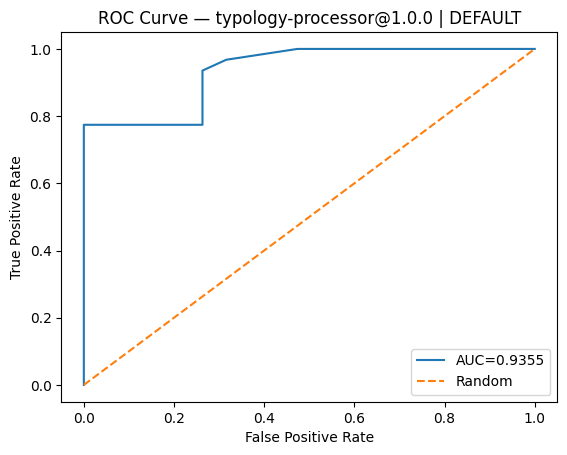

In [32]:
for (typology_id, tenant_id), roc in roc_artifacts.items():
    plt.figure()

    if len(roc["fpr"]) > 0:
        plt.plot(roc["fpr"], roc["tpr"], label=f"AUC={roc['auc']:.4f}")
        plt.plot([0, 1], [0, 1], linestyle="--", label="Random")
        plt.legend(loc="lower right")
    else:
        plt.plot([0, 1], [0, 1], linestyle="--")
        plt.text(0.05, 0.5, "ROC undefined\n(single class)", fontsize=12)

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve — {typology_id} | {tenant_id}")
    plt.show()

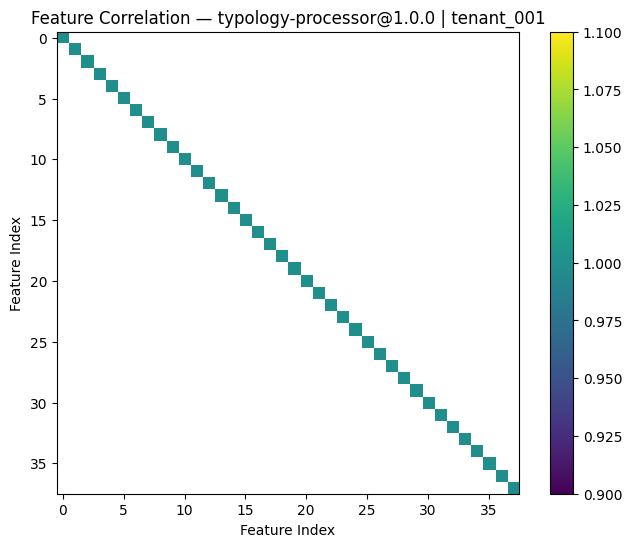

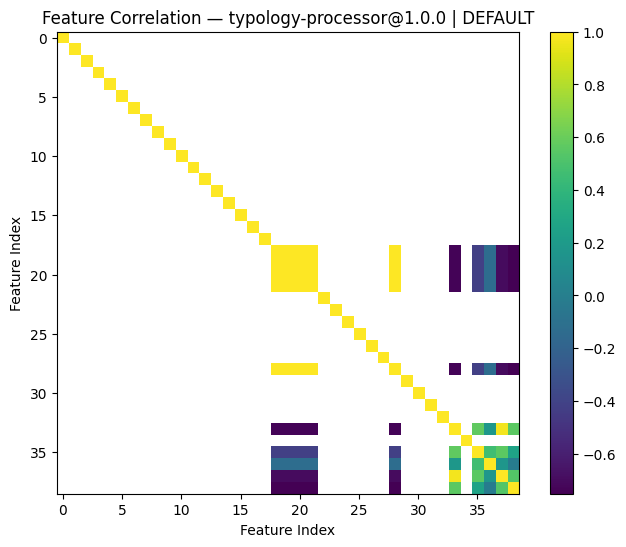

In [33]:
for (typology_id, tenant_id), payload in corr_artifacts.items():
    corr = payload["matrix"]
    features = payload["features"]

    plt.figure(figsize=(8, 6))
    plt.imshow(corr)
    plt.colorbar()
    plt.title(f"Feature Correlation — {typology_id} | {tenant_id}")
    plt.xlabel("Feature Index")
    plt.ylabel("Feature Index")
    plt.show()

In [34]:
for (typology_id, tenant_id), payload in corr_artifacts.items():
    corr_df = pd.DataFrame(
        payload["matrix"],
        index=payload["features"],
        columns=payload["features"]
    )
    print(f"\nCorrelation matrix — {typology_id} | {tenant_id}")
    display(corr_df.round(3))



Correlation matrix — typology-processor@1.0.0 | tenant_001


,001@1_0_0,002@1_0_0,003@1_0_0,004@1_0_0,006@1_0_0,007@1_0_0,008@1_0_0,010@1_0_0,011@1_0_0,016@1_0_0,...,078@1_0_0,083@1_0_0,084@1_0_0,090@1_0_0,091@1_0_0,EFRuP@1_0_0,tx_amount,is_high_value_tx,is_cross_border,priority_score
001@1_0_0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
002@1_0_0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
003@1_0_0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
004@1_0_0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
006@1_0_0,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
007@1_0_0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
008@1_0_0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
010@1_0_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
011@1_0_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
016@1_0_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Correlation matrix — typology-processor@1.0.0 | DEFAULT


,001@1_0_0,002@1_0_0,003@1_0_0,004@1_0_0,006@1_0_0,007@1_0_0,008@1_0_0,010@1_0_0,011@1_0_0,016@1_0_0,...,083@1_0_0,084@1_0_0,090@1_0_0,091@1_0_0,901@1_0_0,EFRuP@1_0_0,tx_amount,is_high_value_tx,is_cross_border,priority_score
001@1_0_0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
002@1_0_0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
003@1_0_0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
004@1_0_0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
006@1_0_0,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
007@1_0_0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
008@1_0_0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
010@1_0_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
011@1_0_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
016@1_0_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [29]:
print("SAVING CALIBRATION REPORTS")

# Convert to DataFrame
reports_df = spark.createDataFrame([json.dumps(r) for r in all_results], "string").toDF("report_json")

# Parse JSON back to structured format
reports_df = reports_df.select(from_json(col("report_json"), 
    StructType([
        StructField("calibration_id", StringType()),
        StructField("typology_id", StringType()),
        StructField("tenant_id", StringType()),
        StructField("calibration_timestamp", StringType()),
        StructField("model_performance", StringType()),
        StructField("current_baseline", StringType()),
        StructField("rule_recommendations", StringType()),
        StructField("threshold_recommendations", StringType()),
        StructField("summary", StringType())
    ])
).alias("report")).select("report.*")

output_path = f"{WAREHOUSE_ROOT}/AICAL/report"
reports_df.write.mode("append").json(output_path)

print(f"Saved {len(all_results)} calibration reports to: {output_path}")


SAVING CALIBRATION REPORTS


Saved 2 calibration reports to: /home/muneeb-faraz/Hudi_Test_Postgres/Tazama_Hudi_warehouse/AICAL/report


In [30]:
print("CALIBRATION SUMMARY - ALL TYPOLOGIES")

for report in all_results:
    print(f"\n{report['typology_id']} ({report['tenant_id']}):")
    print(f"  Current F1: {report['current_baseline']['f1_score']:.4f}")
    print(f"  Expected F1: {report['model_performance']['test_f1_score']:.4f}")
    print(f"  Rules to adjust: {report['summary']['rules_to_increase'] + report['summary']['rules_to_decrease']}")
    print(f"  Model Quality (AUC): {report['model_performance']['test_auc']:.4f}")

print(f"CALIBRATION COMPLETE!")
print(f"Total typologies calibrated: {len(all_results)}")


CALIBRATION SUMMARY - ALL TYPOLOGIES

typology-processor@1.0.0 (tenant_001):
  Current F1: 0.9888
  Expected F1: 1.0000
  Rules to adjust: 0
  Model Quality (AUC): 1.0000

typology-processor@1.0.0 (DEFAULT):
  Current F1: 0.9270
  Expected F1: 0.8000
  Rules to adjust: 5
  Model Quality (AUC): 0.9355
CALIBRATION COMPLETE!
Total typologies calibrated: 2


In [31]:
print("\nSaved models:")
for k, v in saved_model_paths.items():
    print(f"  {k}: {v}")

print("\nROC artifacts available for:")
for k, v in roc_artifacts.items():
    print(f"  {k}: AUC={v['auc']:.4f}")

print("\nCorrelation matrices available for:")
for k, v in corr_artifacts.items():
    print(f"  {k}: shape={v['matrix'].shape}, n_features={len(v['features'])}")

if len(corr_artifacts) > 0:
    (typology_id, tenant_id), payload = next(iter(corr_artifacts.items()))
    corr_df = pd.DataFrame(payload["matrix"], index=payload["features"], columns=payload["features"])
    display(corr_df.head(10))



Saved models:
  ('typology-processor@1.0.0', 'tenant_001'): /home/muneeb-faraz/Hudi_Test_Postgres/Tazama_Hudi_warehouse/AICAL/models/typology_id=typology-processor@1.0.0/tenant_id=tenant_001
  ('typology-processor@1.0.0', 'DEFAULT'): /home/muneeb-faraz/Hudi_Test_Postgres/Tazama_Hudi_warehouse/AICAL/models/typology_id=typology-processor@1.0.0/tenant_id=DEFAULT

ROC artifacts available for:
  ('typology-processor@1.0.0', 'DEFAULT'): AUC=0.9355

Correlation matrices available for:
  ('typology-processor@1.0.0', 'tenant_001'): shape=(38, 38), n_features=38
  ('typology-processor@1.0.0', 'DEFAULT'): shape=(39, 39), n_features=39


,001@1_0_0,002@1_0_0,003@1_0_0,004@1_0_0,006@1_0_0,007@1_0_0,008@1_0_0,010@1_0_0,011@1_0_0,016@1_0_0,...,078@1_0_0,083@1_0_0,084@1_0_0,090@1_0_0,091@1_0_0,EFRuP@1_0_0,tx_amount,is_high_value_tx,is_cross_border,priority_score
001@1_0_0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
002@1_0_0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
003@1_0_0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
004@1_0_0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
006@1_0_0,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
007@1_0_0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
008@1_0_0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
010@1_0_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
011@1_0_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
016@1_0_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Clustering

In [24]:
discovery_table = spark.read.format('hudi').load(clustering_data_path)
discovery_table.show(5, truncate=False)

+-------------------+---------------------+------------------------------------+----------------------+---------------------------------------------------------------------------+------------------------------------+----------------+------+---+---+---+---+---+----+---+---+---+---+-----+---+---+------+--------------------------+
|_hoodie_commit_time|_hoodie_commit_seqno |_hoodie_record_key                  |_hoodie_partition_path|_hoodie_file_name                                                          |primary_key                         |outcome_category|x1    |x2 |x3 |x4 |x5 |x6 |x7  |x8 |x9 |x10|x11|x12  |x13|x14|x15   |ingested_at_ts            |
+-------------------+---------------------+------------------------------------+----------------------+---------------------------------------------------------------------------+------------------------------------+----------------+------+---+---+---+---+---+----+---+---+---+---+-----+---+---+------+--------------------------+
|202601210

In [26]:
from pyspark.sql import functions as F

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

discovery_table_for_eda = discovery_table.withColumn(
    "ingested_at_ts", F.col("ingested_at_ts").cast("string")
)

pdf = discovery_table_for_eda.toPandas()

pdf['target_is_fraud'] = pdf['outcome_category'].apply(lambda x: 1 if x in ['TP', 'FN'] else 0)
pdf['target_is_missed'] = pdf['outcome_category'].apply(lambda x: 1 if x == 'FN' else 0)

feature_cols = [f'x{i}' for i in range(1, 16)]
analysis_cols = feature_cols + ['target_is_fraud', 'target_is_missed']
corr_matrix = pdf[analysis_cols].corr()

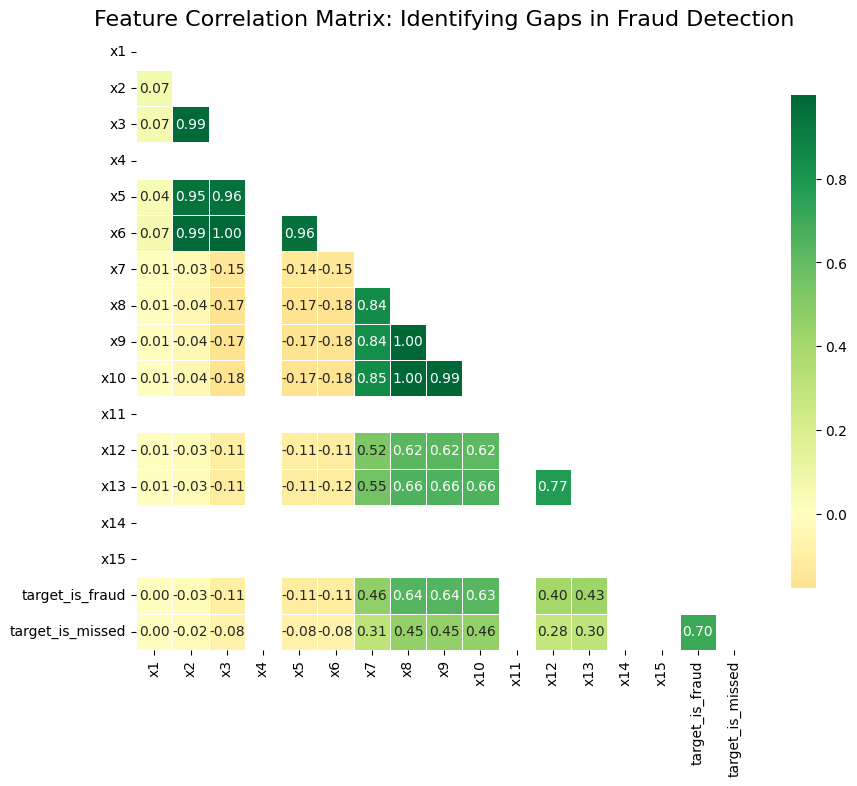

In [28]:
plt.figure(figsize=(10, 8))

# Create a mask for the upper triangle (optional, for cleaner look)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Draw the heatmap
sns.heatmap(corr_matrix, 
            mask=mask, 
            annot=True, 
            fmt=".2f", 
            cmap='RdYlGn', 
            center=0,
            square=True, 
            linewidths=.5, 
            cbar_kws={"shrink": .8})

plt.title('Feature Correlation Matrix: Identifying Gaps in Fraud Detection', fontsize=16)
plt.show()

In [29]:
feature_map = spark.read.format('hudi').load(f"{WAREHOUSE_ROOT}/AI/fraud_detection_feature_map")
feature_map.show(truncate=False)

+-------------------+----------------------+------------------+----------------------+--------------------------------------------------------------------------+------------+---------------------------+--------------------------+
|_hoodie_commit_time|_hoodie_commit_seqno  |_hoodie_record_key|_hoodie_partition_path|_hoodie_file_name                                                         |feature_name|feature_description        |as_of_ts                  |
+-------------------+----------------------+------------------+----------------------+--------------------------------------------------------------------------+------------+---------------------------+--------------------------+
|20260122015652200  |20260122015652200_0_0 |x1                |                      |3c1a4cc1-d40f-49cb-b0cb-35ab8dff72e1-0_0-30-2203_20260122015652200.parquet|x1          |Transaction Amount         |2026-01-22 06:56:56.463804|
|20260122015652200  |20260122015652200_0_1 |x15               |                 

In [30]:
import pyspark.sql.functions as F
from pyspark.sql.window import Window


w = Window.partitionBy("feature_name").orderBy(F.col("as_of_ts").desc())

feature_map = (
    feature_map
    .withColumn("rn", F.row_number().over(w))
    .filter(F.col("rn") == 1)
    .select("feature_name", "feature_description")
)

feature_map = dict(
    feature_map
    .toPandas()
    .set_index("feature_name")["feature_description"]
    .to_dict()
)

print(feature_map.get("x8"))
print(len(feature_map), "features in map")


Rule Band Count
15 features in map


In [31]:
fn_correlations = corr_matrix['target_is_missed'].sort_values(ascending=False)

print(f"{'='*60}")
print(f"TOP FEATURES CORRELATED WITH MISSED FRAUD (FN)")
print(f"{'='*60}")
for feature, value in fn_correlations.items():
    if feature != 'target_is_missed':
        desc = feature_map.get(feature, "Unknown")
        print(f"{feature} ({desc}): {value:.4f}")

TOP FEATURES CORRELATED WITH MISSED FRAUD (FN)
target_is_fraud (Unknown): 0.7014
x10 (Rule Band 02 Upper Limit): 0.4552
x8 (Rule Band Count): 0.4537
x9 (Rule Band 01 Upper Limit): 0.4530
x7 (Existing Priority Score): 0.3124
x13 (Number of Rules in Typology): 0.2983
x12 (Typology Alert Threshold): 0.2820
x1 (Transaction Amount): 0.0029
x2 (Transaction Hour): -0.0186
x5 (Is Round 100 Amount): -0.0770
x6 (Is Whole Number): -0.0805
x3 (Day of Week): -0.0806
x4 (Cross-Bank Indicator): nan
x11 (Rule Lookback Interval): nan
x14 (Rule 01 Weight in Typology): nan
x15 (Bank-Level TX Count): nan


In [32]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
from sklearn.cluster import HDBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
from pyspark.sql.functions import col, when, lit
from pyspark.sql.types import DoubleType

In [33]:
pdf = discovery_table_for_eda.toPandas()

# Create binary targets for analysis
# target_is_missed: The specific target for "Hidden Fraud" (FN)
pdf['target_is_missed'] = pdf['outcome_category'].apply(lambda x: 1 if x == 'FN' else 0)
pdf['is_fraud_actual'] = pdf['outcome_category'].apply(lambda x: 1 if x in ['TP', 'FN'] else 0)
pdf['is_fraud_predicted'] = pdf['outcome_category'].apply(lambda x: 1 if x in ['TP', 'FP'] else 0)

# FEATURE ENGINEERING & CLEANING
# Dropping features with 0 variance (based on previous heatmap analysis) to reduce noise
drop_cols = ['x2', 'x5', 'x6', 'x10'] 
active_features = [f'x{i}' for i in range(1, 16) if f'x{i}' not in drop_cols]

print(f"Data Loaded. Active Features for Analysis: {active_features}")

Data Loaded. Active Features for Analysis: ['x1', 'x3', 'x4', 'x7', 'x8', 'x9', 'x11', 'x12', 'x13', 'x14', 'x15']


In [34]:
feature_names = active_features

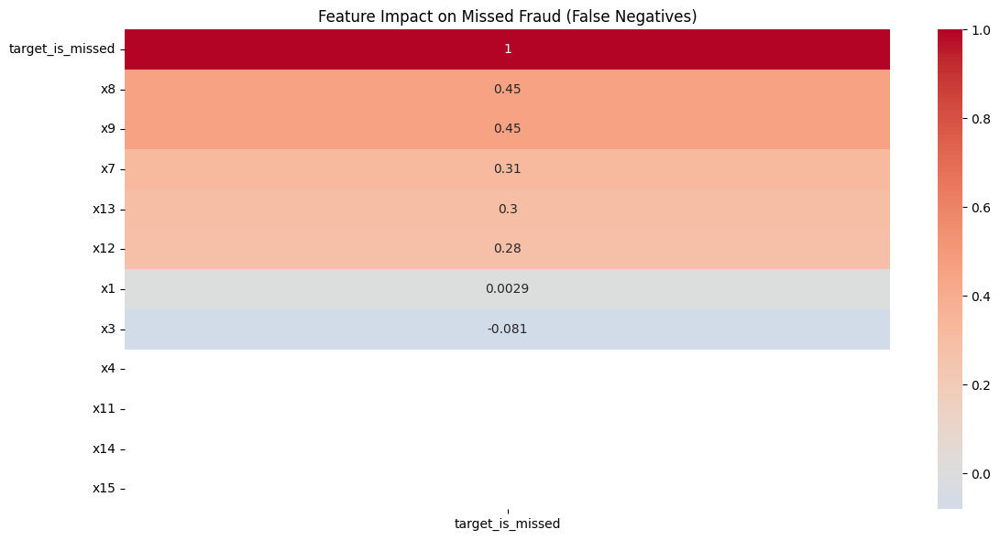

In [35]:
corr_data = pdf[active_features + ['target_is_missed']]
corr_matrix = corr_data.corr()

plt.figure(figsize=(12, 6))
sns.heatmap(corr_matrix[['target_is_missed']].sort_values(by='target_is_missed', ascending=False),
            annot=True, cmap='coolwarm', center=0)
plt.title("Feature Impact on Missed Fraud (False Negatives)")
plt.tight_layout()
plt.show()

/root/miniconda3/envs/spark/lib/python3.12/site-packages/xgboost/training.py:199: UserWarning: [22:44:26] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


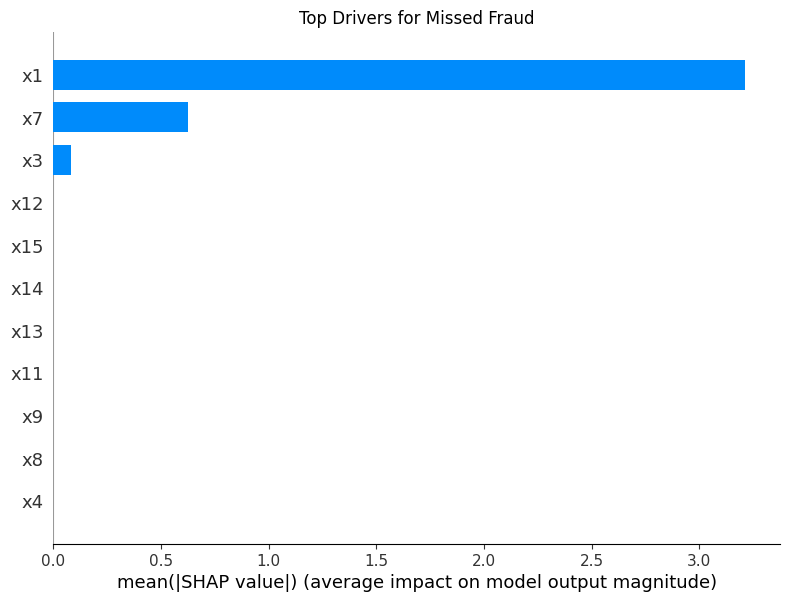

In [36]:
model_data = pdf[pdf['outcome_category'].isin(['TP', 'FN'])].copy()
model_data['is_missed'] = (model_data['outcome_category'] == 'FN').astype(int)

X = model_data[active_features]
y = model_data['is_missed']

# XGBoost Model
model = xgb.XGBClassifier(eval_metric='logloss', use_label_encoder=False)
model.fit(X, y)

# SHAP Explainer
explainer = shap.Explainer(model)
shap_values = explainer(X)

# Filter SHAP values for just the Missed Frauds (FN)
fn_indices = np.where(y == 1)[0]
fn_shap_values = shap_values.values[fn_indices]
fn_data_raw = X.iloc[fn_indices]

plt.figure()
shap.summary_plot(fn_shap_values, fn_data_raw, plot_type="bar", show=False)
plt.title("Top Drivers for Missed Fraud")
plt.show()

In [37]:
scaler = StandardScaler()
# We use the SHAP values for clustering because they represent the *behavioral* reason
shap_scaled = scaler.fit_transform(fn_shap_values)

# HDBSCAN with parameters tuned for small, dense pockets of fraud
clusterer = HDBSCAN(min_cluster_size=3, min_samples=2)
cluster_labels = clusterer.fit_predict(shap_scaled)

results_df = fn_data_raw.copy()
results_df['Cluster_ID'] = cluster_labels
results_df['Typology_Name'] = results_df['Cluster_ID'].apply(lambda x: f"Hidden_Typology_{x}" if x >= 0 else "Noise")

/root/miniconda3/envs/spark/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


In [38]:
labels = results_df["Cluster_ID"].values
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
noise_ct = int((labels == -1).sum())
print(f"Clusters found: {n_clusters}")
print(f"Noise points: {noise_ct} ({noise_ct/len(labels):.1%})")

cluster_sizes = (
    results_df[results_df["Cluster_ID"] != -1]
    .groupby("Cluster_ID")
    .size()
    .sort_values(ascending=False)
)
print("\nCluster sizes:")
display(cluster_sizes)


Clusters found: 34
Noise points: 0 (0.0%)

Cluster sizes:


Cluster_ID
18    180
17    120
12    120
6     120
32     60
31     60
28     60
26     60
24     60
20     60
19     60
15     60
33     60
8      60
2      60
4      60
10     60
13     36
14     24
0      24
9      24
21     12
22     12
1      12
7      12
25     12
5      12
27     12
16     12
29     12
30     12
3      12
11     12
23     12
dtype: int64

In [39]:
results_df["Cluster_Confidence"] = clusterer.probabilities_

/root/miniconda3/envs/spark/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/root/miniconda3/envs/spark/lib/python3.12/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/root/miniconda3/envs/spark/lib/python3.12/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/root/miniconda3/envs/spark/lib/python3.12/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding som

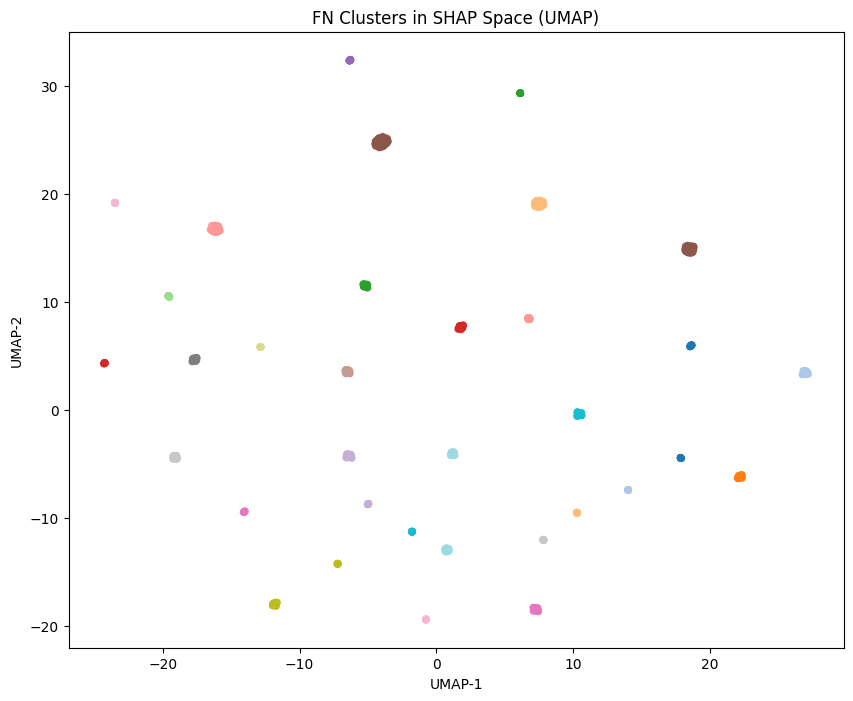

In [40]:
import umap
reducer = umap.UMAP(n_neighbors=10, min_dist=0.1, metric="euclidean", random_state=42)
embedding = reducer.fit_transform(shap_scaled)

plt.figure(figsize=(10, 8))
plt.scatter(embedding[:, 0], embedding[:, 1], c=cluster_labels, cmap="tab20", s=20, alpha=0.85)
plt.title("FN Clusters in SHAP Space (UMAP)")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.show()

In [41]:
import builtins

In [42]:
def show_cluster_examples(results_df, cluster_id, n=8):
    print(f"\n--- Cluster {cluster_id} examples (top {n} by confidence) ---")
    display(
        results_df[results_df["Cluster_ID"] == cluster_id]
        .sort_values("Cluster_Confidence", ascending=False)
        .head(n)
    )

for cid in cluster_sizes.index[:builtins.min(5, len(cluster_sizes))]:
    show_cluster_examples(results_df, cid, n=8)



--- Cluster 18 examples (top 8 by confidence) ---


,x1,x3,x4,x7,x8,x9,x11,x12,x13,x14,x15,Cluster_ID,Typology_Name,Cluster_Confidence
203929,0.0,3.0,1.0,33.0,3.0,2.0,0.0,220.0,34.0,0.0,205251.0,18,Hidden_Typology_18,1.0
204060,0.0,3.0,1.0,33.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,18,Hidden_Typology_18,1.0
204062,0.0,3.0,1.0,33.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,18,Hidden_Typology_18,1.0
204063,0.0,3.0,1.0,33.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,18,Hidden_Typology_18,1.0
204064,0.0,3.0,1.0,33.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,18,Hidden_Typology_18,1.0
204065,0.0,3.0,1.0,33.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,18,Hidden_Typology_18,1.0
204066,0.0,3.0,1.0,33.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,18,Hidden_Typology_18,1.0
204433,0.0,3.0,1.0,33.0,3.0,2.0,0.0,220.0,34.0,0.0,205251.0,18,Hidden_Typology_18,1.0



--- Cluster 17 examples (top 8 by confidence) ---


,x1,x3,x4,x7,x8,x9,x11,x12,x13,x14,x15,Cluster_ID,Typology_Name,Cluster_Confidence
198097,0.0,3.0,1.0,10.0,3.0,2.0,0.0,220.0,34.0,0.0,205251.0,17,Hidden_Typology_17,1.0
198098,0.0,3.0,1.0,10.0,3.0,2.0,0.0,220.0,34.0,0.0,205251.0,17,Hidden_Typology_17,1.0
198341,0.0,3.0,1.0,10.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,17,Hidden_Typology_17,1.0
198340,0.0,3.0,1.0,10.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,17,Hidden_Typology_17,1.0
198339,0.0,3.0,1.0,10.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,17,Hidden_Typology_17,1.0
198338,0.0,3.0,1.0,10.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,17,Hidden_Typology_17,1.0
198337,0.0,3.0,1.0,10.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,17,Hidden_Typology_17,1.0
198336,0.0,3.0,1.0,10.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,17,Hidden_Typology_17,1.0



--- Cluster 12 examples (top 8 by confidence) ---


,x1,x3,x4,x7,x8,x9,x11,x12,x13,x14,x15,Cluster_ID,Typology_Name,Cluster_Confidence
200761,0.0,3.0,1.0,99.0,3.0,2.0,0.0,220.0,34.0,0.0,205251.0,12,Hidden_Typology_12,1.0
200762,0.0,3.0,1.0,99.0,3.0,2.0,0.0,220.0,34.0,0.0,205251.0,12,Hidden_Typology_12,1.0
202733,0.0,3.0,1.0,99.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,12,Hidden_Typology_12,1.0
202732,0.0,3.0,1.0,99.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,12,Hidden_Typology_12,1.0
202731,0.0,3.0,1.0,99.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,12,Hidden_Typology_12,1.0
202730,0.0,3.0,1.0,99.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,12,Hidden_Typology_12,1.0
202729,0.0,3.0,1.0,99.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,12,Hidden_Typology_12,1.0
202728,0.0,3.0,1.0,99.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,12,Hidden_Typology_12,1.0



--- Cluster 6 examples (top 8 by confidence) ---


,x1,x3,x4,x7,x8,x9,x11,x12,x13,x14,x15,Cluster_ID,Typology_Name,Cluster_Confidence
200473,0.0,3.0,1.0,0.0,3.0,2.0,0.0,220.0,34.0,0.0,205251.0,6,Hidden_Typology_6,1.0
200474,0.0,3.0,1.0,0.0,3.0,2.0,0.0,220.0,34.0,0.0,205251.0,6,Hidden_Typology_6,1.0
201437,0.0,3.0,1.0,0.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,6,Hidden_Typology_6,1.0
201436,0.0,3.0,1.0,0.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,6,Hidden_Typology_6,1.0
201435,0.0,3.0,1.0,0.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,6,Hidden_Typology_6,1.0
201434,0.0,3.0,1.0,0.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,6,Hidden_Typology_6,1.0
201433,0.0,3.0,1.0,0.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,6,Hidden_Typology_6,1.0
201432,0.0,3.0,1.0,0.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,6,Hidden_Typology_6,1.0



--- Cluster 32 examples (top 8 by confidence) ---


,x1,x3,x4,x7,x8,x9,x11,x12,x13,x14,x15,Cluster_ID,Typology_Name,Cluster_Confidence
202417,816.4,3.0,1.0,33.0,3.0,2.0,0.0,220.0,34.0,0.0,205251.0,32,Hidden_Typology_32,1.0
202418,816.4,3.0,1.0,33.0,3.0,2.0,0.0,220.0,34.0,0.0,205251.0,32,Hidden_Typology_32,1.0
202455,816.4,3.0,1.0,33.0,3.0,2.0,0.0,220.0,34.0,0.0,205251.0,32,Hidden_Typology_32,1.0
202456,816.4,3.0,1.0,33.0,3.0,2.0,0.0,220.0,34.0,0.0,205251.0,32,Hidden_Typology_32,1.0
202457,816.4,3.0,1.0,33.0,3.0,2.0,0.0,220.0,34.0,0.0,205251.0,32,Hidden_Typology_32,1.0
202458,816.4,3.0,1.0,33.0,3.0,2.0,0.0,220.0,34.0,0.0,205251.0,32,Hidden_Typology_32,1.0
202459,816.4,3.0,1.0,33.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,32,Hidden_Typology_32,1.0
202460,816.4,3.0,1.0,33.0,3.0,2.0,0.0,300.0,3.0,0.0,205251.0,32,Hidden_Typology_32,1.0


In [43]:
import pandas as pd

# SHAP DF for FNs only (aligned with results_df index)
shap_fn_df = pd.DataFrame(fn_shap_values, columns=active_features, index=fn_data_raw.index)

def cluster_typology_cards(results_df, shap_fn_df, pdf, top_k=5):
    cards = []
    for cid in sorted(results_df["Cluster_ID"].unique()):
        if cid == -1:
            continue

        idx = results_df.index[results_df["Cluster_ID"] == cid]
        n = len(idx)

        mean_abs = shap_fn_df.loc[idx].abs().mean().sort_values(ascending=False)
        top_feats = mean_abs.head(top_k).index.tolist()

        deltas = []
        for f in top_feats:
            c_mean = results_df.loc[idx, f].mean()
            g_mean = pdf[f].mean()
            direction = "HIGH" if c_mean > g_mean else "LOW"
            deltas.append(
                f"{f}({feature_map.get(f,f)}): {direction} (cluster={c_mean:.3f}, global={g_mean:.3f})"
            )

        cards.append({
            "Cluster_ID": cid,
            "n_FNs": n,
            "avg_confidence": float(results_df.loc[idx, "Cluster_Confidence"].mean()),
            "top_shap_drivers": ", ".join([f"{f}({feature_map.get(f,f)})" for f in top_feats]),
            "feature_deltas_vs_global": " | ".join(deltas),
        })
    return pd.DataFrame(cards).sort_values(["n_FNs"], ascending=False)

typology_cards_df = cluster_typology_cards(results_df, shap_fn_df, pdf, top_k=5)
display(typology_cards_df, truncate=False)


,Cluster_ID,n_FNs,avg_confidence,top_shap_drivers,feature_deltas_vs_global
18,18,180,1.0,"x7(Existing Priority Score), x1(Transaction Am...",x7(Existing Priority Score): HIGH (cluster=33....
17,17,120,1.0,"x7(Existing Priority Score), x1(Transaction Am...",x7(Existing Priority Score): HIGH (cluster=10....
12,12,120,1.0,"x7(Existing Priority Score), x3(Day of Week), ...",x7(Existing Priority Score): HIGH (cluster=99....
6,6,120,1.0,"x1(Transaction Amount), x7(Existing Priority S...","x1(Transaction Amount): LOW (cluster=0.000, gl..."
32,32,60,1.0,"x1(Transaction Amount), x7(Existing Priority S...","x1(Transaction Amount): HIGH (cluster=816.400,..."
31,31,60,1.0,"x1(Transaction Amount), x3(Day of Week), x7(Ex...","x1(Transaction Amount): LOW (cluster=160.730, ..."
28,28,60,1.0,"x1(Transaction Amount), x7(Existing Priority S...","x1(Transaction Amount): HIGH (cluster=902.950,..."
26,26,60,1.0,"x1(Transaction Amount), x7(Existing Priority S...","x1(Transaction Amount): LOW (cluster=142.780, ..."
24,24,60,1.0,"x1(Transaction Amount), x7(Existing Priority S...","x1(Transaction Amount): HIGH (cluster=418.140,..."
20,20,60,1.0,"x1(Transaction Amount), x7(Existing Priority S...","x1(Transaction Amount): HIGH (cluster=212.170,..."


In [67]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# Full evaluation frame (includes TN/FP too)
eval_df = pdf.copy()

y_true = eval_df["is_fraud_actual"].values.astype(int)
baseline_pred = eval_df["is_fraud_predicted"].values.astype(int)

def eval_preds(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "alert_rate": float(np.mean(y_pred))
    }

In [45]:
baseline_metrics = eval_preds(y_true, baseline_pred)
print("Baseline metrics:", baseline_metrics)

Baseline metrics: {'TP': 1610, 'FP': 1440, 'TN': 200617, 'FN': 1584, 'precision': 0.5278688524590164, 'recall': 0.504070131496556, 'f1': 0.515695067264574, 'alert_rate': 0.014859854519588211}


In [68]:
def find_best_threshold_rule(
    df, feature, direction,
    y_true, baseline_pred,
    quantiles=(0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.98, 0.99),
    max_extra_alert_rate=0.02,
    max_rule_fire_rate=0.20,     # rule itself shouldn't trigger on >20% of population
    min_rule_fire_rate=0.0005    # don't bother if it triggers on ~0%
):
    best = None

    # numeric coercion (very important after new rows/joins)
    x = pd.to_numeric(df[feature], errors="coerce").values
    x_nonan = x[~np.isnan(x_nonan := x)]  # keeps x_nonan as non-nan view

    # if feature is empty or basically constant, no usable threshold rule
    if x_nonan.size == 0:
        return None
    if np.nanmin(x_nonan) == np.nanmax(x_nonan):
        return None

    base_rate = float(np.mean(baseline_pred))

    # quantile thresholds (dedupe them so we don't re-test the same thr)
    thrs = []
    for q in quantiles:
        thr = float(np.nanquantile(x, q))
        if not np.isnan(thr):
            thrs.append(thr)
    thrs = sorted(set(thrs))

    for thr in thrs:
        # IMPORTANT: use strict comparisons to avoid "everything triggers"
        if direction == "gt":
            rule_trigger = (pd.to_numeric(df[feature], errors="coerce").values > thr).astype(int)
            logic = f"{feature} > {thr:.6g}"
        else:
            rule_trigger = (pd.to_numeric(df[feature], errors="coerce").values < thr).astype(int)
            logic = f"{feature} < {thr:.6g}"

        rule_rate = float(rule_trigger.mean())
        if rule_rate > max_rule_fire_rate or rule_rate < min_rule_fire_rate:
            continue

        new_pred = np.maximum(baseline_pred, rule_trigger)
        m = eval_preds(y_true, new_pred)

        extra_alert_rate = m["alert_rate"] - base_rate
        if extra_alert_rate > max_extra_alert_rate:
            continue

        score = (m["recall"], m["precision"], m["f1"])
        if best is None or score > best["score"]:
            best = {
                "feature": feature,
                "direction": direction,
                "threshold": float(thr),
                "logic": logic,
                "metrics": m,
                "extra_alert_rate": float(extra_alert_rate),
                "rule_fire_rate": rule_rate,
                "score": score
            }

    return best

In [47]:
candidate_rules = []

cluster_sizes = (
    results_df[results_df["Cluster_ID"] != -1]
    .groupby("Cluster_ID")
    .size()
    .sort_values(ascending=False)
)

In [69]:
for cid in cluster_sizes.index:
    cluster_idx = results_df.index[results_df["Cluster_ID"] == cid]

    # top drivers by mean(|SHAP|) within cluster
    top_feats = (
        shap_fn_df.loc[cluster_idx].abs().mean()
        .sort_values(ascending=False)
        .head(5)
        .index.tolist()
    )

    for feat in top_feats:
        c_med = results_df.loc[cluster_idx, feat].median()
        g_med = eval_df[feat].median()
        direction = "gt" if c_med > g_med else "lt"

        best = find_best_threshold_rule(
            df=eval_df,
            feature=feat,
            direction=direction,
            y_true=y_true,
            baseline_pred=baseline_pred,
            max_extra_alert_rate=0.02
        )

        if best:
            row = {
                "cluster_id": int(cid),
                "rule_name": f"DS_Gen_Rule_C{cid}_{feat}",
                "logic": best["logic"],
                "feature_description": feature_map.get(feat, feat),
                "extra_alert_rate": best["extra_alert_rate"],
                **best["metrics"]
            }
            candidate_rules.append(row)

In [70]:
candidates_df = pd.DataFrame(candidate_rules).sort_values(
    ["recall", "precision", "f1"], ascending=False
)

display(candidates_df.head(25))

,cluster_id,rule_name,logic,feature_description,extra_alert_rate,TP,FP,TN,FN,precision,recall,f1,alert_rate
0,18,DS_Gen_Rule_C18_x7,x7 > 45,Existing Priority Score,0.010524,2186,3024,199033,1008,0.419578,0.684408,0.520228,0.025384
2,17,DS_Gen_Rule_C17_x7,x7 > 45,Existing Priority Score,0.010524,2186,3024,199033,1008,0.419578,0.684408,0.520228,0.025384
4,12,DS_Gen_Rule_C12_x7,x7 > 45,Existing Priority Score,0.010524,2186,3024,199033,1008,0.419578,0.684408,0.520228,0.025384
8,32,DS_Gen_Rule_C32_x7,x7 > 45,Existing Priority Score,0.010524,2186,3024,199033,1008,0.419578,0.684408,0.520228,0.025384
11,31,DS_Gen_Rule_C31_x7,x7 > 45,Existing Priority Score,0.010524,2186,3024,199033,1008,0.419578,0.684408,0.520228,0.025384
14,28,DS_Gen_Rule_C28_x7,x7 > 45,Existing Priority Score,0.010524,2186,3024,199033,1008,0.419578,0.684408,0.520228,0.025384
17,26,DS_Gen_Rule_C26_x7,x7 > 45,Existing Priority Score,0.010524,2186,3024,199033,1008,0.419578,0.684408,0.520228,0.025384
20,24,DS_Gen_Rule_C24_x7,x7 > 45,Existing Priority Score,0.010524,2186,3024,199033,1008,0.419578,0.684408,0.520228,0.025384
23,20,DS_Gen_Rule_C20_x7,x7 > 45,Existing Priority Score,0.010524,2186,3024,199033,1008,0.419578,0.684408,0.520228,0.025384
28,15,DS_Gen_Rule_C15_x7,x7 > 45,Existing Priority Score,0.010524,2186,3024,199033,1008,0.419578,0.684408,0.520228,0.025384


In [53]:
print("DISCOVERY ENGINE: CANDIDATE RULE REPORT")
print("=" * 60)

generated_rules = []
fn_total = len(pdf[pdf["outcome_category"] == "FN"])

# only allow rule features from your modeling feature set
allowed_feats = [c for c in active_features if c in results_df.columns and c in pdf.columns]

for cluster_id in sorted(results_df["Cluster_ID"].unique()):
    if cluster_id == -1:
        continue

    subset = results_df[results_df["Cluster_ID"] == cluster_id]
    size = len(subset)

    # compute std ONLY on allowed features
    top_feats = (
        subset[allowed_feats]
        .std(numeric_only=True)
        .sort_values(ascending=False)
        .head(2)
        .index
        .tolist()
    )

    rule_logic = []
    explanation = f"Cluster {cluster_id} (n={size}): "

    for feat in top_feats:
        mean_val = subset[feat].mean()
        global_mean = pdf[feat].mean()

        if mean_val > global_mean:
            rule_logic.append(f"{feat} > {mean_val:.2f}")
            explanation += f"High {feature_map.get(feat, feat)} ({mean_val:.2f}); "
        else:
            rule_logic.append(f"{feat} < {mean_val:.2f}")
            explanation += f"Low {feature_map.get(feat, feat)} ({mean_val:.2f}); "

    impact_score = (size / fn_total) * 100 if fn_total else 0.0

    rule_proposal = {
        "rule_name": f"DS_Gen_Rule_C{cluster_id}",
        "description": f"Auto-generated rule for {explanation}",
        "logic": " AND ".join(rule_logic),
        "impact_analysis": f"Captures {impact_score:.1f}% of currently missed fraud.",
        "typology_target": "Typology_214_New",
    }

    generated_rules.append(rule_proposal)

    print(f"📌 {rule_proposal['rule_name']}")
    print(f"   Logic: {rule_proposal['logic']}")
    print(f"   Impact: {rule_proposal['impact_analysis']}")
    print(f"   Context: {rule_proposal['description']}\n")


DISCOVERY ENGINE: CANDIDATE RULE REPORT
📌 DS_Gen_Rule_C0
   Logic: x1 < 0.00 AND x3 < 3.00
   Impact: Captures 1.5% of currently missed fraud.
   Context: Auto-generated rule for Cluster 0 (n=24): Low Transaction Amount (0.00); Low Day of Week (3.00); 

📌 DS_Gen_Rule_C1
   Logic: x1 > 616.37 AND x3 < 3.00
   Impact: Captures 0.8% of currently missed fraud.
   Context: Auto-generated rule for Cluster 1 (n=12): High Transaction Amount (616.37); Low Day of Week (3.00); 

📌 DS_Gen_Rule_C2
   Logic: x12 > 664.00 AND x13 > 15.40
   Impact: Captures 3.8% of currently missed fraud.
   Context: Auto-generated rule for Cluster 2 (n=60): High Typology Alert Threshold (664.00); High Number of Rules in Typology (15.40); 

📌 DS_Gen_Rule_C3
   Logic: x1 < 0.00 AND x3 < 3.00
   Impact: Captures 0.8% of currently missed fraud.
   Context: Auto-generated rule for Cluster 3 (n=12): Low Transaction Amount (0.00); Low Day of Week (3.00); 

📌 DS_Gen_Rule_C4
   Logic: x12 > 664.00 AND x13 > 15.40
   Impact: 

In [54]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

def metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "alert_rate": float(np.mean(y_pred)),
    }

# ---- 1) Feature drop justification (variance + nulls) ----
eda_df = pdf.copy()
feat_stats = []
for f in [c for c in pdf.columns if c.startswith("x")]:
    s = pd.to_numeric(eda_df[f], errors="coerce")
    feat_stats.append({
        "feature": f,
        "desc": feature_map.get(f, f),
        "non_null_pct": float(s.notna().mean()),
        "n_unique": int(s.nunique(dropna=True)),
        "std": float(s.std(skipna=True)) if s.notna().any() else np.nan
    })
feat_stats_df = pd.DataFrame(feat_stats).sort_values(["non_null_pct","n_unique","std"])
display(feat_stats_df)

# ---- 2) Baseline metrics ----
y_true = pdf["is_fraud_actual"].astype(int).values
baseline_pred = pdf["is_fraud_predicted"].astype(int).values
baseline_m = metrics(y_true, baseline_pred)
print("Baseline metrics:", baseline_m)

# ---- 3) Cluster diagnostics ----
labels = results_df["Cluster_ID"].values
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
noise_pct = float(np.mean(labels == -1))
print(f"Clusters found: {n_clusters}")
print(f"Noise rate: {noise_pct:.2%}")

cluster_sizes = (
    results_df[results_df["Cluster_ID"] != -1]
    .groupby("Cluster_ID")
    .size()
    .sort_values(ascending=False)
)
display(cluster_sizes)

# ---- 4) Typology cards (top SHAP drivers per cluster) ----
shap_fn_df = pd.DataFrame(fn_shap_values, columns=active_features, index=fn_data_raw.index)

cards = []
for cid in sorted(results_df["Cluster_ID"].unique()):
    if cid == -1:
        continue
    idx = results_df.index[results_df["Cluster_ID"] == cid]
    mean_abs = shap_fn_df.loc[idx].abs().mean().sort_values(ascending=False)
    top_feats = mean_abs.head(5).index.tolist()
    cards.append({
        "Cluster_ID": int(cid),
        "n_FNs": int(len(idx)),
        "top_shap_drivers": ", ".join([f"{f}({feature_map.get(f,f)})" for f in top_feats]),
        "avg_cluster_confidence": float(results_df.loc[idx, "Cluster_Confidence"].mean()) if "Cluster_Confidence" in results_df.columns else np.nan
    })
typology_cards_df = pd.DataFrame(cards).sort_values("n_FNs", ascending=False)
display(typology_cards_df)


,feature,desc,non_null_pct,n_unique,std
3,x4,Cross-Bank Indicator,1.0,1,0.000000
10,x11,Rule Lookback Interval,1.0,1,0.000000
13,x14,Rule 01 Weight in Typology,1.0,1,0.000000
14,x15,Bank-Level TX Count,1.0,1,0.000000
4,x5,Is Round 100 Amount,1.0,2,0.495411
5,x6,Is Whole Number,1.0,2,0.497919
2,x3,Day of Week,1.0,2,0.497975
8,x9,Rule Band 01 Upper Limit,1.0,3,0.375107
9,x10,Rule Band 02 Upper Limit,1.0,3,0.560225
7,x8,Rule Band Count,1.0,3,0.561837


Baseline metrics: {'TP': 1610, 'FP': 1440, 'TN': 200617, 'FN': 1584, 'precision': 0.5278688524590164, 'recall': 0.504070131496556, 'f1': 0.515695067264574, 'alert_rate': 0.014859854519588211}
Clusters found: 34
Noise rate: 0.00%


Cluster_ID
18    180
17    120
12    120
6     120
32     60
31     60
28     60
26     60
24     60
20     60
19     60
15     60
33     60
8      60
2      60
4      60
10     60
13     36
14     24
0      24
9      24
21     12
22     12
1      12
7      12
25     12
5      12
27     12
16     12
29     12
30     12
3      12
11     12
23     12
dtype: int64

,Cluster_ID,n_FNs,top_shap_drivers,avg_cluster_confidence
18,18,180,"x7(Existing Priority Score), x1(Transaction Am...",1.0
17,17,120,"x7(Existing Priority Score), x1(Transaction Am...",1.0
12,12,120,"x7(Existing Priority Score), x3(Day of Week), ...",1.0
6,6,120,"x1(Transaction Amount), x7(Existing Priority S...",1.0
32,32,60,"x1(Transaction Amount), x7(Existing Priority S...",1.0
31,31,60,"x1(Transaction Amount), x3(Day of Week), x7(Ex...",1.0
28,28,60,"x1(Transaction Amount), x7(Existing Priority S...",1.0
26,26,60,"x1(Transaction Amount), x7(Existing Priority S...",1.0
24,24,60,"x1(Transaction Amount), x7(Existing Priority S...",1.0
20,20,60,"x1(Transaction Amount), x7(Existing Priority S...",1.0


In [71]:
import builtins
import numpy as np
import pandas as pd
from datetime import datetime

def _safe_pct(x, denom):
    return 0.0 if denom == 0 else (x / denom) * 100.0

def _fmt_pct(x):
    return f"{x:.1f}%"

def _fmt_num(x):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return "N/A"
    if isinstance(x, (int, np.integer)):
        return str(int(x))
    return f"{x:.4f}"

def _feature_desc(feature_map, f):
    return feature_map.get(f, f)

def generate_layman_report(
    pdf: pd.DataFrame,
    feature_map: dict,
    active_features: list,
    drop_cols: list = None,
    corr_matrix: pd.DataFrame = None,
    fn_shap_values=None,
    fn_data_raw=None,
    results_df: pd.DataFrame = None,
    clusterer=None,
    report_title: str = "Fraud Detection Improvement Report (Layman Version)",
    top_k_corr: int = 5,
    top_k_shap: int = 8,
    top_k_clusters: int = 5,
    output_path: str = "fraud_discovery_report_layman.md",
):
    """
    Generates a layman-friendly Markdown report summarizing:
      - dataset outcomes
      - correlation highlights
      - why features were dropped
      - SHAP driver summary (missed fraud)
      - clustering summary (typologies)
    Saves to output_path and returns the markdown string.
    """

    drop_cols = drop_cols or []

    # ---------- 1) Basic dataset counts ----------
    if "outcome_category" not in pdf.columns:
        raise ValueError("pdf must include 'outcome_category' column.")

    counts = pdf["outcome_category"].value_counts(dropna=False).to_dict()
    tp = int(counts.get("TP", 0))
    fp = int(counts.get("FP", 0))
    tn = int(counts.get("TN", 0))
    fn = int(counts.get("FN", 0))
    total = int(len(pdf))

    # ---------- 2) Correlation summary (optional) ----------
    corr_lines = []
    if corr_matrix is not None and "target_is_missed" in corr_matrix.columns:
        # get top positive/negative correlations excluding the target itself
        s = corr_matrix["target_is_missed"].drop(labels=["target_is_missed"], errors="ignore")
        # drop NaNs
        s = s.dropna()

        top_pos = s.sort_values(ascending=False).head(top_k_corr)
        top_neg = s.sort_values(ascending=True).head(top_k_corr)

        if len(top_pos) > 0:
            corr_lines.append("### What simple statistics suggested")
            corr_lines.append(
                "We first did a basic statistical scan to see which attributes tend to show up more in missed fraud. "
                "This does **not** prove causation, but it helps us know where to look."
            )
            corr_lines.append("")
            corr_lines.append("**Attributes most associated with missed fraud (higher = more likely to appear in missed fraud):**")
            for f, v in top_pos.items():
                corr_lines.append(f"- `{f}` ({_feature_desc(feature_map, f)}): {v:.4f}")
            corr_lines.append("")
            corr_lines.append("**Attributes least associated with missed fraud (lower/negative = less likely to appear in missed fraud):**")
            for f, v in top_neg.items():
                corr_lines.append(f"- `{f}` ({_feature_desc(feature_map, f)}): {v:.4f}")
            corr_lines.append("")
    else:
        corr_lines.append("### What simple statistics suggested")
        corr_lines.append(
            "Correlation results were not provided in this run (or `target_is_missed` was missing). "
            "If you pass `corr_matrix`, this section will list the strongest simple statistical signals."
        )
        corr_lines.append("")

    # ---------- 3) Feature drop justification ----------
    # compute per-feature health stats for x-columns
    feat_health = []
    for f in sorted([c for c in pdf.columns if isinstance(c, str) and c.startswith("x")]):
        s = pd.to_numeric(pdf[f], errors="coerce")
        feat_health.append({
            "feature": f,
            "desc": _feature_desc(feature_map, f),
            "non_null_pct": float(s.notna().mean()) * 100.0,
            "unique_values": int(s.nunique(dropna=True)),
            "std": float(s.std(skipna=True)) if s.notna().any() else np.nan,
        })
    feat_health_df = pd.DataFrame(feat_health).sort_values(["non_null_pct", "unique_values", "std"], ascending=True)

    dropped_detail_lines = []
    if drop_cols:
        dropped_detail_lines.append("### Why some attributes were removed")
        dropped_detail_lines.append(
            "Some attributes were removed because they did not carry useful information for learning patterns. "
            "This typically happens when a field is mostly empty, never changes, or repeats information already captured elsewhere."
        )
        dropped_detail_lines.append("")
        dropped_detail_lines.append("**Removed attributes:** " + ", ".join([f"`{c}` ({_feature_desc(feature_map,c)})" for c in drop_cols]))
        dropped_detail_lines.append("")
        dropped_detail_lines.append("**Quick health check for removed attributes:**")

        # show brief stats for dropped cols
        dd = feat_health_df[feat_health_df["feature"].isin(drop_cols)].copy()
        if len(dd) == 0:
            dropped_detail_lines.append("- (No numeric health stats were available for the dropped columns in this dataframe.)")
        else:
            for _, r in dd.iterrows():
                dropped_detail_lines.append(
                    f"- `{r['feature']}` ({r['desc']}): "
                    f"non-empty {_fmt_pct(r['non_null_pct'])}, "
                    f"unique values {int(r['unique_values'])}, "
                    f"variation (std) {_fmt_num(r['std'])}"
                )
        dropped_detail_lines.append("")
        dropped_detail_lines.append("**Active attributes used for deeper analysis:** " +
                                    ", ".join([f"`{c}` ({_feature_desc(feature_map,c)})" for c in active_features]))
        dropped_detail_lines.append("")
    else:
        dropped_detail_lines.append("### Why some attributes were removed")
        dropped_detail_lines.append(
            "No dropped feature list (`drop_cols`) was provided in this run. "
            "If you pass `drop_cols`, this section will explain why those fields were removed."
        )
        dropped_detail_lines.append("")

    # ---------- 4) SHAP summary (optional) ----------
    shap_lines = []
    if fn_shap_values is not None and fn_data_raw is not None:
        # fn_shap_values: numpy array; fn_data_raw: DataFrame aligned to active_features
        shap_abs_mean = np.mean(np.abs(fn_shap_values), axis=0)
        shap_rank = pd.Series(shap_abs_mean, index=fn_data_raw.columns).sort_values(ascending=False)

        shap_lines.append("## What the model learned about missed fraud (explainable drivers)")
        shap_lines.append(
            "Next, we used an explainable modeling method to understand which attributes most often contributed to fraud being missed. "
            "Think of this as: **when fraud was missed, which factors were usually present?**"
        )
        shap_lines.append("")
        shap_lines.append("**Top drivers (most consistently important in missed fraud cases):**")
        for f, v in shap_rank.head(top_k_shap).items():
            shap_lines.append(f"- `{f}` ({_feature_desc(feature_map, f)}): importance score {_fmt_num(v)}")
        shap_lines.append("")
    else:
        shap_lines.append("## What the model learned about missed fraud (explainable drivers)")
        shap_lines.append(
            "SHAP inputs (`fn_shap_values`, `fn_data_raw`) were not provided in this run, so this section is a placeholder."
        )
        shap_lines.append("")

    # ---------- 5) Cluster summary (optional) ----------
    cluster_lines = []
    if results_df is not None and "Cluster_ID" in results_df.columns:
        labels = results_df["Cluster_ID"].values
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_ct = int((labels == -1).sum())
        noise_pct = _safe_pct(noise_ct, len(labels))

        cluster_lines.append("## Hidden patterns found in missed fraud (typologies)")
        cluster_lines.append(
            "We then grouped missed fraud cases into patterns where the *reason they were missed* looked similar. "
            "Each group is a **hidden typology** — a repeatable missed-fraud pattern."
        )
        cluster_lines.append("")
        cluster_lines.append(f"- Hidden typologies found: **{n_clusters}**")
        cluster_lines.append(f"- Missed fraud cases treated as noise (did not fit a stable pattern): **{noise_ct}** ({_fmt_pct(noise_pct)})")
        cluster_lines.append("")

        # cluster sizes
        cs = (
            results_df[results_df["Cluster_ID"] != -1]
            .groupby("Cluster_ID")
            .size()
            .sort_values(ascending=False)
        )

        if len(cs) > 0:
            cluster_lines.append("**Largest hidden typologies (by number of missed fraud cases):**")
            for cid, sz in cs.head(top_k_clusters).items():
                cluster_lines.append(f"- Typology {int(cid)}: {int(sz)} missed fraud cases")
            cluster_lines.append("")
        else:
            cluster_lines.append("No stable clusters were found (all points labeled as noise).")
            cluster_lines.append("")
    else:
        cluster_lines.append("## Hidden patterns found in missed fraud (typologies)")
        cluster_lines.append(
            "Clustering outputs (`results_df` with `Cluster_ID`) were not provided in this run, so this section is a placeholder."
        )
        cluster_lines.append("")

    # ---------- 6) Assemble report ----------
    now = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    report = []
    report.append(f"# {report_title}")
    report.append(f"*Generated: {now}*")
    report.append("")
    report.append("## Why this report exists")
    report.append(
        "Our fraud system catches some fraud, but some fraud still slips through. "
        "This report explains — in plain language — what we learned from historical investigations and what improvements may be possible."
    )
    report.append("")
    report.append("## What data was used")
    report.append(f"- Total records analyzed: **{total}**")
    report.append(f"- Confirmed fraud caught (TP): **{tp}**")
    report.append(f"- False alerts (FP): **{fp}**")
    report.append(f"- Confirmed safe (TN): **{tn}**")
    report.append(f"- Missed fraud (FN): **{fn}**")
    report.append("")
    report.append("## What we did (high-level)")
    report.append("- First, we scanned for simple statistical signals linked to missed fraud.")
    report.append("- Then, we used explainable modeling to understand what typically drives missed fraud.")
    report.append("- Finally, we grouped missed fraud into repeatable patterns (“hidden typologies”) for targeted rule improvement.")
    report.append("")

    report.extend(corr_lines)
    report.extend(dropped_detail_lines)
    report.extend(shap_lines)
    report.extend(cluster_lines)

    report.append("## What happens next (governed and safe)")
    report.append("- Any suggested rule remains **draft-only** until reviewed by investigators/analysts.")
    report.append("- Draft rules are tested in a **test environment** against historical data.")
    report.append("- Only rules that measurably improve detection (e.g., better recall/F1) and remain operationally manageable are considered for approval.")
    report.append("")
    report.append("## Notes and limitations")
    report.append("- Simple statistics can highlight signals but do not prove cause.")
    report.append("- Patterns can drift as fraud changes; this analysis should be rerun periodically.")
    report.append("- Human approval remains mandatory before any production change.")

    md = "\n".join(report)

    # Save
    with open(output_path, "w", encoding="utf-8") as f:
        f.write(md)

    return md, feat_health_df


In [72]:
md_text, feature_health_table = generate_layman_report(
    pdf=pdf,
    feature_map=feature_map,
    active_features=active_features,
    drop_cols=drop_cols,
    corr_matrix=corr_matrix,          
    fn_shap_values=fn_shap_values,    
    fn_data_raw=fn_data_raw,         
    results_df=results_df,           
    clusterer=clusterer,              
    output_path="fraud_discovery_report_layman.md"
)

print(md_text[:1200])  # preview
print("\nSaved to fraud_discovery_report.md")

# Fraud Detection Improvement Report (Layman Version)
*Generated: 2026-02-02 23:33:00*

## Why this report exists
Our fraud system catches some fraud, but some fraud still slips through. This report explains — in plain language — what we learned from historical investigations and what improvements may be possible.

## What data was used
- Total records analyzed: **205251**
- Confirmed fraud caught (TP): **1610**
- False alerts (FP): **1440**
- Confirmed safe (TN): **2880**
- Missed fraud (FN): **1584**

## What we did (high-level)
- First, we scanned for simple statistical signals linked to missed fraud.
- Then, we used explainable modeling to understand what typically drives missed fraud.
- Finally, we grouped missed fraud into repeatable patterns (“hidden typologies”) for targeted rule improvement.

### What simple statistics suggested
We first did a basic statistical scan to see which attributes tend to show up more in missed fraud. This does **not** prove causation, but it helps us